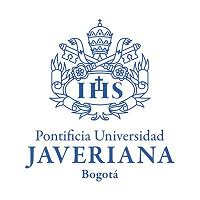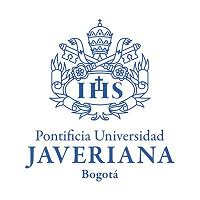
# Pontificia Universidad Javeriana
## Facultad de Ingeniería, Departamento de Ingeniería de Sistemas
### Procesamiento de Datos a Gran Escala, clase 1255

**Profesor:** John Corredor Franco

**Proyecto:** Big Data aplicado a la seguridad ciudadana y vial de Nueva York: diagnóstico territorial y plan de acción

**Estudiantes:** Nikholas Barsky Angulo y Laura Zoet Guacaneme Gómez

**Carrera:** Ciencia de datos

**Fecha:** 6 de octubre de 2026

---

## Metodología: CRISP-DM

El proyecto sigue la metodología CRISP-DM con sus respectivas fases. Esta versión cubre por completo las dos primeras fases y deja un avance de la tercera.

| Fase CRISP-DM | Índice | Estado |
|---|---|---|
| 1. Entendimiento del negocio | Sección 1: contexto, indicadores, objetivo de negocio, objetivos analíticos y criterios de éxito | Completa |
| 2. Entendimiento de los datos | Secciones 2 a 7 y 9: selección, carga en el clúster Spark, tipos, atributos, calidad, exploración y preguntas de negocio | Completa |
| 3. Preparación de los datos | Secciones 4.8, 4.9, 4.10 y 8: limpieza, etiquetas para faltantes, asignación a PUMA, tasas por habitante y tablas de indicadores | Avance; se completa con los modelos |
| 4. Modelado | Un modelo supervisado y uno no supervisado con MLlib | Pendiente |
| 5. Evaluación | Métricas de los modelos y respuesta a las preguntas de negocio | Pendiente |
| 6. Despliegue | Plan de acción para el gobierno de Nueva York | Pendiente |

## 1. Entendimiento del negocio

### 1.1 Contexto

Nueva York es la ciudad más poblada de Estados Unidos, con 8,478,238 habitantes según ACS PUMS 2024, de acuerdo con U.S. Census Bureau, s.f., repartidos en cinco distritos, o boroughs, con realidades sociales muy distintas. Aunque es uno de los mayores centros financieros del mundo, una parte importante de su población vive en pobreza y las diferencias entre distritos son grandes: según ACS PUMS 2024, la pobreza va de 11.19% en Staten Island a 28.96% en el Bronx.

El gobierno de la ciudad considera prioritarios dos problemas: los arrestos y los choques de tránsito. Los dos se concentran en ciertas zonas y horas, y suelen coincidir con barrios que tienen más pobreza, menos empleo y peores resultados escolares. Además, la ciudad cuenta con servicios públicos que pueden servir como palancas del plan de acción: los centros públicos de computadores e internet, que atacan la brecha digital, y los parques y espacios abiertos, que la ciudad mide con la meta de acres por cada 1,000 residentes del manual CEQR, según Mayor's Office of Environmental Coordination, 2021.

Por eso el diagnóstico no se queda en el distrito: baja a las 55 PUMAs, que son zonas del censo de 93,258 a 265,789 habitantes según PUMS 2024, para comparar zonas pequeñas con la misma población de referencia.

### 1.2 Indicadores de interés

| Indicador | Valor | Fuente |
|---|---|---|
| Población de la ciudad | 8,478,238 personas en 2024, ponderada con PWGTP | U.S. Census Bureau, s.f., ACS PUMS 2024; se recalcula en la sección 4.10 |
| Población según el Estado | 8,390,888 personas, estimación 2023 | NYSDOH, s.f.; el Bono 1 toma el año más reciente disponible |
| Tasa de pobreza federal | 18.15% en 2024 | U.S. Census Bureau, s.f., ACS PUMS 2024; se recalcula en la sección 7.1 |
| Desempleo de la ciudad | 6.97% en 2024, población desempleada sobre la fuerza laboral civil, ponderada con PWGTP | U.S. Census Bureau, s.f., ACS PUMS 2024; se recalcula en la sección 7.1 |
| Desempleo juvenil, 16 a 24 años | 13.2% en 2024, la tasa más alta de todos los grupos de edad; 15.25% según ACS PUMS 2024 | Office of the New York State Comptroller, 2025; U.S. Census Bureau, s.f. |
| Arrestos | 278,953 en 2025 y 141,870 en 2026 entre el 1 de enero y el 30 de junio | NYC Open Data, s.f., NYPD Arrests Data Historic y YTD; se recalculan en las secciones 3.8 y 5 |
| Choques de tránsito, régimen de registro actual | 524,338 choques entre el 1 de enero de 2021 y el 11 de junio de 2026 | NYC Open Data, s.f., Motor Vehicle Collisions Crashes; se recalculan en las secciones 3.8 y 6 |
| SAT de bachillerato | 896 puntos de 1,600 en 2023-24, promedio simple por colegio; 1,035 puntos en la media de estudiantes del estado, promoción 2024 | NYC Department of Education, s.f.; College Board, 2024 |
| Meta de espacio público | 2.5 acres de espacio abierto por cada 1,000 residentes: 2.0 de recreación activa y 0.5 de pasiva | Mayor's Office of Environmental Coordination, 2021, CEQR Technical Manual, capítulo 7 |
| Brecha digital | Más de 1.5 millones de neoyorquinos, cerca del 18%, no tenían internet ni en casa ni en el celular | NYC Mayor's Office of the Chief Technology Officer, 2020, NYC Internet Master Plan |

El desempleo juvenil, más del doble del desempleo general según PUMS 2024, es un dato de contexto para el perfil de arrestos de menores de 18 años y de 18 a 24 años. Las cifras de arrestos y choques de 2026 son de un año parcial: para comparar 2026 se usa el periodo común entre arrestos y choques, que se calcula en el código, frente a las mismas fechas de 2025.

### 1.3 Objetivo de negocio

El gobierno de Nueva York quiere reducir dos indicadores: el volumen de arrestos y la cantidad de choques de tránsito con víctimas. El objetivo del equipo consultor es **construir, con datos públicos de seguridad, tránsito, condiciones socioeconómicas, educación, acceso digital y espacio público, un diagnóstico territorial por distrito y por PUMA que identifique zonas críticas, patrones temporales y factores asociados a cada indicador, para sustentar un plan de acción basado en evidencia.**

### 1.4 Objetivos analíticos

1. Identificar dónde se concentran los arrestos y los choques, por distrito y por PUMA, en tasas por cada 100,000 habitantes.
2. Caracterizar cuándo ocurren: tendencia de 2021 a 2025, día de la semana y hora, y 2026 frente al mismo tramo de 2025.
3. Describir qué y quién: tipos de delito, severidad y perfil de las personas arrestadas; tipos de vehículo, causas y víctimas por tipo de persona en los choques.
4. Evaluar la relación de ambos indicadores con la pobreza, el desempleo, la educación de los adultos y el desempeño SAT.
5. Medir la oferta pública que puede usar el plan: centros y computadores públicos por cada 100,000 habitantes y acres de parque por cada 1,000 habitantes, por distrito y por PUMA.

### 1.5 Criterios de éxito

El proyecto será exitoso si logra:

1. Priorizar un número reducido de PUMAs, franjas horarias y tipos de delito o de choque donde concentrar las intervenciones.
2. Estandarizar todos los indicadores territoriales con la misma población de referencia, PUMS 2024, para comparar zonas de forma justa.
3. Responder con evidencia las 10 preguntas de negocio de la sección 9, de modo que cada recomendación del plan esté respaldada por un resultado.
4. Reportar en cada cruce el número de casos y sus advertencias, sin afirmar causas que los datos no permiten probar.

## 2. Selección de los datos a utilizar

### 2.1 Fuentes seleccionadas

Todas las fuentes son oficiales. El periodo de análisis es 2021-2026: el año completo más reciente es 2025 y 2026 es un año parcial.

| Fuente | Años | Nivel geográfico | Rol |
|---|---|---|---|
| NYPD Arrest Data, YTD | 2026, desde el 1 de enero | Distrito y PUMA por coordenadas | Primer indicador: arrestos recientes |
| NYPD Arrests Data, Historic | 2021-2025 | Distrito y PUMA por coordenadas | Tendencia y año completo 2025 |
| Motor Vehicle Collisions: Crashes | 2021-2026 | Distrito y PUMA por coordenadas | Segundo indicador: choques, heridos y muertos |
| Motor Vehicle Collisions: Vehicles | 2021-2026 | Distrito y PUMA por COLLISION_ID | Tipo de vehículo, causas y ocupantes |
| Motor Vehicle Collisions: Person | 2021-2026 | Distrito y PUMA por COLLISION_ID | Víctimas: peatones, ciclistas y ocupantes; edad y lesión |
| ACS PUMS, personas | 2024 | Distrito y PUMA | Población, pobreza, desempleo y educación; denominador de todas las tasas |
| School Quality Reports de bachillerato, SAT | Cursos 2023-24 y 2024-25 | Distrito, por el DBN | Desempeño educativo |
| Citywide Public Computer Centers | Año más reciente del archivo | Distrito y PUMA por coordenadas | Acceso digital |
| NYC Parks Active and Passive Recreation | Foto fija de 2026 | Distrito y PUMA por punto representativo | Espacio público medido como en el manual CEQR |
| Límites de las PUMAs 2020 | Geografía 2020 | PUMA | Geografía auxiliar: asignación de puntos y mapas |
| Población NYSDOH, web scraping | Año más reciente disponible | Distrito | Validación de la población, Bono 1 |
| OpenWeatherMap, API | Tiempo real | Ciudad | Contexto climático, Bono 2 |

### 2.2 Por qué estas fuentes

Arrestos y choques son los dos indicadores que el gobierno quiere bajar. Las tres tablas de choques se usan juntas: Crashes da el lugar, la hora y las víctimas; Vehicles da el tipo de vehículo y la causa; Person dice quién resultó herido o muerto, algo clave para separar peatones, ciclistas y ocupantes. PUMS 2024 aporta la población, que es el denominador de todas las tasas, y las condiciones sociales de cada zona, que pide el objetivo analítico 4. El SAT mide la educación de los jóvenes. Los centros públicos de computadores y los parques miden dos servicios que el plan puede reforzar, como pide el objetivo analítico 5. Los límites de las PUMAs permiten ubicar cada arresto, choque, centro y parque en una zona del censo. La población del NYSDOH valida la de PUMS y el clima se explora para revisar más adelante si afecta los choques.

Crashes, Vehicles y Person se unen por `COLLISION_ID`; el SAT se ubica por distrito con el tercer carácter del `DBN`; PUMS se ubica por su código de PUMA, y los arrestos, choques y centros se ubican en una PUMA a partir de sus coordenadas.

### 2.3 Diagrama de proveniencia de los datos

El diagrama muestra el recorrido de cada fuente: portal de origen, archivo, DataFrame de Spark, limpieza, tablas por distrito y por PUMA e indicadores. Se dibuja con matplotlib, con cajas y flechas, antes de abrir la sesión de Spark porque no necesita datos.

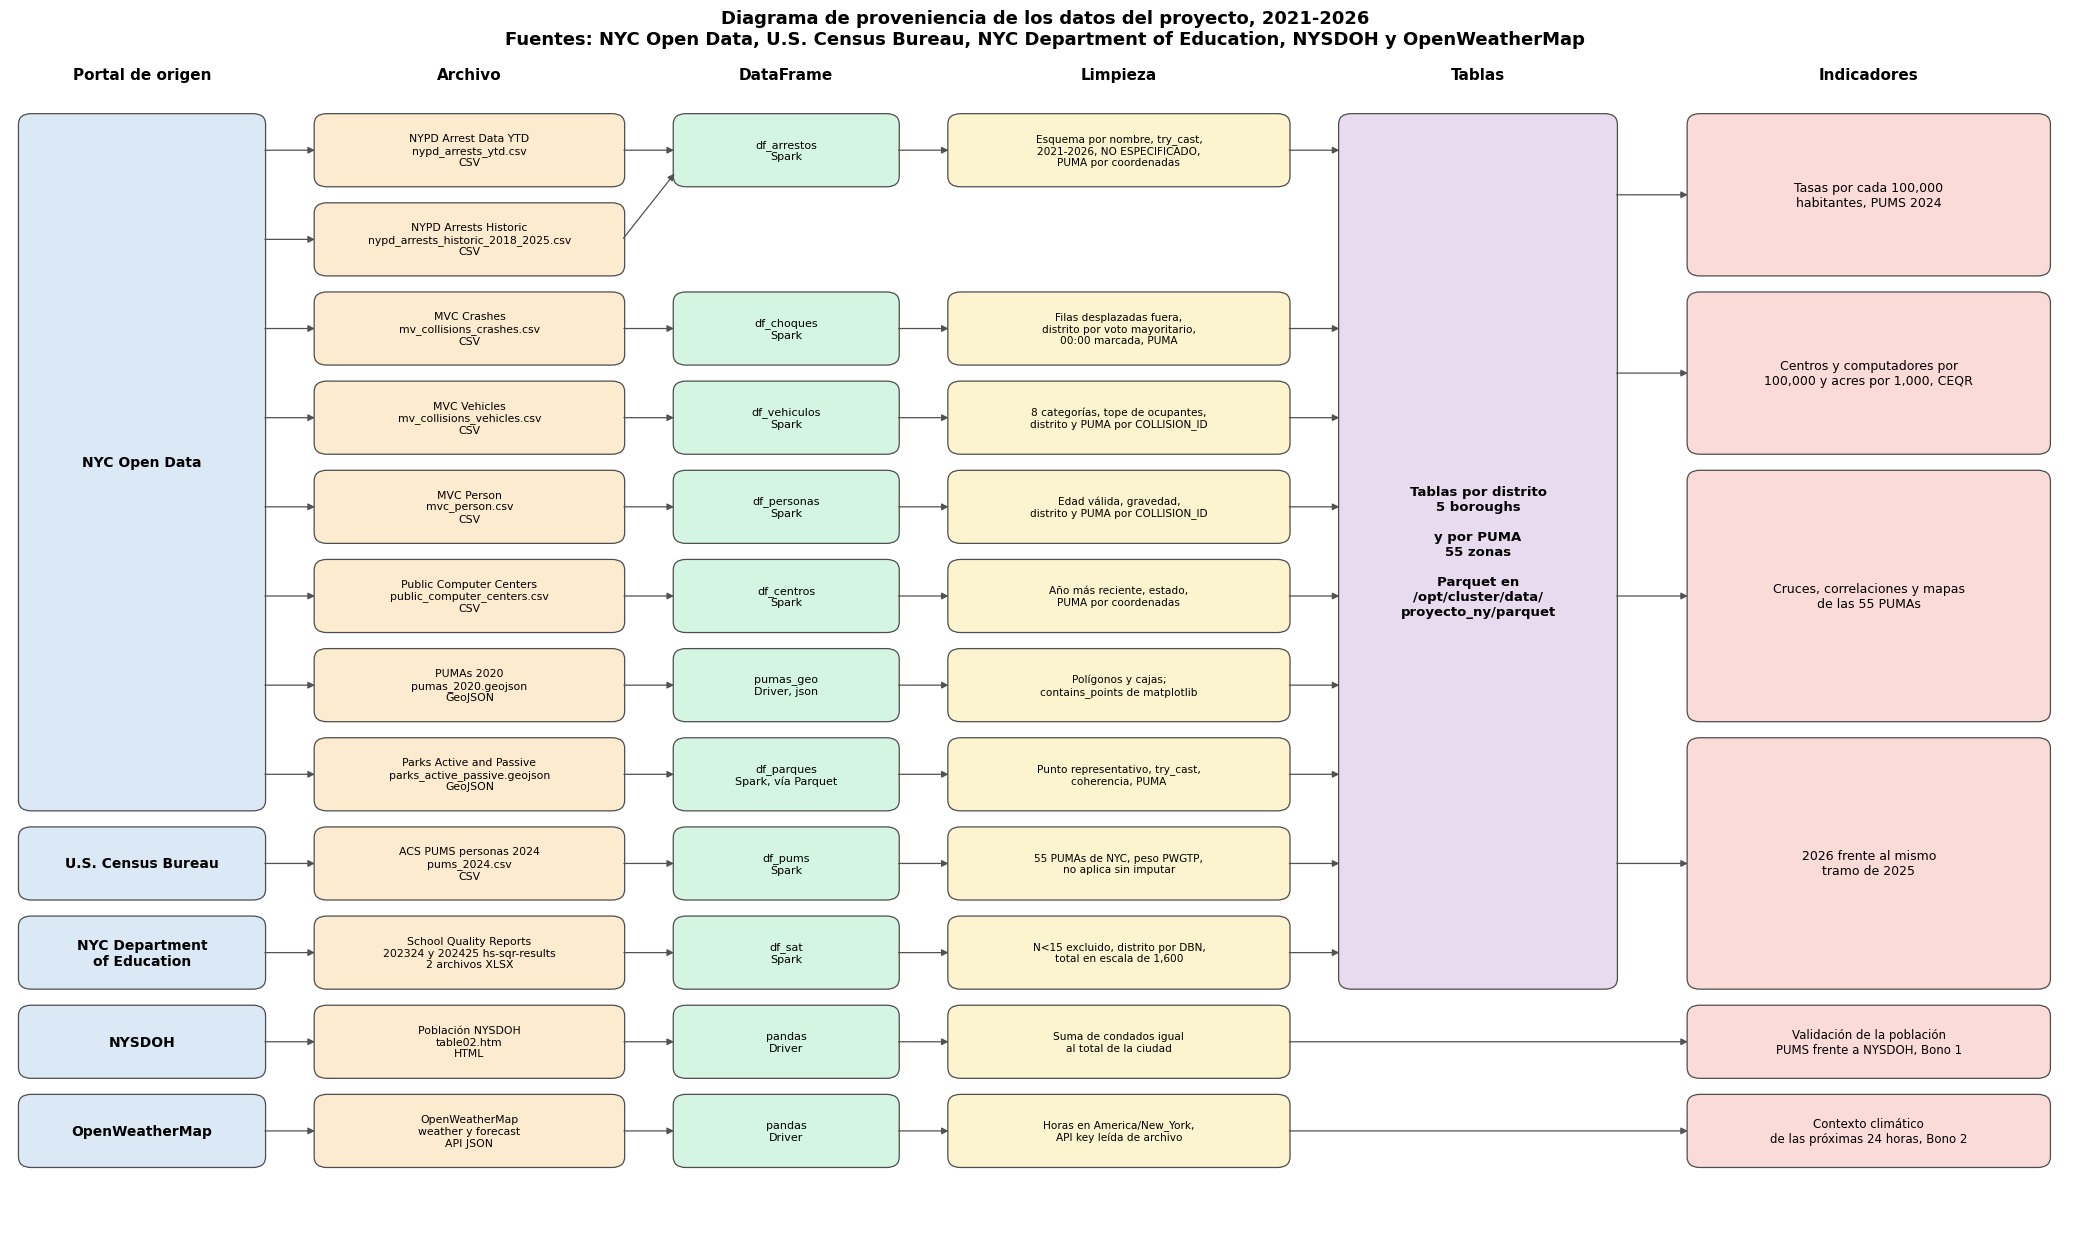

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# caja: recibe un eje, la esquina inferior izquierda, el ancho, el alto, el texto y el color de fondo.
# Dibuja una caja redondeada con el texto centrado y devuelve las coordenadas de sus bordes izquierdo y
# derecho a media altura, para unir las flechas
def caja(ax, x, y, ancho, alto, texto, color, tamano=8.5, negrita=False):
    ax.add_patch(FancyBboxPatch((x, y), ancho, alto, boxstyle="round,pad=0.02,rounding_size=0.12",
                                facecolor=color, edgecolor="#4d4d4d", linewidth=0.9))
    ax.text(x + ancho / 2, y + alto / 2, texto, ha="center", va="center", fontsize=tamano,
            fontweight="bold" if negrita else "normal", wrap=True)
    return (x, y + alto / 2), (x + ancho, y + alto / 2)

# flecha: recibe un eje y dos puntos; dibuja una flecha del primero al segundo
def flecha(ax, desde, hasta):
    ax.annotate("", xy=hasta, xytext=desde,
                arrowprops=dict(arrowstyle="-|>", color="#525252", lw=0.9, shrinkA=1, shrinkB=1))

# Una fila por archivo: nombre corto de la fuente, archivo y formato. Las filas 0 y 1 son los dos
# archivos de arrestos, que terminan en un mismo DataFrame
FILAS = [
    ("NYPD Arrest Data YTD", "nypd_arrests_ytd.csv\nCSV"),
    ("NYPD Arrests Historic", "nypd_arrests_historic_2018_2025.csv\nCSV"),
    ("MVC Crashes", "mv_collisions_crashes.csv\nCSV"),
    ("MVC Vehicles", "mv_collisions_vehicles.csv\nCSV"),
    ("MVC Person", "mvc_person.csv\nCSV"),
    ("Public Computer Centers", "public_computer_centers.csv\nCSV"),
    ("PUMAs 2020", "pumas_2020.geojson\nGeoJSON"),
    ("Parks Active and Passive", "parks_active_passive.geojson\nGeoJSON"),
    ("ACS PUMS personas 2024", "pums_2024.csv\nCSV"),
    ("School Quality Reports", "202324 y 202425 hs-sqr-results\n2 archivos XLSX"),
    ("Población NYSDOH", "table02.htm\nHTML"),
    ("OpenWeatherMap", "weather y forecast\nAPI JSON"),
]
# DataFrame y limpieza de cada fila; None en la fila 1 porque comparte DataFrame con la fila 0
PROCESO = [
    ("df_arrestos\nSpark", "Esquema por nombre, try_cast,\n2021-2026, NO ESPECIFICADO,\nPUMA por coordenadas"),
    None,
    ("df_choques\nSpark", "Filas desplazadas fuera,\ndistrito por voto mayoritario,\n00:00 marcada, PUMA"),
    ("df_vehiculos\nSpark", "8 categorías, tope de ocupantes,\ndistrito y PUMA por COLLISION_ID"),
    ("df_personas\nSpark", "Edad válida, gravedad,\ndistrito y PUMA por COLLISION_ID"),
    ("df_centros\nSpark", "Año más reciente, estado,\nPUMA por coordenadas"),
    ("pumas_geo\nDriver, json", "Polígonos y cajas;\ncontains_points de matplotlib"),
    ("df_parques\nSpark, vía Parquet", "Punto representativo, try_cast,\ncoherencia, PUMA"),
    ("df_pums\nSpark", "55 PUMAs de NYC, peso PWGTP,\nno aplica sin imputar"),
    ("df_sat\nSpark", "N<15 excluido, distrito por DBN,\ntotal en escala de 1,600"),
    ("pandas\nDriver", "Suma de condados igual\nal total de la ciudad"),
    ("pandas\nDriver", "Horas en America/New_York,\nAPI key leída de archivo"),
]
# Portal de origen: nombre, primera fila y última fila que cubre
PORTALES = [("NYC Open Data", 0, 7), ("U.S. Census Bureau", 8, 8), ("NYC Department\nof Education", 9, 9),
            ("NYSDOH", 10, 10), ("OpenWeatherMap", 11, 11)]

ALTO, PASO = 0.78, 1.0
# y_fila: recibe el número de fila y devuelve la coordenada y de su borde inferior; la fila 0 queda arriba
def y_fila(i):
    return (len(FILAS) - 1 - i) * PASO + 0.11

X = {"portal": 0.1, "archivo": 2.9, "df": 6.3, "limpieza": 8.9, "tablas": 12.6, "indicadores": 15.9}
ANCHO = {"portal": 2.3, "archivo": 2.9, "df": 2.1, "limpieza": 3.2, "tablas": 2.6, "indicadores": 3.4}
COLOR = {"portal": "#dbe9f6", "archivo": "#fdebd0", "df": "#d5f5e3", "limpieza": "#fcf3cf",
         "tablas": "#e8daef", "indicadores": "#fadbd8"}

fig, ax = plt.subplots(figsize=(21, 12.5))
ax.set_xlim(0, 19.6)
ax.set_ylim(-0.6, len(FILAS) * PASO + 0.6)
ax.axis("off")

# Encabezados de las seis columnas del recorrido
for clave, titulo in [("portal", "Portal de origen"), ("archivo", "Archivo"), ("df", "DataFrame"),
                      ("limpieza", "Limpieza"), ("tablas", "Tablas"), ("indicadores", "Indicadores")]:
    ax.text(X[clave] + ANCHO[clave] / 2, len(FILAS) * PASO + 0.3, titulo, ha="center", fontsize=11,
            fontweight="bold")

# Portales: una caja alta por portal que abarca todas sus filas
salida_portal = {}
for nombre, ini, fin in PORTALES:
    y0 = y_fila(fin)
    alto = y_fila(ini) + ALTO - y0
    _, borde_der = caja(ax, X["portal"], y0, ANCHO["portal"], alto, nombre, COLOR["portal"], 10, True)
    for i in range(ini, fin + 1):
        salida_portal[i] = (borde_der[0], y_fila(i) + ALTO / 2)

# Archivos, DataFrames y limpieza de cada fila, con sus flechas
salida_limpieza = {}
for i, (fuente, archivo) in enumerate(FILAS):
    izq_arch, der_arch = caja(ax, X["archivo"], y_fila(i), ANCHO["archivo"], ALTO,
                              f"{fuente}\n{archivo}", COLOR["archivo"], 7.8)
    flecha(ax, salida_portal[i], izq_arch)
    if PROCESO[i] is None:
        # El archivo histórico de arrestos va al mismo DataFrame que el YTD, dibujado en la fila 0
        flecha(ax, der_arch, (X["df"], y_fila(0) + ALTO / 2 - 0.25))
        continue
    nombre_df, texto_limpieza = PROCESO[i]
    izq_df, der_df = caja(ax, X["df"], y_fila(i), ANCHO["df"], ALTO, nombre_df, COLOR["df"], 8)
    flecha(ax, der_arch, izq_df)
    izq_lim, der_lim = caja(ax, X["limpieza"], y_fila(i), ANCHO["limpieza"], ALTO, texto_limpieza,
                            COLOR["limpieza"], 7.6)
    flecha(ax, der_df, izq_lim)
    salida_limpieza[i] = der_lim

# Tablas por distrito y por PUMA: reciben las filas 0 a 9
y_tablas = y_fila(9)
alto_tablas = y_fila(0) + ALTO - y_tablas
izq_tab, der_tab = caja(ax, X["tablas"], y_tablas, ANCHO["tablas"], alto_tablas,
                        "Tablas por distrito\n5 boroughs\n\ny por PUMA\n55 zonas\n\nParquet en\n/opt/cluster/data/\nproyecto_ny/parquet",
                        COLOR["tablas"], 9.5, True)
for i in range(10):
    if i in salida_limpieza:
        flecha(ax, salida_limpieza[i], (X["tablas"], salida_limpieza[i][1]))

# Indicadores que salen de las tablas, y los dos bonos que van directo a su indicador
INDICADORES = [("Tasas por cada 100,000\nhabitantes, PUMS 2024", 0, 1),
               ("Centros y computadores por\n100,000 y acres por 1,000, CEQR", 2, 3),
               ("Cruces, correlaciones y mapas\nde las 55 PUMAs", 4, 6),
               ("2026 frente al mismo\ntramo de 2025", 7, 9)]
for texto, ini, fin in INDICADORES:
    y0 = y_fila(fin)
    alto = y_fila(ini) + ALTO - y0
    izq_ind, _ = caja(ax, X["indicadores"], y0, ANCHO["indicadores"], alto, texto, COLOR["indicadores"], 9)
    flecha(ax, (der_tab[0], izq_ind[1]), izq_ind)
for i, texto in [(10, "Validación de la población\nPUMS frente a NYSDOH, Bono 1"),
                 (11, "Contexto climático\nde las próximas 24 horas, Bono 2")]:
    izq_ind, _ = caja(ax, X["indicadores"], y_fila(i), ANCHO["indicadores"], ALTO, texto, COLOR["indicadores"], 8.5)
    flecha(ax, salida_limpieza[i], izq_ind)

ax.set_title("Diagrama de proveniencia de los datos del proyecto, 2021-2026\n"
             "Fuentes: NYC Open Data, U.S. Census Bureau, NYC Department of Education, NYSDOH y OpenWeatherMap",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Análisis:** El diagrama reúne las 12 fuentes del proyecto en un solo recorrido. Ocho archivos salen de NYC Open Data, uno del U.S. Census Bureau, dos del NYC Department of Education, y las dos fuentes de los bonos salen del NYSDOH y de OpenWeatherMap. Todas las bases que alimentan las tasas terminan en las mismas tablas por distrito y por PUMA guardadas en Parquet, así que cada indicador del análisis se puede rastrear hasta su archivo de origen. Las fuentes de los bonos no pasan por esas tablas: la población del NYSDOH solo valida el denominador y el clima es contexto.

### 2.4 Justificaciones y limitaciones

**Justificaciones:**

- Se arranca en 2021 porque desde abril de 2020 la NYPD ya no registra los choques que solo dejan daños materiales. Así todos los choques del análisis tienen un único régimen de registro y sus totales sí se pueden comparar entre años.
- La PUMA es la zona más pequeña que comparten PUMS y las coordenadas de los registros. Por eso las tasas por zona se calculan por PUMA, con la geografía 2020, que es la misma de PUMS 2024.
- Person es nueva: es la única tabla que dice si el herido o el muerto era peatón, ciclista u ocupante, y su edad.
- El espacio público se mide en acres por cada 1,000 habitantes, igual que el manual CEQR, para poder comparar contra la meta de la ciudad. Los centros de computadores se miden por cada 100,000 habitantes, igual que los arrestos y los choques.
- El enlace sugerido para la población del NYSDOH devolvía 403 o 404 desde el clúster; las mismas tablas oficiales se leen desde el host healthweb-back.health.ny.gov.
- Como referencia estatal del SAT se usan 1,035 puntos, la media de los estudiantes de la promoción 2024 del estado de Nueva York, según College Board, 2024.

**Limitaciones:**

- El enunciado plantea Hadoop HDFS. En el clúster compartido del curso los datos están en una carpeta compartida por NFS, /opt/cluster/data/proyecto_ny, que todos los nodos ven igual pero que no reparte los archivos en bloques ni los replica. Se deja como limitación de la infraestructura.
- Manhattan recibe todos los días a mucha gente que no vive allí. Como las tasas se dividen por los residentes, las tasas de arrestos y de choques de Manhattan quedan infladas frente a los otros distritos.
- Con cinco distritos los cruces son pistas y no pruebas. Por PUMA hay 55 zonas y más evidencia, pero el análisis sigue siendo exploratorio y no permite afirmar causas.
- PUMS es una muestra: sus cifras por PUMA son estimaciones con margen de error, que en esta versión no se calcula.
- Los parques son una foto fija de 2026 y la población es de 2024. Cada parque se ubica en una sola PUMA con un punto representativo, así que los parques grandes que cruzan varias PUMAs quedan completos en una sola.
- Los puntos se ubican en una PUMA después de redondear sus coordenadas; los que están muy cerca de un borde pueden quedar en la PUMA vecina. El margen se mide en la sección 4.9.
- 2026 es un año parcial y en 2026 una parte de los choques no trae el dato de muertos; por eso los muertos de 2026 no se comparan.
- El SAT no trae coordenadas: solo se analiza por distrito.

## 3. Colección y descripción de los datos

Primero se configura el clúster Spark donde se procesan los datos y se leen sus características reales. Después se cargan las fuentes, se cuentan filas y columnas, se revisan los tipos de datos y se describe el significado de los atributos y el contenido de cada base.

### 3.1 Librerías, estilo visual y funciones de apoyo

Se importan PySpark, pandas, matplotlib y seaborn, todas instaladas en el Driver. Se definen la función `mostrar_tabla`, la paleta y el orden fijos de los distritos y algunas funciones pequeñas que se usan en todo el notebook. No se agregan dependencias nuevas.

In [2]:
import os
import sys
import re
import json
import gc
import socket
import platform
from datetime import date

import pyspark
from pyspark.sql import SparkSession, Window
# F es el alias habitual para las funciones de columna de Spark SQL
from pyspark.sql import functions as F
from pyspark.sql.types import StringType, DoubleType, FloatType

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter, PercentFormatter
from matplotlib.lines import Line2D
from matplotlib.path import Path
from matplotlib.patches import Polygon as PoligonoMpl
from matplotlib.collections import PatchCollection
from IPython.display import display

# mostrar_tabla: recibe un DataFrame de pandas pequeño, ya agregado, un título opcional, los decimales
# como un número para todas las columnas o un diccionario por columna, y la lista de columnas que son
# porcentajes. No devuelve nada: muestra la tabla en HTML para que no se parta en la pantalla
def mostrar_tabla(pdf, titulo=None, decimales=None, pct=None):
    """Muestra un DataFrame de pandas pequeño como tabla HTML, sin índice y con formato uniforme."""
    pct = list(pct or [])
    formatos = {}
    for col in pdf.columns:
        serie = pdf[col]
        if not pd.api.types.is_numeric_dtype(serie) or pd.api.types.is_bool_dtype(serie):
            continue
        # Se busca cuántos decimales se piden para esta columna; 2 si no se indica nada
        dec = decimales.get(col, 2) if isinstance(decimales, dict) else (2 if decimales is None else decimales)
        # Los conteos, enteros o decimales sin parte fraccionaria, se muestran sin decimales
        sin_fraccion = pd.api.types.is_integer_dtype(serie) or bool(((serie.dropna() % 1) == 0).all())
        if sin_fraccion and col not in pct:
            dec = 0
        # Los años no llevan separador de miles, para que 2024 no salga como 2,024
        separador = "" if ("año" in str(col).lower() or "anio" in str(col).lower()) else ","
        sufijo = "%" if col in pct else ""
        formatos[col] = "{:" + separador + "." + str(dec) + "f}" + sufijo
    try:
        estilo = pdf.style
    except (ImportError, AttributeError):
        # Si el Styler no está disponible porque falta jinja2, se muestra la tabla HTML simple de pandas
        if titulo:
            print(titulo)
        display(pdf)
        return
    estilo = (estilo.format(formatos, na_rep="")
              .hide(axis="index")
              .set_table_styles([
                  {"selector": "th", "props": [("font-weight", "bold"), ("text-align", "center"),
                                               ("background-color", "#e8eef5"), ("padding", "4px 10px")]},
                  {"selector": "td", "props": [("text-align", "center"), ("padding", "3px 10px")]},
                  {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#f5f7fa")]},
                  {"selector": "caption", "props": [("caption-side", "top"), ("font-weight", "bold"),
                                                    ("text-align", "left"), ("padding-bottom", "6px")]},
              ]))
    if titulo:
        estilo = estilo.set_caption(titulo)
    display(estilo)

# Estilo uniforme para todas las figuras: letra serif, cuadrícula clara y los mismos tamaños en todas
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# Orden y paleta fijos de los distritos: el mismo color identifica al mismo distrito en todo el notebook.
# Las llaves van en mayúscula, que es como queda el distrito en todas las tablas de Spark; en las
# gráficas el nombre se muestra con nombre_boro
ORDEN_BORO = ["BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"]
PALETA_BORO = {"BRONX": "#d95f02", "BROOKLYN": "#1b9e77", "MANHATTAN": "#7570b3",
               "QUEENS": "#e7298a", "STATEN ISLAND": "#66a61e"}
# Códigos de distrito de los arrestos y del tercer carácter del DBN de los colegios
BORO_ARR = {"B": "BRONX", "K": "BROOKLYN", "M": "MANHATTAN", "Q": "QUEENS", "S": "STATEN ISLAND"}
BORO_DBN = {"X": "BRONX", "K": "BROOKLYN", "M": "MANHATTAN", "Q": "QUEENS", "R": "STATEN ISLAND"}
# Los dos primeros dígitos del código de la PUMA 2020 indican el distrito; así se ubica cada PUMA de PUMS 2024
PUMA_A_BORO = {41: "MANHATTAN", 42: "BRONX", 43: "BROOKLYN", 44: "QUEENS", 45: "STATEN ISLAND"}

# Periodo de análisis: 2021-2026, con 2025 como el año completo más reciente
ANIO_INI, ANIO_FIN, ANIO_COMPLETO = 2021, 2026, 2025
# Recuadro geográfico de Nueva York: una coordenada fuera de estos límites no es válida
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = 40.49, 40.92, -74.26, -73.69
ORDEN_EDAD = ["<18", "18-24", "25-44", "45-64", "65+"]
DIAS_ES = {1: "Domingo", 2: "Lunes", 3: "Martes", 4: "Miércoles", 5: "Jueves", 6: "Viernes", 7: "Sábado"}
ORDEN_DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

# nombre_boro: recibe el distrito en mayúscula y lo devuelve con mayúscula inicial para las gráficas
def nombre_boro(distrito):
    return str(distrito).title()

# formato_miles: recibe un eje de matplotlib, por ejemplo ax.yaxis, y le pone separador de miles
def formato_miles(eje):
    eje.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# mapa_spark: recibe un diccionario de Python y lo devuelve como columna tipo mapa de Spark, para
# traducir códigos dentro del clúster sin usar una UDF
def mapa_spark(diccionario):
    return F.create_map(*[F.lit(x) for par in diccionario.items() for x in par])

# coord_valida: no recibe nada; devuelve la condición de coordenada dentro del recuadro de Nueva York.
# coalesce cambia un posible NULL por False, para que el filtro negado no pierda filas
def coord_valida():
    return F.coalesce(F.col("LATITUDE").between(LAT_MIN, LAT_MAX)
                      & F.col("LONGITUDE").between(LON_MIN, LON_MAX), F.lit(False))

# ordenar_distritos: recibe un DataFrame de pandas con la columna DISTRITO y lo devuelve en el orden fijo
def ordenar_distritos(pdf, columna="DISTRITO"):
    orden = {d: i for i, d in enumerate(ORDEN_BORO)}
    return pdf.sort_values(columna, key=lambda s: s.map(orden).fillna(99)).reset_index(drop=True)

# nota_figura: recibe una figura y un texto; escribe la nota en gris al pie de la figura
def nota_figura(fig, texto):
    fig.text(0.01, 0.01, texto, fontsize=8, color="gray")

print("Librerías cargadas. Versión de pandas:", pd.__version__, "| matplotlib:", matplotlib.__version__,
      "| seaborn:", sns.__version__)

Librerías cargadas. Versión de pandas: 2.3.3 | matplotlib: 3.9.4 | seaborn: 0.13.2


### 3.2 Definición de variables de red y topología del clúster

Se detecta la IP del Driver en la red del clúster, para que cualquier integrante pueda correr el notebook desde su propia máquina virtual sin editar el código.

In [3]:
# IP del nodo Master del clúster
SPARK_MASTER_IP = "10.43.97.58"
# 7077 es el puerto por defecto del Master en modo Standalone
SPARK_MASTER_URL = f"spark://{SPARK_MASTER_IP}:7077"

# detectar_ip_driver: recibe la IP del Master y el puerto; abre un socket UDP hacia él y devuelve la IP
# local por la que sale ese tráfico, que es la IP con la que los Workers ven al Driver
def detectar_ip_driver(master_ip, puerto=7077):
    """Detecta la IP de esta máquina virtual en la red del clúster."""
    # Se usa UDP porque connect no hace handshake: solo le pide al sistema operativo la ruta de salida
    s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
    try:
        s.connect((master_ip, puerto))
        return s.getsockname()[0]
    finally:
        s.close()

DRIVER_HOST_IP = detectar_ip_driver(SPARK_MASTER_IP)
print(f"IP del Driver detectada: {DRIVER_HOST_IP}")

# Ruta base compartida por NFS donde están los datasets del proyecto
DATA_PATH = "/opt/cluster/data/proyecto_ny"

IP del Driver detectada: 10.43.97.61


### 3.3 Configuración de la SparkSession distribuida

Se usa la configuración de dos núcleos y 2 GB por ejecutor, porque el clúster lo comparten seis personas, y la zona horaria de Nueva York para que fechas y horas se lean igual en todos los nodos.

In [4]:
# getOrCreate reutiliza la sesión si ya existe, así que volver a correr la celda no abre otra aplicación
spark = (
    SparkSession.builder
    .appName("NY_Territorial_Analytics_Consulting_Final")
    .master(SPARK_MASTER_URL)
    # driver.host es la IP que el Driver anuncia a los Workers; bindAddress 0.0.0.0 hace que escuche
    # en todas sus interfaces de red
    .config("spark.driver.host", DRIVER_HOST_IP)
    .config("spark.driver.bindAddress", "0.0.0.0")
    .config("spark.driver.memory", "2g")
    .config("spark.executor.memory", "2g")
    .config("spark.executor.cores", "2")
    # Zona horaria de Nueva York para todas las fechas y horas
    .config("spark.sql.session.timeZone", "America/New_York")
    # La ejecución adaptativa junta particiones pequeñas después de cada shuffle; viene activa desde
    # Spark 3.2 y se deja explícita para documentarla
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
sc = spark.sparkContext
print("SparkSession creada:", sc.applicationId)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


SparkSession creada: app-20261019153926-0031


### 3.4 Verificación de la conexión y características del clúster

Las características se leen de la sesión real y no se escriben a mano: el Master, las versiones, la memoria y los núcleos asignados al Driver y a cada ejecutor, las particiones de shuffle y la zona horaria. Así la información queda vigente sin importar quién corra el notebook.

In [5]:
# requests se usa en esta sección y en las descargas, el scraping y la API del clima
import requests

# Características leídas de la configuración de la sesión real de Spark
caracteristicas = [
    ("Master Spark", sc.master),
    ("ID de la aplicación", sc.applicationId),
    ("IP del Driver", spark.conf.get("spark.driver.host")),
    ("Ruta de datos compartida por NFS", DATA_PATH),
    ("Sistema operativo del Driver", platform.platform()),
    ("Versión de Python del Driver", sys.version.split()[0]),
    ("Versión de PySpark del Driver", pyspark.__version__),
    ("Versión de Spark del clúster", spark.version),
    ("Memoria del Driver", spark.conf.get("spark.driver.memory")),
    ("Memoria por ejecutor", spark.conf.get("spark.executor.memory")),
    ("Núcleos por ejecutor", spark.conf.get("spark.executor.cores")),
    ("Particiones de shuffle", spark.conf.get("spark.sql.shuffle.partitions")),
    ("Ejecución adaptativa", spark.conf.get("spark.sql.adaptive.enabled")),
    ("Zona horaria de la sesión", spark.conf.get("spark.sql.session.timeZone")),
]
mostrar_tabla(pd.DataFrame(caracteristicas, columns=["Característica", "Valor"]),
              titulo="Características del clúster y del entorno de ejecución, leídas de la sesión real")

# Se deja constancia si las versiones del Driver y del clúster no coinciden
if pyspark.__version__ != spark.version:
    print(f"Nota: el Driver corre PySpark {pyspark.__version__} y el clúster Spark {spark.version}. "
          "Ocurre porque el Driver usa Python 3.9 y Spark 4.2 pide Python 3.10 o más. Funcionan juntos, "
          "pero los workers no pueden ejecutar código Python: por eso todo el procesamiento distribuido "
          "usa funciones nativas de Spark SQL.")

Característica,Valor
Master Spark,spark://10.43.97.58:7077
ID de la aplicación,app-20261019153926-0031
IP del Driver,10.43.97.61
Ruta de datos compartida por NFS,/opt/cluster/data/proyecto_ny
Sistema operativo del Driver,Linux-5.14.0-687.17.1.el9_8.x86_64-x86_64-with-glibc2.34
Versión de Python del Driver,3.9.25
Versión de PySpark del Driver,4.0.4
Versión de Spark del clúster,4.2.0
Memoria del Driver,2g
Memoria por ejecutor,2g


Nota: el Driver corre PySpark 4.0.4 y el clúster Spark 4.2.0. Ocurre porque el Driver usa Python 3.9 y Spark 4.2 pide Python 3.10 o más. Funcionan juntos, pero los workers no pueden ejecutar código Python: por eso todo el procesamiento distribuido usa funciones nativas de Spark SQL.


### 3.5 Rutas, archivos esperados y descarga de respaldo

Todas las rutas salen de `DATA_PATH`. La bandera `REUSAR_PARQUET` controla el guardado intermedio: si una base limpia ya existe en Parquet se lee de ahí, y si no, se calcula desde el archivo original y se guarda. La primera corrida es la más lenta; las siguientes leen Parquet, que es columnar y mucho más rápido que un CSV. Con `REUSAR_PARQUET = False` todo se recalcula y se sobrescribe.

In [6]:
# Si es True y el Parquet existe, se lee; si no, se calcula y se guarda
REUSAR_PARQUET = True
PARQUET_PATH = f"{DATA_PATH}/parquet"
# Carpeta para las tablas pequeñas que se calculan en el Driver y se pasan a Spark como CSV
AUX_PATH = f"{PARQUET_PATH}/auxiliares"
os.makedirs(AUX_PATH, exist_ok=True)

# Nombre exacto de cada archivo en el clúster. Los siete primeros ya estaban descargados;
# los cuatro últimos son las bases nuevas: Person, centros de computadores, PUMAs y parques
ARCHIVOS = {
    "arrestos_ytd": "nypd_arrests_ytd.csv",
    "arrestos_historico": "nypd_arrests_historic_2018_2025.csv",
    "choques": "mv_collisions_crashes.csv",
    "vehiculos": "mv_collisions_vehicles.csv",
    "pums_2024": "pums_2024.csv",
    "sat_2024": "202324-hs-sqr-results.xlsx",
    "sat_2025": "202425-hs-sqr-results.xlsx",
    "personas": "mvc_person.csv",
    "centros": "public_computer_centers.csv",
    "pumas": "pumas_2020.geojson",
    "parques": "parks_active_passive.geojson",
}
RUTAS = {clave: f"{DATA_PATH}/{nombre}" for clave, nombre in ARCHIVOS.items()}
print(f"Parquet en: {PARQUET_PATH} | REUSAR_PARQUET = {REUSAR_PARQUET}")

Parquet en: /opt/cluster/data/proyecto_ny/parquet | REUSAR_PARQUET = True


Esta celda de respaldo solo actúa si falta alguno de los cuatro archivos nuevos. En ese caso lo descarga a `DATA_PATH` desde NYC Open Data con `requests` en modo streaming, en bloques de 1 MB, con tiempo máximo de espera y sin seguir redirecciones hacia otros hosts. El archivo se escribe primero con la extensión .parcial y se renombra al terminar, para que una descarga cortada no deje un archivo incompleto con el nombre bueno.

In [7]:
from urllib.parse import urlparse, urljoin

URLS_RESPALDO = {
    "personas": "https://data.cityofnewyork.us/api/views/f55k-p6yu/rows.csv?accessType=DOWNLOAD",
    "centros": "https://data.cityofnewyork.us/api/views/sejx-2gn3/rows.csv?accessType=DOWNLOAD",
    "pumas": "https://data.cityofnewyork.us/resource/pikk-p9nv.geojson?$limit=100",
    "parques": "https://data.cityofnewyork.us/resource/kcqe-vnci.geojson?$limit=10000",
}
HOST_PERMITIDO = "data.cityofnewyork.us"

# descargar_archivo: recibe la URL de origen y la ruta de destino. Descarga en bloques a un archivo
# temporal y lo renombra al terminar. Solo sigue redirecciones dentro del mismo host y devuelve el
# tamaño del archivo en MB
def descargar_archivo(url, destino, max_saltos=3):
    for _ in range(max_saltos + 1):
        host = urlparse(url).hostname
        if host != HOST_PERMITIDO:
            raise ValueError(f"Se bloqueó una redirección hacia otro host: {host}")
        # allow_redirects=False: cada salto se revisa a mano antes de seguirlo
        with requests.get(url, stream=True, timeout=(15, 300), allow_redirects=False) as respuesta:
            if respuesta.status_code in (301, 302, 303, 307, 308):
                url = urljoin(url, respuesta.headers.get("Location", ""))
                continue
            respuesta.raise_for_status()
            temporal = destino + ".parcial"
            with open(temporal, "wb") as archivo:
                for bloque in respuesta.iter_content(chunk_size=1024 * 1024):
                    if bloque:
                        archivo.write(bloque)
            os.replace(temporal, destino)
            return os.path.getsize(destino) / 1024 ** 2
    raise RuntimeError("Se superó el número máximo de redirecciones.")

for clave, url in URLS_RESPALDO.items():
    destino = RUTAS[clave]
    if os.path.exists(destino) and os.path.getsize(destino) > 0:
        print(f"{ARCHIVOS[clave]}: ya existe, no se descarga.")
        continue
    print(f"{ARCHIVOS[clave]}: no existe; se descarga desde NYC Open Data...")
    try:
        print(f"   Descarga completa: {descargar_archivo(url, destino):,.1f} MB")
    except Exception as e:
        print(f"   No se pudo descargar: {type(e).__name__}: {e}")

mvc_person.csv: ya existe, no se descarga.
public_computer_centers.csv: ya existe, no se descarga.
pumas_2020.geojson: ya existe, no se descarga.
parks_active_passive.geojson: ya existe, no se descarga.


Se verifica que existan los once archivos que espera el notebook y se muestra su tamaño.

In [8]:
# Recorre los archivos esperados y arma una fila por archivo con su estado y su tamaño
pdf_archivos = pd.DataFrame([{
    "Archivo": nombre,
    "Existe": "Sí" if os.path.exists(RUTAS[clave]) else "No",
    "Tamaño MB": round(os.path.getsize(RUTAS[clave]) / 1024 ** 2, 1) if os.path.exists(RUTAS[clave]) else None,
    "Nuevo en esta versión": "Sí" if clave in URLS_RESPALDO else "No",
} for clave, nombre in ARCHIVOS.items()])
mostrar_tabla(pdf_archivos, titulo=f"Archivos esperados en {DATA_PATH}", decimales=1)
faltantes = pdf_archivos.loc[pdf_archivos["Existe"] == "No", "Archivo"].tolist()
if faltantes:
    print("Faltan archivos:", faltantes, "| Las celdas que los usan van a fallar hasta que estén en la carpeta.")

Archivo,Existe,Tamaño MB,Nuevo en esta versión
nypd_arrests_ytd.csv,Sí,24.9,No
nypd_arrests_historic_2018_2025.csv,Sí,407.0,No
mv_collisions_crashes.csv,Sí,454.5,No
mv_collisions_vehicles.csv,Sí,803.6,No
pums_2024.csv,Sí,140.5,No
202324-hs-sqr-results.xlsx,Sí,1.9,No
202425-hs-sqr-results.xlsx,Sí,1.9,No
mvc_person.csv,Sí,956.3,Sí
public_computer_centers.csv,Sí,0.6,Sí
pumas_2020.geojson,Sí,3.5,Sí


### 3.6 Funciones de lectura con esquema explícito y guardado en Parquet

Cada base tiene un esquema explícito, un diccionario con el nombre y el tipo de cada columna que se usa. El esquema se aplica por nombre y no por posición: el CSV se lee como texto, se normalizan los nombres de las columnas, se revisa que estén todas y cada una se convierte con `try_cast`. Así un cambio en el orden de las columnas del archivo no corre los datos, y un texto que no se puede convertir queda en NULL sin detener el trabajo, cosa que sí haría `cast` con el modo ANSI de Spark 4. En cada fila se cuenta cuántos textos no se pudieron convertir, para el reporte de calidad. Como solo se seleccionan las columnas necesarias, Spark solo interpreta esas columnas del CSV.

Las tablas pequeñas que se calculan en el Driver, como la asignación de coordenadas a PUMA, el SAT o los parques, se pasan a Spark escribiendo un CSV en la carpeta compartida por NFS y leyéndolo con Spark.

In [9]:
# normalizar_nombre: recibe el nombre de una columna y lo devuelve en mayúsculas, con guion bajo en vez
# de espacios o signos. Así CRASH DATE pasa a CRASH_DATE y latitude pasa a LATITUDE
def normalizar_nombre(nombre):
    return re.sub(r"[^0-9A-Za-z]+", "_", nombre.strip()).strip("_").upper()

# leer_csv_tipado: recibe la ruta de un CSV y un diccionario {columna normalizada: tipo de Spark SQL}.
# Devuelve el DataFrame con solo esas columnas y sus tipos, más N_NO_CONVERTIBLES, que cuenta en cada
# fila los textos que no se pudieron convertir, y el número de columnas que tenía el archivo
def leer_csv_tipado(ruta, esquema):
    # Todo se lee como texto: sin inferSchema no hay una pasada extra por el archivo. escape con comillas
    # dobles es la regla de los CSV de NYC Open Data, donde una comilla dentro de un campo va doble
    crudo = (spark.read.option("header", "true").option("inferSchema", "false")
             .option("escape", '"').option("mode", "PERMISSIVE").csv(ruta))
    columnas_archivo = len(crudo.columns)
    # Se normalizan los nombres; si dos quedaran iguales, el segundo recibe un sufijo
    nombres, vistos = [], {}
    for c in crudo.columns:
        n = normalizar_nombre(c)
        vistos[n] = vistos.get(n, 0) + 1
        nombres.append(n if vistos[n] == 1 else f"{n}_{vistos[n]}")
    crudo = crudo.toDF(*nombres)
    faltan = [c for c in esquema if c not in crudo.columns]
    if faltan:
        raise ValueError(f"En {os.path.basename(ruta)} no están las columnas {faltan}")
    columnas, no_convertibles = [], []
    for col, tipo in esquema.items():
        texto = F.col(f"`{col}`")
        if tipo == "string":
            columnas.append(texto.alias(col))
            continue
        # try_cast devuelve NULL si el texto no se puede convertir, en lugar de detener el trabajo
        convertido = F.expr(f"try_cast(`{col}` as {tipo})")
        columnas.append(convertido.alias(col))
        no_convertibles.append(F.when(texto.isNotNull() & (F.trim(texto) != "") & convertido.isNull(), 1)
                               .otherwise(0))
    total = sum(no_convertibles[1:], no_convertibles[0]) if no_convertibles else F.lit(0)
    return crudo.select(*columnas, total.alias("N_NO_CONVERTIBLES")), columnas_archivo

# fecha_flexible: recibe el nombre de una columna de texto con fecha y devuelve una expresión de fecha.
# Prueba el formato MM/dd/yyyy y el formato ISO con funciones que devuelven NULL si no encajan, y
# coalesce se queda con el primero que funcione
def fecha_flexible(columna):
    return F.coalesce(F.expr(f"to_date(try_to_timestamp(`{columna}`, 'MM/dd/yyyy'))"),
                      F.expr(f"to_date(try_cast(`{columna}` as timestamp))"))

# hora_y_minuto: recibe el nombre de una columna de texto con la hora, por ejemplo 9:05 o 17:45, y
# devuelve dos expresiones enteras, hora y minuto. Si la hora no es válida, quedan en NULL
def hora_y_minuto(columna):
    patron = "([0-9]{1,2}):([0-9]{2})"
    hora = F.expr(f"try_cast(regexp_extract(`{columna}`, '{patron}', 1) as int)")
    minuto = F.expr(f"try_cast(regexp_extract(`{columna}`, '{patron}', 2) as int)")
    return (F.when(hora.between(0, 23), hora).alias("HORA"),
            F.when(minuto.between(0, 59), minuto).alias("MINUTO"))

# a_json: recibe un valor que json no sabe guardar, como un entero de numpy o una fecha, y lo convierte
def a_json(valor):
    return valor.item() if hasattr(valor, "item") else str(valor)

# parquet_o_calcular: recibe un nombre y una función construir que no recibe nada y devuelve un
# DataFrame y un diccionario de metadatos. Si REUSAR_PARQUET es True y el Parquet existe, lo lee; si no,
# llama a construir, guarda el resultado y sus metadatos y lo vuelve a leer desde el Parquet. Devuelve
# el DataFrame y los metadatos
def parquet_o_calcular(nombre, construir):
    ruta = f"{PARQUET_PATH}/{nombre}"
    ruta_meta = f"{PARQUET_PATH}/{nombre}_meta.json"
    if REUSAR_PARQUET and os.path.exists(f"{ruta}/_SUCCESS"):
        meta = {}
        if os.path.exists(ruta_meta):
            with open(ruta_meta, encoding="utf-8") as f:
                meta = json.load(f)
        print(f"{nombre}: se leyó desde Parquet.")
        return spark.read.parquet(ruta), meta
    df, meta = construir()
    # write es una acción: aquí se ejecuta todo el plan y los ejecutores escriben en la carpeta compartida
    df.write.mode("overwrite").parquet(ruta)
    with open(ruta_meta, "w", encoding="utf-8") as f:
        json.dump(meta, f, default=a_json, ensure_ascii=False, indent=1)
    print(f"{nombre}: se calculó y se guardó en Parquet.")
    return spark.read.parquet(ruta), meta

# pandas_a_spark: recibe un DataFrame de pandas pequeño, un nombre y un esquema como en leer_csv_tipado.
# Lo escribe como CSV en la carpeta compartida por NFS y lo lee con Spark aplicando el esquema. Devuelve
# el DataFrame de Spark con la columna de control N_NO_CONVERTIBLES
def pandas_a_spark(pdf, nombre, esquema):
    ruta = f"{AUX_PATH}/{nombre}.csv"
    pdf.to_csv(ruta, index=False)
    df, _ = leer_csv_tipado(ruta, esquema)
    return df

# construir_base_por_fecha: recibe la clave del archivo, su esquema, la columna de fecha, los años que se
# conservan y una función opcional que agrega columnas. Lee el CSV, calcula FECHA y ANIO, cuenta en una
# sola pasada las filas del archivo y su rango de fechas, y devuelve el DataFrame filtrado por año y los
# metadatos
def construir_base_por_fecha(clave, esquema, col_fecha, anio_ini, anio_fin, extra=None):
    df, n_columnas = leer_csv_tipado(RUTAS[clave], esquema)
    df = df.withColumn("FECHA", fecha_flexible(col_fecha)).withColumn("ANIO", F.year("FECHA"))
    if extra is not None:
        df = extra(df)
    # Esta agregación recorre el archivo completo una vez; solo ocurre en la primera corrida
    meta = df.agg(F.count("*").alias("FILAS_ARCHIVO"),
                  F.count(F.when(F.col("ANIO").between(anio_ini, anio_fin), 1)).alias("FILAS_PERIODO"),
                  F.count(F.when(F.col("FECHA").isNull(), 1)).alias("FECHA_INVALIDA"),
                  F.min("FECHA").alias("FECHA_MIN_ARCHIVO"),
                  F.max("FECHA").alias("FECHA_MAX_ARCHIVO")).first().asDict()
    meta["COLUMNAS_ARCHIVO"] = n_columnas
    # El filtro de años se aplica apenas se carga la base
    return df.filter(F.col("ANIO").between(anio_ini, anio_fin)).drop(col_fecha), meta

print("Funciones de lectura listas.")

Funciones de lectura listas.


### 3.7 Carga de las bases en Apache Spark

Cada base se carga con su esquema explícito y se filtra al periodo apenas se lee. Los arrestos juntan el histórico, filtrado a 2021-2025, y el archivo YTD de 2026. En la primera corrida se recorren los archivos originales; en las siguientes se leen los Parquet.

**Arrestos:** histórico 2021-2025 y YTD 2026 en un solo DataFrame, con la columna `FUENTE`.

In [10]:
ESQUEMA_ARRESTOS = {
    "ARREST_KEY": "bigint", "ARREST_DATE": "string", "PD_DESC": "string", "OFNS_DESC": "string",
    "LAW_CAT_CD": "string", "ARREST_BORO": "string", "ARREST_PRECINCT": "int", "AGE_GROUP": "string",
    "PERP_SEX": "string", "PERP_RACE": "string", "LATITUDE": "double", "LONGITUDE": "double",
}

# construir_base_arrestos: no recibe nada; lee los dos archivos de arrestos, filtra cada uno a su
# periodo y los une. Devuelve el DataFrame y los metadatos de cada archivo
def construir_base_arrestos():
    partes, meta = [], {}
    for fuente, clave, anio_ini, anio_fin in [("HISTORICO", "arrestos_historico", ANIO_INI, ANIO_COMPLETO),
                                              ("YTD", "arrestos_ytd", ANIO_FIN, ANIO_FIN)]:
        df, meta[fuente] = construir_base_por_fecha(clave, ESQUEMA_ARRESTOS, "ARREST_DATE", anio_ini, anio_fin)
        partes.append(df.withColumn("FUENTE", F.lit(fuente)))
    # unionByName apila los dos archivos haciendo coincidir las columnas por nombre
    return partes[0].unionByName(partes[1]), meta

df_arrestos_base, meta_arrestos = parquet_o_calcular("base_arrestos", construir_base_arrestos)

base_arrestos: se leyó desde Parquet.


**Choques, vehículos y personas:** las tres tablas de Motor Vehicle Collisions, filtradas a 2021-2026 por su propia fecha del choque. En Crashes también se separan la hora y el minuto, que vienen como texto en hora local de Nueva York.

In [11]:
ESQUEMA_CHOQUES = {
    "COLLISION_ID": "bigint", "CRASH_DATE": "string", "CRASH_TIME": "string", "BOROUGH": "string",
    "ZIP_CODE": "string", "LATITUDE": "double", "LONGITUDE": "double", "ON_STREET_NAME": "string",
    "CROSS_STREET_NAME": "string",
    "NUMBER_OF_PERSONS_INJURED": "int", "NUMBER_OF_PERSONS_KILLED": "int",
    "NUMBER_OF_PEDESTRIANS_INJURED": "int", "NUMBER_OF_PEDESTRIANS_KILLED": "int",
    "NUMBER_OF_CYCLIST_INJURED": "int", "NUMBER_OF_CYCLIST_KILLED": "int",
    "NUMBER_OF_MOTORIST_INJURED": "int", "NUMBER_OF_MOTORIST_KILLED": "int",
    "CONTRIBUTING_FACTOR_VEHICLE_1": "string", "VEHICLE_TYPE_CODE_1": "string",
}
ESQUEMA_VEHICULOS = {
    "UNIQUE_ID": "bigint", "COLLISION_ID": "bigint", "CRASH_DATE": "string", "VEHICLE_TYPE": "string",
    "VEHICLE_YEAR": "int", "VEHICLE_OCCUPANTS": "bigint", "DRIVER_SEX": "string",
    "DRIVER_LICENSE_STATUS": "string", "PRE_CRASH": "string", "CONTRIBUTING_FACTOR_1": "string",
}
ESQUEMA_PERSONAS = {
    "UNIQUE_ID": "bigint", "COLLISION_ID": "bigint", "CRASH_DATE": "string", "PERSON_TYPE": "string",
    "PERSON_INJURY": "string", "PERSON_AGE": "int", "PERSON_SEX": "string", "BODILY_INJURY": "string",
    "SAFETY_EQUIPMENT": "string", "POSITION_IN_VEHICLE": "string", "EJECTION": "string",
    "EMOTIONAL_STATUS": "string", "COMPLAINT": "string", "PED_ROLE": "string", "PED_ACTION": "string",
    "PED_LOCATION": "string",
}

# agregar_hora: recibe el DataFrame de choques y le agrega HORA y MINUTO a partir de CRASH_TIME
def agregar_hora(df):
    return df.select("*", *hora_y_minuto("CRASH_TIME")).drop("CRASH_TIME")

# Las tres funciones de construcción se envuelven en def para que parquet_o_calcular las llame solo si
# el Parquet no existe
def construir_base_choques():
    return construir_base_por_fecha("choques", ESQUEMA_CHOQUES, "CRASH_DATE", ANIO_INI, ANIO_FIN, agregar_hora)

def construir_base_vehiculos():
    return construir_base_por_fecha("vehiculos", ESQUEMA_VEHICULOS, "CRASH_DATE", ANIO_INI, ANIO_FIN)

def construir_base_personas():
    return construir_base_por_fecha("personas", ESQUEMA_PERSONAS, "CRASH_DATE", ANIO_INI, ANIO_FIN)

df_choques_base, meta_choques = parquet_o_calcular("base_choques", construir_base_choques)
df_vehiculos_base, meta_vehiculos = parquet_o_calcular("base_vehiculos", construir_base_vehiculos)
df_personas_base, meta_personas = parquet_o_calcular("base_personas", construir_base_personas)

base_choques: se leyó desde Parquet.
base_vehiculos: se leyó desde Parquet.
base_personas: se leyó desde Parquet.


**ACS PUMS 2024:** se leen ocho de las 286 columnas del archivo del estado y se dejan solo las 55 PUMAs de la ciudad, con su distrito según el prefijo del código. `ESR` permite medir el desempleo.

In [12]:
ESQUEMA_PUMS = {"SERIALNO": "string", "SPORDER": "int", "PUMA": "int", "PWGTP": "int", "AGEP": "int",
                "SCHL": "int", "ESR": "int", "POVPIP": "int"}

# construir_base_pums: no recibe nada; lee PUMS 2024, traduce el prefijo de la PUMA a distrito y deja
# solo la ciudad. Los blancos de SCHL, ESR y POVPIP quedan en NULL: son no aplica y no se imputan
def construir_base_pums():
    df, n_columnas = leer_csv_tipado(RUTAS["pums_2024"], ESQUEMA_PUMS)
    # floor de PUMA entre 100 da el prefijo: 4101 pasa a 41, que es Manhattan
    df = df.withColumn("DISTRITO", mapa_spark(PUMA_A_BORO)[F.floor(F.col("PUMA") / 100).cast("int")])
    meta = df.agg(F.count("*").alias("FILAS_ARCHIVO"),
                  F.count(F.when(F.col("DISTRITO").isNotNull(), 1)).alias("FILAS_PERIODO")).first().asDict()
    meta["COLUMNAS_ARCHIVO"] = n_columnas
    return df.filter(F.col("DISTRITO").isNotNull()), meta

df_pums_base, meta_pums = parquet_o_calcular("base_pums_2024", construir_base_pums)

base_pums_2024: se leyó desde Parquet.


**SAT de los School Quality Reports:** los dos Excel se leen en el Driver con pandas, porque son pequeños, buscando las columnas por prefijo y contenido. Los puntajes se dejan como texto para no perder la marca "N<15". La tabla se pasa a Spark por un CSV en la carpeta compartida.

In [13]:
PREFIJO_SAT = "Metric Value - Average score of students in the current cohort who took the SAT "

# columna_sat_util: recibe el nombre de una columna del Excel y devuelve True si es el DBN o uno de los
# dos promedios del SAT, Math o Reading and Writing
def columna_sat_util(nombre):
    nombre = str(nombre)
    return nombre == "DBN" or (nombre.startswith(PREFIJO_SAT)
                               and ("Math exam" in nombre or "Reading and Writing exam" in nombre))

# leer_sat_excel: recibe la ruta del Excel y la fila del encabezado contada desde 0; devuelve un DataFrame
# de pandas con DBN, MATH_RAW y READING_WRITING_RAW como texto
def leer_sat_excel(ruta, fila_encabezado):
    pdf = pd.read_excel(ruta, sheet_name="Additional Info", header=fila_encabezado, engine="openpyxl",
                        dtype=str, usecols=columna_sat_util)
    col_math = [c for c in pdf.columns if "Math exam" in str(c)]
    col_rw = [c for c in pdf.columns if "Reading and Writing exam" in str(c)]
    if len(col_math) != 1 or len(col_rw) != 1:
        raise ValueError(f"No se encontró una columna única para cada sección del SAT en {ruta}")
    pdf = pdf.rename(columns={col_math[0]: "MATH_RAW", col_rw[0]: "READING_WRITING_RAW"})
    # Se quitan las filas sin DBN, que son parte del formato del Excel
    return pdf.dropna(subset=["DBN"])[["DBN", "MATH_RAW", "READING_WRITING_RAW"]]

# construir_base_sat: no recibe nada; lee los dos cursos, que tienen el encabezado en la fila 4 de
# Excel, los une con la columna CURSO y los pasa a Spark
def construir_base_sat():
    partes, meta = [], {}
    for curso, clave in [("2023-24", "sat_2024"), ("2024-25", "sat_2025")]:
        pdf = leer_sat_excel(RUTAS[clave], 3)
        meta[curso] = {"FILAS_ARCHIVO": len(pdf), "FILAS_PERIODO": len(pdf)}
        partes.append(pdf.assign(CURSO=curso))
    pdf_sat = pd.concat(partes, ignore_index=True)[["CURSO", "DBN", "MATH_RAW", "READING_WRITING_RAW"]]
    esquema = {"CURSO": "string", "DBN": "string", "MATH_RAW": "string", "READING_WRITING_RAW": "string"}
    return pandas_a_spark(pdf_sat, "sat_cursos", esquema), meta

df_sat_base, meta_sat = parquet_o_calcular("base_sat", construir_base_sat)

base_sat: se leyó desde Parquet.


**Centros públicos de computadores:** el archivo trae un registro por centro y por año. Se conservan todos los años en la base para el reporte de calidad; el análisis usa el año más reciente, que se calcula en el código.

In [14]:
ESQUEMA_CENTROS = {
    "CALENDAR_YEAR": "int", "OBJECT_IDENTIFICATION_NUMBER": "string", "OVERSIGHT_AGENCY": "string",
    "STATUS": "string", "LOCATION_NAME": "string", "BOROUGH": "string", "LATITUDE": "double",
    "LONGITUDE": "double", "COMMUNITY_DISTRICT": "int", "WORKSTATION_NUMBER": "int",
}

def construir_base_centros():
    df, n_columnas = leer_csv_tipado(RUTAS["centros"], ESQUEMA_CENTROS)
    meta = df.agg(F.count("*").alias("FILAS_ARCHIVO"), F.min("CALENDAR_YEAR").alias("ANIO_MIN"),
                  F.max("CALENDAR_YEAR").alias("ANIO_MAX")).first().asDict()
    meta["FILAS_PERIODO"] = meta["FILAS_ARCHIVO"]
    meta["COLUMNAS_ARCHIVO"] = n_columnas
    return df, meta

df_centros_base, meta_centros = parquet_o_calcular("base_centros", construir_base_centros)

base_centros: se leyó desde Parquet.


**Límites de las PUMAs 2020:** el GeoJSON se lee en el Driver con `json`. Cada PUMA queda con su código entero, sus polígonos y la caja que la contiene. Se manejan Polygon y MultiPolygon, y cada polígono guarda su anillo exterior y sus huecos. Esta geografía se usa para ubicar puntos y para dibujar los mapas.

In [15]:
# leer_geojson_pumas: recibe la ruta del GeoJSON y devuelve una lista de diccionarios, uno por PUMA, con
# el código entero, las partes y la caja. Cada parte es un par anillo exterior y lista de huecos, como
# arreglos de numpy con dos columnas: longitud y latitud
def leer_geojson_pumas(ruta):
    with open(ruta, encoding="utf-8") as f:
        datos = json.load(f)
    pumas = []
    for feature in datos["features"]:
        geometria, propiedades = feature["geometry"], feature["properties"]
        poligonos = geometria["coordinates"] if geometria["type"] == "MultiPolygon" else [geometria["coordinates"]]
        partes = []
        for anillos in poligonos:
            exterior = np.asarray(anillos[0], dtype=float)[:, :2]
            huecos = [np.asarray(a, dtype=float)[:, :2] for a in anillos[1:]]
            partes.append((exterior, huecos))
        vertices = np.vstack([p[0] for p in partes])
        pumas.append({
            # El código viene como texto en el GeoJSON y como entero en PUMS; se comparan como enteros
            "PUMA": int(float(propiedades["puma"])),
            "partes": partes,
            "caja": (vertices[:, 0].min(), vertices[:, 1].min(), vertices[:, 0].max(), vertices[:, 1].max()),
        })
    return pumas

pumas_geo = leer_geojson_pumas(RUTAS["pumas"])
CODIGOS_PUMA_GEO = sorted(p["PUMA"] for p in pumas_geo)
print(f"PUMAs leídas del GeoJSON: {len(pumas_geo)} | partes en total: {sum(len(p['partes']) for p in pumas_geo)}")
print("PUMAs cuyo prefijo no está en el mapeo de distritos:",
      [c for c in CODIGOS_PUMA_GEO if c // 100 not in PUMA_A_BORO])

# asignar_puma: recibe arreglos de longitudes y latitudes y la lista de PUMAs. Devuelve un arreglo con el
# código de PUMA de cada punto, o 0 si no cae en ninguna. Para no probar todos los puntos contra todos
# los polígonos, primero se filtra con la caja de cada PUMA y de cada parte, y solo se prueban los puntos
# que todavía no tienen PUMA. Un punto está en una parte si está en su anillo exterior y no en sus huecos
def asignar_puma(lon, lat, pumas):
    lon, lat = np.asarray(lon, dtype=float), np.asarray(lat, dtype=float)
    puntos = np.column_stack([lon, lat])
    resultado = np.zeros(len(puntos), dtype=np.int64)
    for p in pumas:
        x0, y0, x1, y1 = p["caja"]
        candidatos = np.where((resultado == 0) & (lon >= x0) & (lon <= x1) & (lat >= y0) & (lat <= y1))[0]
        if len(candidatos) == 0:
            continue
        sub = puntos[candidatos]
        dentro = np.zeros(len(candidatos), dtype=bool)
        for exterior, huecos in p["partes"]:
            ex0, ey0 = exterior.min(axis=0)
            ex1, ey1 = exterior.max(axis=0)
            idx = np.where((sub[:, 0] >= ex0) & (sub[:, 0] <= ex1) & (sub[:, 1] >= ey0) & (sub[:, 1] <= ey1))[0]
            if len(idx) == 0:
                continue
            # contains_points está escrito en C dentro de matplotlib; corre en el Driver, no en los workers
            en_parte = Path(exterior).contains_points(sub[idx])
            for hueco in huecos:
                en_parte &= ~Path(hueco).contains_points(sub[idx])
            dentro[idx[en_parte]] = True
        resultado[candidatos[dentro]] = p["PUMA"]
    return resultado

# dibujar_pumas: recibe un eje, la lista de PUMAs y, opcionalmente, un diccionario {PUMA: valor}, un mapa de
# colores y los límites de la escala. Dibuja cada PUMA con matplotlib.patches.Polygon; sin valores solo dibuja
# los contornos. Los huecos de los polígonos no se pintan. Devuelve la colección de polígonos
def dibujar_pumas(ax, pumas, valores=None, cmap="viridis", vmin=None, vmax=None):
    parches, datos = [], []
    for p in pumas:
        valor = np.nan if valores is None else valores.get(p["PUMA"], np.nan)
        for exterior, _ in p["partes"]:
            parches.append(PoligonoMpl(exterior, closed=True))
            datos.append(valor)
    if valores is None:
        coleccion = PatchCollection(parches, facecolor="#f2f2f2", edgecolor="#8c8c8c", linewidth=0.4)
    else:
        mapa_color = matplotlib.colormaps[cmap].copy()
        # Las PUMAs sin dato se pintan de gris
        mapa_color.set_bad("#d9d9d9")
        coleccion = PatchCollection(parches, cmap=mapa_color, edgecolor="white", linewidth=0.4)
        coleccion.set_array(np.ma.masked_invalid(np.asarray(datos, dtype=float)))
        coleccion.set_clim(vmin, vmax)
    ax.add_collection(coleccion)
    ax.autoscale_view()
    # Corrige la deformación de la proyección para que la ciudad no se vea estirada
    ax.set_aspect(1 / np.cos(np.radians(40.7)))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    return coleccion

PUMAs leídas del GeoJSON: 55 | partes en total: 176
PUMAs cuyo prefijo no está en el mapeo de distritos: []


**Parques activos y pasivos:** el GeoJSON pesa cerca de 115 MB, así que se lee una sola vez y no se guardan las coordenadas completas. Con `object_hook`, cada geometría se reemplaza apenas se lee por su punto representativo: el promedio de los vértices del anillo exterior de su polígono más grande. Después se ubica el punto en una PUMA, la tabla pequeña se guarda en Parquet y la memoria se libera con `del` y `gc.collect`. Con `REUSAR_PARQUET` el GeoJSON no se vuelve a leer.

In [16]:
COLUMNAS_PARQUES = ["gispropnum", "public_open_space_name", "recreation_category", "acres", "active_percent",
                    "passive_percent", "active_acres", "passive_acres", "type_category", "location",
                    "zipcode", "boro_census_tracts", "borough"]
# Todos los valores del GeoJSON vienen como texto; los números se convierten en Spark con try_cast
ESQUEMA_PARQUES = {c.upper(): "string" for c in COLUMNAS_PARQUES}
ESQUEMA_PARQUES.update({"ACRES": "double", "ACTIVE_PERCENT": "double", "PASSIVE_PERCENT": "double",
                        "ACTIVE_ACRES": "double", "PASSIVE_ACRES": "double", "REP_LON": "double",
                        "REP_LAT": "double", "N_POLIGONOS": "int", "N_VERTICES": "int", "PUMA": "int"})

# punto_representativo: recibe una geometría GeoJSON como diccionario y devuelve la longitud y la latitud
# promedio de los vértices del anillo exterior de su polígono más grande, el número de polígonos y el
# número de vértices. El área de cada polígono se compara con la fórmula del área de Gauss, en grados
def punto_representativo(geometria):
    poligonos = geometria["coordinates"] if geometria["type"] == "MultiPolygon" else [geometria["coordinates"]]
    mejor, mejor_area, n_vertices = None, -1.0, 0
    for anillos in poligonos:
        exterior = np.asarray(anillos[0], dtype=float)[:, :2]
        n_vertices += sum(len(a) for a in anillos)
        x, y = exterior[:, 0], exterior[:, 1]
        area = 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))
        if area > mejor_area:
            mejor, mejor_area = exterior, area
    # El último vértice repite el primero para cerrar el anillo; se quita para no contarlo dos veces
    if len(mejor) > 1 and np.allclose(mejor[0], mejor[-1]):
        mejor = mejor[:-1]
    lon, lat = mejor.mean(axis=0)
    return float(lon), float(lat), len(poligonos), int(n_vertices)

# gancho_geometria: json la llama con cada diccionario apenas lo lee. Si es una geometría, la reemplaza
# por un diccionario pequeño con su punto representativo; así nunca están todas las coordenadas en memoria
def gancho_geometria(d):
    if d.get("type") in ("Polygon", "MultiPolygon") and "coordinates" in d:
        lon, lat, n_pol, n_vert = punto_representativo(d)
        return {"REP_LON": lon, "REP_LAT": lat, "N_POLIGONOS": n_pol, "N_VERTICES": n_vert}
    return d

# construir_base_parques: no recibe nada; lee el GeoJSON una vez, arma una fila por espacio con sus
# atributos y su punto representativo, ubica el punto en una PUMA y pasa la tabla a Spark
def construir_base_parques():
    with open(RUTAS["parques"], encoding="utf-8") as f:
        datos = json.load(f, object_hook=gancho_geometria)
    filas = []
    for feature in datos["features"]:
        propiedades = feature.get("properties") or {}
        punto = feature.get("geometry") or {}
        fila = {c.upper(): propiedades.get(c) for c in COLUMNAS_PARQUES}
        for clave in ["REP_LON", "REP_LAT", "N_POLIGONOS", "N_VERTICES"]:
            fila[clave] = punto.get(clave)
        filas.append(fila)
    meta = {"FILAS_ARCHIVO": len(filas), "FILAS_PERIODO": len(filas), "COLUMNAS_ARCHIVO": len(COLUMNAS_PARQUES)}
    # Se libera el GeoJSON leído antes de seguir
    del datos
    gc.collect()
    pdf = pd.DataFrame(filas)
    del filas
    puma = np.zeros(len(pdf), dtype=np.int64)
    con_punto = np.where(pdf["REP_LON"].notna().to_numpy())[0]
    puma[con_punto] = asignar_puma(pdf["REP_LON"].to_numpy()[con_punto], pdf["REP_LAT"].to_numpy()[con_punto], pumas_geo)
    # Int64 de pandas permite enteros con vacíos; 0 significa sin PUMA y pasa a vacío
    pdf["PUMA"] = pd.Series(puma, dtype="Int64").mask(puma == 0)
    for clave in ["N_POLIGONOS", "N_VERTICES"]:
        pdf[clave] = pdf[clave].astype("Int64")
    meta["PARQUES_SIN_PUNTO"] = int(len(pdf) - len(con_punto))
    return pandas_a_spark(pdf, "parques_puntos", ESQUEMA_PARQUES), meta

df_parques_base, meta_parques = parquet_o_calcular("base_parques", construir_base_parques)
gc.collect()

base_parques: se leyó desde Parquet.


24

### 3.8 Conteo de filas y columnas

Se comparan las filas de cada archivo original con las que quedan en el periodo de análisis. Los conteos del archivo original se guardaron en los metadatos de la primera corrida, así que esta celda no vuelve a leer los CSV; los conteos del periodo se hacen sobre los Parquet. `count` es una acción: obliga a los ejecutores a leer los datos en paralelo.

In [17]:
# fila_conteo: recibe el nombre de la base, el archivo, sus metadatos, el DataFrame y el periodo; devuelve
# un diccionario que será una fila de la tabla de volumetría
def fila_conteo(base, archivo, meta, df, periodo, filtro=None):
    df_periodo = df if filtro is None else df.filter(filtro)
    return {"Base": base, "Archivo": archivo, "Periodo en el notebook": periodo,
            "Columnas en el archivo": meta.get("COLUMNAS_ARCHIVO"),
            "Columnas usadas": len([c for c in df.columns if c != "N_NO_CONVERTIBLES"]),
            "Filas en el archivo": meta.get("FILAS_ARCHIVO"),
            "Filas en el periodo": df_periodo.count()}

pdf_volumetria = pd.DataFrame([
    fila_conteo("Arrestos histórico", ARCHIVOS["arrestos_historico"], meta_arrestos.get("HISTORICO", {}),
                df_arrestos_base, "2021-2025", F.col("FUENTE") == "HISTORICO"),
    fila_conteo("Arrestos YTD", ARCHIVOS["arrestos_ytd"], meta_arrestos.get("YTD", {}),
                df_arrestos_base, "2026", F.col("FUENTE") == "YTD"),
    fila_conteo("Choques, Crashes", ARCHIVOS["choques"], meta_choques, df_choques_base, "2021-2026"),
    fila_conteo("Vehículos, Vehicles", ARCHIVOS["vehiculos"], meta_vehiculos, df_vehiculos_base, "2021-2026"),
    fila_conteo("Personas, Person", ARCHIVOS["personas"], meta_personas, df_personas_base, "2021-2026"),
    fila_conteo("ACS PUMS personas", ARCHIVOS["pums_2024"], meta_pums, df_pums_base, "2024, solo NYC"),
    fila_conteo("SAT 2023-24", ARCHIVOS["sat_2024"], meta_sat.get("2023-24", {}), df_sat_base, "Curso 2023-24",
                F.col("CURSO") == "2023-24"),
    fila_conteo("SAT 2024-25", ARCHIVOS["sat_2025"], meta_sat.get("2024-25", {}), df_sat_base, "Curso 2024-25",
                F.col("CURSO") == "2024-25"),
    fila_conteo("Centros de computadores", ARCHIVOS["centros"], meta_centros, df_centros_base, "Todos los años"),
    fila_conteo("Parques activos y pasivos", ARCHIVOS["parques"], meta_parques, df_parques_base, "Foto 2026"),
])
pdf_volumetria = pd.concat([pdf_volumetria, pd.DataFrame([{
    "Base": "Límites de las PUMAs 2020", "Archivo": ARCHIVOS["pumas"], "Periodo en el notebook": "Geografía 2020",
    "Columnas en el archivo": 3, "Columnas usadas": 1, "Filas en el archivo": len(pumas_geo),
    "Filas en el periodo": len(pumas_geo)}])], ignore_index=True)
for c in ["Columnas en el archivo", "Filas en el archivo"]:
    pdf_volumetria[c] = pd.to_numeric(pdf_volumetria[c], errors="coerce")
mostrar_tabla(pdf_volumetria, titulo="Volumetría de las bases: archivo original y periodo de análisis")

Base,Archivo,Periodo en el notebook,Columnas en el archivo,Columnas usadas,Filas en el archivo,Filas en el periodo
Arrestos histórico,nypd_arrests_historic_2018_2025.csv,2021-2025,19,14,"1,713,412","1,111,609"
Arrestos YTD,nypd_arrests_ytd.csv,2026,19,14,"141,870","141,870"
"Choques, Crashes",mv_collisions_crashes.csv,2021-2026,29,21,"2,269,188","524,338"
"Vehículos, Vehicles",mv_collisions_vehicles.csv,2021-2026,25,11,"4,551,002","1,057,393"
"Personas, Person",mvc_person.csv,2021-2026,21,17,"5,984,110","1,820,886"
ACS PUMS personas,pums_2024.csv,"2024, solo NYC",286,9,"210,150","67,511"
SAT 2023-24,202324-hs-sqr-results.xlsx,Curso 2023-24,,4,508,508
SAT 2024-25,202425-hs-sqr-results.xlsx,Curso 2024-25,,4,506,506
Centros de computadores,public_computer_centers.csv,Todos los años,57,10,974,974
Parques activos y pasivos,parks_active_passive.geojson,Foto 2026,13,18,"2,936","2,936"


**Análisis:** Los filtros de periodo reducen mucho el volumen: de Crashes y de Vehicles queda cerca del 23% de las filas, de Person el 30% y del histórico de arrestos el 65%, porque se dejan solo los años 2021-2026. Aun así, el análisis trabaja con cerca de 4.7 millones de registros entre arrestos, choques, vehículos y personas: 1,253,479 arrestos, 524,338 choques, 1,057,393 vehículos y 1,820,886 personas. De PUMS se usan 9 de 286 columnas y las 67,511 personas de la muestra que viven en la ciudad. Leer solo las columnas necesarias es lo que permite procesar estos archivos en un clúster compartido.

### 3.9 Tipos de datos

Se muestra el tipo de cada columna después de aplicar el esquema explícito. `dtypes` lee el esquema y no lanza ningún trabajo en el clúster. Las fechas quedan como `date`, los conteos como enteros, las coordenadas y los acres como `double` y las categorías como texto.

In [18]:
BASES = {"Arrestos": df_arrestos_base, "Choques": df_choques_base, "Vehículos": df_vehiculos_base,
         "Personas": df_personas_base, "PUMS 2024": df_pums_base, "SAT": df_sat_base,
         "Centros de computadores": df_centros_base, "Parques": df_parques_base}
# Una fila por base con sus columnas agrupadas por tipo; N_NO_CONVERTIBLES es una columna de control que se
# agregó en la lectura
filas_tipos = []
for base, df in BASES.items():
    por_tipo = {}
    for columna, tipo in df.dtypes:
        por_tipo.setdefault(tipo, []).append(columna)
    for tipo, columnas in por_tipo.items():
        filas_tipos.append({"Base": base, "Tipo en Spark": tipo, "Columnas": len(columnas),
                            "Nombres": ", ".join(columnas)})
mostrar_tabla(pd.DataFrame(filas_tipos), titulo="Tipos de datos de cada base después del esquema explícito")

Base,Tipo en Spark,Columnas,Nombres
Arrestos,bigint,1,ARREST_KEY
Arrestos,string,8,"PD_DESC, OFNS_DESC, LAW_CAT_CD, ARREST_BORO, AGE_GROUP, PERP_SEX, PERP_RACE, FUENTE"
Arrestos,int,3,"ARREST_PRECINCT, N_NO_CONVERTIBLES, ANIO"
Arrestos,double,2,"LATITUDE, LONGITUDE"
Arrestos,date,1,FECHA
Choques,bigint,1,COLLISION_ID
Choques,string,6,"BOROUGH, ZIP_CODE, ON_STREET_NAME, CROSS_STREET_NAME, CONTRIBUTING_FACTOR_VEHICLE_1, VEHICLE_TYPE_CODE_1"
Choques,double,2,"LATITUDE, LONGITUDE"
Choques,int,12,"NUMBER_OF_PERSONS_INJURED, NUMBER_OF_PERSONS_KILLED, NUMBER_OF_PEDESTRIANS_INJURED, NUMBER_OF_PEDESTRIANS_KILLED, NUMBER_OF_CYCLIST_INJURED, NUMBER_OF_CYCLIST_KILLED, NUMBER_OF_MOTORIST_INJURED, NUMBER_OF_MOTORIST_KILLED, N_NO_CONVERTIBLES, ANIO, HORA, MINUTO"
Choques,date,1,FECHA


**Análisis:** Con el esquema explícito cada columna quedó con el tipo que le corresponde: las fechas como date, los conteos y códigos como enteros, las coordenadas y los acres como double y las categorías como texto. Esto evita un error común de la inferencia de esquema, que puede dejar columnas numéricas como texto cuando una fila trae un valor raro. En el SAT los puntajes se dejan como texto a propósito, para no perder la marca N<15, y se convierten después. La columna N_NO_CONVERTIBLES no es del archivo: se agregó para contar cuántos textos no se pudieron convertir en cada fila.

### 3.10 Significado de los atributos principales

El significado sale de los diccionarios oficiales de cada fuente: NYC Open Data para arrestos, choques, centros de computadores, parques y PUMAs; el U.S. Census Bureau para ACS PUMS, y el NYC Department of Education para los School Quality Reports.

**NYPD Arrest Data, YTD e Historic**

| Atributo | Significado |
|---|---|
| `ARREST_KEY` | Identificador único de cada arresto |
| `ARREST_DATE` | Fecha del arresto; en el notebook queda como `FECHA` y `ANIO` |
| `PD_DESC` / `OFNS_DESC` | Descripción detallada y descripción general del delito |
| `LAW_CAT_CD` | Nivel del delito: F es felony, delito grave; M es misdemeanor, delito menor; V es violation |
| `ARREST_BORO` | Distrito del arresto: B Bronx, K Brooklyn, M Manhattan, Q Queens, S Staten Island |
| `ARREST_PRECINCT` | Precinto policial del arresto |
| `AGE_GROUP` / `PERP_SEX` / `PERP_RACE` | Grupo de edad, sexo y raza de la persona arrestada |
| `LATITUDE` / `LONGITUDE` | Coordenadas WGS 1984 del arresto |

**Motor Vehicle Collisions: Crashes**

| Atributo | Significado |
|---|---|
| `COLLISION_ID` | Identificador único del choque; enlaza con Vehicles y Person |
| `CRASH_DATE` / `CRASH_TIME` | Fecha y hora del choque, en hora local de Nueva York |
| `BOROUGH` / `ZIP_CODE` | Distrito y código postal |
| `LATITUDE` / `LONGITUDE` | Coordenadas WGS 1984 del choque |
| `ON_STREET_NAME` / `CROSS_STREET_NAME` | Calle e intersección |
| `NUMBER_OF_PERSONS_INJURED` / `KILLED` | Total de heridos y de muertos; también hay columnas para peatones, ciclistas y motoristas |
| `CONTRIBUTING_FACTOR_VEHICLE_1` / `VEHICLE_TYPE_CODE_1` | Factor contribuyente y tipo del primer vehículo |

**Motor Vehicle Collisions: Vehicles**

| Atributo | Significado |
|---|---|
| `UNIQUE_ID` | Identificador único del registro del vehículo |
| `COLLISION_ID` | Llave hacia el choque en Crashes |
| `VEHICLE_TYPE` | Tipo de vehículo, escrito de muchas formas; se agrupa en 8 categorías |
| `VEHICLE_YEAR` / `VEHICLE_OCCUPANTS` | Año del modelo y número de ocupantes |
| `DRIVER_SEX` / `DRIVER_LICENSE_STATUS` | Sexo y estado de la licencia del conductor |
| `PRE_CRASH` | Maniobra del vehículo antes del choque |
| `CONTRIBUTING_FACTOR_1` | Factor que contribuyó al choque para ese vehículo |

**Motor Vehicle Collisions: Person**

| Atributo | Significado |
|---|---|
| `UNIQUE_ID` / `COLLISION_ID` | Identificador del registro de la persona y llave hacia el choque |
| `PERSON_TYPE` | Tipo de persona: Pedestrian, Bicyclist, Occupant u Other Motorized |
| `PERSON_INJURY` | Resultado: Injured, herido; Killed, muerto; Unspecified, sin lesión reportada |
| `PERSON_AGE` / `PERSON_SEX` | Edad y sexo de la persona |
| `BODILY_INJURY` | Parte del cuerpo lesionada |
| `SAFETY_EQUIPMENT` / `EJECTION` | Equipo de seguridad usado y si la persona salió expulsada del vehículo |
| `POSITION_IN_VEHICLE` | Puesto de la persona dentro del vehículo |
| `EMOTIONAL_STATUS` / `COMPLAINT` | Estado de conciencia y tipo de dolencia física reportada |
| `PED_ROLE` / `PED_ACTION` / `PED_LOCATION` | Rol de la persona y, para peatones, qué hacía y dónde estaba |

**ACS PUMS personas 2024**

| Atributo | Significado |
|---|---|
| `SERIALNO` / `SPORDER` | Vivienda o alojamiento colectivo y número de la persona; juntos forman la llave |
| `PUMA` | Área de microdatos con la geografía 2020 |
| `PWGTP` | Peso de la persona; su suma estima la población |
| `AGEP` | Edad, de 0 a 99 |
| `SCHL` | Nivel educativo de 01 a 24: 01-15 sin diploma de bachillerato, 16 diploma, 17 GED, 18-20 algo de universidad, 21-24 universitario o más; vacío en menores de 3 años |
| `ESR` | Situación laboral: 1 y 2 empleado civil, 3 desempleado, 4 y 5 fuerzas armadas, 6 fuera de la fuerza laboral; vacío en menores de 16 años |
| `POVPIP` | Ingreso frente al umbral federal de pobreza en %, de 0 a 501; vacío cuando no aplica |

**School Quality Reports de bachillerato, SAT**

| Atributo | Significado |
|---|---|
| `DBN` | Código único del colegio; el tercer carácter indica el distrito |
| Math | Puntaje promedio de la cohorte en matemáticas |
| Reading and Writing | Puntaje promedio de la cohorte en lectura y escritura |

**Citywide Public Computer Centers**

| Atributo | Significado |
|---|---|
| `Calendar Year` | Año del registro; un mismo centro aparece una vez por año |
| `Object Identification Number` | Identificador del centro |
| `Oversight Agency` / `Location Name` | Agencia responsable y nombre del lugar |
| `Status` | Estado del centro en ese año |
| `Borough` / `Community District` | Distrito y distrito comunitario |
| `Latitude` / `Longitude` | Coordenadas del centro |
| `Workstation Number` | Número de computadores disponibles para el público |

**NYC Parks Active and Passive Recreation**

| Atributo | Significado |
|---|---|
| `gispropnum` / `public_open_space_name` | Identificador y nombre del espacio público abierto |
| `recreation_category` | Categoría de recreación: Active, Passive o Mixed |
| `acres` | Área total del espacio en acres |
| `active_percent` / `passive_percent` | Porcentaje del área para recreación activa y pasiva |
| `active_acres` / `passive_acres` | Acres de recreación activa y pasiva |
| `type_category` | Tipo de espacio: parque de barrio, parque insignia, parkway, plaza, entre otros |
| `borough` | Distrito, escrito como Brooklyn o Staten Island |
| Geometría | MultiPolygon con el contorno del espacio |

**Límites de las PUMAs 2020**

| Atributo | Significado |
|---|---|
| `puma` | Código de la PUMA, como texto |
| `shape_leng` / `shape_area` | Perímetro y área del polígono |
| Geometría | MultiPolygon con el contorno de la PUMA; no trae distrito |

### 3.11 Descripción general de los conjuntos de datos

- **NYPD Arrest Data, YTD e Historic:** publicados por el NYPD en NYC Open Data. Cada fila es un arresto, con el tipo de delito, el lugar, la fecha y datos de la persona arrestada. El YTD trae el año en curso y el histórico los años anteriores, con las mismas variables y nombres en minúscula. Fuente: NYC Open Data, s.f.
- **Motor Vehicle Collisions:** conjunto relacional de tres tablas publicado por el NYPD a partir del formulario MV-104AN. Crashes tiene una fila por choque, Vehicles una fila por vehículo y Person una fila por persona involucrada, sea herida o no. Se actualiza a diario, aunque la actualización de Person estuvo pausada, y por eso su cobertura se verifica en la sección 4.5. Fuente: NYC Open Data, s.f.
- **ACS PUMS personas:** microdatos de la American Community Survey del U.S. Census Bureau. Cada fila es una persona del estado de Nueva York con un peso que permite estimar la población; se dejan las 55 PUMAs de la ciudad. Fuente: U.S. Census Bureau, s.f.
- **School Quality Reports de bachillerato:** publicados por el NYC Department of Education. La hoja Additional Info trae por colegio el puntaje promedio de la cohorte en las dos secciones del SAT, en la escala de 1,600. Fuente: NYC Department of Education, s.f.
- **Citywide Public Computer Centers:** publicado en NYC Open Data. Reúne los centros públicos con computadores e internet de las agencias de la ciudad, con su estado, dirección, coordenadas y número de computadores, un registro por centro y por año. Fuente: NYC Open Data, s.f.
- **NYC Parks Active and Passive Recreation:** publicado por NYC Parks en NYC Open Data. Cada fila es un espacio público abierto con su área total y la parte de recreación activa y pasiva, que es la forma de medir el espacio abierto del manual CEQR. Es una foto fija del inventario de 2026. Fuente: NYC Open Data, s.f.
- **Límites de las PUMAs 2020:** polígonos de las 55 PUMAs de la ciudad publicados en NYC Open Data por el Department of City Planning. Se usan solo como geografía auxiliar. Fuente: NYC Open Data, s.f.

## 4. Reporte de calidad de los datos

En esta sección se cuentan los datos faltantes de cada base, por columna y por año, se propone una técnica para cada caso y se revisan los problemas conocidos: textos que no se pueden convertir, la hora de relleno 00:00, la cobertura de Person, la unicidad de las llaves y la integridad entre Crashes, Vehicles y Person. Al final se aplica la limpieza previa a la exploración, se ubica cada punto en una PUMA y se calcula la población de referencia.

### 4.1 Faltantes por columna y por año

Para cada base se hace una sola pasada por los datos: se agrupa por año, o por curso en el SAT, y en la misma agregación se cuentan las filas, los faltantes de cada columna y las filas con algún texto no convertible. Un faltante es un NULL, un texto vacío o una marca de texto como null o UNKNOWN; en los decimales también cuenta NaN. Al Driver solo llega una fila por año.

In [19]:
# No se incluye la letra s del SAT 2012: en ARREST_BORO la S es Staten Island y contaría como faltante
VALORES_FALTANTES_TEXTO = ["", "(null)", "null", "nan", "n/a", "unknown"]

# es_faltante: recibe un campo del esquema de Spark y devuelve la condición de dato faltante según su tipo
def es_faltante(campo):
    c = F.col(f"`{campo.name}`")
    if isinstance(campo.dataType, StringType):
        return c.isNull() | F.lower(F.trim(c)).isin(VALORES_FALTANTES_TEXTO)
    if isinstance(campo.dataType, (DoubleType, FloatType)):
        return c.isNull() | F.isnan(c)
    return c.isNull()

# faltantes_por_grupo: recibe un DataFrame y la columna de agrupación, que puede ser None. En una sola
# pasada cuenta filas, filas con textos no convertibles y faltantes de cada columna. Devuelve un
# DataFrame de pandas con una fila por grupo
def faltantes_por_grupo(df, col_grupo):
    excluir = {"N_NO_CONVERTIBLES", col_grupo}
    campos = [c for c in df.schema if c.name not in excluir]
    grupo = F.col(col_grupo).cast("string") if col_grupo else F.lit("Todos")
    no_convertibles = (F.count(F.when(F.col("N_NO_CONVERTIBLES") > 0, 1)) if "N_NO_CONVERTIBLES" in df.columns
                       else F.lit(0))
    return (df.groupBy(grupo.alias("GRUPO"))
              .agg(F.count("*").alias("FILAS"), no_convertibles.alias("FILAS_NO_CONVERTIBLES"),
                   *[F.count(F.when(es_faltante(c), 1)).alias(c.name) for c in campos])
              .orderBy("GRUPO").toPandas())

# Base, DataFrame y columna de agrupación de cada base
BASES_CALIDAD = {
    "Arrestos": (df_arrestos_base, "ANIO"), "Choques": (df_choques_base, "ANIO"),
    "Vehículos": (df_vehiculos_base, "ANIO"), "Personas": (df_personas_base, "ANIO"),
    "PUMS 2024": (df_pums_base, None), "SAT": (df_sat_base, "CURSO"),
    "Centros de computadores": (df_centros_base, "CALENDAR_YEAR"), "Parques": (df_parques_base, None),
}
# Un trabajo de Spark por base; los resultados se guardan para no volver a consultar el clúster
FALTANTES = {base: faltantes_por_grupo(df, grupo) for base, (df, grupo) in BASES_CALIDAD.items()}

# Tabla larga con las columnas que tienen al menos un faltante, sumando todos los grupos de cada base
filas_resumen = []
for base, pdf in FALTANTES.items():
    totales = pdf.drop(columns="GRUPO").sum(numeric_only=True)
    for columna, valor in totales.items():
        if columna in ("FILAS", "FILAS_NO_CONVERTIBLES") or valor == 0:
            continue
        filas_resumen.append({"Base": base, "Columna": columna, "Faltantes": int(valor),
                              "Faltantes %": 100 * valor / totales["FILAS"]})
pdf_resumen_faltantes = (pd.DataFrame(filas_resumen)
                         .sort_values(["Base", "Faltantes %"], ascending=[True, False]))
mostrar_tabla(pdf_resumen_faltantes, titulo="Columnas con datos faltantes por base, todo el periodo",
              decimales={"Faltantes %": 2}, pct=["Faltantes %"])

Base,Columna,Faltantes,Faltantes %
Arrestos,AGE_GROUP,"147,237",11.75%
Arrestos,PERP_SEX,"147,237",11.75%
Arrestos,LAW_CAT_CD,"8,482",0.68%
Arrestos,PERP_RACE,"6,220",0.50%
Arrestos,PD_DESC,769,0.06%
Arrestos,OFNS_DESC,769,0.06%
Arrestos,LATITUDE,4,0.00%
Arrestos,LONGITUDE,4,0.00%
Centros de computadores,STATUS,456,46.82%
Centros de computadores,WORKSTATION_NUMBER,176,18.07%


**Análisis:** Los faltantes no son al azar y casi todos tienen una explicación:

- En Person, PED_ACTION y PED_LOCATION faltan en el 97% de las filas porque solo aplican a los peatones. SAFETY_EQUIPMENT, EJECTION y BODILY_INJURY faltan en cerca de la mitad porque no aplican a todas las personas ni a quienes salen ilesos.
- En Crashes falta la calle de cruce en el 49.61% y el distrito en el 29.77%, pero las coordenadas solo faltan en el 6.36%, así que el distrito se puede recuperar por ubicación.
- En Vehicles faltan el estado de la licencia en el 40.12% y el sexo del conductor en el 35.61%, datos que muchas veces no se registran, por ejemplo cuando el conductor huye o el vehículo está estacionado.
- En arrestos, la edad y el sexo faltan en el 11.75% del periodo, pero todo ese vacío está en 2025, como muestra la siguiente gráfica.
- En PUMS, ESR, POVPIP y SCHL son vacíos estructurales: no aplican a menores de 16 años, a algunas personas en alojamientos colectivos ni a menores de 3 años.
- En los centros, STATUS falta en el 46.82% porque el registro de 2025 no trae estado.

El mapa de calor muestra el porcentaje de faltantes de cada columna por año en las cuatro bases con años: arrestos, choques, vehículos y personas. Solo aparecen las columnas que tienen algún faltante. Así se ve si un vacío es de todos los años o se concentra en uno.

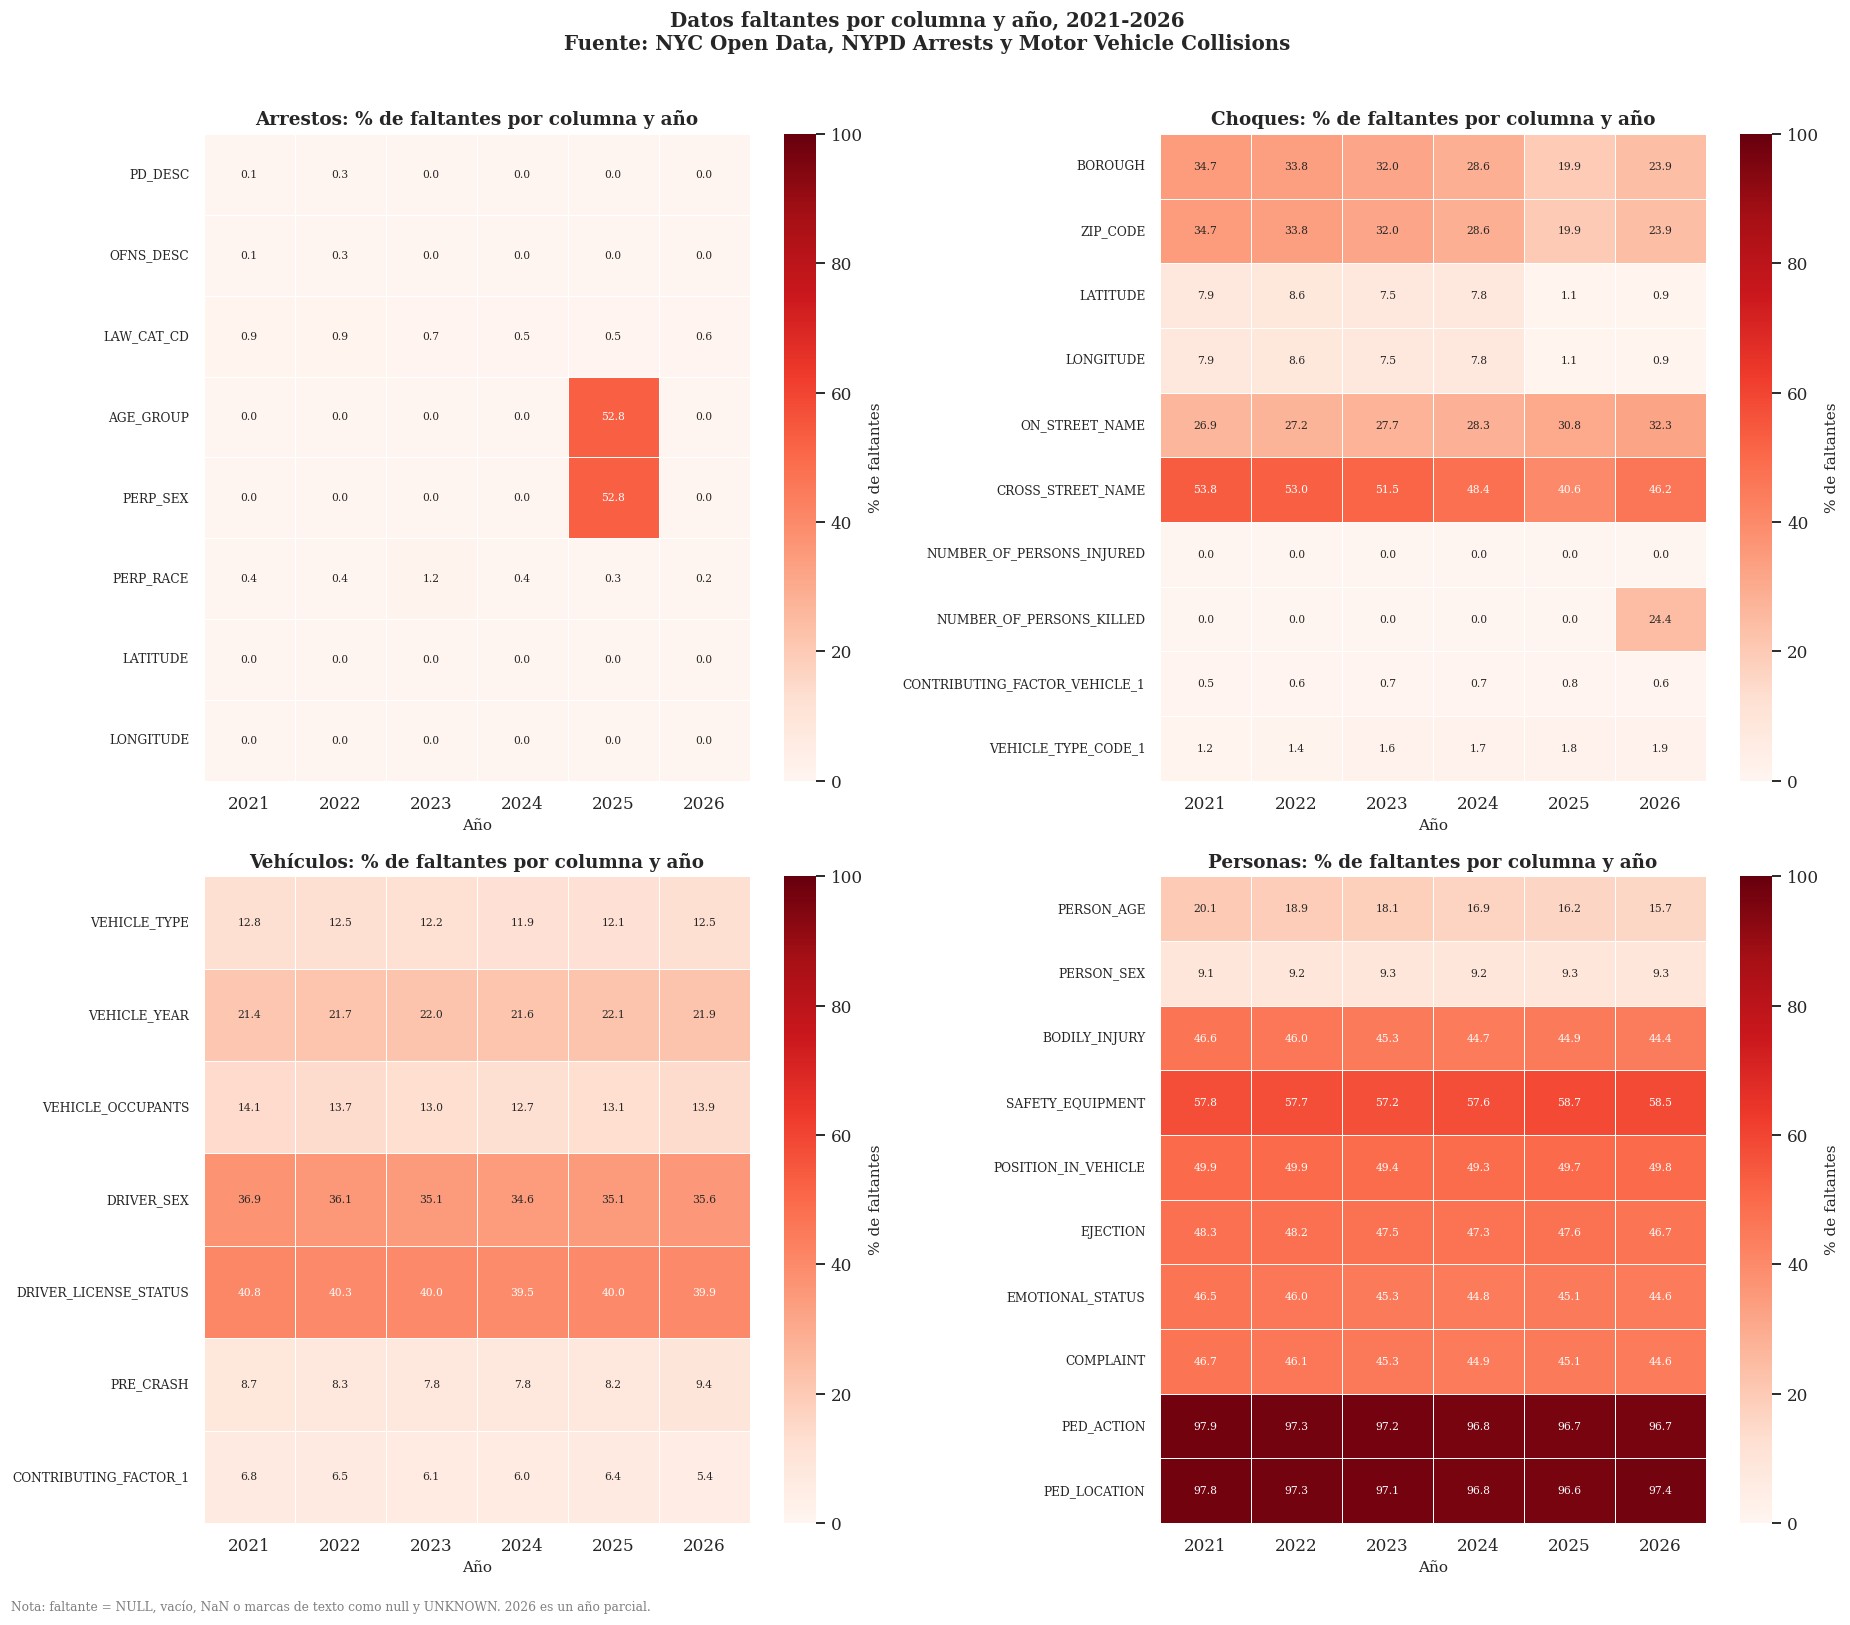

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(17, 15))
for ax, base in zip(axes.ravel(), ["Arrestos", "Choques", "Vehículos", "Personas"]):
    pdf = FALTANTES[base].set_index("GRUPO")
    columnas = [c for c in pdf.columns if c not in ("FILAS", "FILAS_NO_CONVERTIBLES") and pdf[c].sum() > 0]
    if not columnas:
        ax.text(0.5, 0.5, "Sin datos faltantes", ha="center", va="center")
        ax.set_axis_off()
        continue
    # Porcentaje de faltantes de cada columna dentro de cada año
    matriz = pdf[columnas].div(pdf["FILAS"], axis=0).T * 100
    sns.heatmap(matriz, ax=ax, cmap="Reds", vmin=0, vmax=100, annot=True, fmt=".1f",
                annot_kws={"fontsize": 7}, linewidths=0.5, linecolor="white",
                cbar_kws={"label": "% de faltantes"})
    ax.set_title(f"{base}: % de faltantes por columna y año")
    ax.set_xlabel("Año")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Datos faltantes por columna y año, 2021-2026\nFuente: NYC Open Data, NYPD Arrests y Motor Vehicle Collisions",
             fontweight="bold", fontsize=13)
nota_figura(fig, "Nota: faltante = NULL, vacío, NaN o marcas de texto como null y UNKNOWN. 2026 es un año parcial.")
plt.tight_layout(rect=[0, 0.02, 1, 0.97])
plt.show()

**Análisis:** El mapa de calor confirma que algunos vacíos se concentran en un solo año. La edad y el sexo de los arrestos faltan solo en 2025, en el 52.8% de los registros, y el dato de muertos de Crashes falta solo en 2026, en el 24.4%. Por eso los perfiles de edad y sexo no usan 2025 y los muertos de 2026 no se comparan. Otros vacíos mejoran con el tiempo: el distrito de los choques pasa de faltar en el 34.7% en 2021 al 19.9% en 2025, las coordenadas de 7.9% a 1.1% y la edad en Person de 20.1% a 15.7%. Los vacíos de Vehicles y de Person son casi iguales todos los años, lo que indica que vienen del formulario y no de un error de un año.

### 4.2 Técnica propuesta para cada caso

Los faltantes tienen causas distintas, así que no se tratan igual. No se rellena con la media ni con el valor más común, porque la mayoría de los vacíos vienen de cómo están hechos los formularios y no de fallas al azar.

| Base | Columna o caso | Tipo de faltante | Técnica propuesta |
|---|---|---|---|
| Arrestos | `LAW_CAT_CD`, `PERP_RACE`, `OFNS_DESC` | Categórico faltante | Etiqueta "NO ESPECIFICADO"; el arresto se conserva |
| Arrestos | `AGE_GROUP`, `PERP_SEX` en 2025 | Falta en cerca de la mitad de los registros de 2025 | Etiqueta "NO ESPECIFICADO"; los perfiles de edad y sexo usan 2021-2024 y 2026 |
| Arrestos | `LATITUDE`, `LONGITUDE` | Coordenada vacía o fuera de la ciudad | El arresto cuenta en su distrito, pero queda sin PUMA; se reporta en la sección 4.9 |
| Choques | `BOROUGH` | Distrito vacío | Se completa por ubicación con el voto mayoritario de su celda de 1 km² y se mide la consistencia del método |
| Choques | `LATITUDE`, `LONGITUDE` | Sin coordenada | Queda sin PUMA; si tampoco trae distrito, sale de las tasas territoriales |
| Choques | `NUMBER_OF_PERSONS_KILLED` en 2026 | Dato de muertos vacío en una parte de los choques | No se rellena con 0: los muertos de 2026 no se comparan. Un choque con víctimas se cuenta con coalesce de heridos y muertos en la condición |
| Choques | `CRASH_TIME` en 00:00 | Hora de relleno | Se marca con `HORA_RELLENO` y sale del análisis por hora |
| Choques | Columnas de conteo con texto | Fila desplazada | La fila se descarta y se reporta cuántas son |
| Vehículos | `VEHICLE_TYPE` | Tipo vacío o poco común | Categoría "OTROS / NO ESPECIFICADO" |
| Vehículos | `VEHICLE_OCCUPANTS` | Valores imposibles | Se anulan con un tope por tipo de vehículo, sin borrar el registro |
| Vehículos | `VEHICLE_YEAR` | Vacío o fuera de rango | Sale de los cálculos del año del modelo |
| Vehículos | `CONTRIBUTING_FACTOR_1` | Vacío o Unspecified | Fuera del ranking de causas; se reporta su peso |
| Personas | `PERSON_AGE` | Vacía o fuera de 0 a 110 años | Sale de los análisis de edad; no se imputa con la media |
| Personas | `SAFETY_EQUIPMENT`, `EJECTION`, `BODILY_INJURY` y columnas `PED_` | Campos que no aplican a todos los tipos de persona | Etiqueta "NO ESPECIFICADO" y análisis solo dentro del tipo de persona al que aplican |
| PUMS | `POVPIP`, `SCHL`, `ESR` | Vacío estructural: no aplica | Queda como no aplica y sale del denominador de esa tasa |
| SAT | "N<15" | Puntaje suprimido | Se excluye; no equivale a cero |
| Centros | `LATITUDE`, `LONGITUDE` o `BOROUGH` no estándar | Sin ubicación o programa de toda la ciudad | Cuenta en la ciudad, pero no en una PUMA o un distrito |
| Centros | `WORKSTATION_NUMBER` | Vacío | Sale del promedio por centro; no se imputa |
| Parques | Números guardados como texto | Texto no convertible | try_cast a double; el vacío no se imputa |
| Parques | `GISPROPNUM` repetido | Un mismo parque aparece en varias filas, una por cada parte, y todas repiten el área total | Se deja una fila por parque, la de la parte con más vértices, para no sumar el área varias veces |

### 4.3 Faltantes clave por año

Algunos vacíos cambian mucho de un año a otro y por eso deciden qué años se usan en cada análisis. La tabla sale de los conteos de la sección 4.1, sin volver a consultar el clúster.

In [21]:
FALTANTES_CLAVE = [("Arrestos", "AGE_GROUP"), ("Arrestos", "PERP_SEX"), ("Arrestos", "LAW_CAT_CD"),
                   ("Arrestos", "LATITUDE"), ("Choques", "BOROUGH"), ("Choques", "LATITUDE"),
                   ("Choques", "NUMBER_OF_PERSONS_INJURED"), ("Choques", "NUMBER_OF_PERSONS_KILLED"),
                   ("Vehículos", "VEHICLE_OCCUPANTS"), ("Personas", "PERSON_AGE"), ("Personas", "PERSON_SEX")]
filas_clave = []
for base, columna in FALTANTES_CLAVE:
    pdf = FALTANTES[base].set_index("GRUPO")
    fila = {"Base": base, "Columna": columna}
    for anio, valor in (pdf[columna] / pdf["FILAS"] * 100).items():
        fila[str(anio)] = valor
    filas_clave.append(fila)
pdf_faltantes_clave = pd.DataFrame(filas_clave)
columnas_anios = [c for c in pdf_faltantes_clave.columns if c not in ("Base", "Columna")]
mostrar_tabla(pdf_faltantes_clave, titulo="Porcentaje de registros con el dato faltante, por año",
              decimales=2, pct=columnas_anios)

Base,Columna,2021,2022,2023,2024,2025,2026
Arrestos,AGE_GROUP,0.00%,0.00%,0.00%,0.00%,52.78%,0.00%
Arrestos,PERP_SEX,0.00%,0.00%,0.00%,0.00%,52.78%,0.00%
Arrestos,LAW_CAT_CD,0.90%,0.92%,0.71%,0.54%,0.53%,0.61%
Arrestos,LATITUDE,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%
Choques,BOROUGH,34.67%,33.79%,31.96%,28.57%,19.91%,23.87%
Choques,LATITUDE,7.95%,8.61%,7.54%,7.77%,1.08%,0.90%
Choques,NUMBER_OF_PERSONS_INJURED,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%
Choques,NUMBER_OF_PERSONS_KILLED,0.00%,0.00%,0.00%,0.00%,0.00%,24.37%
Vehículos,VEHICLE_OCCUPANTS,14.07%,13.74%,13.05%,12.70%,13.11%,13.87%
Personas,PERSON_AGE,20.08%,18.92%,18.11%,16.85%,16.22%,15.73%


**Análisis:** La tabla resume con cifras exactas lo que se vio en el mapa de calor. Hay dos saltos que cambian el análisis: 52.78% de arrestos de 2025 sin edad ni sexo y 24.37% de choques de 2026 sin dato de muertos. En cambio, los heridos de Crashes y las coordenadas de los arrestos están completos todos los años. El distrito de los choques mejora con el tiempo, pero en 2026 vuelve a subir a 23.87%, así que la imputación por ubicación sigue siendo necesaria.

### 4.4 Textos no convertibles, filas desplazadas y hora de relleno

Primero se cuenta, por base, cuántas filas tienen algún texto que no se pudo convertir al tipo esperado. En Crashes una fila así es una fila desplazada, con los datos corridos de columna, y se descarta en la limpieza. También se cuentan los choques sin `COLLISION_ID`.

In [22]:
pdf_no_convertibles = pd.DataFrame([{
    "Base": base,
    "Filas": int(pdf["FILAS"].sum()),
    "Filas con texto no convertible": int(pdf["FILAS_NO_CONVERTIBLES"].sum()),
    "Porcentaje %": 100 * pdf["FILAS_NO_CONVERTIBLES"].sum() / pdf["FILAS"].sum(),
} for base, pdf in FALTANTES.items()])
mostrar_tabla(pdf_no_convertibles, titulo="Filas con algún texto que no se pudo convertir al tipo esperado",
              decimales={"Porcentaje %": 4}, pct=["Porcentaje %"])
print(f"Choques sin COLLISION_ID: {int(FALTANTES['Choques']['COLLISION_ID'].sum()):,}")

Base,Filas,Filas con texto no convertible,Porcentaje %
Arrestos,"1,253,479",0,0.0000%
Choques,"524,338",0,0.0000%
Vehículos,"1,057,393",0,0.0000%
Personas,"1,820,886",0,0.0000%
PUMS 2024,"67,511",0,0.0000%
SAT,"1,014",0,0.0000%
Centros de computadores,974,77,7.9055%
Parques,"2,936",0,0.0000%


Choques sin COLLISION_ID: 0


**Análisis:** Solo la base de centros de computadores tiene textos que no se pudieron convertir: 77 de 974 filas, el 7.91%. En esas filas algún campo numérico, como el año, el distrito comunitario o el número de computadores, traía texto; esos valores quedan en NULL y se reportan. Las demás bases no tienen ningún texto no convertible, y en 2021-2026 Crashes no tiene filas desplazadas ni choques sin COLLISION_ID. La fila desplazada que tiene el archivo completo es de un año anterior a 2021, que ya no se usa.

Después se revisa si 00:00 funciona como hora de relleno cuando no se conoce la hora real del choque. Si fuera así, el minuto 00:00 tendría muchos más choques que cualquier otro minuto de la noche. Por eso se compara contra el promedio por minuto de 00:01 a 00:59 y de 23:00 a 23:59, año por año. Las horas están en hora local de Nueva York.

In [23]:
pdf_medianoche = (df_choques_base.groupBy("ANIO").agg(
        F.count(F.when((F.col("HORA") == 0) & (F.col("MINUTO") == 0), 1)).alias("CHOQUES_0000"),
        F.count(F.when((F.col("HORA") == 0) & (F.col("MINUTO") >= 1), 1)).alias("CHOQUES_0001_0059"),
        F.count(F.when(F.col("HORA") == 23, 1)).alias("CHOQUES_2300_2359"),
        F.count("*").alias("CHOQUES"))
    .orderBy("ANIO").toPandas())
# 00:01 a 00:59 son 59 minutos y 23:00 a 23:59 son 60
pdf_medianoche["PROM_0001_0059"] = pdf_medianoche["CHOQUES_0001_0059"] / 59
pdf_medianoche["PROM_2300_2359"] = pdf_medianoche["CHOQUES_2300_2359"] / 60
pdf_medianoche["VECES_VS_0001"] = pdf_medianoche["CHOQUES_0000"] / pdf_medianoche["PROM_0001_0059"]
pdf_medianoche["VECES_VS_2300"] = pdf_medianoche["CHOQUES_0000"] / pdf_medianoche["PROM_2300_2359"]
pdf_medianoche["PCT_0000"] = pdf_medianoche["CHOQUES_0000"] / pdf_medianoche["CHOQUES"] * 100
mostrar_tabla(pdf_medianoche[["ANIO", "CHOQUES", "CHOQUES_0000", "PCT_0000", "PROM_0001_0059", "PROM_2300_2359",
                              "VECES_VS_0001", "VECES_VS_2300"]].rename(columns={
    "ANIO": "Año", "CHOQUES": "Choques", "CHOQUES_0000": "Choques a las 00:00", "PCT_0000": "A las 00:00 %",
    "PROM_0001_0059": "Promedio por minuto 00:01-00:59", "PROM_2300_2359": "Promedio por minuto 23:00-23:59",
    "VECES_VS_0001": "Veces frente a 00:01-00:59", "VECES_VS_2300": "Veces frente a 23:00-23:59"}),
    titulo="Choques a las 00:00 frente al promedio por minuto, hora de Nueva York", decimales=1,
    pct=["A las 00:00 %"])

Año,Choques,Choques a las 00:00,A las 00:00 %,Promedio por minuto 00:01-00:59,Promedio por minuto 23:00-23:59,Veces frente a 00:01-00:59,Veces frente a 23:00-23:59
2021,"110,558","1,912",1.7%,54.1,64.5,35.3,29.6
2022,"103,887","1,615",1.6%,51.3,59.3,31.5,27.2
2023,"96,607","1,616",1.7%,43.7,55.1,37.0,29.3
2024,"91,316","1,642",1.8%,42.1,50.2,39.0,32.7
2025,"85,546","1,742",2.0%,39.5,45.8,44.1,38.0
2026,"36,424",767,2.1%,15.6,19.7,49.1,39.0


**Análisis:** La hora 00:00 sí funciona como hora de relleno. Cada año hay entre 27.2 y 49.1 veces más choques a las 00:00 que en un minuto promedio de la noche, y el exceso crece con los años: 35.3 veces frente a 00:01-00:59 en 2021 y 49.1 en 2026. Son entre el 1.6% y el 2.1% de los choques, una parte pequeña, pero suficiente para crear un pico falso a la medianoche. Por eso estos choques se marcan con HORA_RELLENO y salen del análisis por hora.

### 4.5 Cobertura real de Person

La actualización de Person estuvo pausada, así que no se supone su cobertura: se verifica. Primero se comparan las fechas mínima y máxima de las tres tablas de choques, en el archivo completo y en el periodo de análisis.

In [24]:
# rango_fechas: recibe un DataFrame con FECHA y devuelve la fecha mínima y la máxima en una sola fila
def rango_fechas(df):
    fila = df.agg(F.min("FECHA").alias("MIN"), F.max("FECHA").alias("MAX")).first()
    return fila["MIN"], fila["MAX"]

filas_rango = []
for base, df, meta in [("Choques, Crashes", df_choques_base, meta_choques),
                       ("Vehículos, Vehicles", df_vehiculos_base, meta_vehiculos),
                       ("Personas, Person", df_personas_base, meta_personas),
                       ("Arrestos YTD 2026", df_arrestos_base.filter(F.col("FUENTE") == "YTD"), meta_arrestos.get("YTD", {}))]:
    minimo, maximo = rango_fechas(df)
    filas_rango.append({"Base": base, "Fecha mínima del archivo": str(meta.get("FECHA_MIN_ARCHIVO")),
                        "Fecha máxima del archivo": str(meta.get("FECHA_MAX_ARCHIVO")),
                        "Fecha mínima en el periodo": str(minimo), "Fecha máxima en el periodo": str(maximo)})
mostrar_tabla(pd.DataFrame(filas_rango), titulo="Cobertura de fechas de las bases de choques y de los arrestos de 2026")

Base,Fecha mínima del archivo,Fecha máxima del archivo,Fecha mínima en el periodo,Fecha máxima en el periodo
"Choques, Crashes",2012-07-01,2026-06-11,2021-01-01,2026-06-11
"Vehículos, Vehicles",2012-07-01,2026-06-11,2021-01-01,2026-06-11
"Personas, Person",2012-07-01,2026-06-11,2021-01-01,2026-06-11
Arrestos YTD 2026,2026-01-01,2026-06-30,2026-01-01,2026-06-30


**Análisis:** Las tres tablas de choques cubren exactamente las mismas fechas: del 1 de julio de 2012 al 11 de junio de 2026, y en el periodo de análisis van del 1 de enero de 2021 al 11 de junio de 2026. Aunque la actualización de Person estuvo pausada, el archivo descargado llega a la misma fecha que Crashes. Los arrestos de 2026 llegan hasta el 30 de junio, así que el periodo común de 2026 lo define el 11 de junio de los choques.

Luego se compara mes a mes el número de choques de Crashes con el número de choques que tienen al menos una persona registrada en Person. Si Person dejó de actualizarse en algún tramo, ese porcentaje cae.

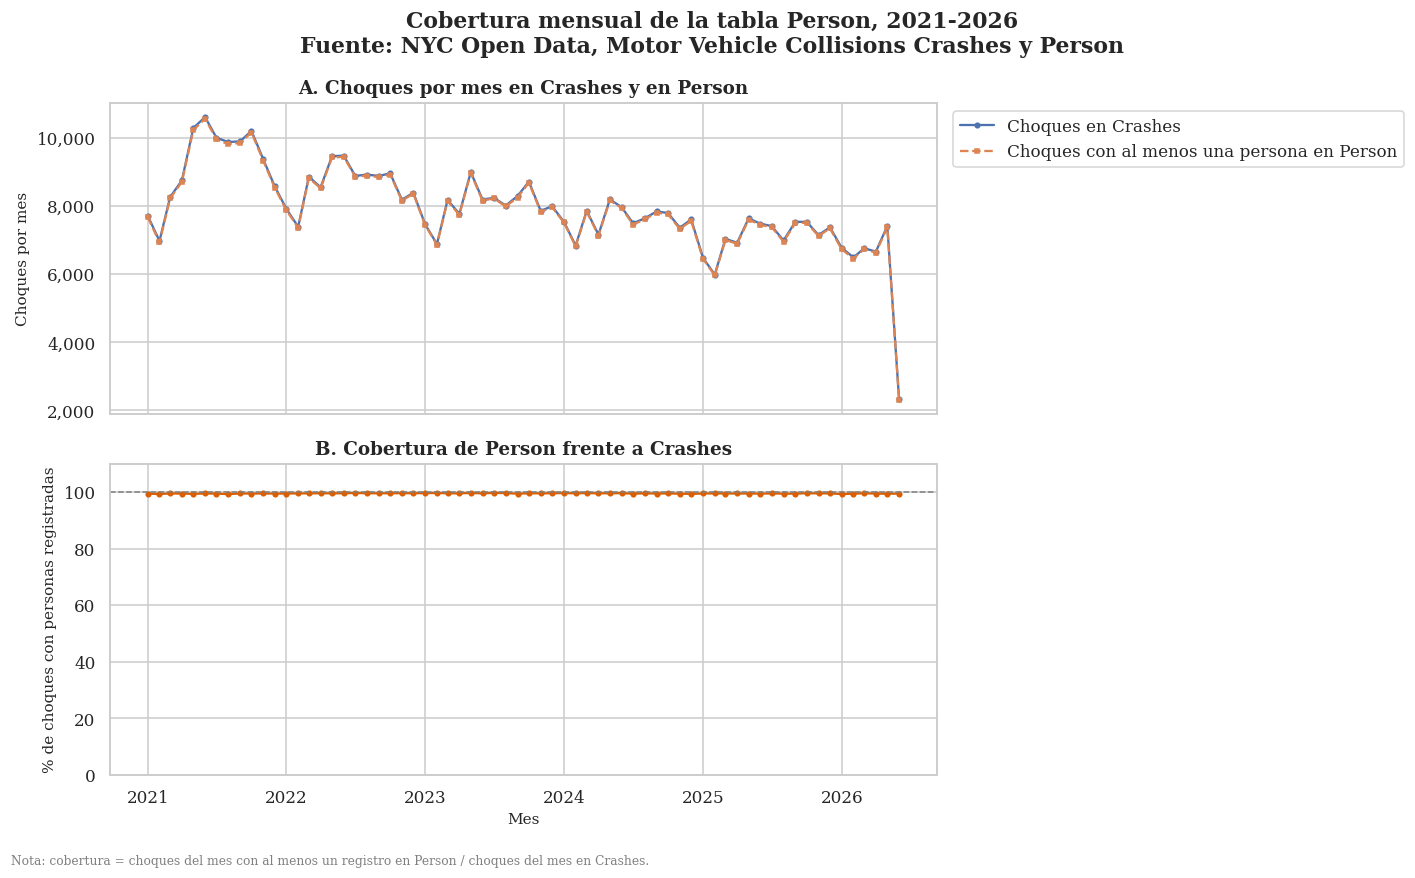

Meses con cobertura menor al 90%: []


In [25]:
pdf_personas_mes = (df_personas_base.groupBy(F.trunc("FECHA", "month").alias("MES"))
                    .agg(F.count("*").alias("PERSONAS"), F.countDistinct("COLLISION_ID").alias("CHOQUES_EN_PERSON"))
                    .toPandas())
pdf_choques_mes = (df_choques_base.groupBy(F.trunc("FECHA", "month").alias("MES"))
                   .agg(F.count("*").alias("CHOQUES")).toPandas())
pdf_cobertura = (pdf_choques_mes.merge(pdf_personas_mes, on="MES", how="outer").sort_values("MES")
                 .fillna({"CHOQUES": 0, "PERSONAS": 0, "CHOQUES_EN_PERSON": 0}))
pdf_cobertura["MES"] = pd.to_datetime(pdf_cobertura["MES"])
pdf_cobertura["COBERTURA_PCT"] = np.where(pdf_cobertura["CHOQUES"] > 0,
                                          pdf_cobertura["CHOQUES_EN_PERSON"] / pdf_cobertura["CHOQUES"] * 100, np.nan)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(pdf_cobertura["MES"], pdf_cobertura["CHOQUES"], marker="o", ms=3, label="Choques en Crashes")
axes[0].plot(pdf_cobertura["MES"], pdf_cobertura["CHOQUES_EN_PERSON"], marker="s", ms=3, linestyle="--",
             label="Choques con al menos una persona en Person")
axes[0].set_ylabel("Choques por mes")
formato_miles(axes[0].yaxis)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
axes[0].set_title("A. Choques por mes en Crashes y en Person")
axes[1].plot(pdf_cobertura["MES"], pdf_cobertura["COBERTURA_PCT"], color="#d95f02", marker="o", ms=3)
axes[1].axhline(100, color="gray", linestyle="--", lw=1)
axes[1].set_ylim(0, 110)
axes[1].set_ylabel("% de choques con personas registradas")
axes[1].set_xlabel("Mes")
axes[1].set_title("B. Cobertura de Person frente a Crashes")
fig.suptitle("Cobertura mensual de la tabla Person, 2021-2026\nFuente: NYC Open Data, Motor Vehicle Collisions Crashes y Person",
             fontweight="bold")
nota_figura(fig, "Nota: cobertura = choques del mes con al menos un registro en Person / choques del mes en Crashes.")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()
print("Meses con cobertura menor al 90%:",
      pdf_cobertura.loc[pdf_cobertura["COBERTURA_PCT"] < 90, "MES"].dt.strftime("%Y-%m").tolist())

**Análisis:** Person tiene registros para prácticamente todos los choques de cada mes: la cobertura está cerca del 100% en todo el periodo y ningún mes baja del 90%. Las dos líneas del panel A van casi superpuestas. El panel A también muestra la tendencia de los choques: el pico es a mediados de 2021, con más de 10,000 choques al mes, y después bajan hasta cerca de 6,500 a 7,500 al mes en 2025 y 2026. El último punto cae porque junio de 2026 solo tiene datos hasta el día 11, no porque haya menos choques.

Por último se revisa si la edad 0 funciona como relleno en Person, con la misma idea de la hora 00:00: si la edad 0 tiene muchas más personas que las edades de 1 a 5, es probable que se use cuando no se conoce la edad.

In [26]:
pdf_edad_baja = (df_personas_base.filter(F.col("PERSON_AGE").between(0, 10))
                 .groupBy("PERSON_AGE").agg(F.count("*").alias("PERSONAS")).orderBy("PERSON_AGE").toPandas())
promedio_1_5 = pdf_edad_baja.loc[pdf_edad_baja["PERSON_AGE"].between(1, 5), "PERSONAS"].mean()
mostrar_tabla(pdf_edad_baja.rename(columns={"PERSON_AGE": "Edad", "PERSONAS": "Personas"}),
              titulo="Personas con edad de 0 a 10 años en Person, 2021-2026")
print(f"Personas con edad 0 frente al promedio de las edades 1 a 5: "
      f"{pdf_edad_baja.loc[pdf_edad_baja['PERSON_AGE'] == 0, 'PERSONAS'].sum() / promedio_1_5:,.1f} veces")

Edad,Personas
0,"3,567"
1,"3,333"
2,"3,232"
3,"3,925"
4,"4,335"
5,"4,383"
6,"4,693"
7,"5,252"
8,"4,874"
9,"4,831"


Personas con edad 0 frente al promedio de las edades 1 a 5: 0.9 veces


**Análisis:** La edad 0 no funciona como relleno en Person: tiene 3,567 personas, 0.9 veces el promedio de las edades de 1 a 5 años. Si se usara para marcar una edad desconocida tendría muchas más personas que las edades vecinas. Por eso la edad 0 se conserva como una edad válida de bebés involucrados en choques.

### 4.6 Unicidad de llaves e integridad referencial

Se comprueba que cada registro tenga un identificador único y no vacío. Cada revisión es una sola agregación: cuenta los registros, las llaves con alguna parte vacía y las llaves distintas.

In [27]:
# revisar_llave: recibe un DataFrame, la lista de columnas de la llave y el nombre de la base. Devuelve
# una fila con registros, llaves vacías y llaves repetidas. countDistinct ignora las filas con alguna
# parte de la llave vacía, por eso las repetidas son las llaves no vacías menos las distintas
def revisar_llave(df, llaves, nombre):
    nula = F.lit(False)
    for c in llaves:
        nula = nula | F.col(c).isNull()
    fila = df.agg(F.count("*").alias("REG"), F.count(F.when(nula, 1)).alias("NULA"),
                  F.countDistinct(*[F.col(c) for c in llaves]).alias("DISTINTAS")).first()
    return {"Base": nombre, "Llave": " + ".join(llaves), "Registros": fila["REG"], "Llave vacía": fila["NULA"],
            "Llaves repetidas": fila["REG"] - fila["NULA"] - fila["DISTINTAS"]}

pdf_llaves = pd.DataFrame([
    revisar_llave(df_arrestos_base, ["ARREST_KEY"], "Arrestos 2021-2026"),
    revisar_llave(df_choques_base, ["COLLISION_ID"], "Choques"),
    revisar_llave(df_vehiculos_base, ["UNIQUE_ID"], "Vehículos"),
    revisar_llave(df_personas_base, ["UNIQUE_ID"], "Personas"),
    revisar_llave(df_pums_base, ["SERIALNO", "SPORDER"], "PUMS 2024"),
    revisar_llave(df_sat_base, ["CURSO", "DBN"], "SAT"),
    revisar_llave(df_centros_base, ["CALENDAR_YEAR", "OBJECT_IDENTIFICATION_NUMBER"], "Centros de computadores"),
    revisar_llave(df_parques_base, ["GISPROPNUM"], "Parques"),
])
mostrar_tabla(pdf_llaves, titulo="Unicidad de las llaves de cada base")

Base,Llave,Registros,Llave vacía,Llaves repetidas
Arrestos 2021-2026,ARREST_KEY,"1,253,479",0,0
Choques,COLLISION_ID,"524,338",0,0
Vehículos,UNIQUE_ID,"1,057,393",0,0
Personas,UNIQUE_ID,"1,820,886",0,0
PUMS 2024,SERIALNO + SPORDER,"67,511",0,0
SAT,CURSO + DBN,"1,014",0,0
Centros de computadores,CALENDAR_YEAR + OBJECT_IDENTIFICATION_NUMBER,974,10,0
Parques,GISPROPNUM,"2,936",0,"1,125"


**Análisis:** Las llaves de arrestos, choques, vehículos, personas, PUMS y SAT son únicas y nunca están vacías, así que cada registro se cuenta una sola vez. En los centros hay 10 registros con la llave incompleta, sin año o sin identificador. En parques, 1,125 filas repiten un GISPROPNUM ya usado: un mismo parque aparece en varias filas, una por cada parte de su contorno, y todas repiten el área total del parque. Por ejemplo, Pelham Bay Park aparece 3 veces con 2,434.52 acres. Sumar todas las filas daba 63,971 acres, frente a 27,041.5 con una fila por parque. Por eso en la limpieza se deja una sola fila por GISPROPNUM.

Después se revisa la integridad entre tablas: Vehicles y Person deben apuntar a choques que existan en Crashes por `COLLISION_ID`, y se cuenta cuántos choques no tienen vehículos o personas. También se verifica que el histórico y el YTD de arrestos no compartan arrestos ni fechas, y que las PUMAs de PUMS sean las mismas del GeoJSON. `left_anti` devuelve las filas de la izquierda que no encuentran pareja a la derecha.

In [28]:
ids_choques = df_choques_base.filter(F.col("COLLISION_ID").isNotNull()).select("COLLISION_ID").distinct()
ids_vehiculos = df_vehiculos_base.filter(F.col("COLLISION_ID").isNotNull()).select("COLLISION_ID").distinct()
ids_personas = df_personas_base.filter(F.col("COLLISION_ID").isNotNull()).select("COLLISION_ID").distinct()

vehiculos_huerfanos = (df_vehiculos_base.filter(F.col("COLLISION_ID").isNotNull())
                       .join(ids_choques, "COLLISION_ID", "left_anti").count())
personas_huerfanas = (df_personas_base.filter(F.col("COLLISION_ID").isNotNull())
                      .join(ids_choques, "COLLISION_ID", "left_anti").count())
choques_sin_vehiculos = ids_choques.join(ids_vehiculos, "COLLISION_ID", "left_anti").count()
choques_sin_personas = ids_choques.join(ids_personas, "COLLISION_ID", "left_anti").count()
total_choques_ids = ids_choques.count()

# Arrestos: llaves compartidas entre el histórico y el YTD, y separación de fechas
hist = df_arrestos_base.filter(F.col("FUENTE") == "HISTORICO")
ytd = df_arrestos_base.filter(F.col("FUENTE") == "YTD")
llaves_compartidas = (hist.select("ARREST_KEY").distinct()
                      .join(ytd.select("ARREST_KEY").distinct(), "ARREST_KEY", "inner").count())
fecha_max_hist = hist.agg(F.max("FECHA")).first()[0]
fecha_min_ytd = ytd.agg(F.min("FECHA")).first()[0]

# PUMAs de PUMS frente a las del GeoJSON; son 55 filas, así que collect es liviano
pumas_pums = {fila["PUMA"] for fila in df_pums_base.select("PUMA").distinct().collect()}
pumas_geo_set = set(CODIGOS_PUMA_GEO)

pdf_integridad = pd.DataFrame([
    ("Vehículos cuyo COLLISION_ID no está en Crashes", f"{vehiculos_huerfanos:,}"),
    ("Personas cuyo COLLISION_ID no está en Crashes", f"{personas_huerfanas:,}"),
    ("Choques sin ningún vehículo en Vehicles", f"{choques_sin_vehiculos:,} de {total_choques_ids:,}"),
    ("Choques sin ninguna persona en Person", f"{choques_sin_personas:,} de {total_choques_ids:,}"),
    ("Arrestos compartidos entre histórico y YTD", f"{llaves_compartidas:,}"),
    ("Última fecha del histórico y primera del YTD", f"{fecha_max_hist} y {fecha_min_ytd}"),
    ("PUMAs en PUMS 2024 y en el GeoJSON", f"{len(pumas_pums)} y {len(pumas_geo_set)}"),
    ("PUMAs de PUMS que no están en el GeoJSON", str(sorted(pumas_pums - pumas_geo_set))),
    ("PUMAs del GeoJSON que no están en PUMS", str(sorted(pumas_geo_set - pumas_pums))),
], columns=["Control", "Resultado"])
mostrar_tabla(pdf_integridad, titulo="Integridad referencial entre tablas")

Control,Resultado
Vehículos cuyo COLLISION_ID no está en Crashes,0
Personas cuyo COLLISION_ID no está en Crashes,0
Choques sin ningún vehículo en Vehicles,"82 de 524,338"
Choques sin ninguna persona en Person,"2,217 de 524,338"
Arrestos compartidos entre histórico y YTD,0
Última fecha del histórico y primera del YTD,2025-12-31 y 2026-01-01
PUMAs en PUMS 2024 y en el GeoJSON,55 y 55
PUMAs de PUMS que no están en el GeoJSON,[]
PUMAs del GeoJSON que no están en PUMS,[]


**Análisis:** La relación entre las tres tablas de choques está completa: ningún vehículo ni ninguna persona apunta a un choque que no exista en Crashes. Solo 82 choques no tienen vehículos y 2,217, el 0.42%, no tienen personas, así que unir las tablas por COLLISION_ID casi no pierde información. El histórico y el YTD de arrestos no comparten ningún arresto y se pegan sin huecos: el histórico termina el 31 de diciembre de 2025 y el YTD empieza el 1 de enero de 2026. Las 55 PUMAs de PUMS son exactamente las mismas del GeoJSON.

Como prueba adicional de integridad, se comparan por año los heridos y muertos que registra Crashes en cada choque con los que se cuentan en Person para ese mismo choque. Si las dos tablas cuentan igual, el porcentaje de coincidencia debe ser alto; si Person está incompleta en un año, baja.

In [29]:
victimas_person = (df_personas_base.groupBy("COLLISION_ID").agg(
    F.count(F.when(F.upper(F.trim(F.col("PERSON_INJURY"))) == "INJURED", 1)).alias("HERIDOS_PERSON"),
    F.count(F.when(F.upper(F.trim(F.col("PERSON_INJURY"))) == "KILLED", 1)).alias("MUERTOS_PERSON")))
pdf_coincidencia = (df_choques_base.select("COLLISION_ID", "ANIO", "NUMBER_OF_PERSONS_INJURED", "NUMBER_OF_PERSONS_KILLED")
    .join(victimas_person, "COLLISION_ID", "inner")
    .groupBy("ANIO").agg(
        F.count("*").alias("CHOQUES_EN_AMBAS"),
        F.avg((F.col("NUMBER_OF_PERSONS_INJURED") == F.col("HERIDOS_PERSON")).cast("int")).alias("COINCIDEN_HERIDOS"),
        F.avg((F.col("NUMBER_OF_PERSONS_KILLED") == F.col("MUERTOS_PERSON")).cast("int")).alias("COINCIDEN_MUERTOS"))
    .orderBy("ANIO").toPandas())
for c in ["COINCIDEN_HERIDOS", "COINCIDEN_MUERTOS"]:
    pdf_coincidencia[c] = pdf_coincidencia[c] * 100
mostrar_tabla(pdf_coincidencia.rename(columns={"ANIO": "Año", "CHOQUES_EN_AMBAS": "Choques en Crashes y Person",
    "COINCIDEN_HERIDOS": "Heridos coinciden %", "COINCIDEN_MUERTOS": "Muertos coinciden %"}),
    titulo="Coincidencia de víctimas entre Crashes y Person por choque", decimales=2,
    pct=["Heridos coinciden %", "Muertos coinciden %"])
print("Nota: avg ignora los choques sin dato de muertos en Crashes, que no se pueden comparar.")

Año,Choques en Crashes y Person,Heridos coinciden %,Muertos coinciden %
2021,"110,007",100.00%,100.00%
2022,"103,501",100.00%,100.00%
2023,"96,267",100.00%,100.00%
2024,"90,938",100.00%,100.00%
2025,"85,168",100.00%,100.00%
2026,"36,240",100.00%,100.00%


Nota: avg ignora los choques sin dato de muertos en Crashes, que no se pueden comparar.


**Análisis:** Para todos los choques que están en las dos tablas, los heridos y los muertos que cuenta Person coinciden al 100% con los que registra Crashes, en todos los años. Esto confirma que Person está completa y es confiable para separar a las víctimas por tipo de persona, edad y lesión. También confirma que los muertos que faltan en 2026 son un vacío de Crashes y no de Person.

### 4.7 Calidad específica de los centros de computadores y de los parques

En los centros se revisa, por año, el estado del centro, los distritos que no son uno de los cinco, las coordenadas y el número de computadores. El archivo trae un registro por centro y por año.

In [30]:
distrito_centro = F.upper(F.trim(F.col("BOROUGH")))
pdf_calidad_centros = (df_centros_base.groupBy("CALENDAR_YEAR").agg(
        F.count("*").alias("REGISTROS"),
        F.countDistinct("OBJECT_IDENTIFICATION_NUMBER").alias("CENTROS_DISTINTOS"),
        F.count(F.when(F.lower(F.col("STATUS")).contains("open"), 1)).alias("ESTADO_ABIERTO"),
        F.count(F.when(F.lower(F.col("STATUS")).contains("closed"), 1)).alias("ESTADO_CERRADO"),
        F.count(F.when(F.col("STATUS").isNull() | (F.trim(F.col("STATUS")) == ""), 1)).alias("SIN_ESTADO"),
        F.count(F.when(~distrito_centro.isin(ORDEN_BORO) | distrito_centro.isNull(), 1)).alias("DISTRITO_NO_ESTANDAR"),
        F.count(F.when(~coord_valida(), 1)).alias("SIN_COORDENADA_VALIDA"),
        F.count(F.when(F.col("WORKSTATION_NUMBER").isNull(), 1)).alias("COMPUTADORES_VACIO"),
        F.count(F.when(F.col("WORKSTATION_NUMBER") == 0, 1)).alias("COMPUTADORES_EN_CERO"))
    .orderBy("CALENDAR_YEAR").toPandas())
mostrar_tabla(pdf_calidad_centros.rename(columns={
    "CALENDAR_YEAR": "Año", "REGISTROS": "Registros", "CENTROS_DISTINTOS": "Centros distintos",
    "ESTADO_ABIERTO": "Estado abierto", "ESTADO_CERRADO": "Estado cerrado", "SIN_ESTADO": "Sin estado",
    "DISTRITO_NO_ESTANDAR": "Distrito no estándar", "SIN_COORDENADA_VALIDA": "Sin coordenada válida",
    "COMPUTADORES_VACIO": "Computadores vacío", "COMPUTADORES_EN_CERO": "Computadores en cero"}),
    titulo="Calidad de los centros públicos de computadores por año")

Año,Registros,Centros distintos,Estado abierto,Estado cerrado,Sin estado,Distrito no estándar,Sin coordenada válida,Computadores vacío,Computadores en cero
,9,1,0,0,6,9,9,9,0
2025,450,450,0,0,450,4,2,68,31
2026,515,514,471,44,0,4,3,99,37


**Análisis:** El archivo de centros trae dos años completos, 2025 con 450 registros y 2026 con 515, y 9 filas sin año que no se pueden usar. El registro de 2025 no trae el estado de ningún centro, por eso el análisis usa 2026: 471 centros tienen estado abierto y 44 cerrado. En 2026 hay 99 centros sin número de computadores y 37 con cero, así que el total de computadores es un mínimo y no el valor real.

Se listan los valores del campo `Borough` que no son uno de los cinco distritos, para ver si son programas de toda la ciudad o errores de digitación.

In [31]:
# Los valores de distrito que no son uno de los cinco; la tabla tiene pocas filas
mostrar_tabla(df_centros_base.filter(~distrito_centro.isin(ORDEN_BORO) | distrito_centro.isNull())
              .groupBy("BOROUGH").agg(F.count("*").alias("Registros")).toPandas()
              .rename(columns={"BOROUGH": "Valor de Borough"}),
              titulo="Valores de Borough que no son uno de los cinco distritos")

Valor de Borough,Registros
"Manhattan,Brooklyn,Bronx,Queens,Staten Island",3
"204 East 23rd Street 2nd Floor Manhattan, 10010, Manhattan, New York, USA",1
,7
Citywide,3
QN1306,2
"Brooklyn,Manhattan,Queens,Staten Island,Bronx",1


**Análisis:** Los 17 valores de distrito que no son uno de los cinco son de dos tipos. Unos son programas de toda la ciudad, escritos como Citywide o como la lista de los cinco distritos; otros son errores de digitación, como una dirección completa o un código como QN1306 en lugar del distrito. Son pocos registros, así que cuentan en el total de la ciudad pero no en un distrito; los que tienen coordenadas sí se ubican en su PUMA.

En los parques se verifica la coherencia entre `recreation_category` y los porcentajes de recreación activa y pasiva, sin corregir nada. Como regla de referencia, un espacio debería ser Active si su porcentaje activo es mayor que el pasivo, Passive si es al revés y Mixed si son iguales. También se revisa que los dos porcentajes sumen 100 y que los acres activos más los pasivos den los acres totales.

In [32]:
df_parques_revision = (df_parques_base
    .withColumn("CATEGORIA", F.upper(F.trim(F.col("RECREATION_CATEGORY"))))
    .withColumn("CATEGORIA_SEGUN_PCT",
                F.when(F.col("ACTIVE_PERCENT") > F.col("PASSIVE_PERCENT"), "ACTIVE")
                .when(F.col("PASSIVE_PERCENT") > F.col("ACTIVE_PERCENT"), "PASSIVE")
                .when(F.col("ACTIVE_PERCENT") == F.col("PASSIVE_PERCENT"), "MIXED")
                .otherwise("SIN DATO")))
# Tabla cruzada: categoría registrada contra la categoría que indican los porcentajes
pdf_cruce_parques = (df_parques_revision.groupBy(F.coalesce(F.col("CATEGORIA"), F.lit("VACÍA")).alias("CATEGORIA"),
                                                 "CATEGORIA_SEGUN_PCT")
                     .agg(F.count("*").alias("ESPACIOS")).toPandas()
                     .pivot(index="CATEGORIA", columns="CATEGORIA_SEGUN_PCT", values="ESPACIOS").fillna(0)
                     .reset_index().rename(columns={"CATEGORIA": "Categoría registrada"}))
mostrar_tabla(pdf_cruce_parques, titulo="Categoría registrada frente a la categoría que indican los porcentajes")

Categoría registrada,ACTIVE,MIXED,PASSIVE,SIN DATO
ACTIVE,825,62,419,0
MIXED,29,3,74,0
PASSIVE,619,45,859,0
VACÍA,0,0,0,1


**Análisis:** La categoría registrada no coincide con los porcentajes en muchos espacios. De los 1,306 espacios marcados como Active, 419 tienen más área pasiva que activa, y de los 1,523 marcados como Passive, 619 tienen más área activa. Mixed casi nunca coincide: solo 3 de 106. Esto indica que recreation_category sigue otro criterio y no sirve para medir el espacio activo. Por eso el análisis usa los acres activos y pasivos y no la categoría.

La segunda tabla resume los controles de coherencia de los parques: categorías que no cuadran, porcentajes que no suman 100, acres que no cuadran, acres vacíos y espacios sin punto representativo o sin PUMA. Nada se corrige.

In [33]:
controles_parques = df_parques_revision.agg(
    F.count("*").alias("ESPACIOS"),
    F.count(F.when(F.col("CATEGORIA") != F.col("CATEGORIA_SEGUN_PCT"), 1)).alias("NO_CUADRA_CATEGORIA"),
    F.count(F.when(F.abs(F.col("ACTIVE_PERCENT") + F.col("PASSIVE_PERCENT") - 100) > 0.5, 1)).alias("PCT_NO_SUMA_100"),
    F.count(F.when(F.abs(F.col("ACTIVE_ACRES") + F.col("PASSIVE_ACRES") - F.col("ACRES")) > 0.01, 1)).alias("ACRES_NO_CUADRAN"),
    F.count(F.when(F.col("ACRES").isNull() | (F.col("ACRES") <= 0), 1)).alias("ACRES_VACIO_O_CERO"),
    F.count(F.when(F.col("REP_LON").isNull(), 1)).alias("SIN_PUNTO"),
    F.count(F.when(F.col("PUMA").isNull(), 1)).alias("SIN_PUMA")).first().asDict()
mostrar_tabla(pd.DataFrame([{
    "Espacios": controles_parques["ESPACIOS"],
    "Categoría que no cuadra con los porcentajes": controles_parques["NO_CUADRA_CATEGORIA"],
    "Porcentajes que no suman 100": controles_parques["PCT_NO_SUMA_100"],
    "Acres activos más pasivos distintos del total": controles_parques["ACRES_NO_CUADRAN"],
    "Acres vacíos o en cero": controles_parques["ACRES_VACIO_O_CERO"],
    "Sin punto representativo": controles_parques["SIN_PUNTO"],
    "Punto sin PUMA": controles_parques["SIN_PUMA"]}]),
    titulo="Controles de coherencia de los parques, sin corregir")

Espacios,Categoría que no cuadra con los porcentajes,Porcentajes que no suman 100,Acres activos más pasivos distintos del total,Acres vacíos o en cero,Sin punto representativo,Punto sin PUMA
"2,936","1,248",4,155,4,0,54


**Análisis:** En total, 1,248 espacios, el 42.5%, tienen una categoría que no cuadra con sus porcentajes, lo que confirma la decisión de no usar la categoría. Los números sí son coherentes casi siempre: solo 4 espacios tienen porcentajes que no suman 100, 155 tienen acres activos más pasivos distintos del total y 4 tienen acres vacíos o en cero. Todos los espacios tienen punto representativo, pero 54 puntos, el 1.84%, no caen en ninguna PUMA; probablemente son espacios de la costa o con formas irregulares, donde el promedio de los vértices cae en el agua.

### 4.8 Limpieza previa a la exploración

Aquí se definen las transformaciones que necesita la exploración. Todas son perezosas: describen el plan y no se ejecutan hasta la siguiente acción.

- **Arrestos:** distrito con nombre completo, "NO ESPECIFICADO" en las categorías faltantes, variables de calendario y marca de coordenada válida.
- **Choques:** se descartan las filas desplazadas y sin llave; el distrito faltante se completa con el voto mayoritario de su celda de 0.01 grados, cerca de 1 km², usando como referencia los choques con distrito y los arrestos; se marcan la hora de relleno, los choques con víctimas y los choques sin dato de muertos.
- **Vehículos:** 8 categorías estandarizadas, tope de ocupantes por categoría y año del modelo plausible.
- **Personas:** tipo de persona en español, gravedad, edad válida de 0 a 110 años y grupo de edad.
- **Centros:** año más reciente, distrito estándar, estado abierto y número de computadores.
- **Parques:** una sola fila por GISPROPNUM, porque las partes de un mismo parque repiten su área total, y distrito en mayúsculas para que coincida con el orden y la paleta fijos.

In [34]:
# faltante_texto: recibe el nombre de una columna de texto y devuelve la condición de NULL, vacío o la marca null
def faltante_texto(columna):
    return F.col(columna).isNull() | F.lower(F.trim(F.col(columna))).isin("", "(null)", "null", "nan")

# etiqueta_texto: recibe una columna de texto y, opcionalmente, otros valores que también cuentan como
# faltantes; devuelve el texto en mayúsculas o "NO ESPECIFICADO" si falta
def etiqueta_texto(columna, otros_faltantes=()):
    falta = faltante_texto(columna)
    if otros_faltantes:
        falta = falta | F.upper(F.trim(F.col(columna))).isin(*otros_faltantes)
    return F.when(falta, F.lit("NO ESPECIFICADO")).otherwise(F.upper(F.trim(F.col(columna))))

# preparar_arrestos: recibe la base de arrestos y devuelve el DataFrame con distrito, etiquetas,
# calendario y marca de coordenada válida
def preparar_arrestos(df):
    return (df
        .withColumn("DISTRITO", mapa_spark(BORO_ARR)[F.upper(F.trim(F.col("ARREST_BORO")))])
        .withColumn("LAW_CAT_CD_CLEAN", etiqueta_texto("LAW_CAT_CD"))
        .withColumn("PERP_RACE_CLEAN", etiqueta_texto("PERP_RACE", ("UNKNOWN",)))
        .withColumn("AGE_GROUP_CLEAN", etiqueta_texto("AGE_GROUP"))
        .withColumn("PERP_SEX_CLEAN", etiqueta_texto("PERP_SEX"))
        .withColumn("OFNS_DESC_CLEAN", etiqueta_texto("OFNS_DESC"))
        .withColumn("MES", F.month("FECHA"))
        # dayofweek: 1 es domingo y 7 es sábado
        .withColumn("DIA_SEMANA", F.dayofweek("FECHA"))
        .withColumn("FIN_DE_SEMANA", F.dayofweek("FECHA").isin(1, 7).cast("int"))
        .withColumn("COORD_VALIDA", coord_valida()))

# preparar_choques: recibe la base de choques y los arrestos preparados. Descarta filas desplazadas y sin
# llave, completa el distrito por voto mayoritario de celda y agrega las marcas de calidad
def preparar_choques(df, df_arr):
    base = (df.filter((F.col("N_NO_CONVERTIBLES") == 0) & F.col("COLLISION_ID").isNotNull())
        .withColumn("BOROUGH_ORIG", F.when(F.upper(F.trim(F.col("BOROUGH"))).isin(ORDEN_BORO),
                                           F.upper(F.trim(F.col("BOROUGH")))))
        .withColumn("COORD_VALIDA", coord_valida())
        # Celda de 0.01 grados; queda en NULL si la coordenada no es válida
        .withColumn("CELDA_LAT", F.when(F.col("COORD_VALIDA"), F.floor(F.col("LATITUDE") * 100)))
        .withColumn("CELDA_LON", F.when(F.col("COORD_VALIDA"), F.floor(F.col("LONGITUDE") * 100))))
    # Puntos de referencia: choques con distrito original y arrestos con distrito y coordenada válida
    ref_choques = (base.filter(F.col("BOROUGH_ORIG").isNotNull() & F.col("CELDA_LAT").isNotNull())
                   .select("CELDA_LAT", "CELDA_LON", F.col("BOROUGH_ORIG").alias("BORO_REF")))
    ref_arrestos = (df_arr.filter(F.col("COORD_VALIDA") & F.col("DISTRITO").isNotNull())
                    .select(F.floor(F.col("LATITUDE") * 100).alias("CELDA_LAT"),
                            F.floor(F.col("LONGITUDE") * 100).alias("CELDA_LON"),
                            F.col("DISTRITO").alias("BORO_REF")))
    # La ventana ordena los distritos de cada celda por votos sin colapsar las filas; el empate se
    # rompe por orden alfabético para que el resultado no cambie entre corridas
    ventana = Window.partitionBy("CELDA_LAT", "CELDA_LON").orderBy(F.desc("VOTOS"), F.asc("BORO_REF"))
    mapa_celdas = (ref_choques.unionByName(ref_arrestos)
                   .groupBy("CELDA_LAT", "CELDA_LON", "BORO_REF").agg(F.count("*").alias("VOTOS"))
                   .withColumn("RN", F.row_number().over(ventana)).filter(F.col("RN") == 1)
                   .select("CELDA_LAT", "CELDA_LON", F.col("BORO_REF").alias("BOROUGH_CELDA")))
    victimas = (F.coalesce(F.col("NUMBER_OF_PERSONS_INJURED"), F.lit(0))
                + F.coalesce(F.col("NUMBER_OF_PERSONS_KILLED"), F.lit(0)))
    # broadcast: el mapa de celdas es pequeño y se envía completo a cada ejecutor, así no se barajan
    # los choques entre nodos
    return (base.join(F.broadcast(mapa_celdas), ["CELDA_LAT", "CELDA_LON"], "left")
        .withColumn("DISTRITO", F.coalesce("BOROUGH_ORIG", "BOROUGH_CELDA"))
        .withColumn("ORIGEN_DISTRITO", F.when(F.col("BOROUGH_ORIG").isNotNull(), "Original")
                    .when(F.col("BOROUGH_CELDA").isNotNull(), "Imputado por ubicación").otherwise("Sin dato"))
        .withColumn("HORA_RELLENO", F.coalesce((F.col("HORA") == 0) & (F.col("MINUTO") == 0), F.lit(False)).cast("int"))
        # Un choque con víctimas se cuenta con coalesce en la condición: un choque con heridos y sin dato
        # de muertos sí cuenta; el dato vacío no se convierte en cero en las sumas
        .withColumn("CON_VICTIMAS", (victimas > 0).cast("int"))
        .withColumn("CON_MUERTOS", F.coalesce(F.col("NUMBER_OF_PERSONS_KILLED") > 0, F.lit(False)).cast("int"))
        .withColumn("MUERTOS_SIN_DATO", F.col("NUMBER_OF_PERSONS_KILLED").isNull().cast("int"))
        .withColumn("DIA_SEMANA", F.dayofweek("FECHA")))

# Capacidad máxima razonable de ocupantes por categoría: un valor mayor es imposible y pasa a NULL
TOPE_OCUPANTES = {"SEDAN": 10, "SUV / STATION WAGON": 15, "TAXI": 10, "CAMION / PICK-UP / VAN": 20,
                  "MOTO / SCOOTER": 3, "BICICLETA / E-BIKE": 3, "AUTOBUS": 100, "OTROS / NO ESPECIFICADO": 100}

# categoria_vehiculo: recibe el nombre de la columna con el tipo de vehículo en mayúsculas y devuelve una
# de las 8 categorías estandarizadas. when se evalúa en orden y se queda con la primera condición que se
# cumple; PASSENGER VEHICLE, el nombre que se usaba antes de 2016, se une con SEDAN
def categoria_vehiculo(columna):
    t = F.col(columna)
    return (F.when(t.rlike("SEDAN"), "SEDAN")
            .when(t.rlike("SPORT UTILITY|STATION WAGON|SUV"), "SUV / STATION WAGON")
            .when(t.rlike("PASSENGER VEHICLE"), "SEDAN")
            .when(t.rlike("TAXI|CAB"), "TAXI")
            .when(t.rlike("PICK-UP|TRUCK|VAN|BOX TRUCK"), "CAMION / PICK-UP / VAN")
            .when(t.rlike("BIKE|BICYCLE"), "BICICLETA / E-BIKE")
            .when(t.rlike("BUS"), "AUTOBUS")
            .when(t.rlike("MOTORCYCLE|SCOOTER"), "MOTO / SCOOTER")
            .otherwise("OTROS / NO ESPECIFICADO"))

# preparar_vehiculos: recibe la base de vehículos y devuelve el DataFrame con categoría, ocupantes
# filtrados por el tope, año del modelo plausible y factor contribuyente con etiqueta
def preparar_vehiculos(df):
    return (df
        .withColumn("VEHICLE_TYPE_CLEAN", F.upper(F.trim(F.col("VEHICLE_TYPE"))))
        .withColumn("CATEGORIA_VEHICULO", categoria_vehiculo("VEHICLE_TYPE_CLEAN"))
        .withColumn("TOPE_OCUPANTES", mapa_spark(TOPE_OCUPANTES)[F.col("CATEGORIA_VEHICULO")])
        .withColumn("OCUPANTES_ALTERADO", F.coalesce((F.col("VEHICLE_OCCUPANTS") < 0)
                                                    | (F.col("VEHICLE_OCCUPANTS") > F.col("TOPE_OCUPANTES")), F.lit(False)))
        # El valor alterado pasa a NULL, pero el registro se conserva
        .withColumn("OCUPANTES", F.when(~F.col("OCUPANTES_ALTERADO"), F.col("VEHICLE_OCCUPANTS")))
        .withColumn("ANIO_MODELO", F.when(F.col("VEHICLE_YEAR").between(F.lit(1990), F.col("ANIO") + 1),
                                          F.col("VEHICLE_YEAR")))
        .withColumn("FACTOR_1", etiqueta_texto("CONTRIBUTING_FACTOR_1", ("UNSPECIFIED",))))

# preparar_personas: recibe la base de personas y devuelve el DataFrame con tipo de persona, gravedad,
# edad válida, grupo de edad y parte del cuerpo lesionada
def preparar_personas(df):
    tipo = F.upper(F.trim(F.col("PERSON_TYPE")))
    lesion = F.upper(F.trim(F.col("PERSON_INJURY")))
    edad_valida = F.col("PERSON_AGE").between(0, 110)
    edad = F.when(edad_valida, F.col("PERSON_AGE"))
    return (df
        .withColumn("TIPO_PERSONA", F.when(tipo == "PEDESTRIAN", "PEATÓN").when(tipo == "BICYCLIST", "CICLISTA")
                    .when(tipo == "OCCUPANT", "OCUPANTE").when(tipo == "OTHER MOTORIZED", "OTRO MOTORIZADO")
                    .otherwise("NO ESPECIFICADO"))
        .withColumn("GRAVEDAD", F.when(lesion == "KILLED", "MUERTO").when(lesion == "INJURED", "HERIDO")
                    .otherwise("SIN LESIÓN REPORTADA"))
        .withColumn("EDAD", edad)
        .withColumn("EDAD_FUERA_DE_RANGO", (F.col("PERSON_AGE").isNotNull() & ~edad_valida).cast("int"))
        .withColumn("GRUPO_EDAD", F.when(edad < 18, "<18").when(edad < 25, "18-24").when(edad < 45, "25-44")
                    .when(edad < 65, "45-64").when(edad >= 65, "65+").otherwise("NO ESPECIFICADO"))
        .withColumn("PARTE_CUERPO", etiqueta_texto("BODILY_INJURY", ("UNKNOWN", "DOES NOT APPLY"))))

# Año más reciente de los centros; es una agregación sobre unas mil filas
ANIO_CENTROS = df_centros_base.agg(F.max("CALENDAR_YEAR")).first()[0]

# preparar_centros: recibe la base de centros y el año; devuelve los centros de ese año con distrito
# estándar, marca de abierto, computadores y marca de coordenada válida
def preparar_centros(df, anio):
    distrito = F.upper(F.trim(F.col("BOROUGH")))
    return (df.filter(F.col("CALENDAR_YEAR") == anio)
        .withColumn("DISTRITO", F.when(distrito.isin(ORDEN_BORO), distrito))
        .withColumn("ABIERTO", F.when(F.col("STATUS").isNotNull(),
                                      F.lower(F.col("STATUS")).contains("open").cast("int")))
        .withColumn("COMPUTADORES", F.when(F.col("WORKSTATION_NUMBER") >= 0, F.col("WORKSTATION_NUMBER")))
        .withColumn("COORD_VALIDA", coord_valida()))

# preparar_parques: recibe la base de parques y devuelve una fila por espacio. El archivo trae varias filas
# con el mismo GISPROPNUM, una por cada parte del parque, y todas repiten el área total del parque; si se
# suman todas, los acres quedan inflados. Por eso se deja solo la fila de la parte con más vértices, que
# suele ser la más grande, y su punto representativo ubica el parque en una PUMA. Además pasa el distrito
# a mayúsculas y agrega el distrito de la PUMA
def preparar_parques(df):
    # row_number numera las filas de cada GISPROPNUM desde la parte con más vértices; se queda la número 1
    ventana_parque = Window.partitionBy("GISPROPNUM").orderBy(F.desc_nulls_last("N_VERTICES"), F.asc_nulls_last("PUMA"))
    return (df.withColumn("FILA_PARQUE", F.row_number().over(ventana_parque))
              .filter(F.col("FILA_PARQUE") == 1).drop("FILA_PARQUE")
              .withColumn("DISTRITO", F.upper(F.trim(F.col("BOROUGH"))))
              .withColumn("COORD_VALIDA", F.col("REP_LON").isNotNull())
              .withColumn("DISTRITO_PUMA", mapa_spark(PUMA_A_BORO)[F.floor(F.col("PUMA") / 100).cast("int")]))

df_arrestos_pre = preparar_arrestos(df_arrestos_base)
df_choques_pre = preparar_choques(df_choques_base, df_arrestos_pre)
df_vehiculos_pre = preparar_vehiculos(df_vehiculos_base)
df_personas_pre = preparar_personas(df_personas_base)
df_centros_pre = preparar_centros(df_centros_base, ANIO_CENTROS)
df_parques = preparar_parques(df_parques_base)
print(f"Transformaciones definidas. Año más reciente de los centros de computadores: {ANIO_CENTROS}")
# count es una acción: se cuentan los espacios antes y después de dejar una fila por GISPROPNUM
print(f"Parques: {df_parques_base.count():,} filas en el archivo y {df_parques.count():,} espacios distintos por GISPROPNUM")

Transformaciones definidas. Año más reciente de los centros de computadores: 2026
Parques: 2,936 filas en el archivo y 1,811 espacios distintos por GISPROPNUM


Antes de aplicar el tope de ocupantes se mira cómo se reparten los valores mayores a 10 en sedanes, SUV y taxis, para justificar un tope de 15 en las SUV. Después se cuenta cuántos valores anula el tope en cada categoría.

In [35]:
pdf_ocupantes_altos = (df_vehiculos_pre
    .filter(F.col("CATEGORIA_VEHICULO").isin("SUV / STATION WAGON", "SEDAN", "TAXI") & (F.col("VEHICLE_OCCUPANTS") > 10))
    .withColumn("RANGO", F.when(F.col("VEHICLE_OCCUPANTS") <= 15, "11-15")
                .when(F.col("VEHICLE_OCCUPANTS") <= 50, "16-50").otherwise("Más de 50"))
    .groupBy("CATEGORIA_VEHICULO", "RANGO").agg(F.count("*").alias("VEHICULOS")).toPandas()
    .pivot(index="CATEGORIA_VEHICULO", columns="RANGO", values="VEHICULOS").fillna(0).reset_index())
mostrar_tabla(pdf_ocupantes_altos.rename(columns={"CATEGORIA_VEHICULO": "Categoría"}),
              titulo="Vehículos con más de 10 ocupantes por rango, 2021-2026")

Categoría,11-15,16-50,Más de 50
SEDAN,19,10,27
SUV / STATION WAGON,71,13,16
TAXI,1,0,0


**Análisis:** La tabla justifica los topes de ocupantes. En las SUV, 71 de los 100 valores mayores a 10 están entre 11 y 15, una cifra posible en una camioneta grande, por eso su tope es 15. En los sedanes pasa lo contrario: 27 de los 56 valores mayores a 10 superan los 50 ocupantes, algo imposible en un carro. En los taxis solo hay un caso.

Con los topes por categoría, se cuenta cuántos valores de ocupantes quedan anulados. El registro del vehículo se conserva; solo el número de ocupantes pasa a NULL.

In [36]:
pdf_anulados =(df_vehiculos_pre.groupBy("CATEGORIA_VEHICULO", "TOPE_OCUPANTES").agg(
        F.count("*").alias("VEHICULOS"),
        F.count(F.when(F.col("OCUPANTES_ALTERADO"), 1)).alias("ANULADOS"))
    .orderBy(F.desc("VEHICULOS")).toPandas())
pdf_anulados["ANULADOS_PCT"] = pdf_anulados["ANULADOS"] / pdf_anulados["VEHICULOS"] * 100
mostrar_tabla(pdf_anulados.rename(columns={"CATEGORIA_VEHICULO": "Categoría", "TOPE_OCUPANTES": "Tope de ocupantes",
                                           "VEHICULOS": "Vehículos", "ANULADOS": "Valores anulados",
                                           "ANULADOS_PCT": "Anulados %"}),
              titulo="Valores de ocupantes anulados por el tope de cada categoría", decimales={"Anulados %": 3},
              pct=["Anulados %"])

Categoría,Tope de ocupantes,Vehículos,Valores anulados,Anulados %
SEDAN,10,"413,719",56,0.014%
SUV / STATION WAGON,15,"311,374",29,0.009%
OTROS / NO ESPECIFICADO,100,"169,694",7,0.004%
CAMION / PICK-UP / VAN,20,"62,250",5,0.008%
BICICLETA / E-BIKE,3,"40,904",9,0.022%
TAXI,10,"22,347",1,0.004%
AUTOBUS,100,"19,276",2,0.010%
MOTO / SCOOTER,3,"17,829",2,0.011%


**Análisis:** Los topes anulan muy pocos valores: 111 en total, el 0.01% de los 1,057,393 vehículos. La categoría con más anulados en proporción es bicicleta y e-bike, con 0.022%, por valores mayores a 3 ocupantes. El registro de cada vehículo se conserva; solo el número de ocupantes pasa a NULL, así que los conteos de vehículos no cambian y el promedio de ocupantes deja de estar distorsionado.

### 4.9 Asignación de puntos a PUMA y margen de error

Los arrestos, choques y centros traen coordenadas, pero no PUMA. Para ubicarlos sin código Python en los workers se siguen estos pasos:

1. En Spark se redondean la latitud y la longitud a 4 decimales y se agrupan: se obtiene cada par único con su número de registros.
2. Al Driver solo llegan los pares únicos. Si hay más de 500,000, se redondea a 3 decimales.
3. En el Driver cada par se asigna a su PUMA con `matplotlib.path.Path.contains_points` sobre los polígonos del GeoJSON.
4. La tabla de pares con su PUMA vuelve a Spark por un CSV en la carpeta compartida, se guarda en Parquet y se une a cada base con un broadcast join.

Las coordenadas redondeadas se guardan como enteros, por ejemplo 40.7128 pasa a 407128, para que el join compare números enteros y no decimales. Vehicles y Person reciben el distrito y la PUMA de su choque por `COLLISION_ID`. Con esto se guardan las bases limpias en Parquet.

In [37]:
DEC_INICIAL, MAX_PARES = 4, 500_000

# claves_coordenada: recibe el número de decimales y devuelve dos columnas enteras: la latitud y la
# longitud multiplicadas por 10 elevado a esos decimales y redondeadas
def claves_coordenada(dec):
    factor = 10 ** dec
    return (F.round(F.col("LATITUDE") * factor).cast("long").alias("LAT_E"),
            F.round(F.col("LONGITUDE") * factor).cast("long").alias("LON_E"))

# pares_unicos: recibe una lista de DataFrames con LATITUDE, LONGITUDE y COORD_VALIDA y los decimales;
# devuelve los pares únicos de coordenadas redondeadas con el número de registros de cada uno
def pares_unicos(fuentes, dec):
    union = None
    for df in fuentes:
        parte = df.filter(F.col("COORD_VALIDA")).select(*claves_coordenada(dec))
        union = parte if union is None else union.unionByName(parte)
    return union.groupBy("LAT_E", "LON_E").agg(F.count("*").alias("REGISTROS"))

# construir_tabla_puma: no recibe nada; arma los pares únicos de arrestos, choques y centros, los trae al
# Driver, los asigna a su PUMA y devuelve la tabla en Spark con sus metadatos
def construir_tabla_puma():
    fuentes = [df_arrestos_pre, df_choques_pre, df_centros_pre]
    dec = DEC_INICIAL
    # cache: los pares se usan dos veces, en count y en toPandas
    pares = pares_unicos(fuentes, dec).cache()
    n_pares = pares.count()
    if n_pares > MAX_PARES:
        pares.unpersist()
        dec = 3
        pares = pares_unicos(fuentes, dec).cache()
        n_pares = pares.count()
    print(f"Pares únicos con {dec} decimales: {n_pares:,}")
    # toPandas sobre una tabla ya agregada: solo los pares únicos llegan al Driver
    pdf = pares.toPandas()
    pares.unpersist()
    factor = 10 ** dec
    puma = asignar_puma(pdf["LON_E"].to_numpy() / factor, pdf["LAT_E"].to_numpy() / factor, pumas_geo)
    pdf["PUMA"] = pd.Series(puma, dtype="Int64").mask(puma == 0)
    esquema = {"LAT_E": "bigint", "LON_E": "bigint", "REGISTROS": "bigint", "PUMA": "int"}
    df = pandas_a_spark(pdf[["LAT_E", "LON_E", "REGISTROS", "PUMA"]], "puma_por_coordenada", esquema)
    meta = {"DECIMALES": dec, "PARES_UNICOS": int(n_pares), "PARES_SIN_PUMA": int((puma == 0).sum())}
    return df.drop("N_NO_CONVERTIBLES"), meta

# agregar_puma: recibe un DataFrame con coordenadas, la tabla de PUMA y los decimales; devuelve el
# DataFrame con PUMA y DISTRITO_PUMA. broadcast copia la tabla de pares en cada ejecutor: es pequeña
# frente a las bases, y así el join no baraja millones de filas entre nodos
def agregar_puma(df, tabla, dec):
    return (df.select("*", *claves_coordenada(dec))
              .join(F.broadcast(tabla.select("LAT_E", "LON_E", "PUMA")), ["LAT_E", "LON_E"], "left")
              .withColumn("PUMA", F.when(F.col("COORD_VALIDA"), F.col("PUMA")))
              .withColumn("DISTRITO_PUMA", mapa_spark(PUMA_A_BORO)[F.floor(F.col("PUMA") / 100).cast("int")])
              .drop("LAT_E", "LON_E"))

tabla_puma, meta_puma = parquet_o_calcular("puma_por_coordenada", construir_tabla_puma)
DEC_PUMA = int(meta_puma.get("DECIMALES", DEC_INICIAL))

def construir_limpio_arrestos():
    return agregar_puma(df_arrestos_pre, tabla_puma, DEC_PUMA), {}

def construir_limpio_choques():
    return agregar_puma(df_choques_pre, tabla_puma, DEC_PUMA), {}

def construir_limpio_centros():
    return agregar_puma(df_centros_pre, tabla_puma, DEC_PUMA), {"ANIO_CENTROS": ANIO_CENTROS}

df_arrestos, _ = parquet_o_calcular("limpio_arrestos", construir_limpio_arrestos)
df_choques, _ = parquet_o_calcular("limpio_choques", construir_limpio_choques)
df_centros, _ = parquet_o_calcular("limpio_centros", construir_limpio_centros)

# Vehicles y Person reciben distrito, PUMA y marcas de víctimas de su choque. dropDuplicates protege el
# join por si hubiera un COLLISION_ID repetido en Crashes
geo_choque = (df_choques.select("COLLISION_ID", "DISTRITO", "PUMA", "CON_VICTIMAS", "CON_MUERTOS")
              .dropDuplicates(["COLLISION_ID"]))

def construir_limpio_vehiculos():
    return df_vehiculos_pre.join(geo_choque, "COLLISION_ID", "left"), {}

def construir_limpio_personas():
    return df_personas_pre.join(geo_choque, "COLLISION_ID", "left"), {}

df_vehiculos, _ = parquet_o_calcular("limpio_vehiculos", construir_limpio_vehiculos)
df_personas, _ = parquet_o_calcular("limpio_personas", construir_limpio_personas)

# cache: arrestos y choques se consultan en muchas celdas de las secciones 5 a 8; se guardan en la
# memoria de los ejecutores la primera vez que se calculan y se liberan al final
df_arrestos = df_arrestos.cache()
df_choques = df_choques.cache()
print(f"Bases limpias listas. Decimales usados para la PUMA: {DEC_PUMA} | "
      f"pares únicos: {meta_puma.get('PARES_UNICOS')} | pares sin PUMA: {meta_puma.get('PARES_SIN_PUMA')}")

puma_por_coordenada: se leyó desde Parquet.
limpio_arrestos: se leyó desde Parquet.
limpio_choques: se leyó desde Parquet.
limpio_centros: se leyó desde Parquet.
limpio_vehiculos: se leyó desde Parquet.
limpio_personas: se leyó desde Parquet.
Bases limpias listas. Decimales usados para la PUMA: 4 | pares únicos: 192243 | pares sin PUMA: 176


26/10/19 15:40:30 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Primero se revisa la limpieza de Crashes: cuántas filas se descartaron, de dónde salió el distrito de cada choque y qué tan consistente es el voto mayoritario. La consistencia se mide en los choques que sí traían distrito: se compara su distrito con el de su celda. Es algo optimista, porque esos mismos choques ayudan a decidir el voto.

In [38]:
filas_desplazadas = df_choques_base.filter(F.col("N_NO_CONVERTIBLES") > 0).count()
filas_sin_llave = df_choques_base.filter((F.col("N_NO_CONVERTIBLES") == 0) & F.col("COLLISION_ID").isNull()).count()
pdf_origen = df_choques.groupBy("ORIGEN_DISTRITO").agg(F.count("*").alias("CHOQUES")).toPandas()
pdf_origen["PCT"] = pdf_origen["CHOQUES"] / pdf_origen["CHOQUES"].sum() * 100
consistencia = (df_choques.filter(F.col("BOROUGH_ORIG").isNotNull() & F.col("BOROUGH_CELDA").isNotNull())
                .agg(F.avg((F.col("BOROUGH_ORIG") == F.col("BOROUGH_CELDA")).cast("int")).alias("ACIERTO"),
                     F.count("*").alias("N")).first())
mostrar_tabla(pdf_origen.sort_values("CHOQUES", ascending=False)
              .rename(columns={"ORIGEN_DISTRITO": "Origen del distrito", "CHOQUES": "Choques", "PCT": "Choques %"}),
              titulo="Origen del distrito de los choques 2021-2026", decimales={"Choques %": 2}, pct=["Choques %"])
print(f"Filas desplazadas descartadas: {filas_desplazadas:,} | filas sin COLLISION_ID descartadas: {filas_sin_llave:,}")
print(f"Consistencia del voto mayoritario en {consistencia['N']:,} choques con distrito conocido: "
      f"{consistencia['ACIERTO'] * 100:.2f}%")

Origen del distrito,Choques,Choques %
Original,"368,218",70.23%
Imputado por ubicación,"128,114",24.43%
Sin dato,"28,006",5.34%


Filas desplazadas descartadas: 0 | filas sin COLLISION_ID descartadas: 0
Consistencia del voto mayoritario en 356,273 choques con distrito conocido: 99.32%


**Análisis:** El 70.23% de los choques trae su distrito original y el 24.43% lo recupera por ubicación, así que después de la imputación solo el 5.34% queda sin distrito, frente al 29.77% del archivo. La consistencia del voto mayoritario es de 99.32% en los choques que sí traían distrito. Es una cifra algo optimista, porque esos mismos choques ayudan a decidir el voto, pero muestra que el método asigna el distrito correcto en casi todos los casos. Los 28,006 choques que quedan sin distrito no traían distrito ni una ubicación que permitiera recuperarlo.

Ahora se reporta, por fuente, cuántos registros quedaron sin PUMA: los que no tienen coordenada válida y los que tienen coordenada pero no caen dentro de ningún polígono. Como control de la asignación se compara el distrito registrado en cada fuente con el distrito de la PUMA asignada.

In [39]:
# resumen_puma: recibe un DataFrame limpio, el nombre de la fuente y la columna con el distrito
# registrado; devuelve una fila con la cobertura de la asignación y la concordancia de distrito
def resumen_puma(df, fuente, col_distrito):
    fila = df.agg(
        F.count("*").alias("REG"),
        F.count(F.when(F.col("COORD_VALIDA"), 1)).alias("VALIDA"),
        F.count(F.when(F.col("PUMA").isNotNull(), 1)).alias("CON_PUMA"),
        F.count(F.when(F.col(col_distrito).isNotNull() & F.col("DISTRITO_PUMA").isNotNull(), 1)).alias("COMPARABLES"),
        F.count(F.when(F.col(col_distrito) == F.col("DISTRITO_PUMA"), 1)).alias("COINCIDEN")).first()
    return {"Fuente": fuente, "Registros": fila["REG"], "Con coordenada válida": fila["VALIDA"],
            "Con PUMA": fila["CON_PUMA"], "Coordenada válida sin PUMA": fila["VALIDA"] - fila["CON_PUMA"],
            "Sin coordenada válida": fila["REG"] - fila["VALIDA"],
            "Sin PUMA %": 100 * (fila["REG"] - fila["CON_PUMA"]) / fila["REG"] if fila["REG"] else None,
            "Concordancia de distrito %": 100 * fila["COINCIDEN"] / fila["COMPARABLES"] if fila["COMPARABLES"] else None}

pdf_resumen_puma = pd.DataFrame([
    resumen_puma(df_arrestos, "Arrestos 2021-2026", "DISTRITO"),
    resumen_puma(df_choques, "Choques 2021-2026", "BOROUGH_ORIG"),
    resumen_puma(df_centros, f"Centros de computadores {ANIO_CENTROS}", "DISTRITO"),
    resumen_puma(df_parques, "Parques, punto representativo", "DISTRITO"),
])
mostrar_tabla(pdf_resumen_puma, titulo=f"Cobertura de la asignación a PUMA con {DEC_PUMA} decimales",
              decimales={"Sin PUMA %": 2, "Concordancia de distrito %": 2},
              pct=["Sin PUMA %", "Concordancia de distrito %"])

Fuente,Registros,Con coordenada válida,Con PUMA,Coordenada válida sin PUMA,Sin coordenada válida,Sin PUMA %,Concordancia de distrito %
Arrestos 2021-2026,"1,253,479","1,253,464","1,253,368",96,15,0.01%,99.69%
Choques 2021-2026,"524,338","484,663","483,102","1,561","39,675",7.86%,99.87%
Centros de computadores 2026,515,512,512,0,3,0.58%,99.61%
"Parques, punto representativo","1,811","1,811","1,777",34,0,1.88%,99.83%


**Análisis:** La asignación a PUMA funciona muy bien. Casi todos los arrestos quedan en una PUMA: solo el 0.01% queda por fuera. En los choques queda por fuera el 7.86%, pero casi todo es por falta de coordenada: 39,675 choques no tienen coordenada válida y solo 1,561 tienen coordenada fuera de los polígonos. De los 1,811 parques, 34 quedan sin PUMA, el 1.88%, porque su punto representativo cae en el agua o fuera de los polígonos. La concordancia entre el distrito registrado y el distrito de la PUMA está entre 99.61% y 99.87% en las cuatro fuentes, lo que confirma que los puntos quedan en la zona correcta.

El mapa muestra los pares de coordenadas válidas que no cayeron en ninguna PUMA, sobre los contornos de las 55 PUMAs. El tamaño del punto crece con el número de registros. Sirve para ver si son puntos en el agua, en puentes y muelles o pegados a los bordes.

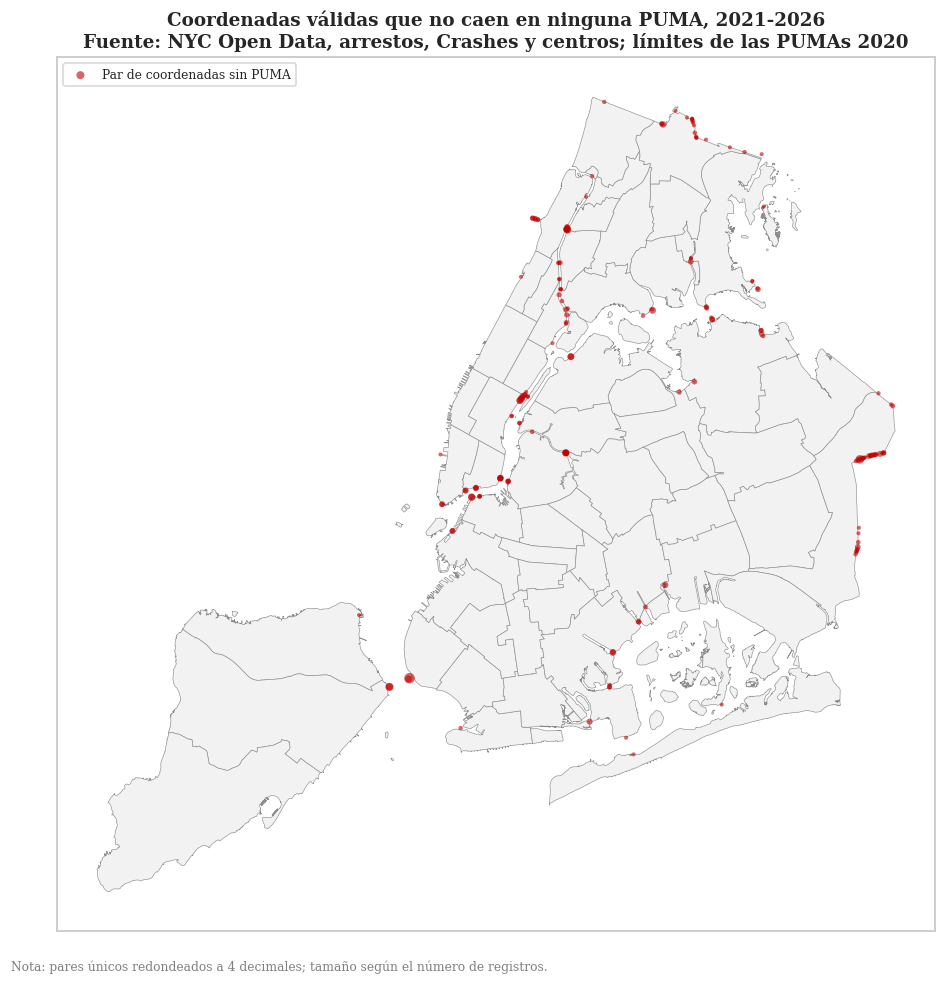

Pares sin PUMA: 176 | registros en esos pares: 1,657


In [40]:
pdf_sin_puma = tabla_puma.filter(F.col("PUMA").isNull()).toPandas()
fig, ax = plt.subplots(figsize=(9, 9))
dibujar_pumas(ax, pumas_geo)
if len(pdf_sin_puma):
    ax.scatter(pdf_sin_puma["LON_E"] / 10 ** DEC_PUMA, pdf_sin_puma["LAT_E"] / 10 ** DEC_PUMA,
               s=4 + 3 * np.sqrt(pdf_sin_puma["REGISTROS"]), color="#c00000", alpha=0.6, edgecolor="none",
               label="Par de coordenadas sin PUMA")
    ax.legend(loc="upper left", fontsize=8)
ax.set_title(f"Coordenadas válidas que no caen en ninguna PUMA, 2021-2026\n"
             f"Fuente: NYC Open Data, arrestos, Crashes y centros; límites de las PUMAs 2020")
nota_figura(fig, f"Nota: pares únicos redondeados a {DEC_PUMA} decimales; tamaño según el número de registros.")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()
print(f"Pares sin PUMA: {len(pdf_sin_puma):,} | registros en esos pares: {int(pdf_sin_puma['REGISTROS'].sum()):,}")

**Análisis:** Los 176 pares sin PUMA suman 1,657 registros y casi todos están en los bordes de la ciudad: sobre el límite con el condado de Nassau al este de Queens, sobre el límite con Westchester al norte del Bronx, en puentes como el Verrazzano y los del East River y en muelles de la costa. Son puntos justo afuera de la ciudad o sobre el agua, no errores de la asignación. Como son tan pocos, no cambian las tasas por PUMA.

**Margen de error de la asignación en los bordes.** Redondear a 4 decimales mueve cada punto como máximo 0.00005 grados: cerca de 5.6 metros en latitud y 4.2 metros en longitud a la latitud de Nueva York. Con 3 decimales el movimiento máximo sube a cerca de 56 y 42 metros. Un punto que está a menos de esa distancia de un borde puede quedar en la PUMA vecina; como los bordes de las PUMAs suelen ir por calles, los choques sobre la calle del borde son los más expuestos. Los puntos sin PUMA son de dos tipos: coordenadas en agua, puentes o muelles que quedan fuera de los polígonos, y puntos que, por el redondeo, quedaron justo afuera de la costa. Un punto exactamente sobre un borde lo decide `contains_points` y puede quedar en cualquiera de las dos PUMAs. La concordancia de distrito de la tabla anterior es una cota del error: un desacuerdo puede venir del borde o de un distrito mal registrado.

Para los parques el criterio es otro: cada parque se ubica con su punto representativo, el promedio de los vértices del anillo exterior de su polígono más grande. Los parques grandes que cruzan varias PUMAs quedan completos en una sola, y en parques con formas muy irregulares el promedio puede caer fuera del propio parque.

### 4.10 Población de referencia: PUMS 2024 por distrito y por PUMA

Todas las tasas usan la población de PUMS 2024, ponderada con `PWGTP`. En una sola agregación por PUMA se suman los pesos de la población y de cada grupo que se usa en las tasas sociales; como los pesos se pueden sumar, los distritos y la ciudad salen de sumar las PUMAs, sin otra consulta al clúster. Los vacíos de `POVPIP`, `SCHL` y `ESR` son no aplica: salen del denominador de su tasa.

In [41]:
peso = F.col("PWGTP")
AGREGADOS_PUMS = [
    F.count("*").alias("PERSONAS_MUESTRA"),
    F.sum(peso).alias("POBLACION"),
    F.sum(F.when(F.col("POVPIP").isNotNull(), peso).otherwise(0)).alias("POB_UNIVERSO_POBREZA"),
    F.sum(F.when(F.col("POVPIP") < 100, peso).otherwise(0)).alias("POB_POBRE"),
    F.sum(F.when(F.col("POVPIP").between(100, 149), peso).otherwise(0)).alias("POB_CERCA_POBREZA"),
    # Fuerza laboral civil: ESR 1, 2 y 3; desempleado: ESR 3
    F.sum(F.when(F.col("ESR").isin(1, 2, 3), peso).otherwise(0)).alias("POB_FUERZA_LABORAL"),
    F.sum(F.when(F.col("ESR") == 3, peso).otherwise(0)).alias("POB_DESEMPLEADA"),
    F.sum(F.when(F.col("ESR").isin(1, 2, 3) & F.col("AGEP").between(16, 24), peso).otherwise(0)).alias("POB_FUERZA_LABORAL_16_24"),
    F.sum(F.when((F.col("ESR") == 3) & F.col("AGEP").between(16, 24), peso).otherwise(0)).alias("POB_DESEMPLEADA_16_24"),
    F.sum(F.when((F.col("AGEP") >= 25) & F.col("SCHL").isNotNull(), peso).otherwise(0)).alias("POB_25_MAS"),
    F.sum(F.when((F.col("AGEP") >= 25) & F.col("SCHL").between(1, 15), peso).otherwise(0)).alias("POB_SIN_BACHILLERATO"),
    F.sum(F.when((F.col("AGEP") >= 25) & F.col("SCHL").between(21, 24), peso).otherwise(0)).alias("POB_UNIVERSITARIA"),
    F.sum(F.when(F.col("AGEP").between(15, 24), peso).otherwise(0)).alias("POB_15_24"),
]
pdf_pums_puma = df_pums_base.groupBy("PUMA", "DISTRITO").agg(*AGREGADOS_PUMS).toPandas()

# tasas_pums: recibe una tabla con sumas de pesos y devuelve una copia con las tasas en porcentaje
def tasas_pums(pdf):
    pdf = pdf.copy()
    pares = {"POBREZA_PCT": ("POB_POBRE", "POB_UNIVERSO_POBREZA"),
             "CERCA_POBREZA_PCT": ("POB_CERCA_POBREZA", "POB_UNIVERSO_POBREZA"),
             "DESEMPLEO_PCT": ("POB_DESEMPLEADA", "POB_FUERZA_LABORAL"),
             "DESEMPLEO_16_24_PCT": ("POB_DESEMPLEADA_16_24", "POB_FUERZA_LABORAL_16_24"),
             "SIN_BACHILLERATO_PCT": ("POB_SIN_BACHILLERATO", "POB_25_MAS"),
             "UNIVERSITARIA_PCT": ("POB_UNIVERSITARIA", "POB_25_MAS"),
             "JOVENES_15_24_PCT": ("POB_15_24", "POBLACION")}
    for tasa, (numerador, denominador) in pares.items():
        pdf[tasa] = np.where(pdf[denominador] > 0, pdf[numerador] / pdf[denominador] * 100, np.nan)
    return pdf

COLUMNAS_SUMA = [c for c in pdf_pums_puma.columns if c not in ("PUMA", "DISTRITO")]
pdf_pums_puma = tasas_pums(pdf_pums_puma).sort_values("PUMA").reset_index(drop=True)
pdf_pums_distrito = ordenar_distritos(tasas_pums(
    pdf_pums_puma.groupby("DISTRITO")[COLUMNAS_SUMA].sum().reset_index()))
pdf_pums_ciudad = tasas_pums(pd.DataFrame([{"DISTRITO": "CIUDAD", **pdf_pums_puma[COLUMNAS_SUMA].sum().to_dict()}]))
pdf_pums_distrito["PUMAS"] = pdf_pums_distrito["DISTRITO"].map(pdf_pums_puma.groupby("DISTRITO")["PUMA"].nunique())
pdf_pums_ciudad["PUMAS"] = pdf_pums_puma["PUMA"].nunique()

# Diccionarios de población para las tasas por habitante
POB_DISTRITO = dict(zip(pdf_pums_distrito["DISTRITO"], pdf_pums_distrito["POBLACION"]))
POB_PUMA = dict(zip(pdf_pums_puma["PUMA"], pdf_pums_puma["POBLACION"]))
POB_CIUDAD = float(pdf_pums_ciudad["POBLACION"].iloc[0])

mostrar_tabla(pd.concat([pdf_pums_distrito, pdf_pums_ciudad], ignore_index=True)
              [["DISTRITO", "PUMAS", "PERSONAS_MUESTRA", "POBLACION"]]
              .assign(DISTRITO=lambda d: d["DISTRITO"].map(nombre_boro))
              .rename(columns={"DISTRITO": "Distrito", "PUMAS": "PUMAs", "PERSONAS_MUESTRA": "Personas en la muestra",
                               "POBLACION": "Población ponderada"}),
              titulo="Población de referencia para las tasas, ACS PUMS 2024")
print(f"PUMAs con población: {len(POB_PUMA)} | población mínima y máxima por PUMA: "
      f"{min(POB_PUMA.values()):,.0f} y {max(POB_PUMA.values()):,.0f}")

Distrito,PUMAs,Personas en la muestra,Población ponderada
Bronx,10,"9,456","1,385,638"
Brooklyn,18,"22,626","2,618,069"
Manhattan,10,"10,215","1,659,873"
Queens,14,"20,830","2,316,416"
Staten Island,3,"4,384","498,242"
Ciudad,55,"67,511","8,478,238"


PUMAs con población: 55 | población mínima y máxima por PUMA: 93,258 y 265,789


**Análisis:** PUMS 2024 estima 8,478,238 habitantes en la ciudad a partir de 67,511 personas de la muestra. Brooklyn es el distrito más poblado, con 2,618,069 habitantes y 18 PUMAs, y Staten Island el menos poblado, con 498,242 y 3 PUMAs. Las PUMAs van de 93,258 a 265,789 habitantes, así que tienen tamaños parecidos y sus tasas se pueden comparar. Estas poblaciones son el denominador de todas las tasas del notebook.

## 5. Exploración de los datos: arrestos

Las secciones 5, 6 y 7 forman el numeral 4 del enunciado. Todas las agregaciones se hacen en Spark y al Driver solo llegan tablas ya agregadas. Las tasas usan la población de PUMS 2024. Manhattan tiene mucha población flotante que no vive allí, así que su tasa de arrestos por residente queda inflada frente a los demás distritos.

### 5.1 Territorio: arrestos por distrito y por PUMA

Se cuentan los arrestos de cada distrito y año, y se calcula la tasa de 2025, el año completo más reciente, por cada 100,000 habitantes. 2026 es un año parcial.

In [42]:
pdf_arr_dist_anio = (df_arrestos
    .groupBy("ANIO", F.coalesce(F.col("DISTRITO"), F.lit("NO ESPECIFICADO")).alias("DISTRITO"))
    .agg(F.count("*").alias("ARRESTOS")).toPandas())
tabla_arr = pdf_arr_dist_anio.pivot(index="DISTRITO", columns="ANIO", values="ARRESTOS").fillna(0)
tabla_arr.columns = [str(c) for c in tabla_arr.columns]
tabla_arr = tabla_arr.reindex([d for d in ORDEN_BORO + ["NO ESPECIFICADO"] if d in tabla_arr.index])
tabla_arr.loc["CIUDAD"] = tabla_arr.sum()
poblaciones = [POB_CIUDAD if d == "CIUDAD" else POB_DISTRITO.get(d, np.nan) for d in tabla_arr.index]
tabla_arr[f"Tasa {ANIO_COMPLETO} por 100,000 hab."] = tabla_arr[str(ANIO_COMPLETO)] / np.array(poblaciones) * 100000
tabla_arr = tabla_arr.reset_index().rename(columns={"DISTRITO": "Distrito", str(ANIO_FIN): f"{ANIO_FIN} parcial"})
tabla_arr["Distrito"] = tabla_arr["Distrito"].map(nombre_boro)
mostrar_tabla(tabla_arr, titulo="Arrestos por distrito y año, 2021-2026, y tasa de 2025. Fuente: NYPD Arrests Data",
              decimales=1)

Distrito,2021,2022,2023,2024,2025,2026 parcial,"Tasa 2025 por 100,000 hab."
Bronx,"34,018","44,084","53,258","58,521","62,833","32,682","4,534.6"
Brooklyn,"41,550","50,961","62,395","72,325","79,882","42,877","3,051.2"
Manhattan,"39,677","46,807","52,891","61,969","66,448","32,089","4,003.2"
Queens,"33,051","39,547","48,310","56,633","58,083","29,053","2,507.5"
Staten Island,"7,211","8,375","10,018","11,055","11,707","5,169","2,349.7"
Ciudad,"155,507","189,774","226,872","260,503","278,953","141,870","3,290.2"


**Análisis:** Los arrestos de la ciudad crecieron 79.4% entre 2021 y 2025, de 155,507 a 278,953, y crecieron todos los años en los cinco distritos. Brooklyn es el que más creció, 92.3%, y el que más arrestos tiene en número. En tasa, el Bronx es el más alto, con 4,534.6 arrestos por cada 100,000 habitantes, seguido de Manhattan con 4,003.2; Queens y Staten Island están por debajo de la ciudad, que tiene 3,290.2. La tasa de Manhattan está inflada por la gente que trabaja o visita el distrito pero no vive allí.

La figura tiene dos paneles. El primero es un mapa de densidad hexagonal de los arrestos de 2025: en Spark se agrupan por coordenada redondeada a 3 decimales y matplotlib suma los conteos dentro de cada hexágono, así no se traen los arrestos uno por uno. El segundo muestra la tasa de arrestos de 2025 de cada PUMA dentro de su distrito: cada punto es una PUMA.

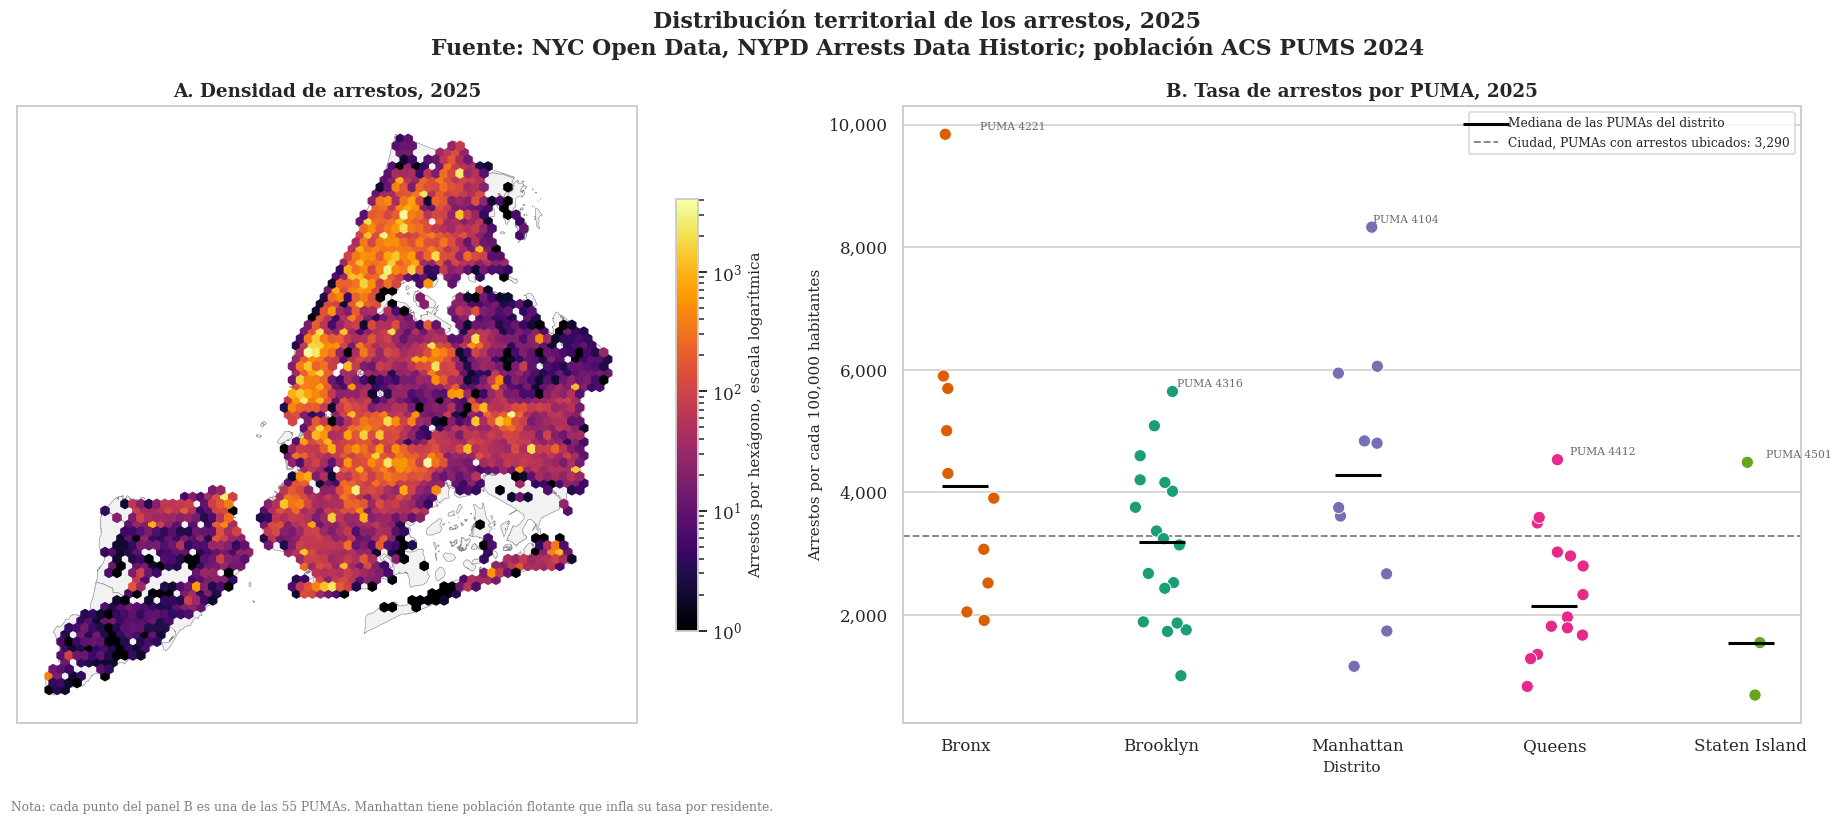

In [43]:
pdf_hex_arr = (df_arrestos.filter((F.col("ANIO") == ANIO_COMPLETO) & F.col("COORD_VALIDA"))
               .groupBy(F.round("LATITUDE", 3).alias("LAT"), F.round("LONGITUDE", 3).alias("LON"))
               .agg(F.count("*").alias("N")).toPandas())
pdf_arr_puma = (df_arrestos.filter((F.col("ANIO") == ANIO_COMPLETO) & F.col("PUMA").isNotNull())
                .groupBy("PUMA").agg(F.count("*").alias("ARRESTOS")).toPandas())
# Se parte de las 55 PUMAs de PUMS para que una PUMA sin arrestos quede con cero y no desaparezca
pdf_arr_puma = (pdf_pums_puma[["PUMA", "DISTRITO", "POBLACION"]].merge(pdf_arr_puma, on="PUMA", how="left")
                .fillna({"ARRESTOS": 0}))
pdf_arr_puma["TASA_100K"] = pdf_arr_puma["ARRESTOS"] / pdf_arr_puma["POBLACION"] * 100000

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
dibujar_pumas(ax, pumas_geo)
# C y reduce_C_function suman los conteos de cada coordenada dentro del hexágono
hb = ax.hexbin(pdf_hex_arr["LON"], pdf_hex_arr["LAT"], C=pdf_hex_arr["N"], reduce_C_function=np.sum,
               gridsize=70, bins="log", cmap="inferno", mincnt=1)
fig.colorbar(hb, ax=ax, shrink=0.7).set_label("Arrestos por hexágono, escala logarítmica")
ax.set_title(f"A. Densidad de arrestos, {ANIO_COMPLETO}")

ax = axes[1]
sns.stripplot(data=pdf_arr_puma, x="DISTRITO", y="TASA_100K", order=ORDEN_BORO, hue="DISTRITO",
              hue_order=ORDEN_BORO, palette=PALETA_BORO, size=8, jitter=0.15, edgecolor="white",
              linewidth=0.6, legend=False, ax=ax)
medianas = pdf_arr_puma.groupby("DISTRITO")["TASA_100K"].median().reindex(ORDEN_BORO)
ax.scatter(range(len(ORDEN_BORO)), medianas.values, marker="_", s=900, color="black", lw=2, zorder=3,
           label="Mediana de las PUMAs del distrito")
tasa_ciudad_arr = pdf_arr_puma["ARRESTOS"].sum() / pdf_arr_puma["POBLACION"].sum() * 100000
ax.axhline(tasa_ciudad_arr, color="gray", linestyle="--", lw=1.2, label=f"Ciudad, PUMAs con arrestos ubicados: {tasa_ciudad_arr:,.0f}")
# Se etiqueta la PUMA con la tasa más alta de cada distrito
for i, distrito in enumerate(ORDEN_BORO):
    fila = pdf_arr_puma[pdf_arr_puma["DISTRITO"] == distrito].nlargest(1, "TASA_100K")
    if len(fila):
        ax.annotate(f"PUMA {int(fila['PUMA'].iloc[0])}", (i, fila["TASA_100K"].iloc[0]), xytext=(10, 3),
                    textcoords="offset points", fontsize=7, color="dimgray")
ax.set_xticks(range(len(ORDEN_BORO)))
ax.set_xticklabels([nombre_boro(d) for d in ORDEN_BORO])
ax.set(xlabel="Distrito", ylabel="Arrestos por cada 100,000 habitantes", title=f"B. Tasa de arrestos por PUMA, {ANIO_COMPLETO}")
formato_miles(ax.yaxis)
ax.legend(loc="upper right", fontsize=8)
fig.suptitle(f"Distribución territorial de los arrestos, {ANIO_COMPLETO}\nFuente: NYC Open Data, NYPD Arrests Data Historic; población ACS PUMS 2024",
             fontweight="bold")
nota_figura(fig, "Nota: cada punto del panel B es una de las 55 PUMAs. Manhattan tiene población flotante que infla su tasa por residente.")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Análisis:** El mapa de densidad muestra que los arrestos se concentran en focos: el sur del Bronx, el norte y el centro de Manhattan y el centro y el este de Brooklyn. Dentro de cada distrito las PUMAs son muy distintas: la tasa va de 690 a 9,841 arrestos por cada 100,000 habitantes, más de 14 veces. La PUMA 4221 del Bronx tiene la tasa más alta de la ciudad, con cerca de 9,841, más del doble de la mediana del Bronx, seguida de la PUMA 4104 de Manhattan, con cerca de 8,300. Esto confirma que el plan de acción debe focalizarse por PUMA y no por distrito.

### 5.2 Delitos: diagrama de Pareto de 2025

Se ordenan los delitos de 2025 de mayor a menor y se acumula su peso, para ver cuántos tipos de delito explican el 80% de los arrestos. Primero va la tabla y después el diagrama.

In [44]:
pdf_pareto = (df_arrestos.filter((F.col("ANIO") == ANIO_COMPLETO) & (F.col("OFNS_DESC_CLEAN") != "NO ESPECIFICADO"))
              .groupBy("OFNS_DESC_CLEAN").agg(F.count("*").alias("ARRESTOS"))
              .orderBy(F.desc("ARRESTOS")).toPandas())
pdf_pareto["PCT"] = pdf_pareto["ARRESTOS"] / pdf_pareto["ARRESTOS"].sum() * 100
# cumsum da el porcentaje acumulado, que es la línea del Pareto
pdf_pareto["PCT_ACUM"] = pdf_pareto["PCT"].cumsum()
n_80 = int((pdf_pareto["PCT_ACUM"] < 80).sum() + 1)
mostrar_tabla(pdf_pareto.head(15).rename(columns={"OFNS_DESC_CLEAN": "Delito", "ARRESTOS": "Arrestos",
                                                  "PCT": "Arrestos %", "PCT_ACUM": "Acumulado %"}),
              titulo=f"Los 15 delitos con más arrestos en {ANIO_COMPLETO}", decimales=2,
              pct=["Arrestos %", "Acumulado %"])
print(f"Categorías de delito distintas: {len(pdf_pareto)} | categorías que explican el 80% de los arrestos: {n_80}")

Delito,Arrestos,Arrestos %,Acumulado %
ASSAULT 3 & RELATED OFFENSES,"39,728",14.24%,14.24%
PETIT LARCENY,"27,698",9.93%,24.17%
FELONY ASSAULT,"22,964",8.23%,32.41%
DANGEROUS DRUGS,"22,379",8.02%,40.43%
MISCELLANEOUS PENAL LAW,"18,430",6.61%,47.04%
OTHER OFFENSES RELATED TO THEFT,"15,780",5.66%,52.69%
VEHICLE AND TRAFFIC LAWS,"15,299",5.48%,58.18%
CRIMINAL MISCHIEF & RELATED OF,"12,050",4.32%,62.50%
ROBBERY,"11,184",4.01%,66.51%
DANGEROUS WEAPONS,"10,584",3.79%,70.30%


Categorías de delito distintas: 62 | categorías que explican el 80% de los arrestos: 13


**Análisis:** Los arrestos se concentran en pocos tipos de delito: 13 de las 62 categorías explican el 80.43% de los arrestos de 2025. La más común es Assault 3 & Related Offenses, una agresión menor, con el 14.24%, seguida de Petit Larceny, robo menor, con el 9.93%, y Felony Assault, agresión grave, con el 8.23%. Vehicle and Traffic Laws, con el 5.48%, conecta los arrestos con la seguridad vial.

El diagrama de Pareto pinta de color oscuro las categorías que forman el 80% de los arrestos y dibuja el porcentaje acumulado en el eje derecho.

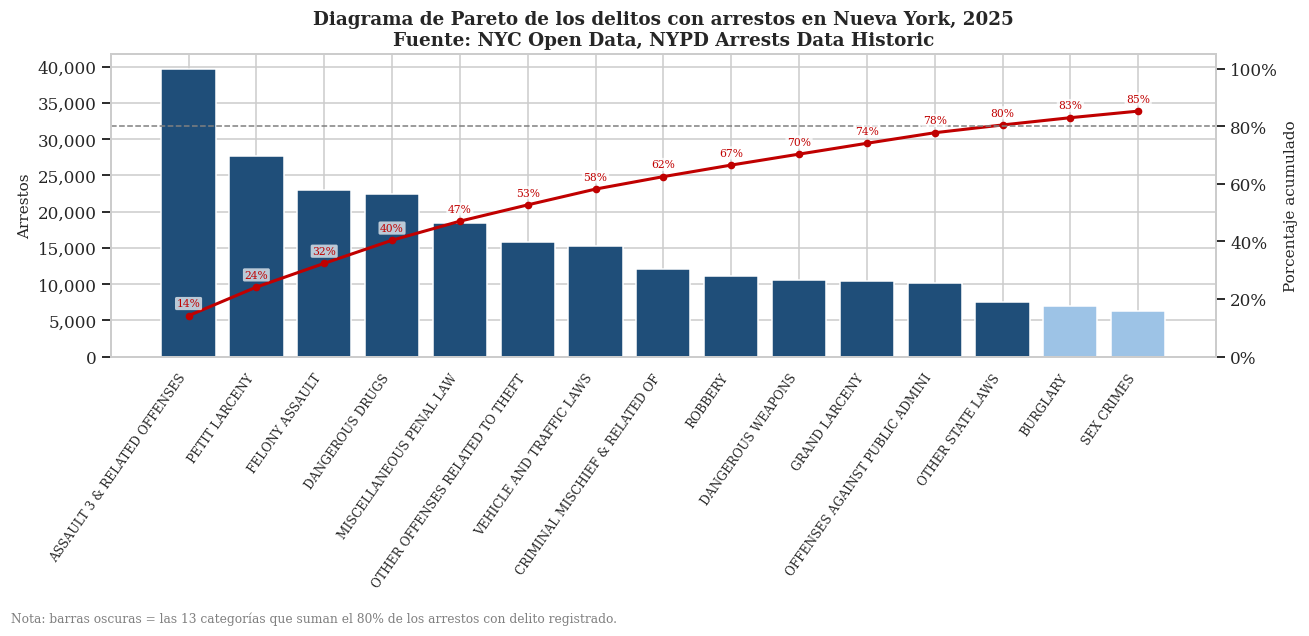

In [45]:
top_n = min(max(15, n_80), len(pdf_pareto))
pdf_plot = pdf_pareto.head(top_n).copy()
x = np.arange(len(pdf_plot))
fig, ax1 = plt.subplots(figsize=(12, 5.8))
ax1.bar(x, pdf_plot["ARRESTOS"], color=["#1f4e79" if i < n_80 else "#9dc3e6" for i in range(len(pdf_plot))])
ax1.set_xticks(x)
ax1.set_xticklabels(pdf_plot["OFNS_DESC_CLEAN"].str.slice(0, 32), rotation=55, ha="right", fontsize=8)
ax1.set_ylabel("Arrestos")
formato_miles(ax1.yaxis)
# Eje secundario para el porcentaje acumulado
ax2 = ax1.twinx()
ax2.plot(x, pdf_plot["PCT_ACUM"], color="#c00000", marker="o", lw=2, ms=4)
ax2.axhline(80, color="gray", ls="--", lw=1)
ax2.set_ylim(0, 105)
ax2.set_ylabel("Porcentaje acumulado")
ax2.yaxis.set_major_formatter(PercentFormatter())
ax2.grid(False)
for xi, v in zip(x, pdf_plot["PCT_ACUM"]):
    ax2.annotate(f"{v:.0f}%", (xi, v), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7,
                 color="#c00000", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))
ax1.set_title(f"Diagrama de Pareto de los delitos con arrestos en Nueva York, {ANIO_COMPLETO}\n"
              "Fuente: NYC Open Data, NYPD Arrests Data Historic")
nota_figura(fig, f"Nota: barras oscuras = las {n_80} categorías que suman el 80% de los arrestos con delito registrado.")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Análisis:** La gráfica muestra que la curva acumulada sube rápido al inicio: las cuatro primeras categorías ya suman el 40.43% de los arrestos. Desde la quinta, cada categoría agrega menos de 7 puntos. Para el plan de acción esto significa que unas pocas estrategias, sobre agresiones, robos y drogas, cubren la mayor parte de los arrestos.

### 5.3 Severidad del delito por edad y sexo

En 2025 faltan la edad y el sexo en cerca de la mitad de los arrestos, así que los perfiles usan 2021-2024 y 2026. Se cuenta en Spark una sola tabla por año, grupo de edad, sexo y nivel del delito, y las matrices se arman en pandas. Los registros con edad o sexo "NO ESPECIFICADO" se reportan y salen del perfil.

In [46]:
ANIOS_PERFIL = [2021, 2022, 2023, 2024, 2026]
COLS_SEV = {"F": "Felony %", "M": "Misdemeanor %", "V": "Violation %"}
pdf_sev = (df_arrestos.filter(F.col("ANIO").isin(ANIOS_PERFIL) & F.col("LAW_CAT_CD_CLEAN").isin("F", "M", "V"))
           .groupBy("ANIO", "AGE_GROUP_CLEAN", "PERP_SEX_CLEAN", "LAW_CAT_CD_CLEAN")
           .agg(F.count("*").alias("ARRESTOS")).toPandas())

# composicion: recibe la tabla, la columna del grupo y los valores válidos; devuelve una tabla con el
# total de arrestos y el porcentaje de cada nivel del delito dentro de cada grupo
def composicion(pdf, columna, valores):
    sub = pdf[pdf[columna].isin(valores)]
    tabla = sub.pivot_table(index=columna, columns="LAW_CAT_CD_CLEAN", values="ARRESTOS", aggfunc="sum").fillna(0)
    tabla = tabla.reindex(index=valores, columns=list(COLS_SEV)).fillna(0)
    total = tabla.sum(axis=1)
    salida = (tabla.div(total, axis=0) * 100).rename(columns=COLS_SEV)
    salida.insert(0, "Arrestos", total)
    return salida

tabla_edad = composicion(pdf_sev, "AGE_GROUP_CLEAN", ORDEN_EDAD)
tabla_sexo = composicion(pdf_sev, "PERP_SEX_CLEAN", ["M", "F"]).rename(index={"M": "Masculino", "F": "Femenino"})
tabla_perfil = pd.concat([tabla_edad.rename(index=lambda g: f"Edad {g}"), tabla_sexo.rename(index=lambda g: f"Sexo {g}")])
mostrar_tabla(tabla_perfil.reset_index().rename(columns={"index": "Grupo"}),
              titulo="Composición del nivel del delito por grupo de edad y sexo, 2021-2024 y 2026", decimales=1,
              pct=list(COLS_SEV.values()))
excluidos = (pdf_sev[~pdf_sev["AGE_GROUP_CLEAN"].isin(ORDEN_EDAD)].groupby("ANIO")["ARRESTOS"].sum()
             .reindex(ANIOS_PERFIL).fillna(0).astype(int))
print("Arrestos sin grupo de edad válido por año, excluidos del perfil de edad:", excluidos.to_dict())

Grupo,Arrestos,Felony %,Misdemeanor %,Violation %
Edad <18,"35,141",69.2%,30.8%,0.0%
Edad 18-24,"164,450",47.1%,52.4%,0.5%
Edad 25-44,"555,630",42.2%,57.0%,0.8%
Edad 45-64,"192,430",39.8%,59.4%,0.8%
Edad 65+,"16,599",38.5%,61.1%,0.4%
Sexo Masculino,"788,954",44.6%,54.6%,0.7%
Sexo Femenino,"171,815",38.5%,61.1%,0.4%


Arrestos sin grupo de edad válido por año, excluidos del perfil de edad: {2021: 0, 2022: 0, 2023: 0, 2024: 0, 2026: 0}


**Análisis:** La severidad baja con la edad. En los menores de 18 años el 69.2% de los arrestos es por felony, un delito grave, mientras que de los 25 años en adelante el delito menor, misdemeanor, es la mayoría, por encima del 57%. Los hombres son el 82.1% de los arrestos con sexo registrado y tienen más felony que las mujeres, 44.6% frente a 38.5%. Las violaciones, violation, son menos del 1% en todos los grupos. Este perfil usa 2021-2024 y 2026, porque 2025 no tiene edad ni sexo en la mitad de los registros.

El mapa de calor de la izquierda muestra, por grupo de edad y año, qué porcentaje de los arrestos es por delito grave, felony. El de la derecha muestra la composición del nivel del delito en hombres y mujeres. Los colores van de 0 a 100 en los dos paneles para poder compararlos.

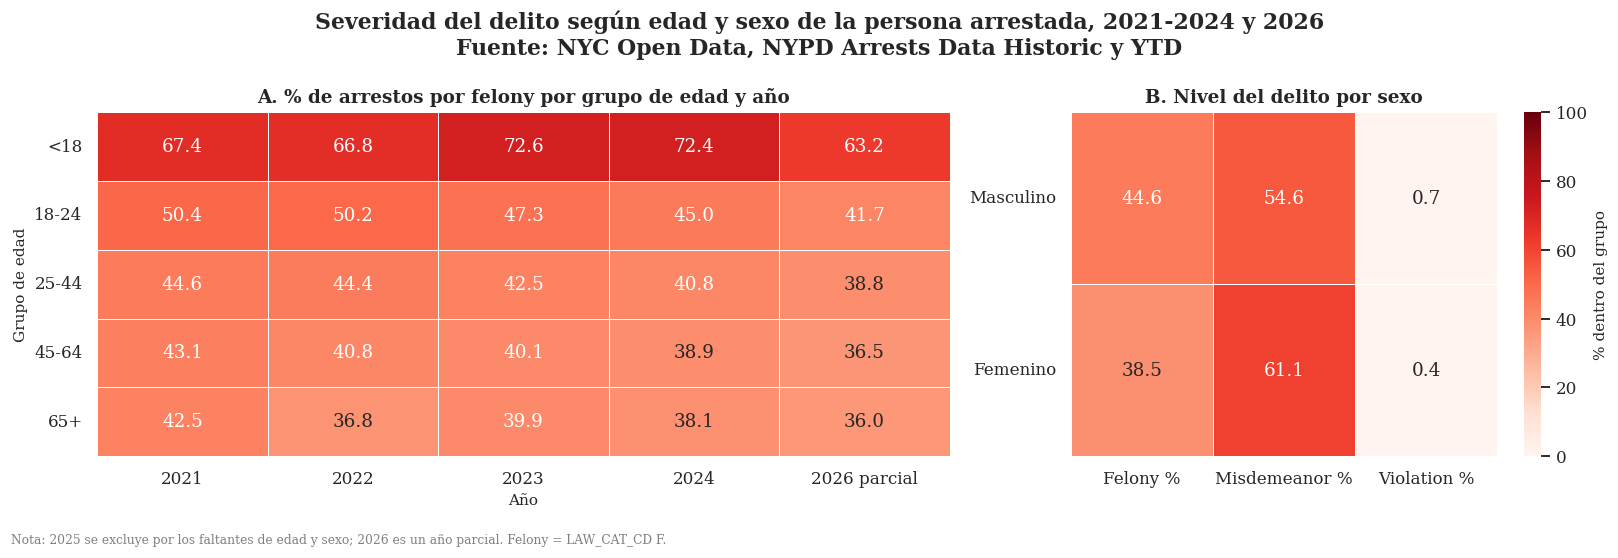

In [47]:
sub = pdf_sev[pdf_sev["AGE_GROUP_CLEAN"].isin(ORDEN_EDAD)]
total_edad_anio = sub.groupby(["AGE_GROUP_CLEAN", "ANIO"])["ARRESTOS"].sum()
felony_edad_anio = sub[sub["LAW_CAT_CD_CLEAN"] == "F"].groupby(["AGE_GROUP_CLEAN", "ANIO"])["ARRESTOS"].sum()
matriz_felony = ((felony_edad_anio / total_edad_anio * 100).unstack("ANIO")
                 .reindex(index=ORDEN_EDAD, columns=ANIOS_PERFIL))
matriz_felony.columns = [f"{a} parcial" if a == ANIO_FIN else str(a) for a in matriz_felony.columns]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(matriz_felony, ax=axes[0], cmap="Reds", vmin=0, vmax=100, annot=True, fmt=".1f",
            linewidths=0.6, linecolor="white", cbar=False)
axes[0].set(title="A. % de arrestos por felony por grupo de edad y año", xlabel="Año", ylabel="Grupo de edad")
axes[0].tick_params(axis="y", rotation=0)
sns.heatmap(tabla_sexo[list(COLS_SEV.values())], ax=axes[1], cmap="Reds", vmin=0, vmax=100, annot=True, fmt=".1f",
            linewidths=0.6, linecolor="white", cbar_kws={"label": "% dentro del grupo"})
axes[1].set(title="B. Nivel del delito por sexo", xlabel="", ylabel="")
axes[1].tick_params(axis="y", rotation=0)
fig.suptitle("Severidad del delito según edad y sexo de la persona arrestada, 2021-2024 y 2026\n"
             "Fuente: NYC Open Data, NYPD Arrests Data Historic y YTD", fontweight="bold")
nota_figura(fig, "Nota: 2025 se excluye por los faltantes de edad y sexo; 2026 es un año parcial. Felony = LAW_CAT_CD F.")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

**Análisis:** Los menores de 18 años tienen la mayor proporción de delito grave todos los años, con un máximo de 72.6% en 2023 y 72.4% en 2024, y bajan a 63.2% en lo que va de 2026. En los demás grupos de edad la proporción de felony tiende a bajar año tras año: en el grupo de 18 a 24 años pasa de 50.4% en 2021 a 41.7% en 2026. Como los arrestos totales crecieron, esto sugiere que el aumento vino sobre todo de delitos menores. La diferencia entre hombres y mujeres se mantiene en los dos paneles.

### 5.4 Tendencia 2021-2025

Se usan solo años completos. Para los 6 delitos con más arrestos en 2025 se calcula un índice base 100 en 2021: cada año se divide entre su valor de 2021, así se ve cuál creció más sin importar su tamaño.

In [48]:
top6 = pdf_pareto["OFNS_DESC_CLEAN"].head(6).tolist()
pdf_top6 = (df_arrestos.filter(F.col("ANIO").between(ANIO_INI, ANIO_COMPLETO) & F.col("OFNS_DESC_CLEAN").isin(top6))
            .groupBy("ANIO", "OFNS_DESC_CLEAN").agg(F.count("*").alias("ARRESTOS")).toPandas())
tabla_top6 = (pdf_top6.pivot(index="OFNS_DESC_CLEAN", columns="ANIO", values="ARRESTOS")
              .reindex(index=top6, columns=range(ANIO_INI, ANIO_COMPLETO + 1)))
indice_top6 = tabla_top6.div(tabla_top6[ANIO_INI], axis=0) * 100
salida_top6 = tabla_top6.copy()
salida_top6.columns = [str(c) for c in salida_top6.columns]
salida_top6[f"Índice {ANIO_COMPLETO}, {ANIO_INI} = 100"] = indice_top6[ANIO_COMPLETO]
mostrar_tabla(salida_top6.reset_index().rename(columns={"OFNS_DESC_CLEAN": "Delito"}),
              titulo=f"Arrestos por año de los 6 delitos con más arrestos en {ANIO_COMPLETO}", decimales=1)

Delito,2021,2022,2023,2024,2025,"Índice 2025, 2021 = 100"
ASSAULT 3 & RELATED OFFENSES,"26,855","30,687","33,839","38,238","39,728",147.9
PETIT LARCENY,"13,178","20,637","23,888","27,107","27,698",210.2
FELONY ASSAULT,"15,579","18,895","21,121","22,606","22,964",147.4
DANGEROUS DRUGS,"10,450","10,651","15,701","18,519","22,379",214.2
MISCELLANEOUS PENAL LAW,"10,328","12,523","14,862","16,541","18,430",178.4
OTHER OFFENSES RELATED TO THEFT,,,,"12,621","15,780",


**Análisis:** Los seis delitos principales crecieron entre 2021 y 2025, pero no al mismo ritmo. Dangerous Drugs, drogas, y Petit Larceny, robo menor, más que se duplicaron, con índices de 214.2 y 210.2. Las agresiones crecieron cerca de 48%, con índices de 147.9 y 147.4. Other Offenses Related to Theft solo tiene datos desde 2024, porque es una categoría nueva del registro, por eso no tiene índice.

La figura muestra a la izquierda los arrestos por año de cada distrito y a la derecha el índice de los 6 delitos principales, con la línea punteada en 100 como nivel de 2021.

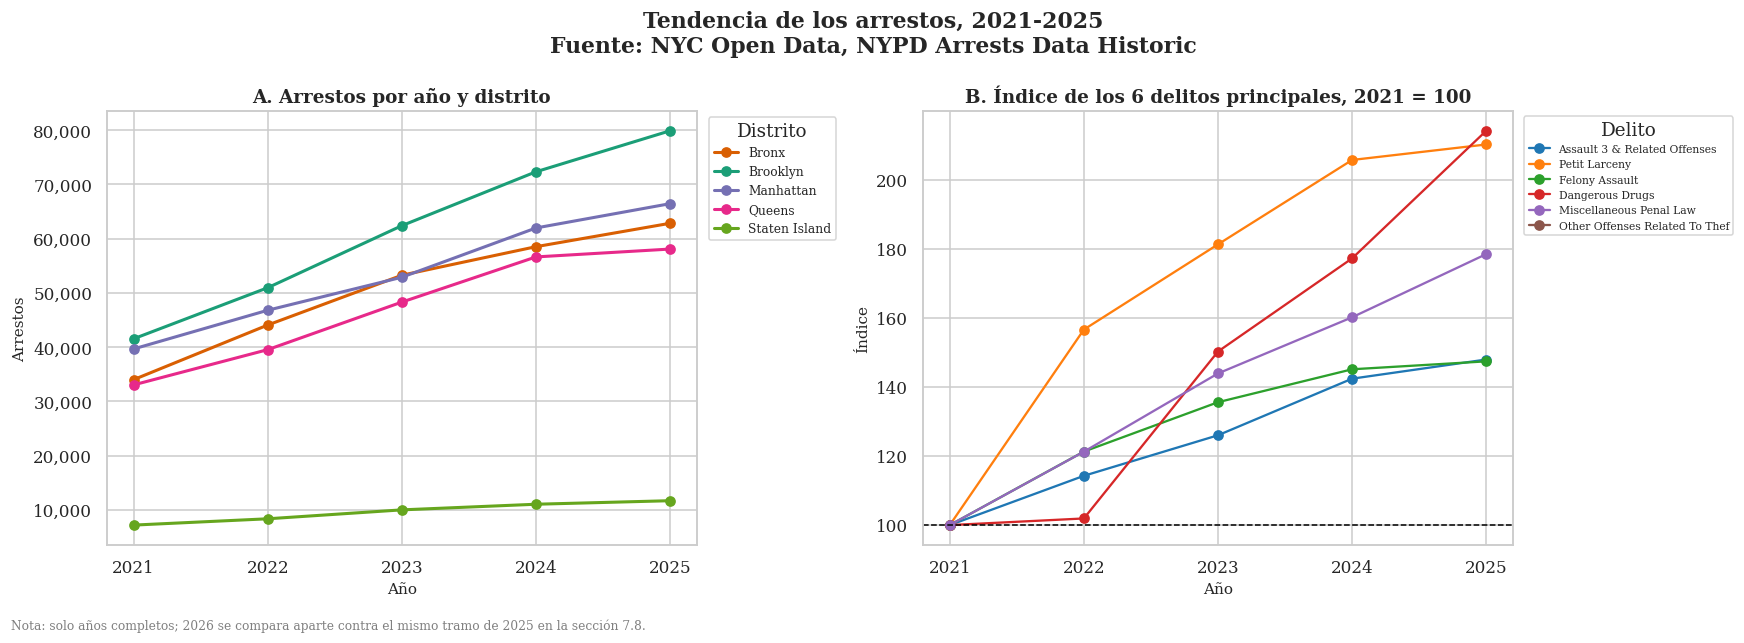

In [49]:
pdf_tend = pdf_arr_dist_anio[pdf_arr_dist_anio["ANIO"].between(ANIO_INI, ANIO_COMPLETO)
                             & pdf_arr_dist_anio["DISTRITO"].isin(ORDEN_BORO)].copy()
pdf_tend["Distrito"] = pdf_tend["DISTRITO"].map(nombre_boro)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
ax = axes[0]
for distrito in ORDEN_BORO:
    serie = pdf_tend[pdf_tend["DISTRITO"] == distrito].sort_values("ANIO")
    ax.plot(serie["ANIO"], serie["ARRESTOS"], marker="o", lw=2, color=PALETA_BORO[distrito], label=nombre_boro(distrito))
ax.set_xticks(range(ANIO_INI, ANIO_COMPLETO + 1))
ax.set(title="A. Arrestos por año y distrito", xlabel="Año", ylabel="Arrestos")
formato_miles(ax.yaxis)
ax.legend(title="Distrito", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax = axes[1]
colores_top6 = sns.color_palette("tab10", len(top6))
for delito, color in zip(top6, colores_top6):
    serie = indice_top6.loc[delito]
    ax.plot(serie.index, serie.values, marker="o", color=color, label=delito.title()[:30])
ax.axhline(100, color="black", linestyle="--", lw=1)
ax.set_xticks(range(ANIO_INI, ANIO_COMPLETO + 1))
ax.set(title=f"B. Índice de los 6 delitos principales, {ANIO_INI} = 100", xlabel="Año", ylabel="Índice")
ax.legend(title="Delito", fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle(f"Tendencia de los arrestos, {ANIO_INI}-{ANIO_COMPLETO}\nFuente: NYC Open Data, NYPD Arrests Data Historic",
             fontweight="bold")
nota_figura(fig, "Nota: solo años completos; 2026 se compara aparte contra el mismo tramo de 2025 en la sección 7.8.")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Análisis:** El panel A muestra que los arrestos crecen todos los años en los cinco distritos, con Brooklyn siempre arriba y Staten Island muy por debajo por su población. Manhattan y el Bronx tienen casi los mismos arrestos en 2023, y en 2025 Manhattan vuelve a quedar por encima en número. Queens casi se estabiliza entre 2024 y 2025, con un aumento de solo 2.6%. En el panel B, los arrestos por drogas están planos entre 2021 y 2022 y luego suben rápido, mientras que el robo menor tiene su mayor salto entre 2021 y 2022.

## 6. Exploración de los datos: choques, vehículos y personas

Todo el periodo 2021-2026 usa un único régimen de registro, así que los totales de choques sí se comparan entre años. Los análisis de años completos usan 2021-2025. Los muertos de 2026 no se comparan porque en 2026 una parte de los choques no trae ese dato. Las horas están en hora local de Nueva York.

### 6.1 Tipo de vehículo

Para cada una de las 8 categorías estandarizadas se cuentan los vehículos de 2021 a 2025, qué parte estuvo en choques con víctimas y con muertos, los ocupantes promedio después del tope y el año mediano del modelo. Se usa caché porque esta base se consulta en tres celdas seguidas.

In [50]:
df_veh_21_25 = df_vehiculos.filter(F.col("ANIO").between(ANIO_INI, ANIO_COMPLETO)).cache()
pdf_cat = (df_veh_21_25.groupBy("CATEGORIA_VEHICULO").agg(
        F.count("*").alias("VEHICULOS"),
        F.sum("CON_VICTIMAS").alias("EN_CHOQUES_CON_VICTIMAS"),
        F.sum("CON_MUERTOS").alias("EN_CHOQUES_CON_MUERTOS"),
        F.avg("OCUPANTES").alias("OCUPANTES_PROMEDIO"),
        F.expr("percentile_approx(ANIO_MODELO, 0.5)").alias("ANIO_MODELO_MEDIANO"))
    .toPandas().sort_values("VEHICULOS", ascending=False))
pdf_cat["VEHICULOS_PCT"] = pdf_cat["VEHICULOS"] / pdf_cat["VEHICULOS"].sum() * 100
pdf_cat["CON_VICTIMAS_PCT"] = pdf_cat["EN_CHOQUES_CON_VICTIMAS"] / pdf_cat["VEHICULOS"] * 100
pdf_cat["MUERTOS_POR_10K"] = pdf_cat["EN_CHOQUES_CON_MUERTOS"] / pdf_cat["VEHICULOS"] * 10000
mostrar_tabla(pdf_cat[["CATEGORIA_VEHICULO", "VEHICULOS", "VEHICULOS_PCT", "CON_VICTIMAS_PCT", "MUERTOS_POR_10K",
                       "OCUPANTES_PROMEDIO", "ANIO_MODELO_MEDIANO"]].rename(columns={
    "CATEGORIA_VEHICULO": "Categoría", "VEHICULOS": "Vehículos", "VEHICULOS_PCT": "Vehículos %",
    "CON_VICTIMAS_PCT": "En choques con víctimas %", "MUERTOS_POR_10K": "En choques con muertos por 10,000",
    "OCUPANTES_PROMEDIO": "Ocupantes promedio", "ANIO_MODELO_MEDIANO": "Año mediano del modelo"}),
    titulo="Vehículos en choques por categoría, 2021-2025", decimales=2,
    pct=["Vehículos %", "En choques con víctimas %"])

Categoría,Vehículos,Vehículos %,En choques con víctimas %,"En choques con muertos por 10,000",Ocupantes promedio,Año mediano del modelo
SEDAN,"386,449",39.21%,38.21%,16.38,1.03,2016
SUV / STATION WAGON,"291,521",29.57%,38.81%,23.09,1.06,2017
OTROS / NO ESPECIFICADO,"155,130",15.74%,24.48%,18.69,1.12,2018
CAMION / PICK-UP / VAN,"57,821",5.87%,30.54%,37.01,1.04,2017
BICICLETA / E-BIKE,"39,305",3.99%,83.30%,47.07,0.97,2021
TAXI,"20,715",2.10%,49.75%,18.34,1.20,2018
AUTOBUS,"17,597",1.79%,29.68%,28.98,2.79,2015
MOTO / SCOOTER,"17,164",1.74%,76.92%,123.51,0.96,2020


**Análisis:** Sedanes y SUV son el 68.78% de los vehículos en choques, pero los vehículos más peligrosos son los de dos ruedas. Las motos y scooters son solo el 1.74% de los vehículos, pero aparecen en 123.51 choques con muertos por cada 10,000, 7.5 veces más que los sedanes, y el 76.92% de sus choques deja víctimas. Las bicicletas y e-bikes tienen el 83.30% de sus choques con víctimas y 47.07 con muertos por cada 10,000. Los camiones también tienen una letalidad alta, con 37.01, por su tamaño. Los autobuses tienen en promedio 2.79 ocupantes, el valor más alto, lo que confirma que el tope de ocupantes funcionó.

El mapa de calor muestra la composición del tipo de vehículo en cada distrito: cada fila suma 100%. El distrito del vehículo es el de su choque.

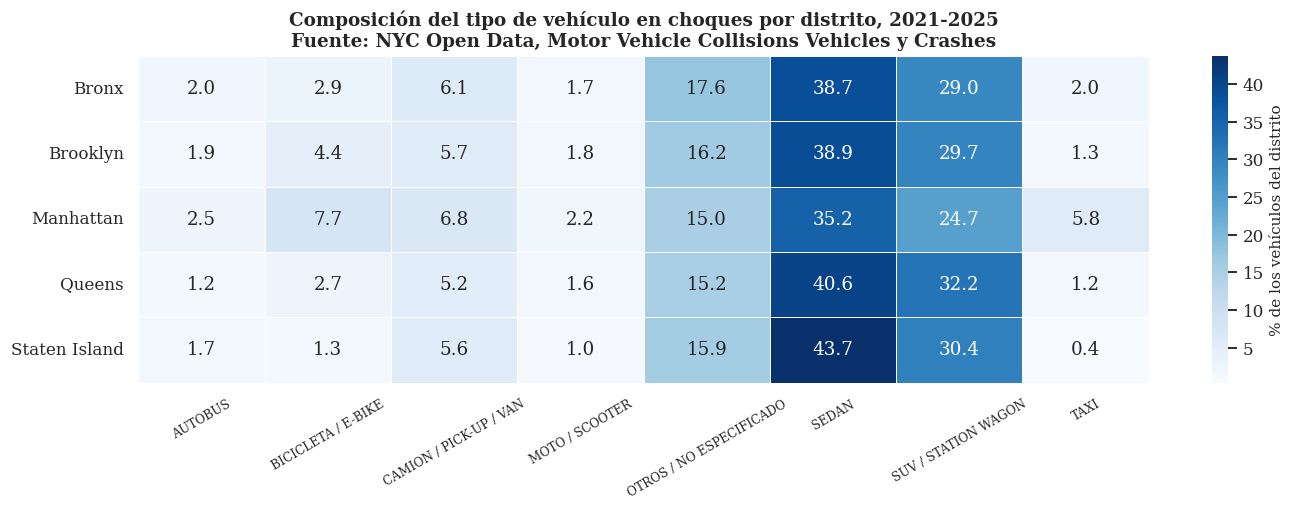

In [51]:
pdf_cat_dist = (df_veh_21_25.filter(F.col("DISTRITO").isNotNull())
                .groupBy("DISTRITO", "CATEGORIA_VEHICULO").agg(F.count("*").alias("VEHICULOS")).toPandas()
                .pivot(index="DISTRITO", columns="CATEGORIA_VEHICULO", values="VEHICULOS").fillna(0)
                .reindex(ORDEN_BORO))
pdf_cat_dist = pdf_cat_dist.div(pdf_cat_dist.sum(axis=1), axis=0) * 100
pdf_cat_dist.index = [nombre_boro(d) for d in pdf_cat_dist.index]
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.heatmap(pdf_cat_dist, annot=True, fmt=".1f", cmap="Blues", linewidths=0.6, linecolor="white",
            cbar_kws={"label": "% de los vehículos del distrito"}, ax=ax)
ax.set(xlabel="", ylabel="", title="Composición del tipo de vehículo en choques por distrito, 2021-2025\n"
                                    "Fuente: NYC Open Data, Motor Vehicle Collisions Vehicles y Crashes")
ax.tick_params(axis="x", rotation=30, labelsize=8)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

**Análisis:** La composición de los vehículos cambia poco entre distritos, excepto en Manhattan. Allí sedanes y SUV son el 59.9% de los vehículos en choques, frente a más del 67% en los otros distritos, y hay más bicicletas, 7.7%, y taxis, 5.8%. Staten Island es el extremo contrario: más sedanes, 43.7%, y casi ningún taxi ni bicicleta. Por eso las medidas para ciclistas y taxis tienen más sentido en Manhattan.

### 6.2 Causas: factores contribuyentes

Se cuenta el factor contribuyente que la policía anotó para cada vehículo, sin contar "Unspecified" ni los vacíos. Se compara el peso de cada factor en todos los vehículos con su peso en los vehículos de choques con muertos.

In [52]:
pdf_fact = (df_veh_21_25.groupBy("FACTOR_1").agg(
        F.count("*").alias("VEHICULOS"),
        F.sum("CON_VICTIMAS").alias("EN_CHOQUES_CON_VICTIMAS"),
        F.sum("CON_MUERTOS").alias("EN_CHOQUES_CON_MUERTOS"))
    .toPandas())
peso_no_especificado = (pdf_fact.loc[pdf_fact["FACTOR_1"] == "NO ESPECIFICADO", "VEHICULOS"].sum()
                        / pdf_fact["VEHICULOS"].sum() * 100)
pdf_fact = pdf_fact[pdf_fact["FACTOR_1"] != "NO ESPECIFICADO"].copy()
pdf_fact["PCT_TODOS"] = pdf_fact["VEHICULOS"] / pdf_fact["VEHICULOS"].sum() * 100
pdf_fact["PCT_CON_VICTIMAS"] = pdf_fact["EN_CHOQUES_CON_VICTIMAS"] / pdf_fact["EN_CHOQUES_CON_VICTIMAS"].sum() * 100
pdf_fact["PCT_CON_MUERTOS"] = pdf_fact["EN_CHOQUES_CON_MUERTOS"] / pdf_fact["EN_CHOQUES_CON_MUERTOS"].sum() * 100
pdf_fact_top = pdf_fact.sort_values("VEHICULOS", ascending=False).head(10)
mostrar_tabla(pdf_fact_top[["FACTOR_1", "VEHICULOS", "PCT_TODOS", "PCT_CON_VICTIMAS", "PCT_CON_MUERTOS"]].rename(columns={
    "FACTOR_1": "Factor contribuyente", "VEHICULOS": "Vehículos", "PCT_TODOS": "Todos los vehículos %",
    "PCT_CON_VICTIMAS": "En choques con víctimas %", "PCT_CON_MUERTOS": "En choques con muertos %"}),
    titulo="Los 10 factores contribuyentes más frecuentes, 2021-2025", decimales=2,
    pct=["Todos los vehículos %", "En choques con víctimas %", "En choques con muertos %"])
print(f"Vehículos con factor Unspecified o vacío, fuera del ranking: {peso_no_especificado:.1f}%")

Factor contribuyente,Vehículos,Todos los vehículos %,En choques con víctimas %,En choques con muertos %
DRIVER INATTENTION/DISTRACTION,"141,396",33.11%,33.13%,19.05%
FOLLOWING TOO CLOSELY,"36,903",8.64%,8.81%,0.38%
FAILURE TO YIELD RIGHT-OF-WAY,"36,733",8.60%,13.18%,11.90%
PASSING OR LANE USAGE IMPROPER,"24,688",5.78%,4.24%,2.67%
OTHER VEHICULAR,"22,046",5.16%,4.63%,1.24%
UNSAFE SPEED,"20,593",4.82%,5.59%,23.90%
PASSING TOO CLOSELY,"19,444",4.55%,1.58%,0.10%
TRAFFIC CONTROL DISREGARDED,"16,101",3.77%,5.40%,11.33%
BACKING UNSAFELY,"15,769",3.69%,1.75%,0.48%
TURNING IMPROPERLY,"12,314",2.88%,2.52%,1.24%


Vehículos con factor Unspecified o vacío, fuera del ranking: 56.7%


**Análisis:** La distracción del conductor es el factor más común: aparece en el 33.11% de los vehículos con factor registrado. Pero los factores de los choques mortales son otros: la velocidad insegura pasa de 4.82% en todos los vehículos a 23.90% en los choques con muertos, casi 5 veces más, y no respetar el semáforo o la señal pasa de 3.77% a 11.33%. Seguir muy de cerca es común, 8.64%, pero casi no aparece en los choques mortales. Hay que tener en cuenta que el 56.7% de los vehículos no tiene un factor especificado.

El gráfico de puntos unidos compara, para los 10 factores principales, su peso en todos los vehículos, punto vacío, con su peso en los vehículos de choques con muertos, punto lleno. Un factor cuyo punto lleno queda a la derecha pesa más en los choques mortales que en el total.

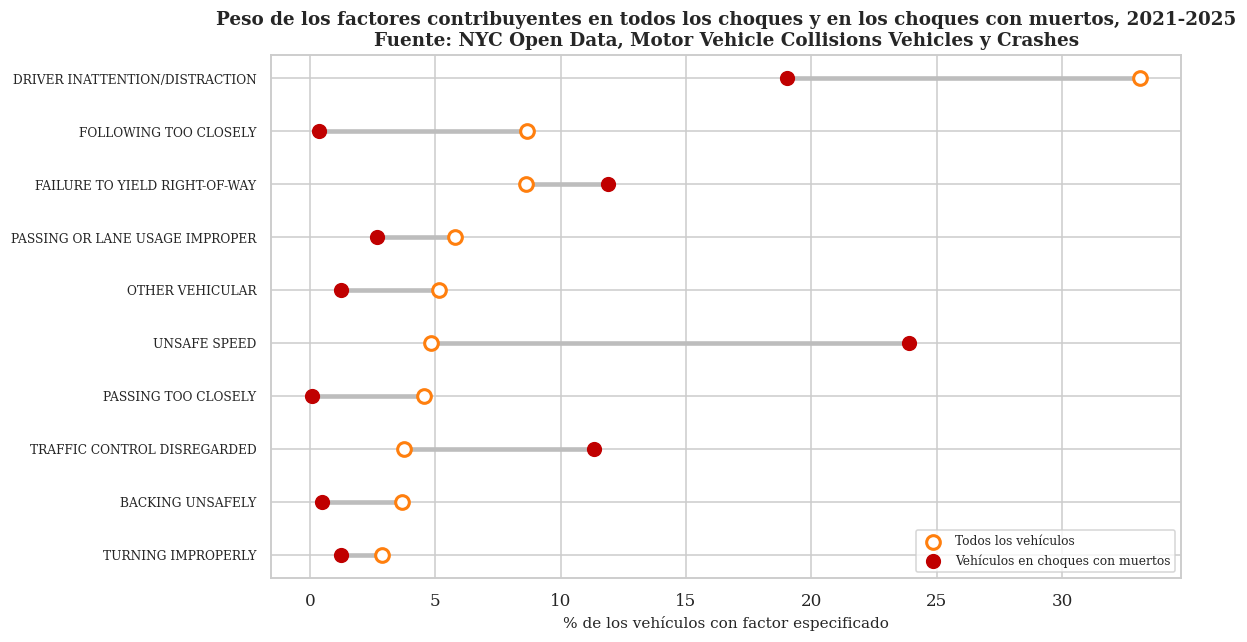

In [53]:
datos = pdf_fact_top.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
for y_pos, (_, fila) in enumerate(datos.iterrows()):
    ax.plot([fila["PCT_TODOS"], fila["PCT_CON_MUERTOS"]], [y_pos, y_pos], color="#bdbdbd", lw=3, zorder=1)
    ax.scatter(fila["PCT_TODOS"], y_pos, s=80, color="white", edgecolor="#ff7f0e", linewidth=2, zorder=2)
    ax.scatter(fila["PCT_CON_MUERTOS"], y_pos, s=80, color="#c00000", zorder=3)
ax.set_yticks(range(len(datos)))
ax.set_yticklabels(datos["FACTOR_1"].str.slice(0, 45), fontsize=8)
ax.scatter([], [], s=80, color="white", edgecolor="#ff7f0e", linewidth=2, label="Todos los vehículos")
ax.scatter([], [], s=80, color="#c00000", label="Vehículos en choques con muertos")
ax.legend(loc="lower right", fontsize=8)
ax.set(xlabel="% de los vehículos con factor especificado",
       title="Peso de los factores contribuyentes en todos los choques y en los choques con muertos, 2021-2025\n"
             "Fuente: NYC Open Data, Motor Vehicle Collisions Vehicles y Crashes")
plt.tight_layout()
plt.show()

**Análisis:** La gráfica deja ver qué factores pesan más en los choques mortales que en el total: velocidad insegura, no respetar el control de tráfico y no ceder el paso tienen el punto lleno a la derecha. La distracción, seguir muy de cerca y los cambios de carril indebidos tienen el punto lleno a la izquierda: causan muchos choques, pero pocos mortales. Para reducir muertes, el control de velocidad y de semáforos es más importante que el de distracción.

### 6.3 Día de la semana y hora

Se cuentan los choques de 2021 a 2025 por día y hora, sin los que tienen la hora de relleno 00:00 ni los que no tienen hora válida. El panel de la izquierda incluye todos los choques y el de la derecha solo los choques con víctimas.

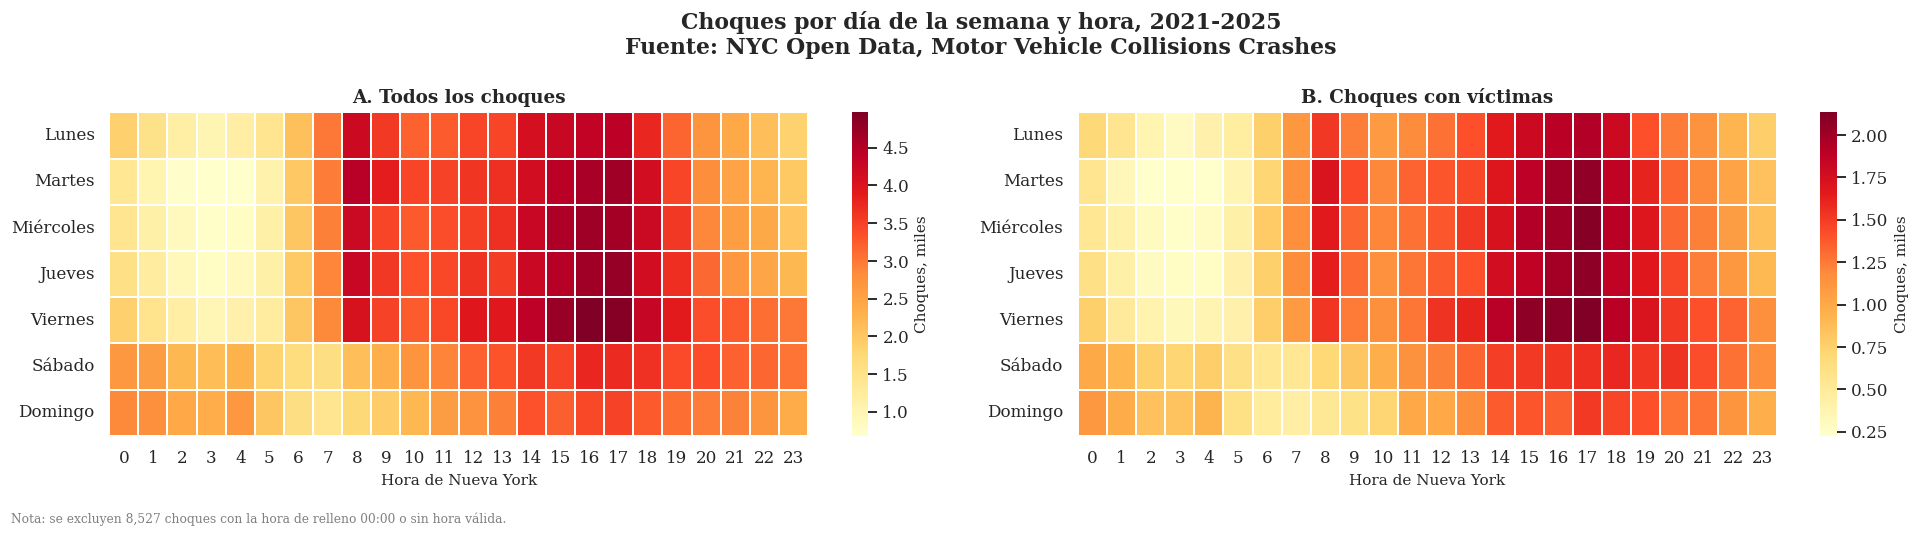

Las 5 franjas con más choques con víctimas:
      DIA  HORA  CON_VICTIMAS
  Viernes    17          2133
Miércoles    17          2105
  Viernes    16          2095
  Viernes    15          2067
   Jueves    17          2066


In [54]:
pdf_dia_hora = (df_choques.filter(F.col("ANIO").between(ANIO_INI, ANIO_COMPLETO) & (F.col("HORA_RELLENO") == 0)
                                  & F.col("HORA").isNotNull())
                .groupBy("DIA_SEMANA", "HORA").agg(F.count("*").alias("CHOQUES"),
                                                   F.sum("CON_VICTIMAS").alias("CON_VICTIMAS"))
                .toPandas())
pdf_dia_hora["DIA"] = pdf_dia_hora["DIA_SEMANA"].map(DIAS_ES)
excluidos_hora = df_choques.filter(F.col("ANIO").between(ANIO_INI, ANIO_COMPLETO)
                                   & ((F.col("HORA_RELLENO") == 1) | F.col("HORA").isNull())).count()

fig, axes = plt.subplots(1, 2, figsize=(18, 4.8))
for ax, columna, titulo in zip(axes, ["CHOQUES", "CON_VICTIMAS"], ["A. Todos los choques", "B. Choques con víctimas"]):
    matriz = (pdf_dia_hora.pivot(index="DIA", columns="HORA", values=columna)
              .reindex(index=ORDEN_DIAS, columns=range(24)).fillna(0))
    sns.heatmap(matriz / 1000, ax=ax, cmap="YlOrRd", linewidths=0.3, linecolor="white",
                cbar_kws={"label": "Choques, miles"})
    ax.set(title=titulo, xlabel="Hora de Nueva York", ylabel="")
fig.suptitle(f"Choques por día de la semana y hora, {ANIO_INI}-{ANIO_COMPLETO}\nFuente: NYC Open Data, Motor Vehicle Collisions Crashes",
             fontweight="bold")
nota_figura(fig, f"Nota: se excluyen {excluidos_hora:,} choques con la hora de relleno 00:00 o sin hora válida.")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()
top5_franjas = pdf_dia_hora.sort_values("CON_VICTIMAS", ascending=False).head(5)[["DIA", "HORA", "CON_VICTIMAS"]]
print("Las 5 franjas con más choques con víctimas:")
print(top5_franjas.to_string(index=False))

**Análisis:** Los choques se concentran entre semana en la tarde, entre las 14:00 y las 18:00, con un segundo pico a las 8:00 de la mañana, que coincide con la entrada al trabajo. La franja con más choques con víctimas es el viernes a las 17:00, con 2,133, seguida del miércoles y el viernes en la misma franja. En la madrugada, entre las 0:00 y las 4:00, hay más choques el sábado y el domingo que entre semana. Se excluyeron 8,527 choques con la hora 00:00 o sin hora válida.

### 6.4 Gravedad por distrito

Se suman choques, choques con víctimas, heridos y muertos de 2021 a 2025 por distrito y año. La gravedad se mide de dos formas: heridos por cada 100 choques y letalidad, que son los muertos por cada 1,000 víctimas. Se agrega la tasa de choques con víctimas de 2025 por cada 100,000 habitantes.

In [55]:
pdf_grav = (df_choques.filter(F.col("ANIO").between(ANIO_INI, ANIO_COMPLETO))
            .groupBy(F.coalesce(F.col("DISTRITO"), F.lit("SIN DISTRITO")).alias("DISTRITO"), "ANIO")
            .agg(F.count("*").alias("CHOQUES"), F.sum("CON_VICTIMAS").alias("CHOQUES_CON_VICTIMAS"),
                 F.sum("NUMBER_OF_PERSONS_INJURED").alias("HERIDOS"), F.sum("NUMBER_OF_PERSONS_KILLED").alias("MUERTOS"))
            .toPandas())
tabla_grav = pdf_grav.groupby("DISTRITO")[["CHOQUES", "CHOQUES_CON_VICTIMAS", "HERIDOS", "MUERTOS"]].sum()
tabla_grav = tabla_grav.reindex([d for d in ORDEN_BORO + ["SIN DISTRITO"] if d in tabla_grav.index])
tabla_grav.loc["CIUDAD"] = tabla_grav.sum()
tabla_grav["HERIDOS_POR_100"] = tabla_grav["HERIDOS"] / tabla_grav["CHOQUES"] * 100
tabla_grav["LETALIDAD_POR_1000"] = tabla_grav["MUERTOS"] / (tabla_grav["HERIDOS"] + tabla_grav["MUERTOS"]) * 1000
vict_2025 = pdf_grav[pdf_grav["ANIO"] == ANIO_COMPLETO].groupby("DISTRITO")["CHOQUES_CON_VICTIMAS"].sum()
vict_2025.loc["CIUDAD"] = vict_2025.sum()
pob_grav = pd.Series({d: (POB_CIUDAD if d == "CIUDAD" else POB_DISTRITO.get(d, np.nan)) for d in tabla_grav.index})
tabla_grav["VICTIMAS_2025_POR_100K"] = vict_2025.reindex(tabla_grav.index) / pob_grav * 100000
mostrar_tabla(tabla_grav.reset_index().assign(DISTRITO=lambda d: d["DISTRITO"].map(nombre_boro)).rename(columns={
    "DISTRITO": "Distrito", "CHOQUES": "Choques", "CHOQUES_CON_VICTIMAS": "Choques con víctimas", "HERIDOS": "Heridos",
    "MUERTOS": "Muertos", "HERIDOS_POR_100": "Heridos por 100 choques", "LETALIDAD_POR_1000": "Muertos por 1,000 víctimas",
    "VICTIMAS_2025_POR_100K": "Choques con víctimas 2025 por 100,000 hab."}),
    titulo="Gravedad de los choques por distrito, 2021-2025", decimales=2)

Distrito,Choques,Choques con víctimas,Heridos,Muertos,Heridos por 100 choques,"Muertos por 1,000 víctimas","Choques con víctimas 2025 por 100,000 hab."
Bronx,"75,150","30,204","41,798",229,55.62,5.45,422.55
Brooklyn,"154,128","63,513","84,083",378,54.55,4.48,475.35
Manhattan,"79,087","30,763","37,551",212,47.48,5.61,373.70
Queens,"127,958","51,614","69,621",340,54.41,4.86,462.70
Staten Island,"23,889","8,654","11,777",70,49.30,5.91,372.91
Sin Distrito,"27,702","11,518","16,804",135,60.66,7.97,
Ciudad,"487,914","196,266","261,634","1,364",53.62,5.19,441.37


**Análisis:** Entre 2021 y 2025 hubo 487,914 choques y el 40.2% dejó al menos una víctima, con 261,634 heridos y 1,364 muertos. Brooklyn tiene la mayor tasa de choques con víctimas en 2025, 475.35 por cada 100,000 habitantes, seguido de Queens, con 462.70. La gravedad se reparte distinto: el Bronx tiene más heridos por choque, 55.62 por cada 100, y Staten Island y Manhattan más muertos por cada 1,000 víctimas, 5.91 y 5.61. Los choques sin distrito tienen la letalidad más alta, 7.97, posiblemente porque muchos ocurren en autopistas sin dirección registrada.

Las líneas muestran heridos y muertos por año y distrito. Los dos paneles no comparten el eje vertical, porque los muertos son mucho menos que los heridos.

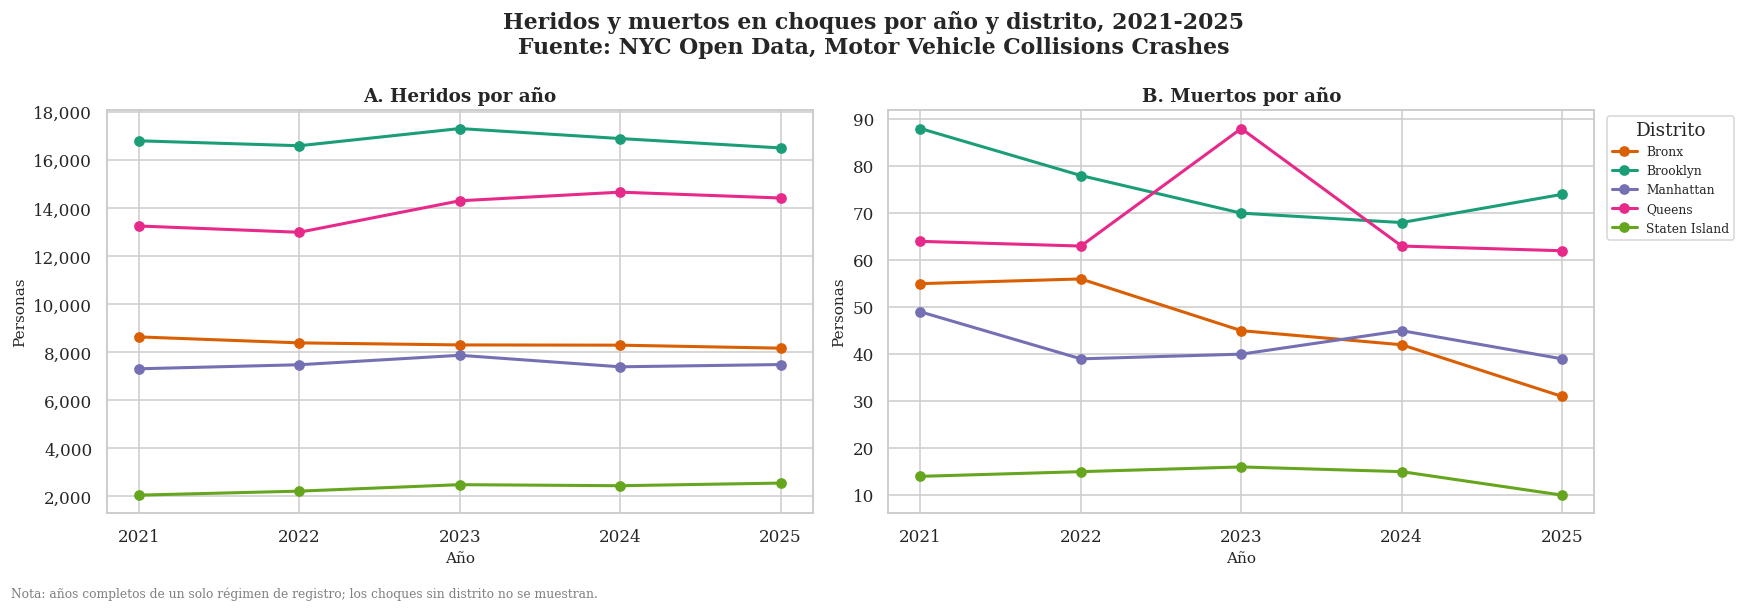

In [56]:
pdf_lineas = pdf_grav[pdf_grav["DISTRITO"].isin(ORDEN_BORO)]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, medida, titulo in zip(axes, ["HERIDOS", "MUERTOS"], ["A. Heridos por año", "B. Muertos por año"]):
    for distrito in ORDEN_BORO:
        serie = pdf_lineas[pdf_lineas["DISTRITO"] == distrito].sort_values("ANIO")
        ax.plot(serie["ANIO"], serie[medida], marker="o", lw=2, color=PALETA_BORO[distrito], label=nombre_boro(distrito))
    ax.set_xticks(range(ANIO_INI, ANIO_COMPLETO + 1))
    ax.set(title=titulo, xlabel="Año", ylabel="Personas")
    formato_miles(ax.yaxis)
axes[1].legend(title="Distrito", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle(f"Heridos y muertos en choques por año y distrito, {ANIO_INI}-{ANIO_COMPLETO}\n"
             "Fuente: NYC Open Data, Motor Vehicle Collisions Crashes", fontweight="bold")
nota_figura(fig, "Nota: años completos de un solo régimen de registro; los choques sin distrito no se muestran.")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Análisis:** Los heridos son casi estables entre 2021 y 2025 en todos los distritos, con Brooklyn siempre arriba, entre 16,500 y 17,300 al año. Los muertos sí bajan: en los cinco distritos suman 270 en 2021 y 216 en 2025, un 20% menos. El Bronx es el que más baja, de 55 a 31. Queens tiene un pico de 88 muertos en 2023 y Brooklyn sube de nuevo en 2025, a 74. Como los muertos son pocos, un año puede cambiar mucho por pocos casos.

### 6.5 Personas: peatones, ciclistas y ocupantes

Person dice quién resultó herido o muerto. Se usan 2021-2025 y se recuerda que la cobertura real de Person se revisó en la sección 4.5: si algún tramo quedó incompleto, estos conteos están por debajo del total real. La letalidad es el número de muertos por cada 1,000 personas lesionadas, heridas o muertas, de cada tipo.

In [57]:
df_per_21_25 = df_personas.filter(F.col("ANIO").between(ANIO_INI, ANIO_COMPLETO)).cache()
pdf_tipo_anio = (df_per_21_25.groupBy("ANIO", "TIPO_PERSONA").agg(
        F.count("*").alias("PERSONAS"),
        F.count(F.when(F.col("GRAVEDAD") == "HERIDO", 1)).alias("HERIDOS"),
        F.count(F.when(F.col("GRAVEDAD") == "MUERTO", 1)).alias("MUERTOS"))
    .toPandas())
tabla_tipo = pdf_tipo_anio.groupby("TIPO_PERSONA")[["PERSONAS", "HERIDOS", "MUERTOS"]].sum()
tabla_tipo["LETALIDAD_POR_1000"] = tabla_tipo["MUERTOS"] / (tabla_tipo["HERIDOS"] + tabla_tipo["MUERTOS"]) * 1000
tabla_tipo["PCT_DE_LOS_MUERTOS"] = tabla_tipo["MUERTOS"] / tabla_tipo["MUERTOS"].sum() * 100
tabla_tipo["PCT_DE_LOS_HERIDOS"] = tabla_tipo["HERIDOS"] / tabla_tipo["HERIDOS"].sum() * 100
mostrar_tabla(tabla_tipo.sort_values("PERSONAS", ascending=False).reset_index().rename(columns={
    "TIPO_PERSONA": "Tipo de persona", "PERSONAS": "Personas involucradas", "HERIDOS": "Heridos", "MUERTOS": "Muertos",
    "LETALIDAD_POR_1000": "Muertos por 1,000 lesionados", "PCT_DE_LOS_MUERTOS": "Del total de muertos %",
    "PCT_DE_LOS_HERIDOS": "Del total de heridos %"}),
    titulo="Personas involucradas en choques por tipo y gravedad, 2021-2025", decimales=2,
    pct=["Del total de muertos %", "Del total de heridos %"])

Tipo de persona,Personas involucradas,Heridos,Muertos,"Muertos por 1,000 lesionados",Del total de muertos %,Del total de heridos %
OCUPANTE,"1,605,788","181,484",565,3.10,41.42%,69.37%
PEATÓN,"48,330","44,300",617,13.74,45.23%,16.93%
CICLISTA,"31,368","25,675",116,4.50,8.50%,9.81%
OTRO MOTORIZADO,"12,391","10,176",66,6.44,4.84%,3.89%


**Análisis:** Person muestra quiénes son las víctimas. Los peatones son solo el 16.93% de los heridos, pero el 45.23% de los muertos, más que los ocupantes de los vehículos. Su letalidad es de 13.74 muertos por cada 1,000 lesionados, 4.4 veces la de los ocupantes, que es de 3.10. Los ciclistas tienen una letalidad de 4.50 y los otros motorizados, como patinetas y scooters motorizados, de 6.44. La suma de muertos de Person, 1,364, es la misma de Crashes, lo que confirma la integridad entre tablas.

Los dos mapas de calor siguen a cada tipo de persona por año: a la izquierda la letalidad y a la derecha qué porcentaje de los muertos de cada año fue de ese tipo.

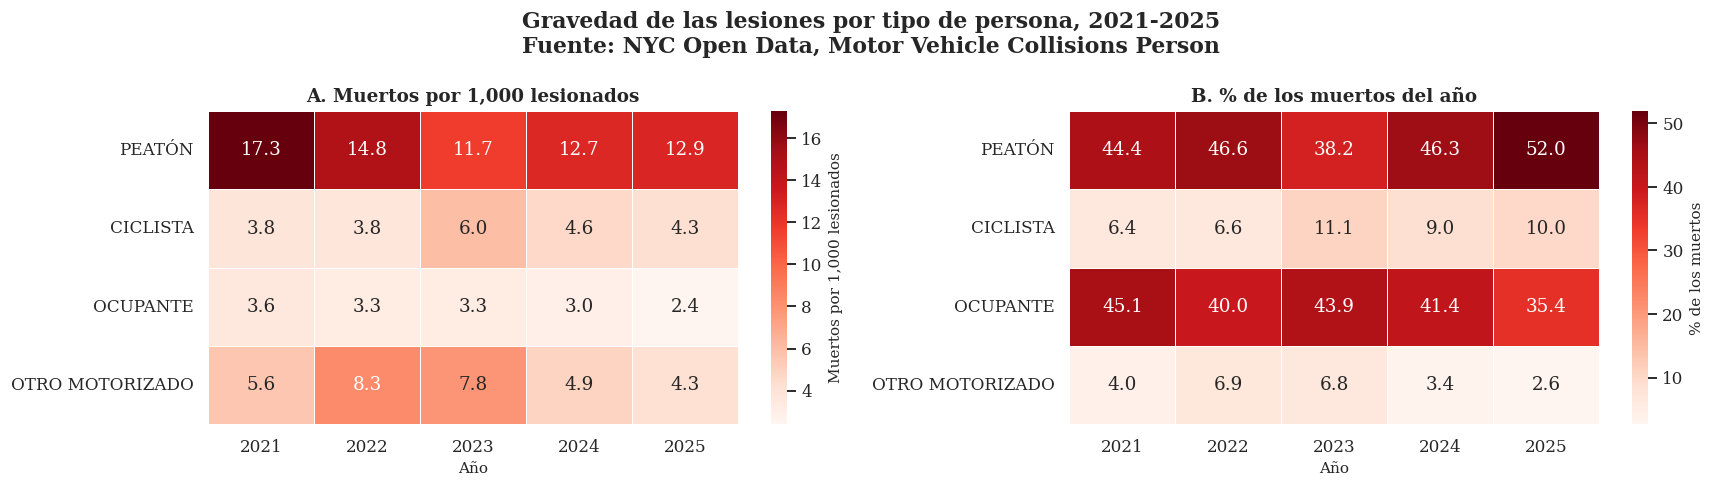

In [58]:
tipos = ["PEATÓN", "CICLISTA", "OCUPANTE", "OTRO MOTORIZADO"]
pdf_tipo_anio["LETALIDAD"] = pdf_tipo_anio["MUERTOS"] / (pdf_tipo_anio["HERIDOS"] + pdf_tipo_anio["MUERTOS"]) * 1000
pdf_tipo_anio["PCT_MUERTOS"] = pdf_tipo_anio["MUERTOS"] / pdf_tipo_anio.groupby("ANIO")["MUERTOS"].transform("sum") * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, columna, titulo, etiqueta in [(axes[0], "LETALIDAD", "A. Muertos por 1,000 lesionados", "Muertos por 1,000 lesionados"),
                                      (axes[1], "PCT_MUERTOS", "B. % de los muertos del año", "% de los muertos")]:
    matriz = (pdf_tipo_anio.pivot(index="TIPO_PERSONA", columns="ANIO", values=columna)
              .reindex(index=[t for t in tipos if t in pdf_tipo_anio["TIPO_PERSONA"].unique()]))
    sns.heatmap(matriz, ax=ax, cmap="Reds", annot=True, fmt=".1f", linewidths=0.6, linecolor="white",
                cbar_kws={"label": etiqueta})
    ax.set(title=titulo, xlabel="Año", ylabel="")
    ax.tick_params(axis="y", rotation=0)
fig.suptitle(f"Gravedad de las lesiones por tipo de persona, {ANIO_INI}-{ANIO_COMPLETO}\n"
             "Fuente: NYC Open Data, Motor Vehicle Collisions Person", fontweight="bold")
plt.tight_layout()
plt.show()

**Análisis:** La letalidad de los peatones es la más alta todos los años, aunque baja de 17.3 en 2021 a 12.9 en 2025. Aun así, su peso en los muertos crece: en 2025 los peatones son el 52.0% de los muertos en choques, frente al 44.4% de 2021. Los ciclistas también ganan peso, de 6.4% a 10.0%, mientras que los ocupantes bajan de 45.1% a 35.4%. Las muertes se están moviendo hacia los usuarios más vulnerables de la vía.

Se compara la edad de los heridos y de los muertos por tipo de persona con diagramas de cajas. Los cuartiles y los bigotes se calculan en Spark con `percentile_approx` y la regla de 1.5 veces el rango intercuartílico; al Driver solo llega una fila por grupo y `ax.bxp` dibuja las cajas desde esos números.

In [59]:
# resumen_boxplot_spark: recibe un DataFrame, una variable numérica y la lista de columnas de grupo.
# Calcula en Spark los cuartiles aproximados, la media, el número de casos y los bigotes de 1.5 veces el
# rango intercuartílico de cada grupo. Devuelve un DataFrame de pandas con una fila por grupo
def resumen_boxplot_spark(df, variable, grupos):
    base = df.filter(F.col(variable).isNotNull())
    for g in grupos:
        base = base.filter(F.col(g).isNotNull())
    cuartiles = (base.groupBy(*grupos)
                 .agg(F.expr(f"percentile_approx(`{variable}`, array(0.25, 0.5, 0.75), 10000)").alias("Q"),
                      F.avg(variable).alias("MEDIA"), F.count("*").alias("N"))
                 .select(*grupos, "MEDIA", "N", F.col("Q")[0].alias("Q1"), F.col("Q")[1].alias("MEDIANA"),
                         F.col("Q")[2].alias("Q3")))
    valor, rango = F.col(variable), F.col("Q3") - F.col("Q1")
    # broadcast: la tabla de cuartiles tiene una fila por grupo
    bigotes = (base.join(F.broadcast(cuartiles.select(*grupos, "Q1", "Q3")), grupos)
               .groupBy(*grupos)
               .agg(F.min(F.when(valor >= F.col("Q1") - 1.5 * rango, valor)).alias("BIGOTE_INFERIOR"),
                    F.max(F.when(valor <= F.col("Q3") + 1.5 * rango, valor)).alias("BIGOTE_SUPERIOR")))
    return cuartiles.join(bigotes, grupos).toPandas()

# a_bxp: recibe una fila del resumen y una etiqueta; devuelve el diccionario que espera ax.bxp
def a_bxp(fila, etiqueta):
    return {"label": etiqueta, "q1": fila["Q1"], "med": fila["MEDIANA"], "q3": fila["Q3"],
            "whislo": fila["BIGOTE_INFERIOR"], "whishi": fila["BIGOTE_SUPERIOR"], "mean": fila["MEDIA"], "fliers": []}

pdf_box_edad = resumen_boxplot_spark(df_per_21_25.filter(F.col("GRAVEDAD").isin("HERIDO", "MUERTO")
                                                          & F.col("TIPO_PERSONA").isin(*tipos)),
                                     "EDAD", ["TIPO_PERSONA", "GRAVEDAD"])
mostrar_tabla(pdf_box_edad.sort_values(["TIPO_PERSONA", "GRAVEDAD"]).rename(columns={
    "TIPO_PERSONA": "Tipo de persona", "GRAVEDAD": "Gravedad", "MEDIA": "Edad media", "N": "Personas",
    "MEDIANA": "Edad mediana", "BIGOTE_INFERIOR": "Bigote inferior", "BIGOTE_SUPERIOR": "Bigote superior"}),
    titulo="Edad de los heridos y muertos por tipo de persona, 2021-2025", decimales=1)

Tipo de persona,Gravedad,Edad media,Personas,Q1,Edad mediana,Q3,Bigote inferior,Bigote superior
CICLISTA,HERIDO,34.2,"25,588",24,32,42,0,69
CICLISTA,MUERTO,44.5,116,29,43,58,16,91
OCUPANTE,HERIDO,37.1,"179,983",26,34,48,0,81
OCUPANTE,MUERTO,37.8,560,24,33,48,4,84
OTRO MOTORIZADO,HERIDO,32.6,"10,137",23,31,40,0,65
OTRO MOTORIZADO,MUERTO,42.3,66,31,42,51,16,74
PEATÓN,HERIDO,40.8,"42,983",25,39,57,0,104
PEATÓN,MUERTO,54.8,604,40,58,70,1,101


**Análisis:** Los peatones que mueren son mucho mayores que los que resultan heridos: su edad mediana es 58 años, frente a 39 de los heridos, y la mitad central va de 40 a 70 años. En los ciclistas pasa lo mismo, con 43 años frente a 32. En los ocupantes la edad casi no cambia entre heridos y muertos, 34 y 33 años. Esto indica que la edad aumenta el riesgo de morir cuando la persona va a pie o en bicicleta.

Con esos resúmenes se dibujan las cajas: naranja claro para los heridos y rojo para los muertos de cada tipo de persona.

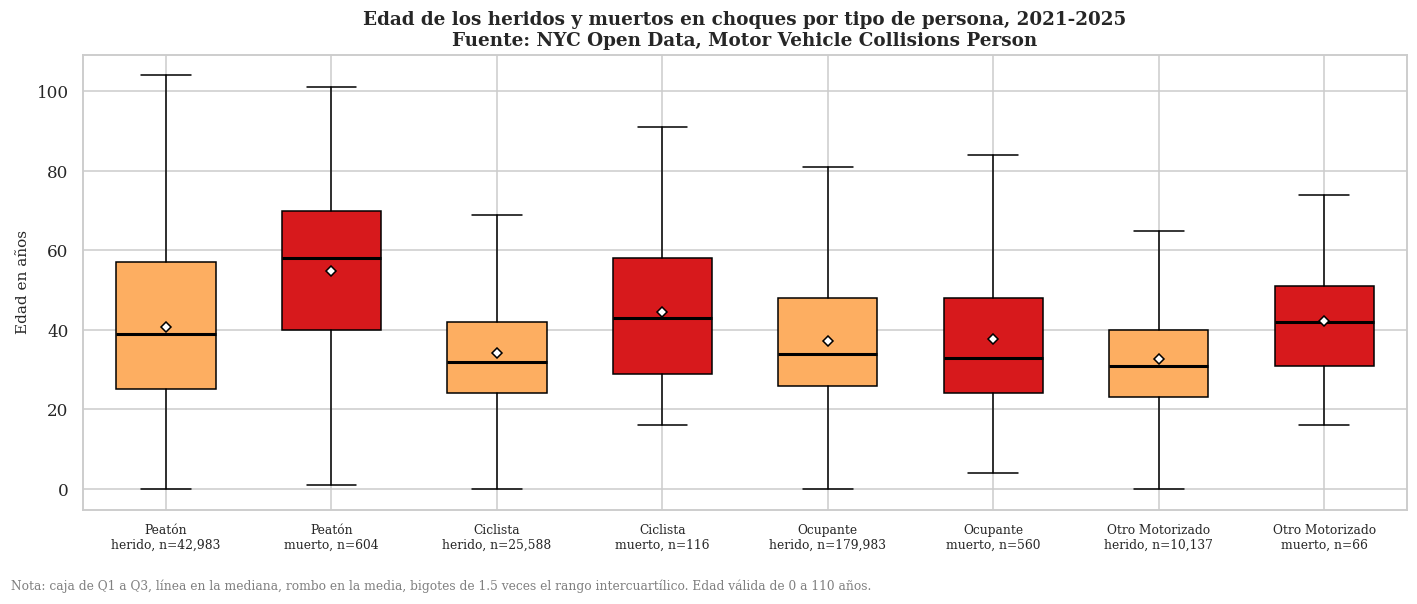

In [60]:
estadisticas, colores = [], []
for tipo in tipos:
    for gravedad, color in [("HERIDO", "#fdae61"), ("MUERTO", "#d7191c")]:
        fila = pdf_box_edad[(pdf_box_edad["TIPO_PERSONA"] == tipo) & (pdf_box_edad["GRAVEDAD"] == gravedad)]
        if len(fila):
            fila = fila.iloc[0]
            estadisticas.append(a_bxp(fila, f"{tipo.title()}\n{gravedad.lower()}, n={int(fila['N']):,}"))
            colores.append(color)
fig, ax = plt.subplots(figsize=(13, 5.5))
cajas = ax.bxp(estadisticas, showfliers=False, showmeans=True, patch_artist=True, widths=0.6,
               medianprops=dict(color="black", lw=2),
               meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=5))
for caja_bxp, color in zip(cajas["boxes"], colores):
    caja_bxp.set_facecolor(color)
ax.set(ylabel="Edad en años", title=f"Edad de los heridos y muertos en choques por tipo de persona, {ANIO_INI}-{ANIO_COMPLETO}\n"
                                    "Fuente: NYC Open Data, Motor Vehicle Collisions Person")
ax.tick_params(axis="x", labelsize=8)
nota_figura(fig, "Nota: caja de Q1 a Q3, línea en la mediana, rombo en la media, bigotes de 1.5 veces el rango intercuartílico. Edad válida de 0 a 110 años.")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

**Análisis:** Las cajas rojas de peatones, ciclistas y otros motorizados están más arriba que las naranjas, mientras que en los ocupantes las dos cajas son casi iguales. La caja de los peatones muertos es la más alta de todas. Para el plan de acción, esto apunta a medidas de protección para los adultos mayores que caminan, como tiempos de cruce más largos en los semáforos.

Por último, el mapa de calor muestra la parte del cuerpo lesionada en los heridos y muertos de cada tipo de persona, con las 10 partes más frecuentes. Cada fila suma el 100% de los lesionados de ese tipo que tienen la parte registrada.

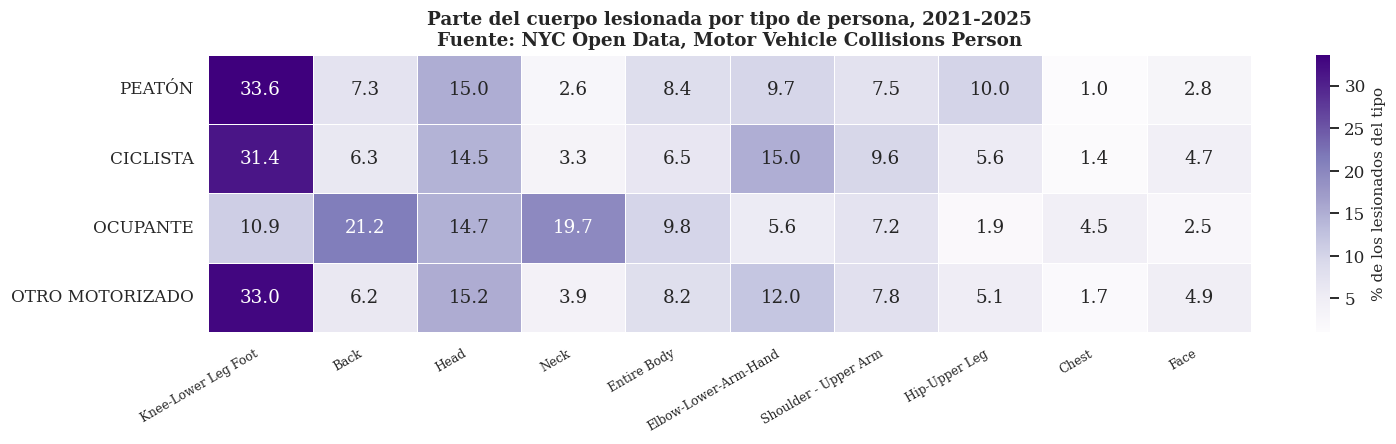

DataFrame[COLLISION_ID: bigint, UNIQUE_ID: bigint, VEHICLE_TYPE: string, VEHICLE_YEAR: int, VEHICLE_OCCUPANTS: bigint, DRIVER_SEX: string, DRIVER_LICENSE_STATUS: string, PRE_CRASH: string, CONTRIBUTING_FACTOR_1: string, N_NO_CONVERTIBLES: int, FECHA: date, ANIO: int, VEHICLE_TYPE_CLEAN: string, CATEGORIA_VEHICULO: string, TOPE_OCUPANTES: int, OCUPANTES_ALTERADO: boolean, OCUPANTES: bigint, ANIO_MODELO: int, FACTOR_1: string, DISTRITO: string, PUMA: int, CON_VICTIMAS: int, CON_MUERTOS: int]

In [61]:
pdf_cuerpo = (df_per_21_25.filter(F.col("GRAVEDAD").isin("HERIDO", "MUERTO") & F.col("TIPO_PERSONA").isin(*tipos)
                                  & (F.col("PARTE_CUERPO") != "NO ESPECIFICADO"))
              .groupBy("TIPO_PERSONA", "PARTE_CUERPO").agg(F.count("*").alias("PERSONAS")).toPandas())
top_partes = pdf_cuerpo.groupby("PARTE_CUERPO")["PERSONAS"].sum().nlargest(10).index.tolist()
matriz_cuerpo = (pdf_cuerpo.pivot(index="TIPO_PERSONA", columns="PARTE_CUERPO", values="PERSONAS").fillna(0)
                 .reindex(index=[t for t in tipos if t in pdf_cuerpo["TIPO_PERSONA"].unique()]))
matriz_cuerpo = (matriz_cuerpo.div(matriz_cuerpo.sum(axis=1), axis=0) * 100)[top_partes]
fig, ax = plt.subplots(figsize=(14, 4.2))
sns.heatmap(matriz_cuerpo, annot=True, fmt=".1f", cmap="Purples", linewidths=0.6, linecolor="white",
            cbar_kws={"label": "% de los lesionados del tipo"}, ax=ax)
ax.set(xlabel="", ylabel="", title=f"Parte del cuerpo lesionada por tipo de persona, {ANIO_INI}-{ANIO_COMPLETO}\n"
                                    "Fuente: NYC Open Data, Motor Vehicle Collisions Person")
ax.set_xticklabels([t.get_text().title()[:28] for t in ax.get_xticklabels()], rotation=30, ha="right", fontsize=8)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()
# Se liberan las bases que solo se usaban en esta sección
df_per_21_25.unpersist()
df_veh_21_25.unpersist()

**Análisis:** Las lesiones dependen del tipo de persona. En peatones, ciclistas y otros motorizados la parte más lesionada es la rodilla, la pierna y el pie, con entre 31% y 34%, seguida de la cabeza, con cerca del 15%. En los ocupantes, en cambio, dominan la espalda, 21.2%, y el cuello, 19.7%, lesiones típicas del golpe de un choque por detrás. Los ciclistas tienen además más lesiones en codo, antebrazo y mano, 15.0%, por la caída.

## 7. Exploración territorial: condiciones sociales, educación, acceso digital, espacio público y cruces

En esta sección se describen el contexto social de cada distrito y PUMA con PUMS 2024, el SAT reciente, el acceso digital y el espacio público, y luego se cruzan con los arrestos y los choques. Con 5 distritos los cruces son pistas; por PUMA hay 55 zonas y más evidencia, pero el análisis sigue siendo exploratorio.

### 7.1 Condiciones sociales por distrito, PUMS 2024

Todas las tasas están ponderadas con `PWGTP`. La pobreza es la población con `POVPIP` menor a 100 sobre la población a la que aplica la medida; cerca de la pobreza es `POVPIP` de 100 a 149; el desempleo es la población desempleada sobre la fuerza laboral civil; la educación se mide en los adultos de 25 años o más.

In [62]:
COLUMNAS_SOCIALES = {"POBLACION": "Población", "POBREZA_PCT": "Pobreza %", "CERCA_POBREZA_PCT": "Cerca de la pobreza %",
                     "DESEMPLEO_PCT": "Desempleo %", "DESEMPLEO_16_24_PCT": "Desempleo de 16 a 24 años %",
                     "SIN_BACHILLERATO_PCT": "Adultos sin bachillerato %", "UNIVERSITARIA_PCT": "Adultos universitarios %",
                     "JOVENES_15_24_PCT": "Jóvenes de 15 a 24 años %"}
tabla_social = pd.concat([pdf_pums_distrito, pdf_pums_ciudad], ignore_index=True)[["DISTRITO"] + list(COLUMNAS_SOCIALES)]
tabla_social["DISTRITO"] = tabla_social["DISTRITO"].map(nombre_boro)
mostrar_tabla(tabla_social.rename(columns={"DISTRITO": "Distrito", **COLUMNAS_SOCIALES}),
              titulo="Condiciones sociales por distrito, ACS PUMS 2024 ponderado con PWGTP", decimales=2,
              pct=[v for k, v in COLUMNAS_SOCIALES.items() if k != "POBLACION"])

Distrito,Población,Pobreza %,Cerca de la pobreza %,Desempleo %,Desempleo de 16 a 24 años %,Adultos sin bachillerato %,Adultos universitarios %,Jóvenes de 15 a 24 años %
Bronx,"1,385,638",28.96%,12.03%,10.48%,18.57%,24.01%,23.02%,13.55%
Brooklyn,"2,618,069",19.11%,8.41%,7.13%,17.05%,15.63%,42.87%,11.13%
Manhattan,"1,659,873",16.10%,6.17%,6.40%,11.36%,10.16%,64.53%,11.43%
Queens,"2,316,416",13.58%,8.38%,5.84%,13.37%,18.11%,37.10%,10.50%
Staten Island,"498,242",11.19%,7.51%,4.70%,17.40%,11.46%,35.98%,12.15%
Ciudad,"8,478,238",18.15%,8.51%,6.97%,15.25%,16.19%,42.43%,11.47%


**Análisis:** El Bronx tiene las peores condiciones sociales de la ciudad en casi todos los indicadores: pobreza de 28.96%, 1.6 veces la de la ciudad, desempleo de 10.48%, el 24.01% de los adultos sin bachillerato y solo el 23.02% con estudios universitarios. En el otro extremo, Staten Island tiene la menor pobreza, 11.19%, y el menor desempleo, 4.70%, y Manhattan tiene la mayor proporción de universitarios, 64.53%. El desempleo de 16 a 24 años es alto en todos los distritos, con 15.25% en la ciudad, más del doble del desempleo general.

### 7.2 Condiciones sociales por PUMA

Dentro de un mismo distrito puede haber zonas muy distintas. La tabla resume, para cada distrito, la PUMA con el valor más bajo, la mediana y la PUMA con el valor más alto de tres indicadores.

In [63]:
filas_disp = []
for indicador in ["POBREZA_PCT", "DESEMPLEO_PCT", "SIN_BACHILLERATO_PCT"]:
    for distrito in ORDEN_BORO:
        serie = pdf_pums_puma.loc[pdf_pums_puma["DISTRITO"] == distrito, indicador]
        filas_disp.append({"Indicador": COLUMNAS_SOCIALES[indicador], "Distrito": nombre_boro(distrito),
                           "PUMAs": len(serie), "Mínimo": serie.min(), "Mediana": serie.median(), "Máximo": serie.max(),
                           "Rango": serie.max() - serie.min()})
mostrar_tabla(pd.DataFrame(filas_disp), titulo="Dispersión de los indicadores sociales entre las PUMAs de cada distrito, 2024",
              decimales=2)

Indicador,Distrito,PUMAs,Mínimo,Mediana,Máximo,Rango
Pobreza %,Bronx,10,11.92,30.11,43.77,31.85
Pobreza %,Brooklyn,18,7.64,17.94,33.38,25.74
Pobreza %,Manhattan,10,5.12,14.99,34.89,29.77
Pobreza %,Queens,14,7.15,12.43,19.27,12.12
Pobreza %,Staten Island,3,7.15,10.80,15.22,8.07
Desempleo %,Bronx,10,6.09,9.62,15.85,9.76
Desempleo %,Brooklyn,18,3.87,7.12,15.87,12.00
Desempleo %,Manhattan,10,3.46,6.10,12.15,8.69
Desempleo %,Queens,14,2.34,5.66,9.09,6.75
Desempleo %,Staten Island,3,4.01,4.32,5.60,1.60


**Análisis:** El promedio de un distrito esconde zonas muy distintas. En el Bronx la pobreza va de 11.92% a 43.77% entre sus PUMAs y en Manhattan de 5.12% a 34.89%, un rango de casi 30 puntos. Queens y Staten Island son más parejos, con rangos de 12.12 y 8.07 puntos. En Brooklyn el desempleo va de 3.87% a 15.87%. Esto refuerza que el diagnóstico debe hacerse por PUMA.

Cada punto de la figura es una PUMA. Se ve qué tan desigual es cada distrito por dentro en pobreza, desempleo y adultos sin bachillerato; la línea punteada es el valor de la ciudad.

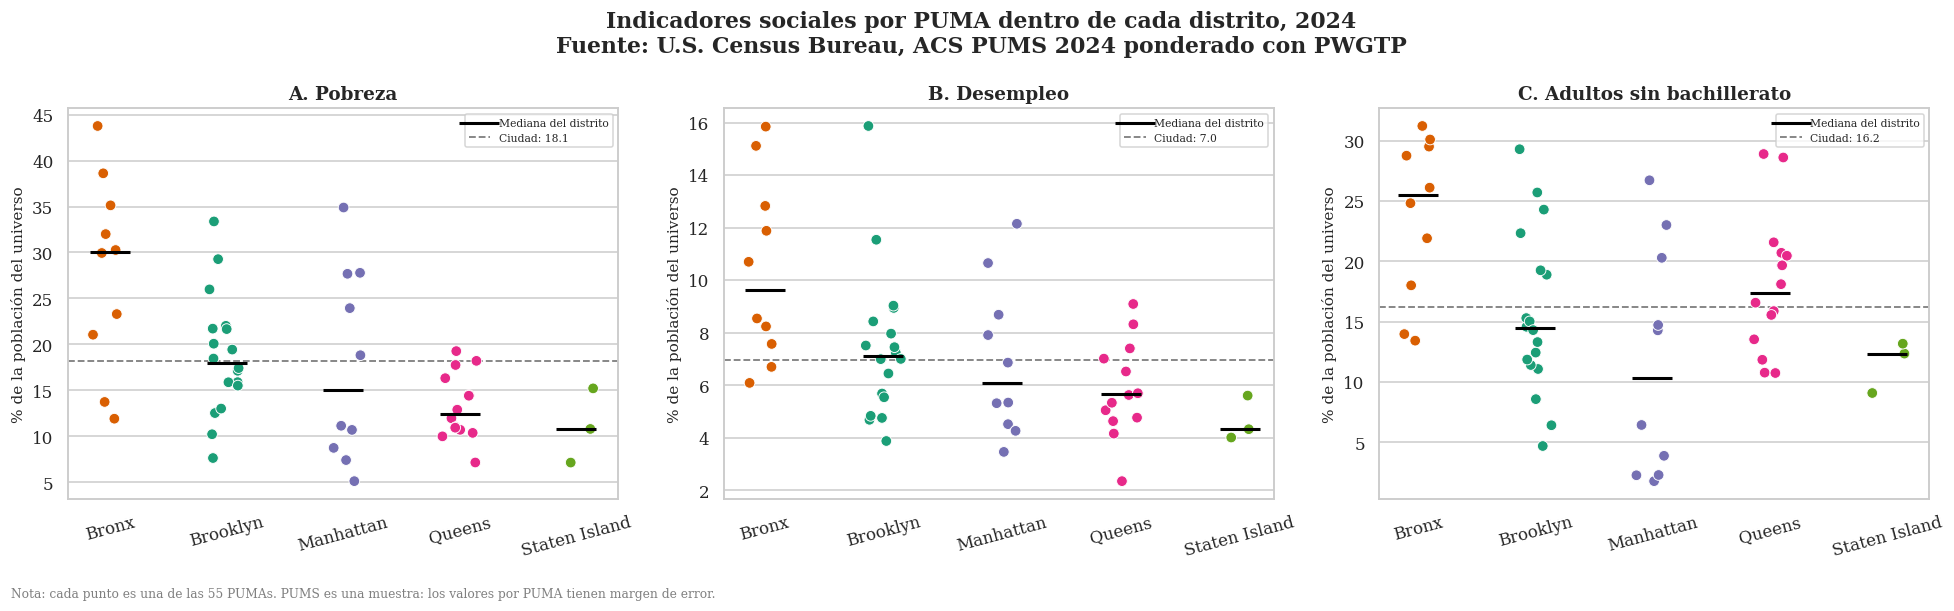

In [64]:
# strip_por_distrito: recibe un eje, una tabla por PUMA, la columna, el título, la etiqueta del eje y el
# valor de la ciudad; dibuja un punto por PUMA dentro de su distrito, la mediana de cada distrito y la
# línea de la ciudad
def strip_por_distrito(ax, pdf, columna, titulo, etiqueta, valor_ciudad=None, escala=None):
    sns.stripplot(data=pdf, x="DISTRITO", y=columna, order=ORDEN_BORO, hue="DISTRITO", hue_order=ORDEN_BORO,
                  palette=PALETA_BORO, size=7, jitter=0.15, edgecolor="white", linewidth=0.6, legend=False, ax=ax)
    medianas = pdf.groupby("DISTRITO")[columna].median().reindex(ORDEN_BORO)
    ax.scatter(range(len(ORDEN_BORO)), medianas.values, marker="_", s=700, color="black", lw=2, zorder=3,
               label="Mediana del distrito")
    if valor_ciudad is not None:
        ax.axhline(valor_ciudad, color="gray", linestyle="--", lw=1.2, label=f"Ciudad: {valor_ciudad:,.1f}")
    if escala == "symlog":
        ax.set_yscale("symlog", linthresh=0.1)
    ax.set_xticks(range(len(ORDEN_BORO)))
    ax.set_xticklabels([nombre_boro(d) for d in ORDEN_BORO], rotation=15)
    ax.set(title=titulo, xlabel="", ylabel=etiqueta)
    ax.legend(fontsize=7, loc="upper right")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (columna, titulo) in zip(axes, [("POBREZA_PCT", "A. Pobreza"), ("DESEMPLEO_PCT", "B. Desempleo"),
                                        ("SIN_BACHILLERATO_PCT", "C. Adultos sin bachillerato")]):
    strip_por_distrito(ax, pdf_pums_puma, columna, titulo, "% de la población del universo",
                       float(pdf_pums_ciudad[columna].iloc[0]))
fig.suptitle("Indicadores sociales por PUMA dentro de cada distrito, 2024\nFuente: U.S. Census Bureau, ACS PUMS 2024 ponderado con PWGTP",
             fontweight="bold")
nota_figura(fig, "Nota: cada punto es una de las 55 PUMAs. PUMS es una muestra: los valores por PUMA tienen margen de error.")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

**Análisis:** Casi todas las PUMAs del Bronx están por encima de la ciudad en pobreza, desempleo y adultos sin bachillerato, mientras que las de Staten Island están por debajo. Manhattan es el distrito más desigual: tiene PUMAs con muy poca pobreza y PUMAs con más del 25%. Queens tiene baja pobreza, pero varias PUMAs con muchos adultos sin bachillerato, cerca del 29%.

### 7.3 SAT reciente: cursos 2023-24 y 2024-25

El distrito sale del tercer carácter del DBN. "N<15" es un puntaje suprimido y se excluye: no equivale a cero. El total es Math más Reading and Writing, en la escala de 1,600, y el promedio es simple por colegio: cada colegio pesa lo mismo.

In [65]:
df_sat = (df_sat_base
    .withColumn("DISTRITO", mapa_spark(BORO_DBN)[F.substring(F.upper(F.trim(F.col("DBN"))), 3, 1)])
    .withColumn("SUPRIMIDO", F.coalesce((F.trim(F.col("MATH_RAW")) == "N<15")
                                        | (F.trim(F.col("READING_WRITING_RAW")) == "N<15"), F.lit(False)))
    # try_cast deja en NULL los vacíos y las marcas N<15 sin detener el trabajo
    .withColumn("MATH", F.expr("try_cast(MATH_RAW as double)"))
    .withColumn("READING_WRITING", F.expr("try_cast(READING_WRITING_RAW as double)"))
    .withColumn("TOTAL", F.col("MATH") + F.col("READING_WRITING")))
df_sat_limpio = df_sat.filter(F.col("DISTRITO").isNotNull() & F.col("TOTAL").isNotNull())
AGG_SAT = [F.count("*").alias("COLEGIOS"), F.count(F.when(F.col("SUPRIMIDO"), 1)).alias("SUPRIMIDOS"),
           F.count(F.when(F.col("TOTAL").isNotNull(), 1)).alias("CON_PUNTAJE"), F.avg("MATH").alias("MATH"),
           F.avg("READING_WRITING").alias("READING_WRITING"), F.avg("TOTAL").alias("TOTAL")]
pdf_sat_dist = df_sat.filter(F.col("DISTRITO").isNotNull()).groupBy("CURSO", "DISTRITO").agg(*AGG_SAT).toPandas()
pdf_sat_ciudad = df_sat.groupBy("CURSO").agg(*AGG_SAT).toPandas().assign(DISTRITO="CIUDAD")
tabla_sat = pd.concat([ordenar_distritos(pdf_sat_dist).sort_values("CURSO", kind="stable"), pdf_sat_ciudad],
                      ignore_index=True)
tabla_sat["DISTRITO"] = tabla_sat["DISTRITO"].map(nombre_boro)
mostrar_tabla(tabla_sat[["CURSO", "DISTRITO", "COLEGIOS", "SUPRIMIDOS", "CON_PUNTAJE", "MATH", "READING_WRITING", "TOTAL"]]
              .rename(columns={"CURSO": "Curso", "DISTRITO": "Distrito", "COLEGIOS": "Colegios con DBN",
                               "SUPRIMIDOS": "Suprimidos N<15", "CON_PUNTAJE": "Con puntaje", "MATH": "Math promedio",
                               "READING_WRITING": "Reading and Writing promedio", "TOTAL": "Total promedio"}),
              titulo="SAT por distrito y curso, promedio simple por colegio en escala de 1,600", decimales=1)
print("Colegios sin distrito reconocido en el DBN:", df_sat.filter(F.col("DISTRITO").isNull()).count())

Curso,Distrito,Colegios con DBN,Suprimidos N<15,Con puntaje,Math promedio,Reading and Writing promedio,Total promedio
2023-24,Bronx,142,32,110,412.7,429.8,842.4
2023-24,Brooklyn,140,27,113,426.4,442.3,868.3
2023-24,Manhattan,125,19,106,465.0,482.0,947.0
2023-24,Queens,88,7,81,458.1,469.6,927.6
2023-24,Staten Island,13,2,11,483.6,499.9,983.5
2024-25,Bronx,143,35,108,419.2,431.6,850.8
2024-25,Brooklyn,139,26,113,433.0,444.9,877.9
2024-25,Manhattan,121,13,108,474.3,491.8,966.1
2024-25,Queens,89,8,81,463.6,470.0,933.6
2024-25,Staten Island,14,4,10,507.3,513.3,"1,020.6"


Colegios sin distrito reconocido en el DBN: 0


**Análisis:** El promedio del SAT por colegio subió en la ciudad de 895.8 en 2023-24 a 907.8 en 2024-25, y subió en los cinco distritos. Staten Island tiene el puntaje más alto, 1,020.6 en 2024-25, y el Bronx el más bajo, 850.8, una diferencia de casi 170 puntos. El Bronx también tiene más colegios con el puntaje suprimido por N<15: 35 de 143, el 24.5%. Como esos colegios tienen pocos estudiantes, su exclusión puede cambiar un poco el promedio del distrito.

Los diagramas de cajas comparan los colegios de cada distrito en los dos cursos; la caja clara es 2023-24 y la oscura 2024-25. Los cuartiles se calculan en Spark. La línea roja es la media de los estudiantes del estado de Nueva York de la promoción 2024 según College Board; es una referencia de contexto, porque el promedio de este análisis es por colegio.

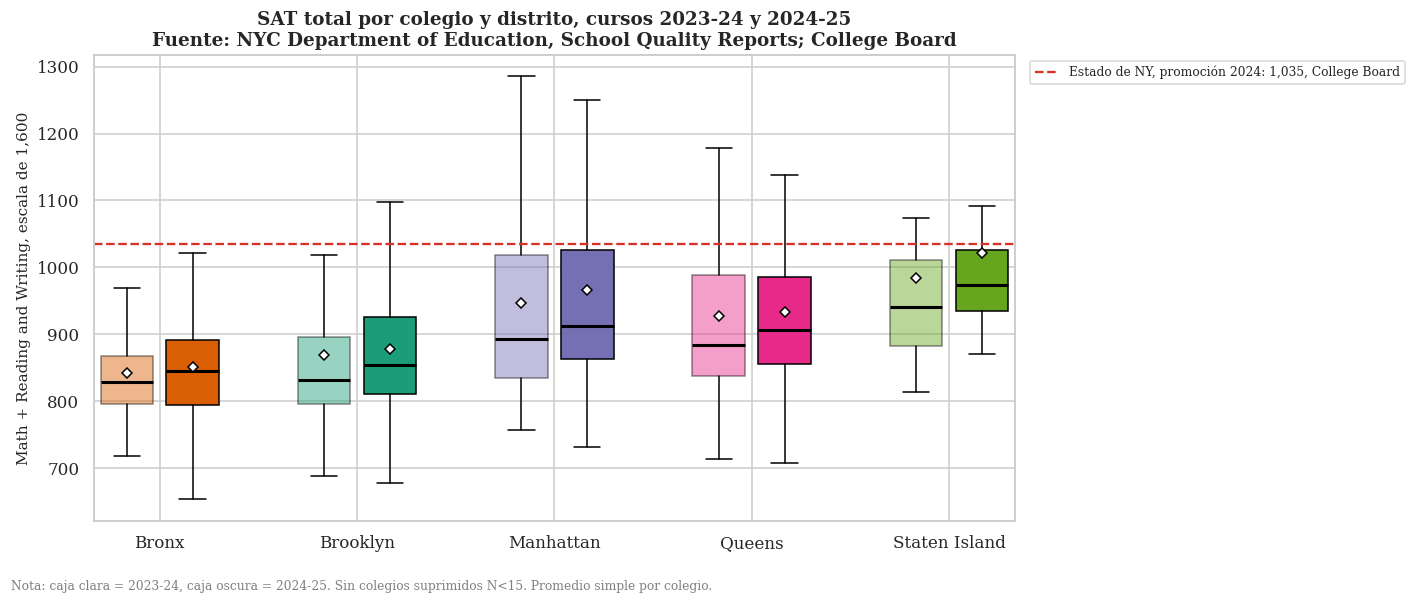

In [66]:
SAT_ESTADO_NY_2024 = 1035
pdf_box_sat = resumen_boxplot_spark(df_sat_limpio, "TOTAL", ["CURSO", "DISTRITO"])
estadisticas, colores, posiciones = [], [], []
for i, distrito in enumerate(ORDEN_BORO):
    for j, (curso, alfa) in enumerate([("2023-24", 0.45), ("2024-25", 1.0)]):
        fila = pdf_box_sat[(pdf_box_sat["DISTRITO"] == distrito) & (pdf_box_sat["CURSO"] == curso)]
        if len(fila):
            estadisticas.append(a_bxp(fila.iloc[0], curso))
            colores.append((PALETA_BORO[distrito], alfa))
            posiciones.append(i * 3 + j)
fig, ax = plt.subplots(figsize=(13, 5.5))
cajas = ax.bxp(estadisticas, positions=posiciones, showfliers=False, showmeans=True, patch_artist=True, widths=0.8,
               medianprops=dict(color="black", lw=2),
               meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=5))
for caja_bxp, (color, alfa) in zip(cajas["boxes"], colores):
    caja_bxp.set_facecolor(color)
    caja_bxp.set_alpha(alfa)
ax.axhline(SAT_ESTADO_NY_2024, color="#d73027", linestyle="--", label="Estado de NY, promoción 2024: 1,035, College Board")
ax.set_xticks([i * 3 + 0.5 for i in range(len(ORDEN_BORO))])
ax.set_xticklabels([nombre_boro(d) for d in ORDEN_BORO])
ax.set(ylabel="Math + Reading and Writing, escala de 1,600",
       title="SAT total por colegio y distrito, cursos 2023-24 y 2024-25\nFuente: NYC Department of Education, School Quality Reports; College Board")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
nota_figura(fig, "Nota: caja clara = 2023-24, caja oscura = 2024-25. Sin colegios suprimidos N<15. Promedio simple por colegio.")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

**Análisis:** La mediana de los colegios está por debajo de la media del estado de Nueva York, 1,035 puntos, en todos los distritos y en los dos cursos. Solo una parte de los colegios de Manhattan, Queens y Staten Island supera esa referencia. Manhattan tiene la mayor dispersión: hay colegios por encima de 1,200 y otros por debajo de 750. Hay que recordar que la media del estado es por estudiante y este promedio es por colegio, así que la comparación es de contexto.

### 7.4 Acceso digital: centros y computadores públicos

Se usan los centros del año más reciente del archivo. Se cuentan los centros, los que tienen estado abierto y los computadores reportados, y se calculan centros y computadores por cada 100,000 habitantes. Los centros con un distrito que no es uno de los cinco, como los programas de toda la ciudad, cuentan en la ciudad pero no en un distrito.

In [67]:
pdf_centros_dist = (df_centros.groupBy(F.coalesce(F.col("DISTRITO"), F.lit("NO ESPECIFICADO")).alias("DISTRITO"))
                    .agg(F.count("*").alias("CENTROS"), F.sum("ABIERTO").alias("ABIERTOS"),
                         F.sum("COMPUTADORES").alias("COMPUTADORES"),
                         F.count(F.when(F.col("COMPUTADORES") > 0, 1)).alias("CON_COMPUTADORES"),
                         F.count(F.when(F.col("PUMA").isNotNull(), 1)).alias("CON_PUMA"))
                    .toPandas().set_index("DISTRITO"))
pdf_centros_dist = pdf_centros_dist.reindex([d for d in ORDEN_BORO + ["NO ESPECIFICADO"] if d in pdf_centros_dist.index])
pdf_centros_dist.loc["CIUDAD"] = pdf_centros_dist.sum()
pob_centros = pd.Series({d: (POB_CIUDAD if d == "CIUDAD" else POB_DISTRITO.get(d, np.nan)) for d in pdf_centros_dist.index})
pdf_centros_dist["CENTROS_100K"] = pdf_centros_dist["CENTROS"] / pob_centros * 100000
pdf_centros_dist["COMPUTADORES_100K"] = pdf_centros_dist["COMPUTADORES"] / pob_centros * 100000
pdf_centros_dist["COMPUTADORES_POR_CENTRO"] = pdf_centros_dist["COMPUTADORES"] / pdf_centros_dist["CON_COMPUTADORES"].replace(0, np.nan)
mostrar_tabla(pdf_centros_dist.reset_index().assign(DISTRITO=lambda d: d["DISTRITO"].map(nombre_boro)).rename(columns={
    "DISTRITO": "Distrito", "CENTROS": "Centros", "ABIERTOS": "Con estado abierto", "COMPUTADORES": "Computadores",
    "CON_COMPUTADORES": "Centros con computadores", "CON_PUMA": "Centros con PUMA",
    "CENTROS_100K": "Centros por 100,000 hab.", "COMPUTADORES_100K": "Computadores por 100,000 hab.",
    "COMPUTADORES_POR_CENTRO": "Computadores por centro con dato"}),
    titulo=f"Centros públicos de computadores por distrito, {ANIO_CENTROS}", decimales=2)

Distrito,Centros,Con estado abierto,Computadores,Centros con computadores,Centros con PUMA,"Centros por 100,000 hab.","Computadores por 100,000 hab.",Computadores por centro con dato
Bronx,96,91,"1,168",66,96,6.93,84.29,17.70
Brooklyn,156,142,"1,364",106,156,5.96,52.10,12.87
Manhattan,117,106,"1,702",89,117,7.05,102.54,19.12
Queens,116,105,"1,452",96,116,5.01,62.68,15.12
Staten Island,26,23,349,19,26,5.22,70.05,18.37
No Especificado,4,4,24,3,1,,,8.00
Ciudad,515,471,"6,059",379,512,6.07,71.47,15.99


**Análisis:** En 2026 hay 515 centros públicos de computadores en la ciudad, 471 con estado abierto, y al menos 6,059 computadores. Eso equivale a 6.07 centros y 71.47 computadores por cada 100,000 habitantes. Manhattan tiene la mayor oferta, con 102.54 computadores por cada 100,000 habitantes, seguido del Bronx, con 84.29. Brooklyn tiene más centros que nadie, 156, pero la menor oferta por habitante, 52.10 computadores. Hay 136 centros sin dato de computadores, así que estas cifras son un mínimo.

Por PUMA, se parte de las 55 PUMAs de PUMS para que las que no tienen ningún centro queden con cero y no desaparezcan del análisis.

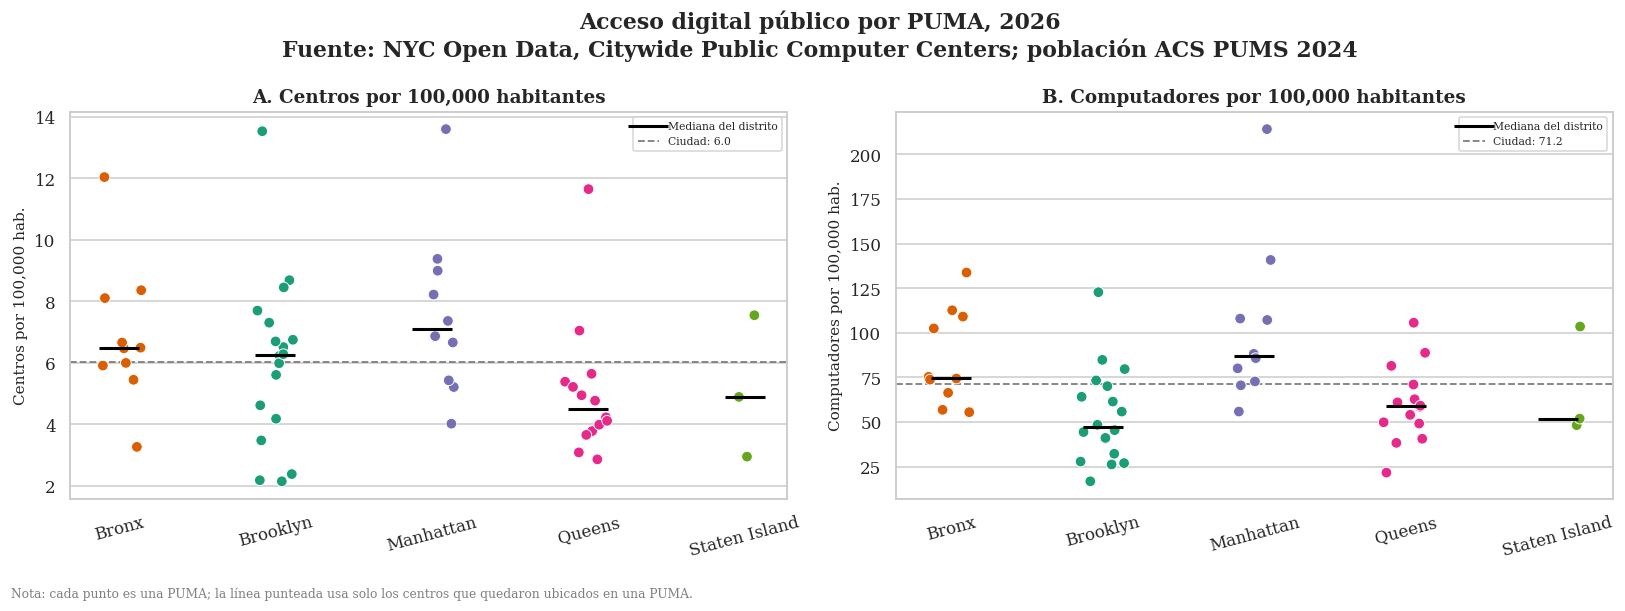

PUMAs sin ningún centro: 0 de 55


In [68]:
pdf_centros_puma = (df_centros.filter(F.col("PUMA").isNotNull()).groupBy("PUMA")
                    .agg(F.count("*").alias("CENTROS"), F.sum("COMPUTADORES").alias("COMPUTADORES")).toPandas())
pdf_centros_puma = (pdf_pums_puma[["PUMA", "DISTRITO", "POBLACION"]].merge(pdf_centros_puma, on="PUMA", how="left")
                    .fillna({"CENTROS": 0, "COMPUTADORES": 0}))
pdf_centros_puma["CENTROS_100K"] = pdf_centros_puma["CENTROS"] / pdf_centros_puma["POBLACION"] * 100000
pdf_centros_puma["COMPUTADORES_100K"] = pdf_centros_puma["COMPUTADORES"] / pdf_centros_puma["POBLACION"] * 100000
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
strip_por_distrito(axes[0], pdf_centros_puma, "CENTROS_100K", "A. Centros por 100,000 habitantes", "Centros por 100,000 hab.",
                   pdf_centros_puma["CENTROS"].sum() / pdf_centros_puma["POBLACION"].sum() * 100000)
strip_por_distrito(axes[1], pdf_centros_puma, "COMPUTADORES_100K", "B. Computadores por 100,000 habitantes",
                   "Computadores por 100,000 hab.",
                   pdf_centros_puma["COMPUTADORES"].sum() / pdf_centros_puma["POBLACION"].sum() * 100000)
fig.suptitle(f"Acceso digital público por PUMA, {ANIO_CENTROS}\nFuente: NYC Open Data, Citywide Public Computer Centers; población ACS PUMS 2024",
             fontweight="bold")
nota_figura(fig, "Nota: cada punto es una PUMA; la línea punteada usa solo los centros que quedaron ubicados en una PUMA.")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()
print(f"PUMAs sin ningún centro: {int((pdf_centros_puma['CENTROS'] == 0).sum())} de {len(pdf_centros_puma)}")

**Análisis:** Las 55 PUMAs tienen al menos un centro, pero la oferta por habitante cambia mucho: de 2.14 a 13.60 centros y de 16.72 a 214.21 computadores por cada 100,000 habitantes. La PUMA con más computadores está en Manhattan. Casi todas las PUMAs de Brooklyn están por debajo de la ciudad en computadores por habitante, lo que lo señala como el distrito con más brecha de acceso digital público.

### 7.5 Espacio público: parques y recreación activa

Primero se reportan todos los tipos de espacio que trae la base, con su número y su área, incluidos los parkways y las franjas viales. No se excluye ningún tipo sin mostrar cuánto pesa.

In [69]:
pdf_tipos_parque = (df_parques.groupBy(F.coalesce(F.col("TYPE_CATEGORY"), F.lit("VACÍO")).alias("TIPO"))
                    .agg(F.count("*").alias("ESPACIOS"), F.sum("ACRES").alias("ACRES"),
                         F.sum("ACTIVE_ACRES").alias("ACRES_ACTIVOS"), F.sum("PASSIVE_ACRES").alias("ACRES_PASIVOS"))
                    .toPandas().sort_values("ACRES", ascending=False))
pdf_tipos_parque["ACRES_PCT"] = pdf_tipos_parque["ACRES"] / pdf_tipos_parque["ACRES"].sum() * 100
pdf_tipos_parque["ACTIVOS_PCT"] = pdf_tipos_parque["ACRES_ACTIVOS"] / pdf_tipos_parque["ACRES"] * 100
mostrar_tabla(pdf_tipos_parque.rename(columns={
    "TIPO": "Tipo de espacio", "ESPACIOS": "Espacios", "ACRES": "Acres", "ACRES_ACTIVOS": "Acres activos",
    "ACRES_PASIVOS": "Acres pasivos", "ACRES_PCT": "Del total de acres %", "ACTIVOS_PCT": "Acres activos del tipo %"}),
    titulo="Tipos de espacio público abierto, NYC Parks 2026", decimales=1, pct=["Del total de acres %", "Acres activos del tipo %"])

Tipo de espacio,Espacios,Acres,Acres activos,Acres pasivos,Del total de acres %,Acres activos del tipo %
Flagship Park,15,"9,934.5","1,772.8","8,159.8",36.7%,17.8%
Community Park,112,"6,468.8","1,584.8","4,884.1",23.9%,24.5%
Nature Area,89,"4,130.9",176.8,"3,954.1",15.3%,4.3%
Waterfront Facility,21,"1,662.7",285.2,"1,377.5",6.1%,17.2%
Neighborhood Park,288,"1,455.6",375.8,"1,080.1",5.4%,25.8%
Parkway,23,"1,033.5",62.5,971.0,3.8%,6.0%
Recreational Field/Courts,74,650.0,346.9,303.2,2.4%,53.4%
Managed Sites,14,474.0,394.1,80.0,1.8%,83.1%
Jointly Operated Playground,262,394.4,255.6,139.0,1.5%,64.8%
Playground,249,233.6,139.0,94.9,0.9%,59.5%


**Análisis:** Con una fila por parque quedan 1,811 espacios y 27,041 acres. Pocos parques grandes concentran la mayor parte del área: los 15 parques insignia, Flagship Park, suman el 36.7% de los acres y los parques comunitarios el 23.9%. Solo el 20.6% de todos los acres es de recreación activa; los Managed Sites, los patios escolares abiertos, los playgrounds y las canchas tienen la mayor parte activa, entre 53% y 83%, mientras que las áreas naturales casi no tienen, 4.3%. Los parkways y las franjas viales son solo el 3.8% del área, por eso dejarlos o quitarlos casi no cambia los resultados.

Después se calcula, por distrito, el indicador del manual CEQR: acres de espacio abierto y acres de recreación activa por cada 1,000 habitantes, frente a la meta de la ciudad de 2.5 acres totales y 2.0 activos. El distrito sale del campo `borough` del parque, en mayúsculas. Como prueba de sensibilidad se repite el total sin los parkways.

In [70]:
META_CEQR_TOTAL, META_CEQR_ACTIVA = 2.5, 2.0
es_parkway = F.coalesce(F.upper(F.trim(F.col("TYPE_CATEGORY"))) == "PARKWAY", F.lit(False))
pdf_parques_dist = (df_parques.groupBy("DISTRITO")
                    .agg(F.count("*").alias("ESPACIOS"), F.sum("ACRES").alias("ACRES"),
                         F.sum("ACTIVE_ACRES").alias("ACRES_ACTIVOS"), F.sum("PASSIVE_ACRES").alias("ACRES_PASIVOS"),
                         F.sum(F.when(~es_parkway, F.col("ACRES"))).alias("ACRES_SIN_PARKWAY"))
                    .toPandas().set_index("DISTRITO"))
otros_distritos = [d for d in pdf_parques_dist.index if d not in ORDEN_BORO]
if otros_distritos:
    print("Valores de borough que no son uno de los cinco distritos:", otros_distritos)
pdf_parques_dist = pdf_parques_dist.reindex(ORDEN_BORO)
pdf_parques_dist.loc["CIUDAD"] = pdf_parques_dist.sum()
pob_parques = pd.Series({d: (POB_CIUDAD if d == "CIUDAD" else POB_DISTRITO.get(d, np.nan)) for d in pdf_parques_dist.index})
for columna in ["ACRES", "ACRES_ACTIVOS", "ACRES_PASIVOS", "ACRES_SIN_PARKWAY"]:
    pdf_parques_dist[columna + "_1000"] = pdf_parques_dist[columna] / pob_parques * 1000
pdf_parques_dist["CUMPLE_META_TOTAL"] = np.where(pdf_parques_dist["ACRES_1000"] >= META_CEQR_TOTAL, "Sí", "No")
pdf_parques_dist["CUMPLE_META_ACTIVA"] = np.where(pdf_parques_dist["ACRES_ACTIVOS_1000"] >= META_CEQR_ACTIVA, "Sí", "No")
mostrar_tabla(pdf_parques_dist.reset_index().assign(DISTRITO=lambda d: d["DISTRITO"].map(nombre_boro))[[
    "DISTRITO", "ESPACIOS", "ACRES", "ACRES_ACTIVOS", "ACRES_1000", "ACRES_ACTIVOS_1000", "ACRES_PASIVOS_1000",
    "ACRES_SIN_PARKWAY_1000", "CUMPLE_META_TOTAL", "CUMPLE_META_ACTIVA"]].rename(columns={
    "DISTRITO": "Distrito", "ESPACIOS": "Espacios", "ACRES": "Acres", "ACRES_ACTIVOS": "Acres activos",
    "ACRES_1000": "Acres por 1,000 hab.", "ACRES_ACTIVOS_1000": "Acres activos por 1,000 hab.",
    "ACRES_PASIVOS_1000": "Acres pasivos por 1,000 hab.", "ACRES_SIN_PARKWAY_1000": "Acres sin parkways por 1,000 hab.",
    "CUMPLE_META_TOTAL": "Cumple 2.5 total", "CUMPLE_META_ACTIVA": "Cumple 2.0 activos"}),
    titulo="Espacio público por cada 1,000 habitantes según el manual CEQR, parques 2026 y población 2024", decimales=2)

Distrito,Espacios,Acres,Acres activos,"Acres por 1,000 hab.","Acres activos por 1,000 hab.","Acres pasivos por 1,000 hab.","Acres sin parkways por 1,000 hab.",Cumple 2.5 total,Cumple 2.0 activos
Bronx,314,"6,281.61","1,346.07",4.53,0.97,3.56,4.42,Sí,No
Brooklyn,533,"4,113.11","1,408.21",1.57,0.54,1.03,1.44,No,No
Manhattan,303,"2,857.66",598.45,1.72,0.36,1.36,1.69,No,No
Queens,485,"6,543.83","1,396.03",2.82,0.60,2.22,2.73,Sí,No
Staten Island,176,"7,245.25",817.16,14.54,1.64,12.90,14.03,Sí,No
Ciudad,"1,811","27,041.46","5,565.92",3.19,0.66,2.53,3.07,Sí,No


**Análisis:** La ciudad tiene 3.19 acres de espacio abierto por cada 1,000 habitantes, por encima de la meta CEQR de 2.5, pero solo 0.66 acres de recreación activa, un tercio de la meta de 2.0. Ningún distrito cumple la meta activa: Staten Island es el más cercano, con 1.64, y Manhattan el más lejano, con 0.36, seguido de Brooklyn, con 0.54. En espacio total, Staten Island, el Bronx y Queens cumplen la meta, mientras que Brooklyn, con 1.57, y Manhattan, con 1.72, quedan por debajo. Quitar los parkways casi no cambia nada: el total de la ciudad pasa de 3.19 a 3.07.

Por PUMA, cada parque cuenta completo en la PUMA de su punto representativo. La escala vertical es simétrica logarítmica porque unas pocas PUMAs con parques muy grandes tienen valores mucho mayores que el resto. Las líneas marcan la meta CEQR.

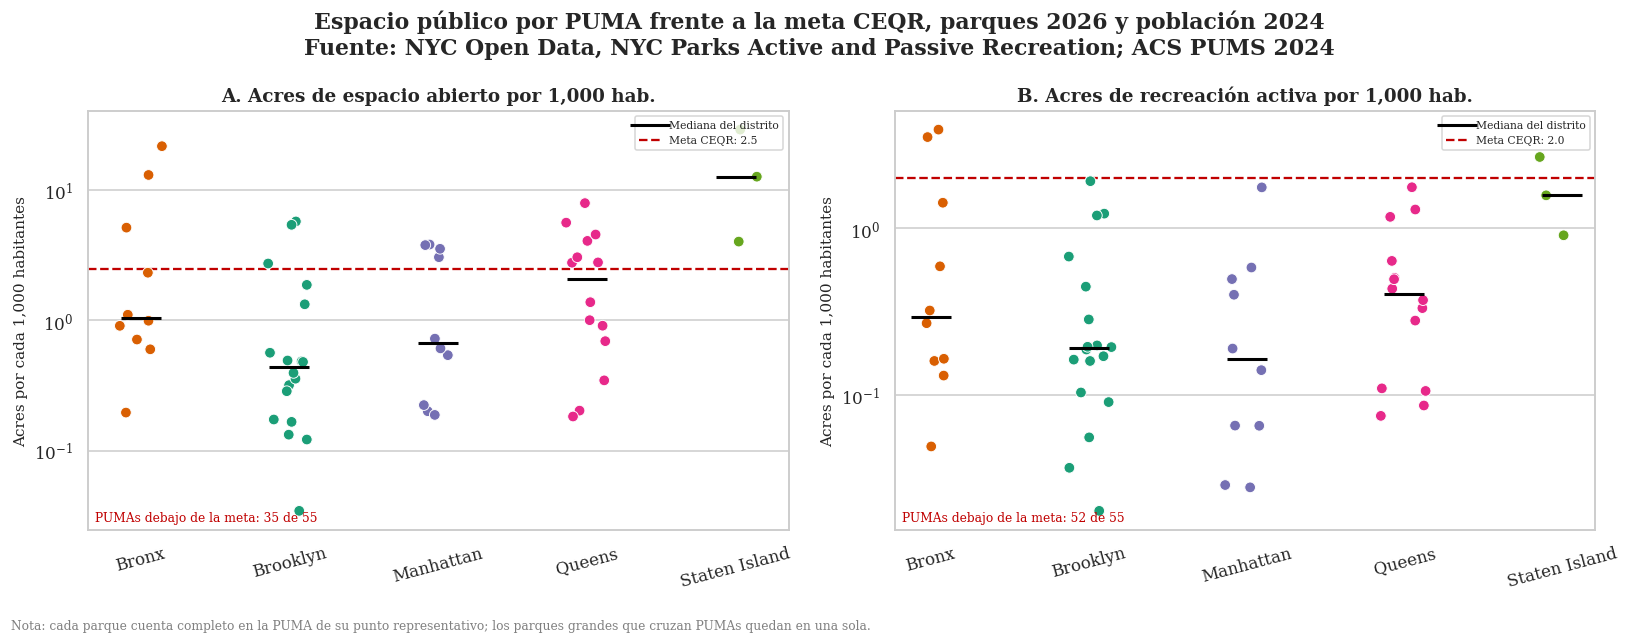

In [71]:
pdf_parques_puma = (df_parques.filter(F.col("PUMA").isNotNull()).groupBy("PUMA")
                    .agg(F.count("*").alias("ESPACIOS"), F.sum("ACRES").alias("ACRES"),
                         F.sum("ACTIVE_ACRES").alias("ACRES_ACTIVOS")).toPandas())
pdf_parques_puma = (pdf_pums_puma[["PUMA", "DISTRITO", "POBLACION"]].merge(pdf_parques_puma, on="PUMA", how="left")
                    .fillna({"ESPACIOS": 0, "ACRES": 0, "ACRES_ACTIVOS": 0}))
pdf_parques_puma["ACRES_1000"] = pdf_parques_puma["ACRES"] / pdf_parques_puma["POBLACION"] * 1000
pdf_parques_puma["ACRES_ACTIVOS_1000"] = pdf_parques_puma["ACRES_ACTIVOS"] / pdf_parques_puma["POBLACION"] * 1000
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, columna, titulo, meta in [(axes[0], "ACRES_1000", "A. Acres de espacio abierto por 1,000 hab.", META_CEQR_TOTAL),
                                  (axes[1], "ACRES_ACTIVOS_1000", "B. Acres de recreación activa por 1,000 hab.", META_CEQR_ACTIVA)]:
    strip_por_distrito(ax, pdf_parques_puma, columna, titulo, "Acres por cada 1,000 habitantes", escala="symlog")
    ax.axhline(meta, color="#c00000", linestyle="--", lw=1.5, label=f"Meta CEQR: {meta}")
    ax.legend(fontsize=7, loc="upper right")
    debajo = int((pdf_parques_puma[columna] < meta).sum())
    ax.text(0.01, 0.02, f"PUMAs debajo de la meta: {debajo} de {len(pdf_parques_puma)}", transform=ax.transAxes,
            fontsize=8, color="#c00000")
fig.suptitle("Espacio público por PUMA frente a la meta CEQR, parques 2026 y población 2024\n"
             "Fuente: NYC Open Data, NYC Parks Active and Passive Recreation; ACS PUMS 2024", fontweight="bold")
nota_figura(fig, "Nota: cada parque cuenta completo en la PUMA de su punto representativo; los parques grandes que cruzan PUMAs quedan en una sola.")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

**Análisis:** Por PUMA el déficit es más claro que por distrito: 35 de las 55 PUMAs están por debajo de la meta de 2.5 acres totales y 52 de 55 por debajo de la meta de 2.0 acres activos por cada 1,000 habitantes. Solo tres PUMAs cumplen la meta activa: dos del Bronx, con los parques Pelham Bay y Van Cortlandt, y una de Staten Island. Las medianas de Brooklyn y de Manhattan están cerca de 0.2 acres activos, diez veces por debajo de la meta. La recreación activa es el punto más débil del espacio público de la ciudad.

### 7.6 Cruces por distrito, 2025

Se juntan en una tabla de cinco filas los indicadores de 2025, el año completo más reciente: arrestos, choques con víctimas y heridos por cada 100,000 habitantes, las condiciones sociales de PUMS 2024, el SAT 2024-25, el acceso digital y el espacio público. Después se calcula la correlación de Pearson entre ellos. **Advertencia:** con n = 5 una correlación alta puede salir por azar o por un solo distrito, como Manhattan con su población flotante; son pistas para la entrega final, no pruebas.

In [72]:
pdf_arr_2025_dist = (df_arrestos.filter((F.col("ANIO") == ANIO_COMPLETO) & F.col("DISTRITO").isNotNull())
                     .groupBy("DISTRITO").agg(F.count("*").alias("ARRESTOS")).toPandas())
choques_2025_dist = (pdf_grav[(pdf_grav["ANIO"] == ANIO_COMPLETO) & pdf_grav["DISTRITO"].isin(ORDEN_BORO)]
                     [["DISTRITO", "CHOQUES_CON_VICTIMAS", "HERIDOS"]])
sat_2025_dist = (pdf_sat_dist[pdf_sat_dist["CURSO"] == "2024-25"][["DISTRITO", "TOTAL"]]
                 .rename(columns={"TOTAL": "SAT_TOTAL"}))
pdf_cruce_distrito = (pdf_pums_distrito[["DISTRITO", "POBLACION", "POBREZA_PCT", "DESEMPLEO_PCT", "DESEMPLEO_16_24_PCT",
                                         "SIN_BACHILLERATO_PCT"]]
    .merge(pdf_arr_2025_dist, on="DISTRITO", how="left", validate="one_to_one")
    .merge(choques_2025_dist, on="DISTRITO", how="left", validate="one_to_one")
    .merge(sat_2025_dist, on="DISTRITO", how="left", validate="one_to_one")
    .merge(pdf_centros_dist.reset_index()[["DISTRITO", "CENTROS_100K", "COMPUTADORES_100K"]], on="DISTRITO", how="left")
    .merge(pdf_parques_dist.reset_index()[["DISTRITO", "ACRES_1000", "ACRES_ACTIVOS_1000"]], on="DISTRITO", how="left"))
pdf_cruce_distrito["ARRESTOS_100K"] = pdf_cruce_distrito["ARRESTOS"] / pdf_cruce_distrito["POBLACION"] * 100000
pdf_cruce_distrito["VICTIMAS_100K"] = pdf_cruce_distrito["CHOQUES_CON_VICTIMAS"] / pdf_cruce_distrito["POBLACION"] * 100000
pdf_cruce_distrito["HERIDOS_100K"] = pdf_cruce_distrito["HERIDOS"] / pdf_cruce_distrito["POBLACION"] * 100000
pdf_cruce_distrito = ordenar_distritos(pdf_cruce_distrito)
NOMBRES_CRUCE = {"ARRESTOS_100K": "Arrestos por 100k", "VICTIMAS_100K": "Choques con víctimas por 100k",
                 "HERIDOS_100K": "Heridos por 100k", "POBREZA_PCT": "Pobreza %", "DESEMPLEO_PCT": "Desempleo %",
                 "DESEMPLEO_16_24_PCT": "Desempleo 16-24 %", "SIN_BACHILLERATO_PCT": "Sin bachillerato %",
                 "SAT_TOTAL": "SAT 2024-25", "CENTROS_100K": "Centros por 100k", "COMPUTADORES_100K": "Computadores por 100k",
                 "ACRES_1000": "Acres por 1,000", "ACRES_ACTIVOS_1000": "Acres activos por 1,000"}
mostrar_tabla(pdf_cruce_distrito.assign(DISTRITO=lambda d: d["DISTRITO"].map(nombre_boro))[["DISTRITO"] + list(NOMBRES_CRUCE)]
              .rename(columns={"DISTRITO": "Distrito", **NOMBRES_CRUCE}),
              titulo=f"Cruce por distrito, eventos de {ANIO_COMPLETO}, PUMS 2024, SAT 2024-25, centros {ANIO_CENTROS} y parques 2026",
              decimales=2)

Distrito,Arrestos por 100k,Choques con víctimas por 100k,Heridos por 100k,Pobreza %,Desempleo %,Desempleo 16-24 %,Sin bachillerato %,SAT 2024-25,Centros por 100k,Computadores por 100k,"Acres por 1,000","Acres activos por 1,000"
Bronx,"4,534.59",422.55,589.62,28.96,10.48,18.57,24.01,850.79,6.93,84.29,4.53,0.97
Brooklyn,"3,051.18",475.35,630.24,19.11,7.13,17.05,15.63,877.94,5.96,52.10,1.57,0.54
Manhattan,"4,003.20",373.70,451.18,16.10,6.40,11.36,10.16,966.12,7.05,102.54,1.72,0.36
Queens,"2,507.45",462.70,622.38,13.58,5.84,13.37,18.11,933.63,5.01,62.68,2.82,0.60
Staten Island,"2,349.66",372.91,513.41,11.19,4.70,17.40,11.46,"1,020.60",5.22,70.05,14.54,1.64


**Análisis:** El Bronx tiene la mayor tasa de arrestos, la mayor pobreza, el mayor desempleo, la mayor proporción de adultos sin bachillerato y el menor SAT de la ciudad. Los choques no siguen ese patrón: Brooklyn y Queens tienen las tasas más altas de choques con víctimas y de heridos, mientras que Manhattan y Staten Island tienen las más bajas. Esto indica que arrestos y choques responden a factores distintos y necesitan estrategias distintas. En espacio público, Staten Island tiene de lejos más acres por habitante, 14.54 por cada 1,000, y Manhattan tiene la menor recreación activa, 0.36.

El mapa de calor muestra la correlación de Pearson entre los indicadores por distrito, de -1 a 1, con n = 5.

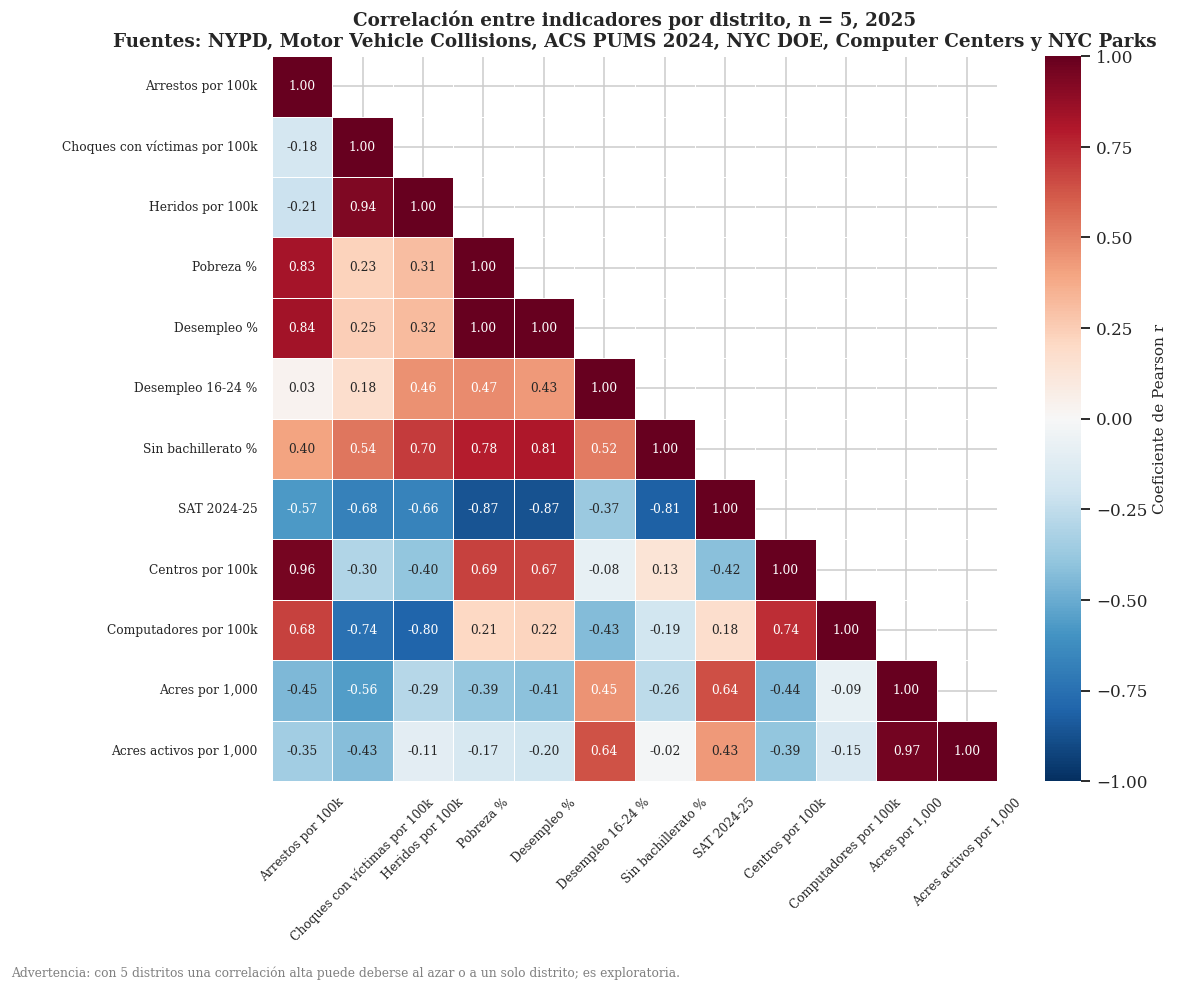

In [73]:
matriz_corr_distrito = pdf_cruce_distrito[list(NOMBRES_CRUCE)].rename(columns=NOMBRES_CRUCE).corr(method="pearson")
mascara = np.triu(np.ones_like(matriz_corr_distrito, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(matriz_corr_distrito, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=0.6, linecolor="white", annot_kws={"fontsize": 8}, cbar_kws={"label": "Coeficiente de Pearson r"}, ax=ax)
ax.set_title(f"Correlación entre indicadores por distrito, n = 5, {ANIO_COMPLETO}\n"
             "Fuentes: NYPD, Motor Vehicle Collisions, ACS PUMS 2024, NYC DOE, Computer Centers y NYC Parks")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
nota_figura(fig, "Advertencia: con 5 distritos una correlación alta puede deberse al azar o a un solo distrito; es exploratoria.")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Análisis:** Con 5 distritos, solo una correlación mayor a 0.88 en valor absoluto es significativa al 5%, así que la mayoría son pistas. Los arrestos se relacionan con la pobreza, r = 0.83, y con el desempleo, r = 0.84, y en sentido contrario con el SAT, r = -0.57. Los choques con víctimas casi no se relacionan con la pobreza, r = 0.23. La correlación de 0.96 entre arrestos y centros por habitante no indica que los centros causen arrestos: los dos son altos en el Bronx y en Manhattan. La pobreza y el SAT tienen r = -0.87: los distritos más pobres tienen peores puntajes. Los acres de parque por habitante van en sentido contrario a los arrestos, r = -0.45, y a los choques con víctimas, r = -0.56, pero con 5 distritos estas relaciones dependen sobre todo de Staten Island.

### 7.7 Cruces por PUMA, 2025

Se arma una tabla de 55 filas, una por PUMA, con los mismos indicadores excepto el SAT, que no tiene coordenadas, y con los peatones y ciclistas lesionados de Person. Las PUMAs sin eventos quedan en cero. Los registros sin PUMA no entran en esta tabla; su peso se reportó en la sección 4.9. Primero se muestra la estadística descriptiva de cada indicador.

In [74]:
pdf_choques_puma = (df_choques.filter((F.col("ANIO") == ANIO_COMPLETO) & F.col("PUMA").isNotNull()).groupBy("PUMA")
                    .agg(F.count("*").alias("CHOQUES"), F.sum("CON_VICTIMAS").alias("CHOQUES_CON_VICTIMAS"),
                         F.sum("NUMBER_OF_PERSONS_INJURED").alias("HERIDOS")).toPandas())
pdf_vulnerables_puma = (df_personas.filter((F.col("ANIO") == ANIO_COMPLETO) & F.col("PUMA").isNotNull()
                                           & F.col("TIPO_PERSONA").isin("PEATÓN", "CICLISTA")
                                           & F.col("GRAVEDAD").isin("HERIDO", "MUERTO"))
                        .groupBy("PUMA").agg(F.count("*").alias("PEATONES_CICLISTAS_LESIONADOS")).toPandas())
pdf_cruce_puma = (pdf_pums_puma[["PUMA", "DISTRITO", "POBLACION", "POBREZA_PCT", "DESEMPLEO_PCT", "DESEMPLEO_16_24_PCT",
                                 "SIN_BACHILLERATO_PCT", "JOVENES_15_24_PCT"]]
    .merge(pdf_arr_puma[["PUMA", "ARRESTOS"]], on="PUMA", how="left")
    .merge(pdf_choques_puma, on="PUMA", how="left")
    .merge(pdf_vulnerables_puma, on="PUMA", how="left")
    .merge(pdf_centros_puma[["PUMA", "CENTROS", "COMPUTADORES", "CENTROS_100K", "COMPUTADORES_100K"]], on="PUMA", how="left")
    .merge(pdf_parques_puma[["PUMA", "ACRES", "ACRES_ACTIVOS", "ACRES_1000", "ACRES_ACTIVOS_1000"]], on="PUMA", how="left"))
conteos = ["ARRESTOS", "CHOQUES", "CHOQUES_CON_VICTIMAS", "HERIDOS", "PEATONES_CICLISTAS_LESIONADOS"]
pdf_cruce_puma[conteos] = pdf_cruce_puma[conteos].fillna(0)
pdf_cruce_puma["ARRESTOS_100K"] = pdf_cruce_puma["ARRESTOS"] / pdf_cruce_puma["POBLACION"] * 100000
pdf_cruce_puma["VICTIMAS_100K"] = pdf_cruce_puma["CHOQUES_CON_VICTIMAS"] / pdf_cruce_puma["POBLACION"] * 100000
pdf_cruce_puma["HERIDOS_100K"] = pdf_cruce_puma["HERIDOS"] / pdf_cruce_puma["POBLACION"] * 100000
pdf_cruce_puma["VULNERABLES_100K"] = pdf_cruce_puma["PEATONES_CICLISTAS_LESIONADOS"] / pdf_cruce_puma["POBLACION"] * 100000
NOMBRES_PUMA = {k: v for k, v in NOMBRES_CRUCE.items() if k != "SAT_TOTAL"}
NOMBRES_PUMA["VULNERABLES_100K"] = "Peatones y ciclistas lesionados por 100k"
descriptiva = pdf_cruce_puma[list(NOMBRES_PUMA)].describe().T
descriptiva = descriptiva.rename(columns={"count": "n", "mean": "Media", "std": "Desviación", "min": "Mínimo",
                                          "25%": "Q1", "50%": "Mediana", "75%": "Q3", "max": "Máximo"})
descriptiva.index = [NOMBRES_PUMA[i] for i in descriptiva.index]
mostrar_tabla(descriptiva.reset_index().rename(columns={"index": "Indicador"}),
              titulo=f"Estadística descriptiva de los indicadores por PUMA, n = {len(pdf_cruce_puma)}, {ANIO_COMPLETO}",
              decimales=2)

Indicador,n,Media,Desviación,Mínimo,Q1,Mediana,Q3,Máximo
Arrestos por 100k,55,"3,350.79","1,833.53",690.31,"1,874.63","3,068.89","4,397.18","9,841.09"
Choques con víctimas por 100k,55,428.24,119.89,189.37,353.78,407.99,493.63,796.79
Heridos por 100k,55,569.47,181.21,219.33,464.34,546.67,675.67,"1,182.86"
Pobreza %,55,18.40,8.93,5.12,11.08,16.33,22.66,43.77
Desempleo %,55,7.31,3.07,2.34,5.18,6.86,8.48,15.87
Desempleo 16-24 %,55,15.59,7.35,1.60,10.78,15.15,19.64,31.86
Sin bachillerato %,55,16.72,7.83,1.77,11.84,15.29,22.12,31.22
Centros por 100k,55,6.16,2.60,2.14,4.20,5.99,7.34,13.60
Computadores por 100k,55,70.73,34.56,16.72,48.76,64.11,85.30,214.21
"Acres por 1,000",55,3.03,5.28,0.06,0.35,0.91,3.67,29.26


**Análisis:** Por PUMA las diferencias son mucho mayores que por distrito. Los arrestos van de 690 a 9,841 por cada 100,000 habitantes, con una media de 3,350.79 y una desviación de 1,833.53. Los choques con víctimas varían menos, de 189 a 797, cerca de 4 veces. La pobreza va de 5.12% a 43.77% y los peatones y ciclistas lesionados de 46 a 435 por cada 100,000 habitantes. Los acres de parque por cada 1,000 habitantes son el indicador más disperso: van de 0.06 a 29.26, con una mediana de 0.91 y una media de 3.03, por unas pocas PUMAs con parques muy grandes; los acres activos van de 0.04 a 3.89, con una mediana de 0.28. Como la media es mayor que la mediana en casi todos los indicadores, hay pocas PUMAs con valores muy altos que jalan el promedio.

Las correlaciones por PUMA se calculan de dos formas: Pearson, que mide relación lineal, y Spearman, que usa rangos y es menos sensible a las PUMAs extremas. Con n = 55 hay más evidencia que por distrito, pero siguen siendo asociaciones y no causas.

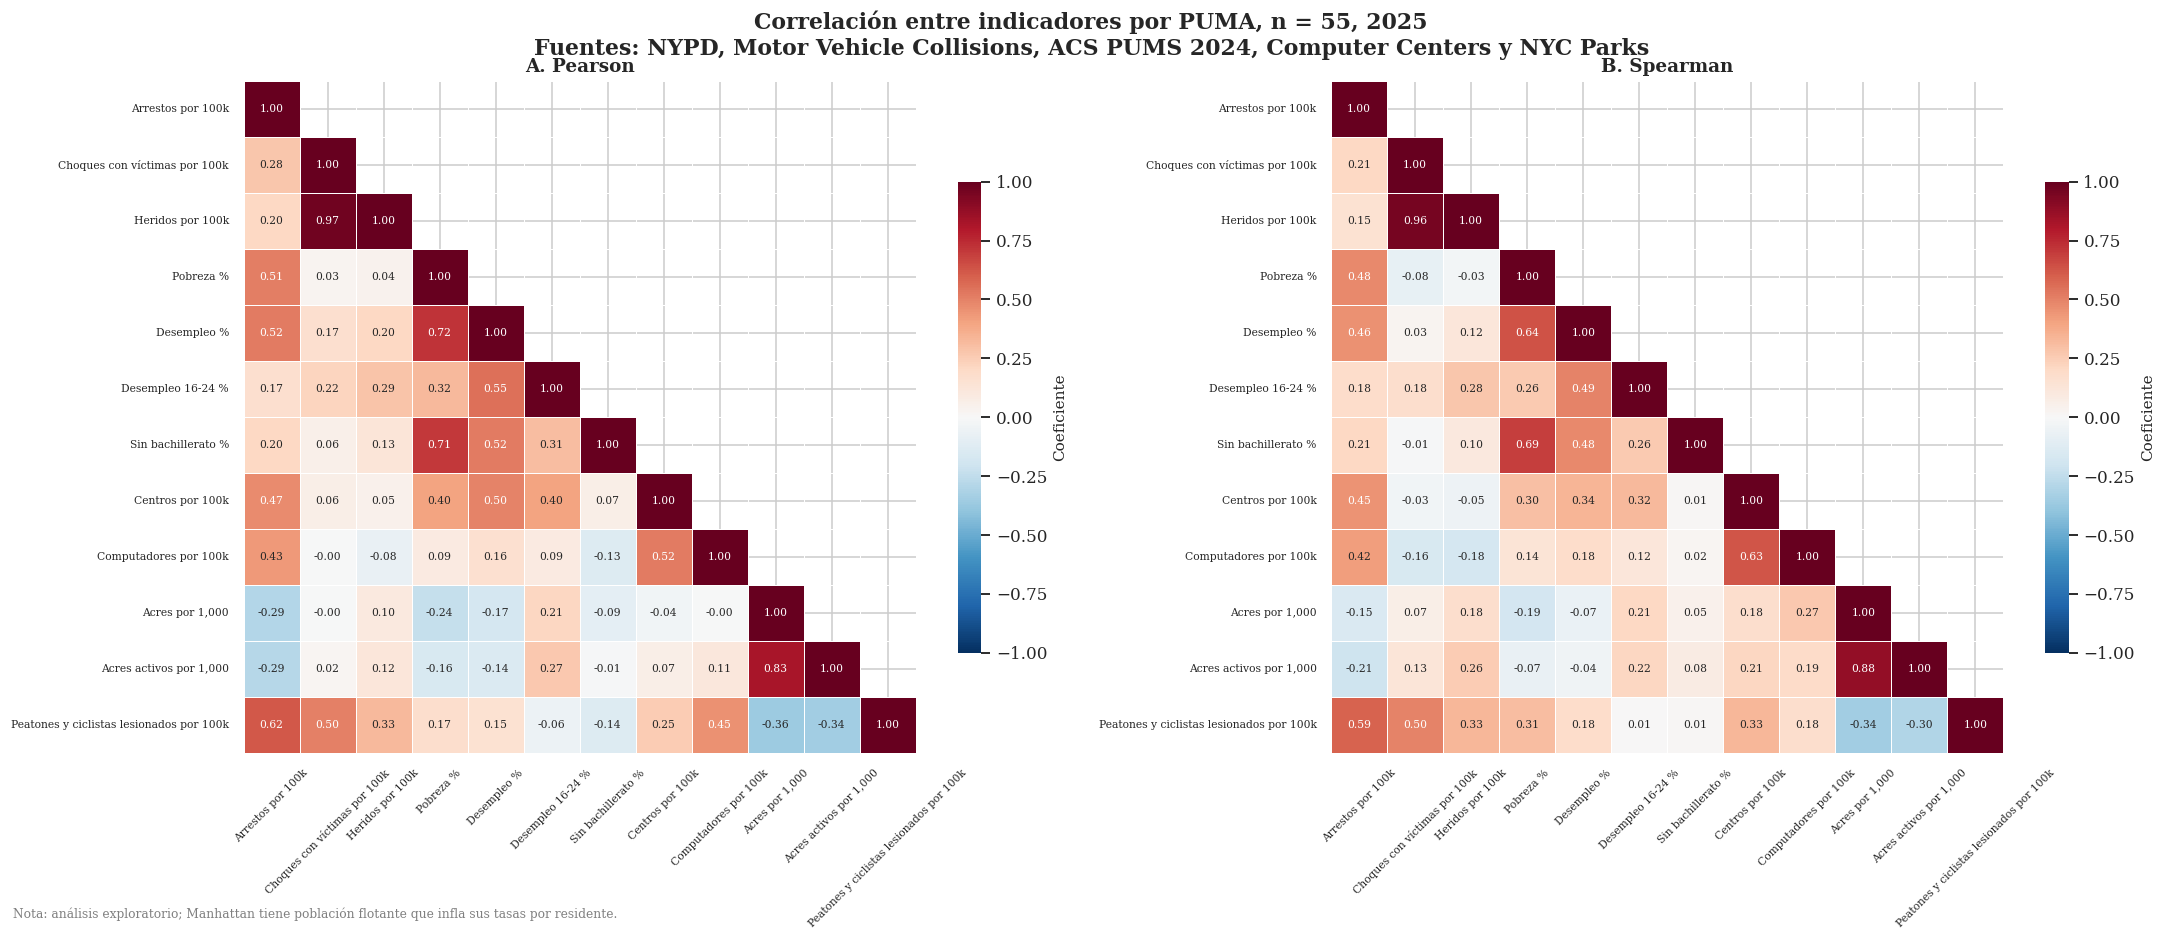

In [75]:
datos_corr = pdf_cruce_puma[list(NOMBRES_PUMA)].rename(columns=NOMBRES_PUMA)
fig, axes = plt.subplots(1, 2, figsize=(20, 8.5))
for ax, metodo, titulo in [(axes[0], "pearson", "A. Pearson"), (axes[1], "spearman", "B. Spearman")]:
    matriz = datos_corr.corr(method=metodo)
    sns.heatmap(matriz, mask=np.triu(np.ones_like(matriz, dtype=bool), k=1), annot=True, fmt=".2f", cmap="RdBu_r",
                vmin=-1, vmax=1, square=True, linewidths=0.5, linecolor="white", annot_kws={"fontsize": 7},
                cbar_kws={"label": "Coeficiente", "shrink": 0.7}, ax=ax)
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle(f"Correlación entre indicadores por PUMA, n = {len(pdf_cruce_puma)}, {ANIO_COMPLETO}\n"
             "Fuentes: NYPD, Motor Vehicle Collisions, ACS PUMS 2024, Computer Centers y NYC Parks", fontweight="bold")
nota_figura(fig, "Nota: análisis exploratorio; Manhattan tiene población flotante que infla sus tasas por residente.")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Análisis:** Con 55 PUMAs, una correlación mayor a 0.27 en valor absoluto es significativa al 5%. Los arrestos se relacionan con la pobreza, r = 0.51, y con el desempleo, r = 0.52, y Spearman da valores parecidos, 0.48 y 0.46, así que la relación no depende de unas pocas PUMAs extremas. Los choques con víctimas no se relacionan con la pobreza, r = 0.03. Los peatones y ciclistas lesionados sí se relacionan con los arrestos, r = 0.62, y en sentido contrario con los acres de parque, r = -0.36. Los acres de parque se relacionan débilmente y en sentido contrario con los arrestos, r = -0.29, y Spearman da valores parecidos para los acres y los lesionados, -0.34. Son asociaciones y no causas.

Los diagramas de dispersión muestran cuatro relaciones clave por PUMA, con un color por distrito. En cada panel se escribe el r de Pearson con todas las PUMAs y sin las de Manhattan, para ver cuánto pesa la población flotante.

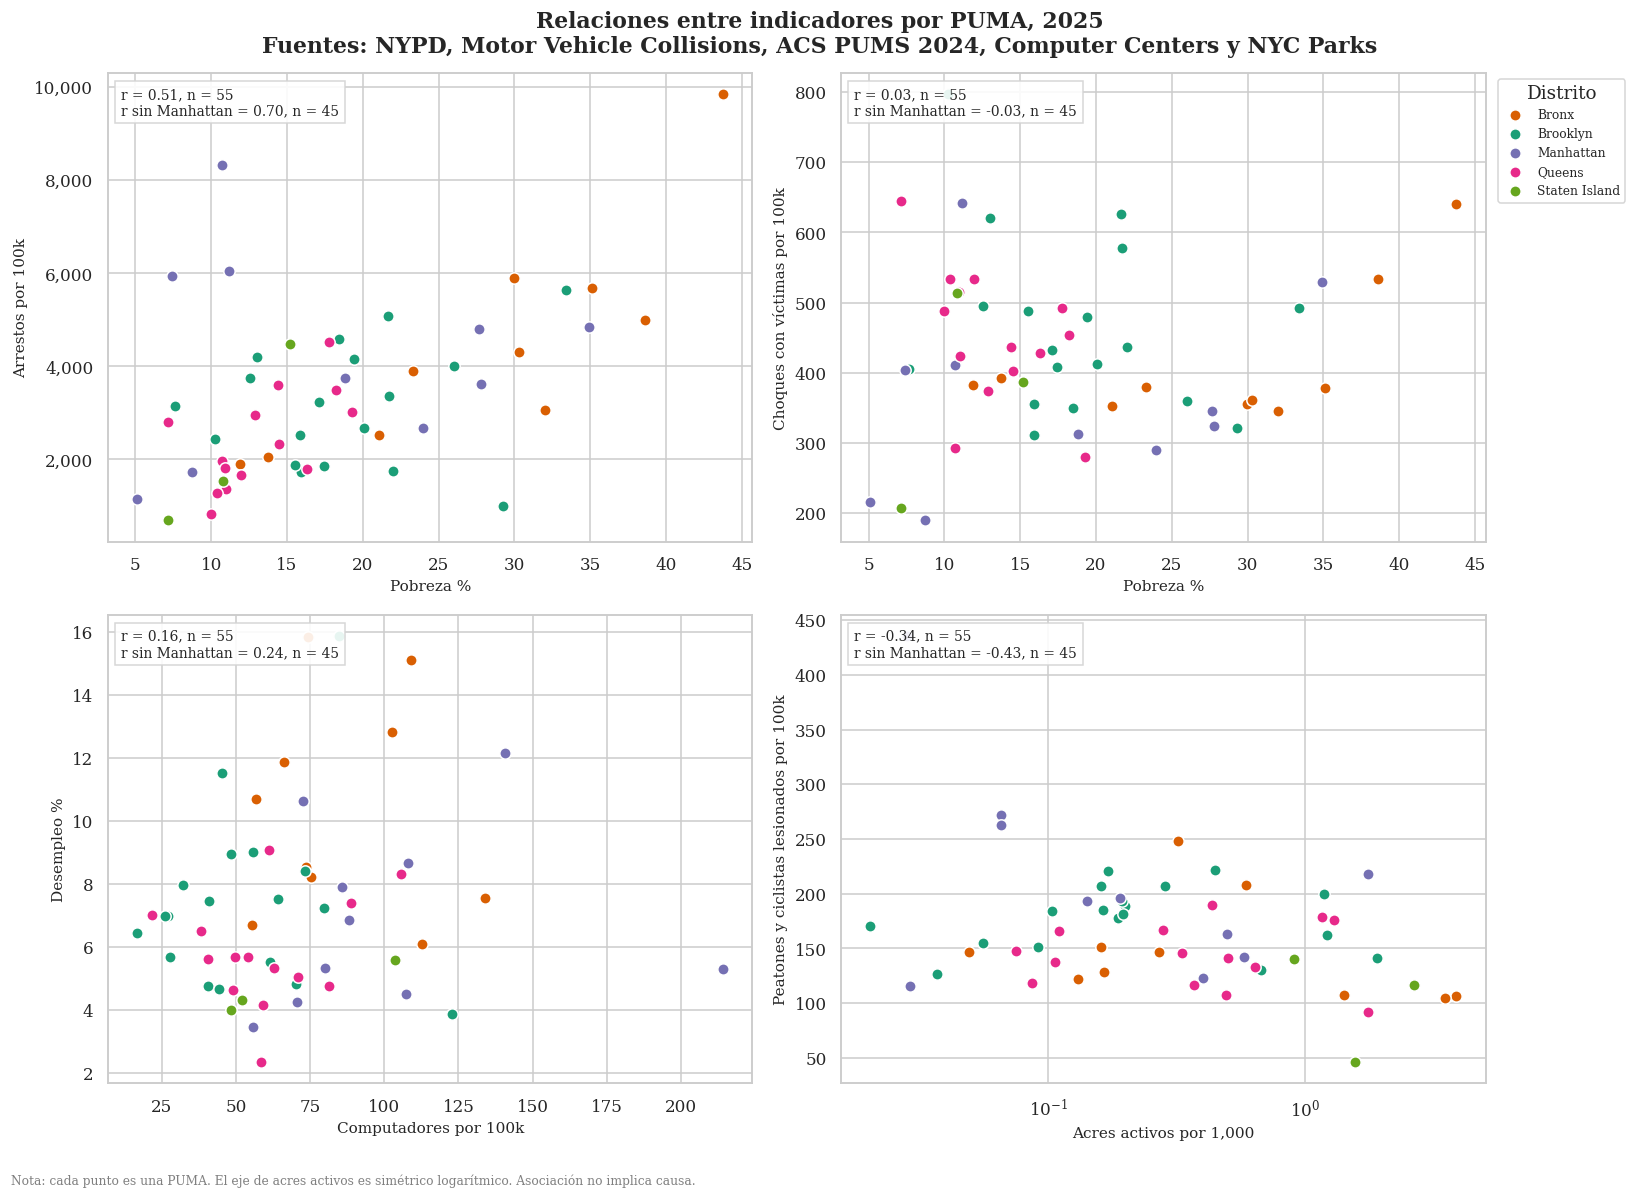

In [76]:
PARES_DISPERSION = [("POBREZA_PCT", "ARRESTOS_100K"), ("POBREZA_PCT", "VICTIMAS_100K"),
                    ("COMPUTADORES_100K", "DESEMPLEO_PCT"), ("ACRES_ACTIVOS_1000", "VULNERABLES_100K")]
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, (x, y) in zip(axes.ravel(), PARES_DISPERSION):
    for distrito in ORDEN_BORO:
        sub = pdf_cruce_puma[pdf_cruce_puma["DISTRITO"] == distrito]
        ax.scatter(sub[x], sub[y], s=55, color=PALETA_BORO[distrito], edgecolor="white", label=nombre_boro(distrito))
    r_todas = pdf_cruce_puma[x].corr(pdf_cruce_puma[y])
    sin_mn = pdf_cruce_puma[pdf_cruce_puma["DISTRITO"] != "MANHATTAN"]
    r_sin_mn = sin_mn[x].corr(sin_mn[y])
    ax.text(0.02, 0.97, f"r = {r_todas:.2f}, n = {len(pdf_cruce_puma)}\nr sin Manhattan = {r_sin_mn:.2f}, n = {len(sin_mn)}",
            transform=ax.transAxes, va="top", fontsize=9, bbox=dict(fc="white", ec="lightgray", alpha=0.9))
    if x == "ACRES_ACTIVOS_1000":
        ax.set_xscale("symlog", linthresh=0.1)
    ax.set(xlabel=NOMBRES_PUMA[x], ylabel=NOMBRES_PUMA[y])
    formato_miles(ax.yaxis)
axes[0, 1].legend(title="Distrito", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle(f"Relaciones entre indicadores por PUMA, {ANIO_COMPLETO}\n"
             "Fuentes: NYPD, Motor Vehicle Collisions, ACS PUMS 2024, Computer Centers y NYC Parks", fontweight="bold")
nota_figura(fig, "Nota: cada punto es una PUMA. El eje de acres activos es simétrico logarítmico. Asociación no implica causa.")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Análisis:** El panel de arrestos y pobreza muestra que la relación es más fuerte sin Manhattan: r pasa de 0.51 a 0.70. Las PUMAs de Manhattan tienen pocos pobres pero muchos arrestos, por la población que no vive allí. Los choques con víctimas no tienen relación con la pobreza, ni con Manhattan ni sin él. Los computadores públicos casi no se relacionan con el desempleo, r = 0.16. Más acres activos se asocian con menos peatones y ciclistas lesionados, r = -0.34 y -0.43 sin Manhattan, una pista para revisar en la entrega final.

Los mapas coropléticos de las 55 PUMAs se dibujan con `matplotlib.patches.Polygon`, a partir de los polígonos del GeoJSON. Para que una sola PUMA extrema no deje a todas las demás del mismo color, la escala de cada mapa se corta en el percentil 95.

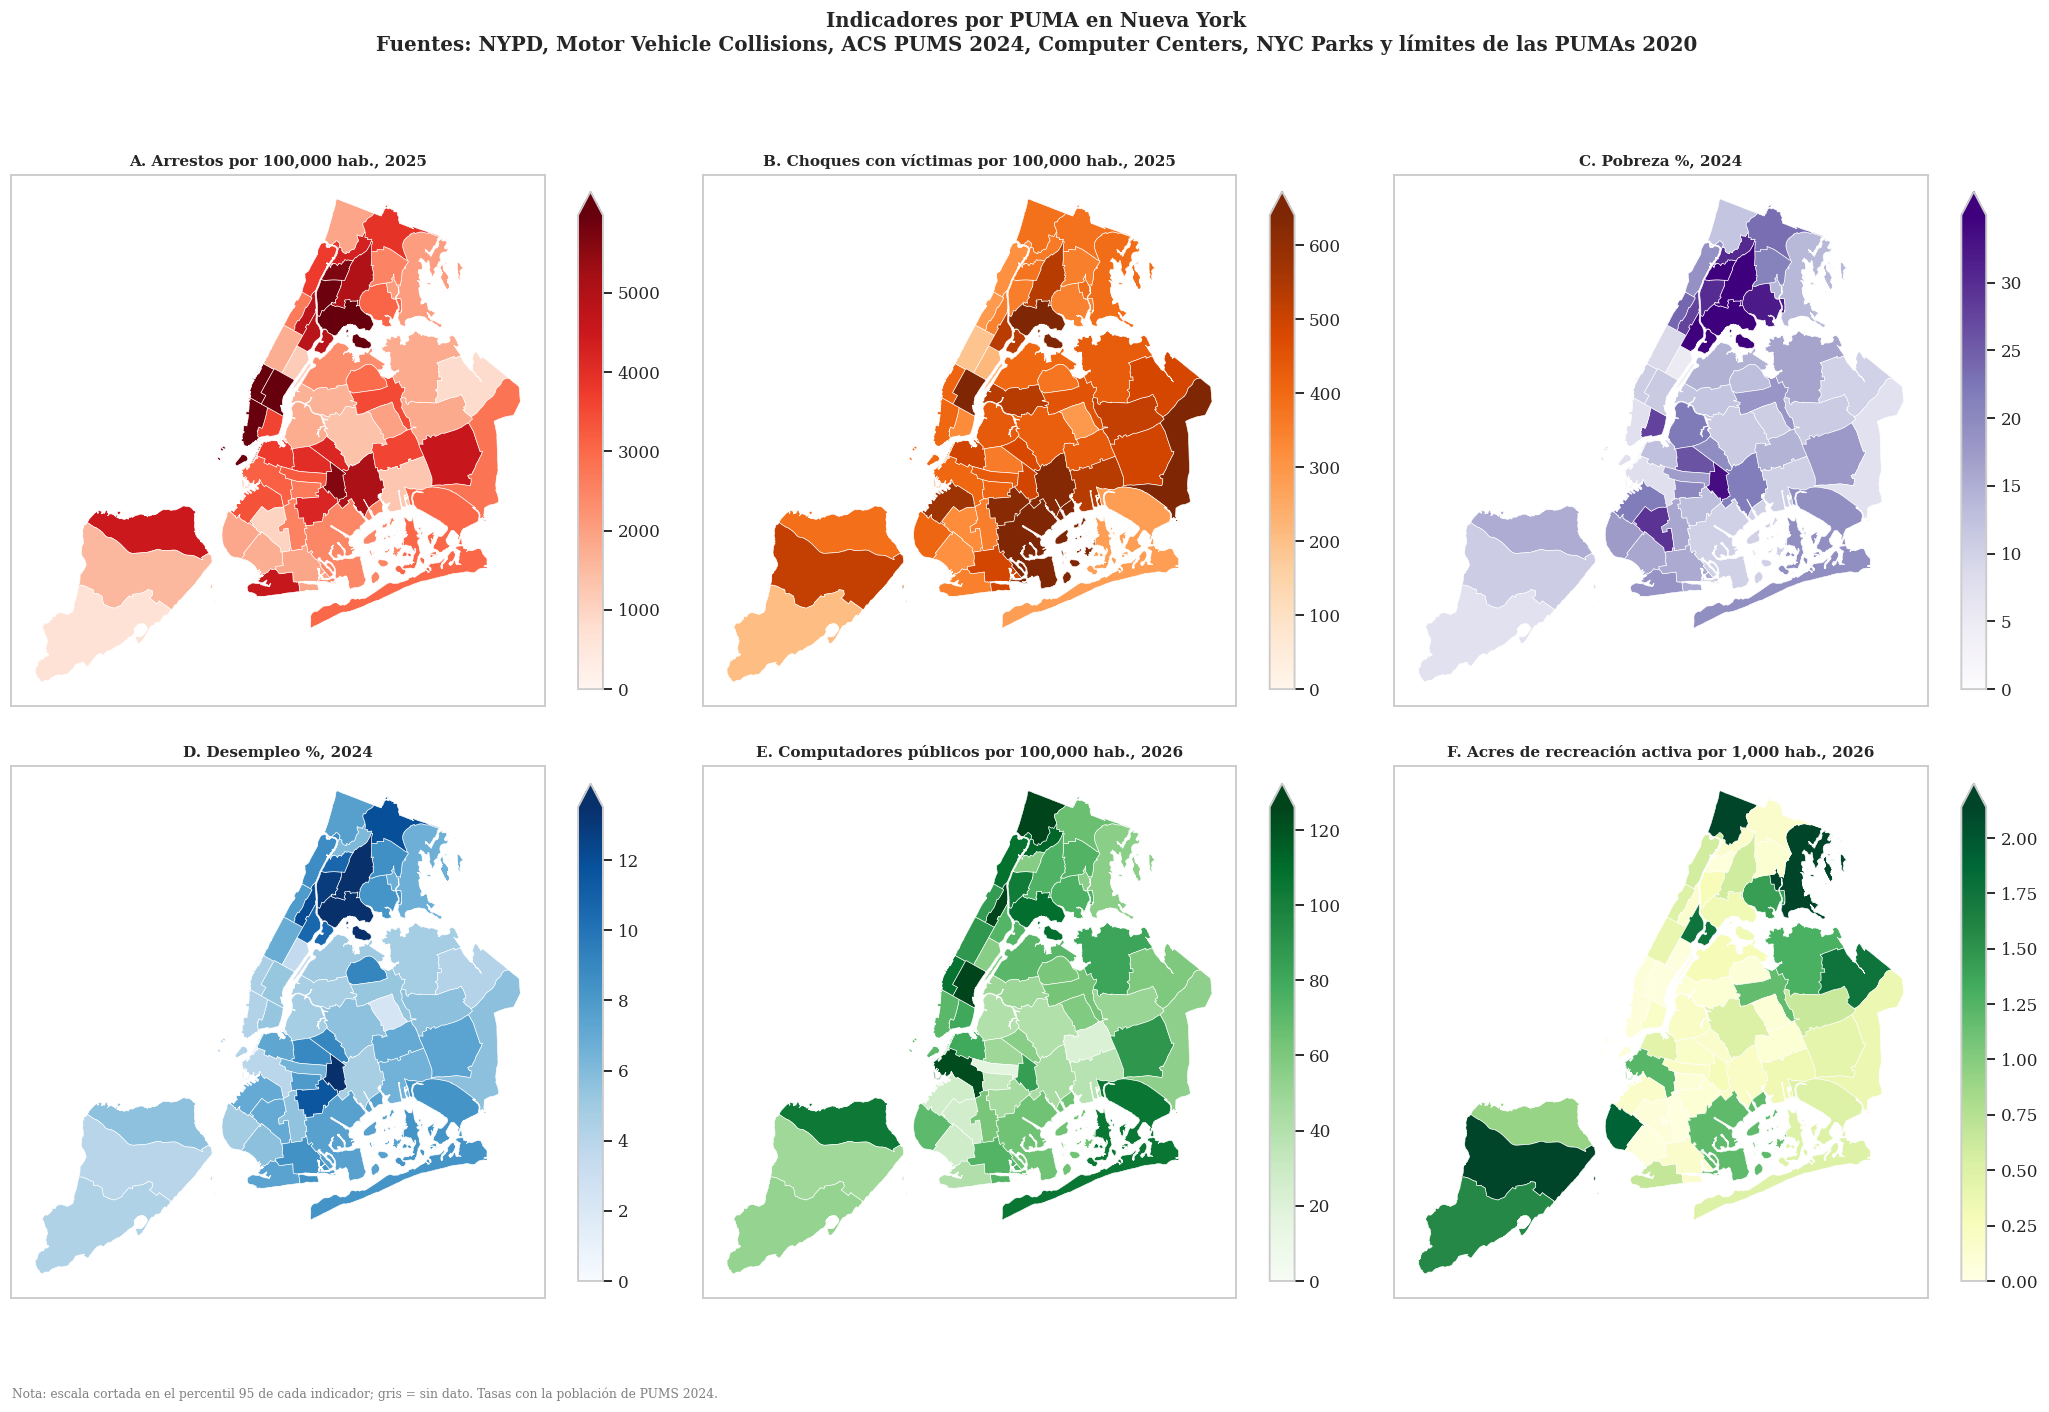

In [77]:
MAPAS = [("ARRESTOS_100K", f"A. Arrestos por 100,000 hab., {ANIO_COMPLETO}", "Reds"),
         ("VICTIMAS_100K", f"B. Choques con víctimas por 100,000 hab., {ANIO_COMPLETO}", "Oranges"),
         ("POBREZA_PCT", "C. Pobreza %, 2024", "Purples"),
         ("DESEMPLEO_PCT", "D. Desempleo %, 2024", "Blues"),
         ("COMPUTADORES_100K", f"E. Computadores públicos por 100,000 hab., {ANIO_CENTROS}", "Greens"),
         ("ACRES_ACTIVOS_1000", "F. Acres de recreación activa por 1,000 hab., 2026", "YlGn")]
fig, axes = plt.subplots(2, 3, figsize=(19, 13))
for ax, (columna, titulo, cmap) in zip(axes.ravel(), MAPAS):
    valores = dict(zip(pdf_cruce_puma["PUMA"], pdf_cruce_puma[columna]))
    vmax = float(np.nanpercentile(pdf_cruce_puma[columna], 95))
    coleccion = dibujar_pumas(ax, pumas_geo, valores, cmap=cmap, vmin=0, vmax=vmax)
    fig.colorbar(coleccion, ax=ax, shrink=0.75, extend="max")
    ax.set_title(titulo, fontsize=10)
fig.suptitle("Indicadores por PUMA en Nueva York\nFuentes: NYPD, Motor Vehicle Collisions, ACS PUMS 2024, Computer Centers, NYC Parks y límites de las PUMAs 2020",
             fontweight="bold", fontsize=13)
nota_figura(fig, "Nota: escala cortada en el percentil 95 de cada indicador; gris = sin dato. Tasas con la población de PUMS 2024.")
plt.tight_layout(rect=[0, 0.02, 1, 0.97])
plt.show()

**Análisis:** Los mapas muestran que los arrestos más altos están en el sur del Bronx y en el norte y el centro de Manhattan, y que el mapa de pobreza del Bronx se parece mucho al de arrestos. Los choques con víctimas tienen otra geografía: son más altos en el este de Brooklyn, el sureste de Queens y algunas zonas del Bronx. El desempleo sigue a la pobreza. Los computadores públicos son más altos en Manhattan y en algunas PUMAs del Bronx y de Queens, La recreación activa es baja en casi toda la ciudad y solo se destaca en las PUMAs con parques grandes: el noreste y el noroeste del Bronx, Staten Island y el centro de Queens, alrededor de Flushing Meadows.

### 7.8 Lo más reciente: 2026 frente al mismo tramo de 2025

El periodo de 2026 va del 1 de enero al último día que tienen las dos bases, arrestos y choques, y se calcula en el código. Se compara contra las mismas fechas de 2025. Las tasas de los dos años usan la población de PUMS 2024 y no se anualizan. Los muertos de 2026 no se comparan, porque una parte de los choques de 2026 no trae ese dato; un choque con víctimas sí se cuenta aunque falte el dato de muertos, gracias al coalesce de la condición.

In [78]:
fin_arrestos_2026 = df_arrestos.filter(F.col("ANIO") == ANIO_FIN).agg(F.max("FECHA")).first()[0]
fin_choques_2026 = df_choques.filter(F.col("ANIO") == ANIO_FIN).agg(F.max("FECHA")).first()[0]
FECHA_INI_2026 = date(ANIO_FIN, 1, 1)
FECHA_FIN_COMUN = min(fin_arrestos_2026, fin_choques_2026)
FECHA_INI_2025, FECHA_FIN_2025 = FECHA_INI_2026.replace(year=ANIO_FIN - 1), FECHA_FIN_COMUN.replace(year=ANIO_FIN - 1)
DIAS_COMUNES = (FECHA_FIN_COMUN - FECHA_INI_2026).days + 1
print(f"Último día con arrestos: {fin_arrestos_2026} | último día con choques: {fin_choques_2026}")
print(f"Periodo común: {FECHA_INI_2026} a {FECHA_FIN_COMUN}, {DIAS_COMUNES} días; se compara con {FECHA_INI_2025} a {FECHA_FIN_2025}")

# periodo_comun: no recibe nada; devuelve la etiqueta 2025 o 2026 si la fecha cae en el tramo de ese año
def periodo_comun():
    return (F.when(F.col("FECHA").between(F.lit(FECHA_INI_2025), F.lit(FECHA_FIN_2025)), "2025")
             .when(F.col("FECHA").between(F.lit(FECHA_INI_2026), F.lit(FECHA_FIN_COMUN)), "2026"))

distrito_o_sin = F.coalesce(F.col("DISTRITO"), F.lit("SIN DISTRITO")).alias("DISTRITO")
pdf_arr_tramo = (df_arrestos.withColumn("PERIODO", periodo_comun()).filter(F.col("PERIODO").isNotNull())
                 .groupBy("PERIODO", distrito_o_sin, "PUMA").agg(F.count("*").alias("ARRESTOS")).toPandas())
pdf_cho_tramo = (df_choques.withColumn("PERIODO", periodo_comun()).filter(F.col("PERIODO").isNotNull())
                 .groupBy("PERIODO", distrito_o_sin, "PUMA")
                 .agg(F.count("*").alias("CHOQUES"), F.sum("CON_VICTIMAS").alias("CHOQUES_CON_VICTIMAS"),
                      F.sum("NUMBER_OF_PERSONS_INJURED").alias("HERIDOS"), F.sum("NUMBER_OF_PERSONS_KILLED").alias("MUERTOS"),
                      F.count(F.when(F.col("NUMBER_OF_PERSONS_INJURED").isNull(), 1)).alias("HERIDOS_SIN_DATO"),
                      F.sum("MUERTOS_SIN_DATO").alias("MUERTOS_SIN_DATO"))
                 .toPandas())
sin_dato = pdf_cho_tramo.groupby("PERIODO")[["CHOQUES", "HERIDOS_SIN_DATO", "MUERTOS_SIN_DATO"]].sum()
for periodo, fila in sin_dato.iterrows():
    print(f"{periodo}: {int(fila['CHOQUES']):,} choques; sin dato de heridos: {int(fila['HERIDOS_SIN_DATO']):,}; "
          f"sin dato de muertos: {int(fila['MUERTOS_SIN_DATO']):,}")

INDICADORES_TRAMO = [("ARRESTOS", "Arrestos"), ("CHOQUES", "Choques"), ("CHOQUES_CON_VICTIMAS", "Choques con víctimas"),
                     ("HERIDOS", "Heridos"), ("MUERTOS", "Muertos, no comparable")]
por_distrito = (pdf_arr_tramo.groupby(["PERIODO", "DISTRITO"])["ARRESTOS"].sum().to_frame()
                .join(pdf_cho_tramo.groupby(["PERIODO", "DISTRITO"])[["CHOQUES", "CHOQUES_CON_VICTIMAS", "HERIDOS", "MUERTOS"]].sum(),
                      how="outer").fillna(0))
filas_tramo = []
for distrito in ORDEN_BORO + ["SIN DISTRITO", "CIUDAD"]:
    for clave, nombre in INDICADORES_TRAMO:
        if distrito == "CIUDAD":
            v25 = por_distrito.xs("2025", level="PERIODO")[clave].sum()
            v26 = por_distrito.xs("2026", level="PERIODO")[clave].sum()
            poblacion = POB_CIUDAD
        else:
            v25 = por_distrito[clave].get(("2025", distrito), 0)
            v26 = por_distrito[clave].get(("2026", distrito), 0)
            poblacion = POB_DISTRITO.get(distrito, np.nan)
        filas_tramo.append({"Distrito": nombre_boro(distrito), "Indicador": nombre, "2025": v25, "2026": v26,
                            "2025 por 100k": v25 / poblacion * 100000, "2026 por 100k": v26 / poblacion * 100000,
                            "Variación %": np.nan if clave == "MUERTOS" or v25 == 0 else (v26 - v25) / v25 * 100})
pdf_tramo = pd.DataFrame(filas_tramo)
pdf_tramo = pdf_tramo[~((pdf_tramo["Distrito"] == "Sin Distrito") & (pdf_tramo["2025"] == 0) & (pdf_tramo["2026"] == 0))]
mostrar_tabla(pdf_tramo, titulo=f"2026 frente al mismo tramo de 2025, del {FECHA_INI_2026:%d/%m} al {FECHA_FIN_COMUN:%d/%m}",
              decimales={"2025 por 100k": 1, "2026 por 100k": 1, "Variación %": 1}, pct=["Variación %"])

Último día con arrestos: 2026-06-30 | último día con choques: 2026-06-11
Periodo común: 2026-01-01 a 2026-06-11, 162 días; se compara con 2025-01-01 a 2025-06-11
2025: 36,774 choques; sin dato de heridos: 0; sin dato de muertos: 2
2026: 36,424 choques; sin dato de heridos: 0; sin dato de muertos: 8,877


Distrito,Indicador,2025,2026,2025 por 100k,2026 por 100k,Variación %
Bronx,Arrestos,"29,012","29,710","2,093.8","2,144.1",2.4%
Bronx,Choques,"5,567","5,987",401.8,432.1,7.5%
Bronx,Choques con víctimas,"2,450","2,691",176.8,194.2,9.8%
Bronx,Heridos,"3,372","3,899",243.4,281.4,15.6%
Bronx,"Muertos, no comparable",11,14,0.8,1.0,
Brooklyn,Arrestos,"36,576","38,976","1,397.1","1,488.7",6.6%
Brooklyn,Choques,"11,899","11,712",454.5,447.4,-1.6%
Brooklyn,Choques con víctimas,"5,208","4,950",198.9,189.1,-5.0%
Brooklyn,Heridos,"6,920","6,697",264.3,255.8,-3.2%
Brooklyn,"Muertos, no comparable",30,18,1.1,0.7,


**Análisis:** El periodo común va del 1 de enero al 11 de junio, 162 días. En la ciudad casi todo se mantiene frente al mismo tramo de 2025: los arrestos bajan 0.9%, los choques 1.0% y los choques con víctimas 1.5%, mientras que los heridos suben 0.2%. El Bronx es la excepción: sube en todo, con arrestos +2.4%, choques con víctimas +9.8% y heridos +15.6%. Staten Island es el que más baja, con arrestos -16.6% y heridos -14.5%. Los muertos de 2026 no se comparan porque 8,877 choques de 2026 no traen ese dato, frente a 2 en 2025.

El gráfico de puntos unidos compara cada distrito en 2025, punto vacío, y en 2026, punto lleno, en tasas por cada 100,000 habitantes del mismo tramo del año.

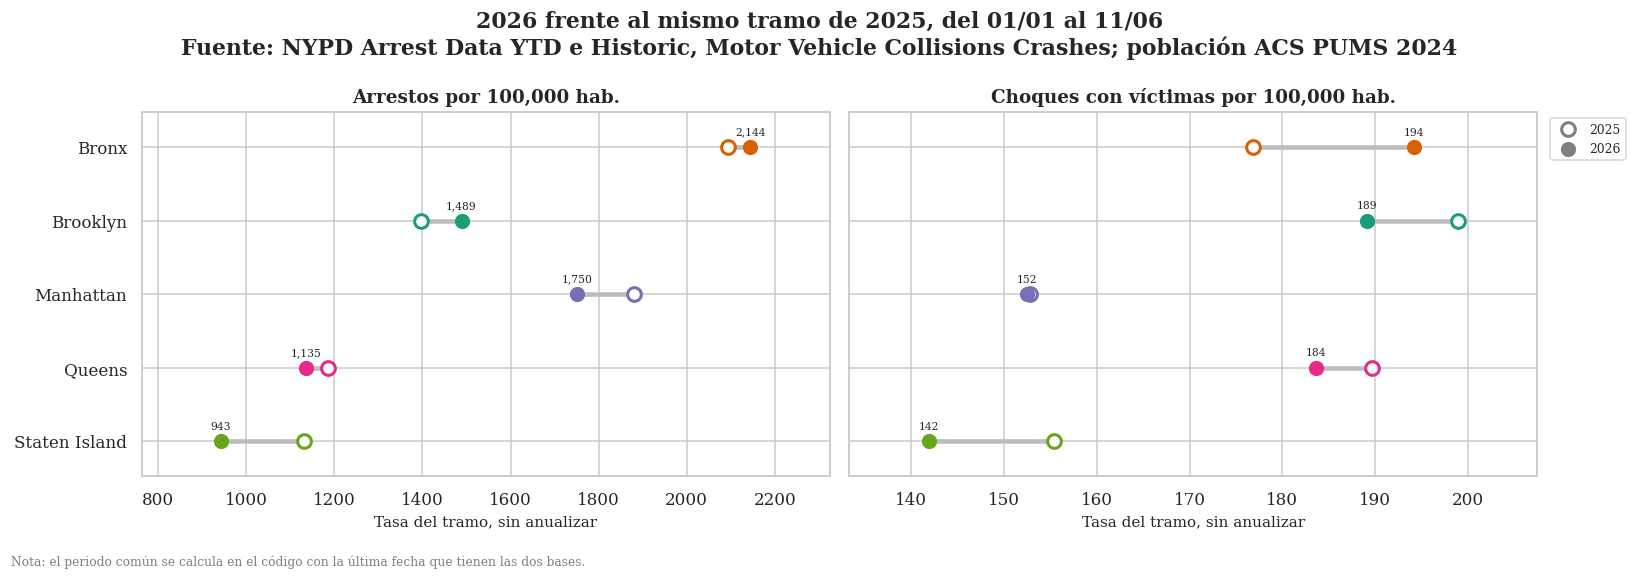

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for ax, nombre in zip(axes, ["Arrestos", "Choques con víctimas"]):
    sub = pdf_tramo[pdf_tramo["Indicador"] == nombre].set_index("Distrito")
    for y_pos, distrito in enumerate(ORDEN_BORO):
        v25, v26 = sub.loc[nombre_boro(distrito), "2025 por 100k"], sub.loc[nombre_boro(distrito), "2026 por 100k"]
        ax.plot([v25, v26], [y_pos, y_pos], color="#bdbdbd", lw=3, zorder=1)
        ax.scatter(v25, y_pos, s=80, color="white", edgecolor=PALETA_BORO[distrito], linewidth=2, zorder=2)
        ax.scatter(v26, y_pos, s=80, color=PALETA_BORO[distrito], zorder=3)
        ax.annotate(f"{v26:,.0f}", (v26, y_pos), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=7)
    ax.set(title=f"{nombre} por 100,000 hab.", xlabel="Tasa del tramo, sin anualizar")
    ax.margins(x=0.15, y=0.12)
axes[0].set_yticks(range(len(ORDEN_BORO)))
axes[0].set_yticklabels([nombre_boro(d) for d in ORDEN_BORO])
axes[0].invert_yaxis()
axes[1].scatter([], [], s=80, color="white", edgecolor="gray", linewidth=2, label="2025")
axes[1].scatter([], [], s=80, color="gray", label="2026")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.suptitle(f"2026 frente al mismo tramo de 2025, del {FECHA_INI_2026:%d/%m} al {FECHA_FIN_COMUN:%d/%m}\n"
             "Fuente: NYPD Arrest Data YTD e Historic, Motor Vehicle Collisions Crashes; población ACS PUMS 2024", fontweight="bold")
nota_figura(fig, "Nota: el periodo común se calcula en el código con la última fecha que tienen las dos bases.")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

**Análisis:** La gráfica muestra la dirección del cambio en cada distrito. En arrestos suben el Bronx y Brooklyn y bajan Manhattan, Queens y Staten Island. En choques con víctimas solo sube el Bronx, de 176.8 a 194.2 por cada 100,000 habitantes, con lo que pasa a tener la tasa más alta del tramo; Manhattan queda igual, en 152.5. El Bronx necesita atención prioritaria en los dos indicadores.

Por PUMA, se calcula la variación porcentual de 2025 a 2026 en el mismo tramo. Para no leer como grandes cambios lo que son pocos eventos, solo entran las PUMAs con al menos 30 eventos en el tramo de 2025.

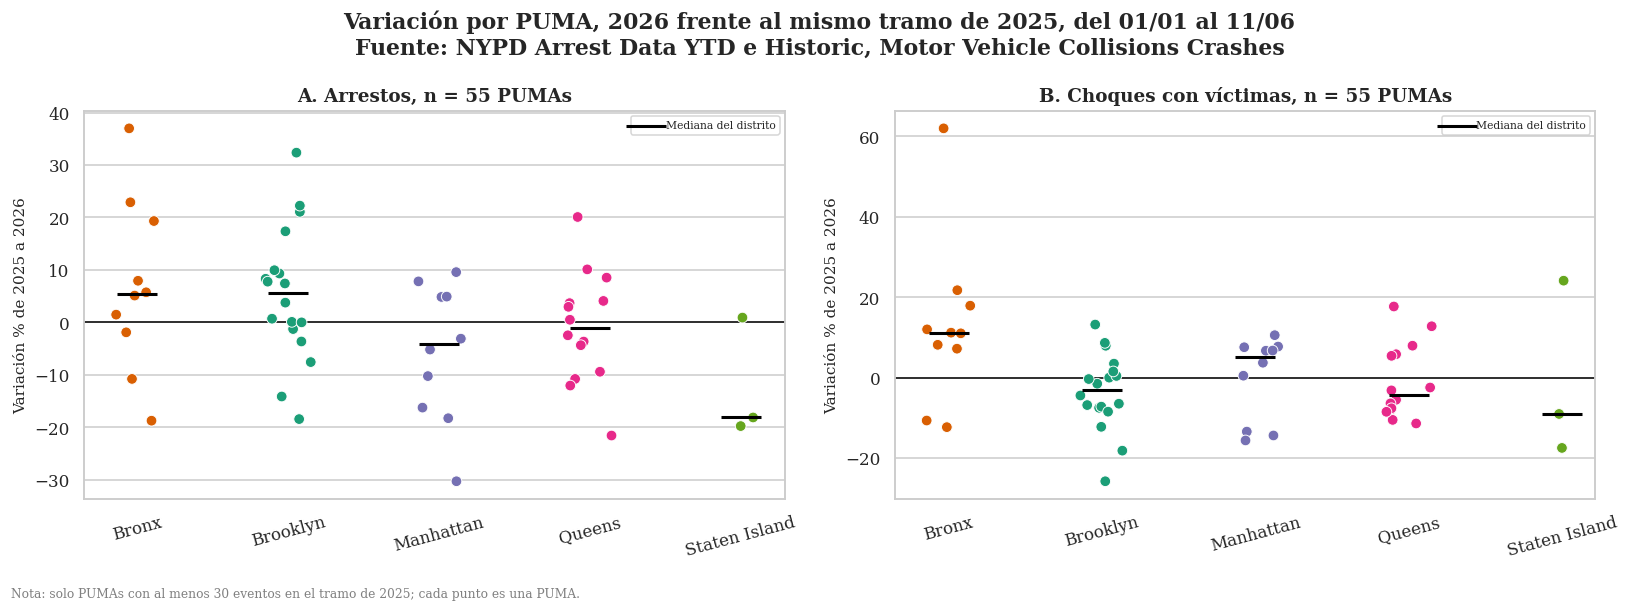

In [80]:
MINIMO_EVENTOS = 30
# por_puma_periodo: recibe la tabla del tramo y la columna a sumar; devuelve una fila por PUMA con una columna
# por periodo, 2025 y 2026, y el sufijo indicado
def por_puma_periodo(pdf, columna, sufijo):
    return (pdf.dropna(subset=["PUMA"]).groupby(["PUMA", "PERIODO"])[columna].sum().unstack("PERIODO")
            .reindex(columns=["2025", "2026"]).fillna(0).add_suffix(sufijo))

var_puma = (por_puma_periodo(pdf_arr_tramo, "ARRESTOS", "_ARR")
            .join(por_puma_periodo(pdf_cho_tramo, "CHOQUES_CON_VICTIMAS", "_VICT"), how="outer").fillna(0)
            .reset_index())
var_puma["PUMA"] = var_puma["PUMA"].astype(int)
var_puma["DISTRITO"] = var_puma["PUMA"].floordiv(100).map(PUMA_A_BORO)
for sufijo, nombre in [("_ARR", "VAR_ARRESTOS"), ("_VICT", "VAR_VICTIMAS")]:
    base_2025 = var_puma[f"2025{sufijo}"]
    var_puma[nombre] = np.where(base_2025 >= MINIMO_EVENTOS, (var_puma[f"2026{sufijo}"] - base_2025) / base_2025.replace(0, np.nan) * 100, np.nan)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, columna, titulo in [(axes[0], "VAR_ARRESTOS", "A. Arrestos"), (axes[1], "VAR_VICTIMAS", "B. Choques con víctimas")]:
    sub = var_puma.dropna(subset=[columna])
    strip_por_distrito(ax, sub, columna, f"{titulo}, n = {len(sub)} PUMAs", "Variación % de 2025 a 2026")
    ax.axhline(0, color="black", lw=1)
fig.suptitle(f"Variación por PUMA, 2026 frente al mismo tramo de 2025, del {FECHA_INI_2026:%d/%m} al {FECHA_FIN_COMUN:%d/%m}\n"
             "Fuente: NYPD Arrest Data YTD e Historic, Motor Vehicle Collisions Crashes", fontweight="bold")
nota_figura(fig, f"Nota: solo PUMAs con al menos {MINIMO_EVENTOS} eventos en el tramo de 2025; cada punto es una PUMA.")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

**Análisis:** Las medianas por distrito ocultan cambios fuertes en algunas PUMAs. En arrestos, varias PUMAs del Bronx y de Brooklyn suben más de 20%, con un máximo cercano a 37%, mientras que una PUMA de Manhattan baja cerca de 30%. En choques con víctimas, una PUMA del Bronx sube más de 60% y la mediana del Bronx sube cerca de 11%, mientras que Brooklyn y Queens bajan. Las 55 PUMAs pasaron el filtro de al menos 30 eventos en el tramo de 2025, así que estos cambios no salen de muy pocos casos.

## 8. Filtros, limpieza y transformaciones iniciales

Esta sección es el numeral 7 del enunciado. Varias transformaciones ya se aplicaron en secciones anteriores porque la exploración las necesitaba; aquí se resumen todas y se agregan tres celdas propias.

**Resumen de lo aplicado en todo el notebook:**

- **Lectura con esquema explícito, sección 3.6:** cada CSV se lee como texto, sin inferSchema; los nombres se normalizan y cada columna se convierte por nombre con `try_cast`. Los textos que no se pueden convertir quedan en NULL y se cuentan.
- **Filtros de periodo apenas se carga cada base, sección 3.7:** arrestos 2021-2025 del histórico y 2026 del YTD; choques, vehículos y personas 2021-2026 por su fecha del choque; PUMS solo con las 55 PUMAs de la ciudad.
- **Arrestos, sección 4.8:** distrito con nombre completo; "NO ESPECIFICADO" en nivel del delito, raza, edad, sexo y descripción del delito cuando faltan; mes, día de la semana y fin de semana; marca de coordenada válida.
- **Choques, sección 4.8:** se descartan las filas desplazadas y las que no tienen `COLLISION_ID`; el distrito faltante se completa con el voto mayoritario de su celda y se mide su consistencia; se marcan la hora de relleno 00:00, los choques con víctimas, con coalesce en la condición, y los choques sin dato de muertos.
- **Vehículos, sección 4.8:** 8 categorías estandarizadas; los ocupantes imposibles se anulan con un tope por categoría sin borrar el registro; año del modelo plausible; factor contribuyente con etiqueta.
- **Personas, sección 4.8:** tipo de persona y gravedad en español; edad válida de 0 a 110 años y grupo de edad; parte del cuerpo con etiqueta.
- **Centros, sección 4.8:** año más reciente del archivo, distrito estándar, estado abierto y computadores.
- **Parques, secciones 3.7, 4.7 y 4.8:** una fila por GISPROPNUM para no repetir el área de un mismo parque, punto representativo, números convertidos con `try_cast`, coherencia entre categoría y porcentajes reportada sin corregir y distrito en mayúsculas.
- **Asignación a PUMA, sección 4.9:** pares únicos de coordenadas redondeadas, `contains_points` en el Driver y broadcast join en Spark; Vehicles y Person reciben la PUMA de su choque por `COLLISION_ID`; se reportan los puntos sin PUMA y la concordancia de distrito.
- **Tasas por habitante, secciones 4.10 y 5 a 7:** arrestos, choques, centros y computadores por cada 100,000 habitantes, y acres de parque por cada 1,000 habitantes como en el manual CEQR, todo con la población de PUMS 2024 ponderada con `PWGTP`.
- **Periodo común de 2026, sección 7.8:** se calcula en el código con la última fecha que tienen arrestos y choques, y se compara con las mismas fechas de 2025.
- **Lo que no se hace:** no se imputa con la media ni con el valor más común; los vacíos estructurales de PUMS quedan como no aplica y salen del cálculo; los puntajes "N<15" se excluyen.
- **Guardado:** las bases limpias quedan en Parquet en /opt/cluster/data/proyecto_ny/parquet, y la bandera `REUSAR_PARQUET` evita recalcularlas.

### 8.1 Embudo de filas por base

La tabla muestra, para cada base, cuántas filas tenía el archivo, cuántas quedaron en el periodo, cuántas después de la limpieza y cuántas tienen distrito y PUMA. Cada base se resume con una sola agregación.

In [81]:
# embudo: recibe el nombre, las filas del archivo, el DataFrame del periodo y el DataFrame limpio; devuelve una
# fila con los conteos, contando distrito y PUMA en una sola agregación sobre la base limpia
def embudo(base, filas_archivo, df_periodo, df_limpio):
    fila = df_limpio.agg(F.count("*").alias("LIMPIO"),
                         F.count(F.when(F.col("DISTRITO").isNotNull(), 1)).alias("CON_DISTRITO"),
                         F.count(F.when(F.col("PUMA").isNotNull(), 1)).alias("CON_PUMA")).first()
    return {"Base": base, "Filas en el archivo": filas_archivo, "Filas en el periodo": df_periodo.count(),
            "Filas tras la limpieza": fila["LIMPIO"], "Con distrito": fila["CON_DISTRITO"], "Con PUMA": fila["CON_PUMA"]}

filas_archivo_arrestos = sum(int(meta_arrestos.get(f, {}).get("FILAS_ARCHIVO", 0)) for f in ["HISTORICO", "YTD"])
pdf_embudo = pd.DataFrame([
    embudo("Arrestos", filas_archivo_arrestos, df_arrestos_base, df_arrestos),
    embudo("Choques", meta_choques.get("FILAS_ARCHIVO"), df_choques_base, df_choques),
    embudo("Vehículos", meta_vehiculos.get("FILAS_ARCHIVO"), df_vehiculos_base, df_vehiculos),
    embudo("Personas", meta_personas.get("FILAS_ARCHIVO"), df_personas_base, df_personas),
    embudo("PUMS 2024", meta_pums.get("FILAS_ARCHIVO"), df_pums_base, df_pums_base),
    embudo(f"Centros de computadores, {ANIO_CENTROS}", meta_centros.get("FILAS_ARCHIVO"), df_centros_base, df_centros),
    embudo("Parques", meta_parques.get("FILAS_ARCHIVO"), df_parques_base, df_parques),
])
pdf_embudo["Filas en el archivo"] = pd.to_numeric(pdf_embudo["Filas en el archivo"], errors="coerce")
mostrar_tabla(pdf_embudo, titulo="Embudo de filas por base: archivo, periodo, limpieza, distrito y PUMA")
print("En centros, el periodo incluye todos los años del archivo y la limpieza deja solo el año más reciente.")

Base,Filas en el archivo,Filas en el periodo,Filas tras la limpieza,Con distrito,Con PUMA
Arrestos,"1,855,282","1,253,479","1,253,479","1,253,479","1,253,368"
Choques,"2,269,188","524,338","524,338","496,332","483,102"
Vehículos,"4,551,002","1,057,393","1,057,393","1,000,185","973,746"
Personas,"5,984,110","1,820,886","1,820,886","1,705,657","1,661,529"
PUMS 2024,"210,150","67,511","67,511","67,511","67,511"
"Centros de computadores, 2026",974,974,515,511,512
Parques,"2,936","2,936","1,811","1,811","1,777"


En centros, el periodo incluye todos los años del archivo y la limpieza deja solo el año más reciente.


**Análisis:** El embudo muestra que la limpieza no eliminó registros de arrestos, choques, vehículos, personas ni PUMS: sus filas tras la limpieza son iguales a las del periodo. Solo cambian los centros, donde se deja el año 2026, y los parques, que pasan de 2,936 filas a 1,811 espacios al dejar una fila por GISPROPNUM; 1,777 de ellos tienen PUMA. Los arrestos quedan con distrito en el 100% y con PUMA en el 99.99%. Los choques quedan con distrito en el 94.66% y con PUMA en el 92.14%; vehículos y personas tienen porcentajes parecidos porque heredan la ubicación de su choque. Lo que se pierde por falta de PUMA viene de los choques sin coordenadas.

### 8.2 Transformación de calendario: eventos promedio por tipo de día

Para comparar días entre semana y fines de semana no basta con contar eventos: hay que dividir por el número real de días de cada tipo en el año. Los días del calendario se generan dentro de Spark con `spark.range` y `sequence`, sin listas de Python, porque los workers no pueden ejecutar código Python.

In [82]:
calendario = (spark.range(ANIO_INI, ANIO_COMPLETO + 1)
              .select(F.col("id").cast("int").alias("ANIO"))
              .select("ANIO", F.explode(F.expr("sequence(make_date(ANIO, 1, 1), make_date(ANIO, 12, 31), interval 1 day)"))
                      .alias("FECHA"))
              .withColumn("FIN_DE_SEMANA", F.dayofweek("FECHA").isin(1, 7).cast("int")))
dias_calendario = calendario.groupBy("ANIO", "FIN_DE_SEMANA").agg(F.count("*").alias("DIAS_CALENDARIO"))
arrestos_tipo_dia = (df_arrestos.filter(F.col("ANIO").between(ANIO_INI, ANIO_COMPLETO))
                     .groupBy("ANIO", "FIN_DE_SEMANA").agg(F.count("*").alias("ARRESTOS")))
choques_tipo_dia = (df_choques.filter(F.col("ANIO").between(ANIO_INI, ANIO_COMPLETO))
                    .withColumn("FIN_DE_SEMANA", F.col("DIA_SEMANA").isin(1, 7).cast("int"))
                    .groupBy("ANIO", "FIN_DE_SEMANA")
                    .agg(F.count("*").alias("CHOQUES"), F.sum("CON_VICTIMAS").alias("CHOQUES_CON_VICTIMAS")))
pdf_tipo_dia = (dias_calendario.join(arrestos_tipo_dia, ["ANIO", "FIN_DE_SEMANA"], "left")
                .join(choques_tipo_dia, ["ANIO", "FIN_DE_SEMANA"], "left")
                .orderBy("ANIO", "FIN_DE_SEMANA").toPandas())
for columna in ["ARRESTOS", "CHOQUES", "CHOQUES_CON_VICTIMAS"]:
    pdf_tipo_dia[columna + "_POR_DIA"] = pdf_tipo_dia[columna] / pdf_tipo_dia["DIAS_CALENDARIO"]
pdf_tipo_dia["TIPO_DIA"] = np.where(pdf_tipo_dia["FIN_DE_SEMANA"] == 1, "Fin de semana", "Entre semana")
mostrar_tabla(pdf_tipo_dia[["ANIO", "TIPO_DIA", "DIAS_CALENDARIO", "ARRESTOS_POR_DIA", "CHOQUES_POR_DIA",
                            "CHOQUES_CON_VICTIMAS_POR_DIA"]].rename(columns={
    "ANIO": "Año", "TIPO_DIA": "Tipo de día", "DIAS_CALENDARIO": "Días del calendario",
    "ARRESTOS_POR_DIA": "Arrestos por día", "CHOQUES_POR_DIA": "Choques por día",
    "CHOQUES_CON_VICTIMAS_POR_DIA": "Choques con víctimas por día"}),
    titulo=f"Eventos promedio por día entre semana y en fin de semana, {ANIO_INI}-{ANIO_COMPLETO}", decimales=1)

Año,Tipo de día,Días del calendario,Arrestos por día,Choques por día,Choques con víctimas por día
2021,Entre semana,261,464.7,308.8,108.2
2021,Fin de semana,104,328.9,288.1,101.6
2022,Entre semana,260,568.6,289.2,111.1
2022,Fin de semana,105,399.4,273.4,99.5
2023,Entre semana,260,677.2,268.5,114.2
2023,Fin de semana,105,483.8,255.2,102.6
2024,Entre semana,262,760.1,253.9,113.6
2024,Fin de semana,104,590.0,238.5,100.6
2025,Entre semana,261,817.8,238.9,105.9
2025,Fin de semana,104,630.0,223.0,93.9


**Análisis:** Al dividir por el número real de días, los arrestos son mucho más altos entre semana: en 2025 hubo 817.8 arrestos por día entre semana y 630.0 en fin de semana, 29.8% más. En los choques la diferencia es menor: 7.1% más choques y 12.8% más choques con víctimas por día entre semana. La tabla también muestra las dos tendencias opuestas: entre 2021 y 2025 los arrestos por día entre semana suben 76%, de 464.7 a 817.8, mientras que los choques por día bajan 22.6%, de 308.8 a 238.9.

### 8.3 Tablas de indicadores para la entrega final

Las tablas de cruce por distrito y por PUMA son el insumo de las preguntas de negocio y de los modelos de la entrega final. Se guardan en Parquet: primero se pasan a Spark por un CSV en la carpeta compartida y luego Spark las escribe. Cada tabla tiene una fila por zona y una columna por indicador.

In [83]:
# guardar_indicadores: recibe una tabla de pandas y un nombre. Arma el esquema según el tipo de cada columna,
# pasa la tabla a Spark, la guarda en Parquet y devuelve el DataFrame leído desde el Parquet
def guardar_indicadores(pdf, nombre):
    esquema = {}
    for columna in pdf.columns:
        if pd.api.types.is_integer_dtype(pdf[columna]):
            esquema[columna] = "bigint"
        elif pd.api.types.is_numeric_dtype(pdf[columna]):
            esquema[columna] = "double"
        else:
            esquema[columna] = "string"
    df = pandas_a_spark(pdf, nombre, esquema).drop("N_NO_CONVERTIBLES")
    ruta = f"{PARQUET_PATH}/{nombre}"
    df.write.mode("overwrite").parquet(ruta)
    return spark.read.parquet(ruta)

df_indicadores_distrito = guardar_indicadores(pdf_cruce_distrito, "indicadores_distrito")
df_indicadores_puma = guardar_indicadores(pdf_cruce_puma, "indicadores_puma")
mostrar_tabla(pd.DataFrame([
    {"Tabla": "indicadores_distrito", "Filas": df_indicadores_distrito.count(), "Columnas": len(df_indicadores_distrito.columns),
     "Ruta": f"{PARQUET_PATH}/indicadores_distrito"},
    {"Tabla": "indicadores_puma", "Filas": df_indicadores_puma.count(), "Columnas": len(df_indicadores_puma.columns),
     "Ruta": f"{PARQUET_PATH}/indicadores_puma"}]),
    titulo="Tablas de indicadores guardadas en Parquet")

Tabla,Filas,Columnas,Ruta
indicadores_distrito,5,17,/opt/cluster/data/proyecto_ny/parquet/indicadores_distrito
indicadores_puma,55,25,/opt/cluster/data/proyecto_ny/parquet/indicadores_puma


**Análisis:** Quedaron guardadas dos tablas de indicadores: una por distrito, de 5 filas y 17 columnas, y otra por PUMA, de 55 filas y 25 columnas. Cada fila es una zona y cada columna un indicador ya calculado por habitante. Estas tablas son el insumo para responder las preguntas de negocio y para los modelos de la entrega final, sin volver a procesar las bases grandes.

## 9. Planteamiento de preguntas de negocio

Se plantean 10 preguntas que se responderán en la entrega final. Todas son medibles con las fuentes actuales y cada una dice qué base y qué nivel geográfico usa. En esta entrega no se responden.

### Eje 1: seguridad ciudadana

1. ¿Cuáles son las 10 PUMAs con mayor tasa de arrestos por cada 100,000 habitantes en 2025 y qué porcentaje de los arrestos de la ciudad concentran?
   *Base:* NYPD Arrests Historic 2025 y ACS PUMS 2024. *Nivel geográfico:* PUMA.
2. ¿Cómo cambió entre 2021 y 2024 el peso de los arrestos por delito grave en los menores de 18 años y en el grupo de 18 a 24 años, y se mantiene ese patrón en 2026?
   *Base:* NYPD Arrests Historic 2021-2024 y YTD 2026; 2025 se excluye por los faltantes de edad. *Nivel geográfico:* ciudad y distrito.
3. ¿Qué tan fuerte es la relación entre la tasa de pobreza federal y la tasa de arrestos por cada 100,000 habitantes en las 55 PUMAs, y se mantiene al excluir las PUMAs de Manhattan?
   *Base:* ACS PUMS 2024 y NYPD Arrests Historic 2025. *Nivel geográfico:* PUMA.

### Eje 2: seguridad vial

4. ¿En qué franjas de día y hora se concentran los choques con víctimas de 2021 a 2025, sin la hora de relleno 00:00, y cambia esa franja entre distritos?
   *Base:* Motor Vehicle Collisions Crashes. *Nivel geográfico:* distrito.
5. ¿Qué tipo de persona, peatón, ciclista u ocupante, tiene la mayor letalidad, medida como muertos por cada 1,000 lesionados, entre 2021 y 2025, y en qué distritos y grupos de edad es más alta?
   *Base:* Motor Vehicle Collisions Person y Crashes. *Nivel geográfico:* distrito.
6. ¿Qué categorías de vehículo y qué factores contribuyentes pesan más en los choques con muertos de 2021 a 2025 que en el total de choques?
   *Base:* Motor Vehicle Collisions Vehicles y Crashes. *Nivel geográfico:* ciudad y distrito.

### Eje 3: cruce entre seguridad y tránsito

7. ¿Qué PUMAs tienen al mismo tiempo tasas de arrestos y de choques con víctimas por encima del percentil 75 de la ciudad en 2025, y cuáles de ellas suben en el periodo común de 2026 frente al mismo tramo de 2025?
   *Base:* NYPD Arrests Historic y YTD, Motor Vehicle Collisions Crashes y ACS PUMS 2024. *Nivel geográfico:* PUMA.

### Eje 4: oferta pública y condiciones sociales

8. ¿Las PUMAs con menos centros y computadores públicos por cada 100,000 habitantes tienen mayor pobreza, mayor desempleo y mayor tasa de arrestos en 2025?
   *Base:* Citywide Public Computer Centers, ACS PUMS 2024 y NYPD Arrests Historic 2025. *Nivel geográfico:* PUMA.
9. ¿Cuántas PUMAs están por debajo de la meta CEQR de 2.5 acres de espacio abierto y de 2.0 acres de recreación activa por cada 1,000 habitantes, y tienen esas PUMAs más peatones y ciclistas lesionados por cada 100,000 habitantes?
   *Base:* NYC Parks Active and Passive Recreation, ACS PUMS 2024 y Motor Vehicle Collisions Person. *Nivel geográfico:* PUMA.
10. ¿Los distritos con menor puntaje SAT en 2024-25 tienen también mayor desempleo de 16 a 24 años y una mayor proporción de arrestos de menores de 25 años en 2026?
    *Base:* School Quality Reports 2024-25, ACS PUMS 2024 y NYPD Arrest Data YTD 2026. *Nivel geográfico:* distrito, con la advertencia de que n = 5.

---

## 10. Bono 1: web scraping de la población del NYSDOH

Fuente: New York State Department of Health, Vital Statistics, tabla 2, con la población estimada por condado. Se toma el año más reciente disponible: el código prueba desde el año actual hacia atrás y se queda con el primero que tenga la tabla completa y validada.

> **Nota:** el enlace sugerido en el enunciado devolvía 403 o 404 desde el clúster, así que las mismas tablas oficiales se leen desde el host healthweb-back.health.ny.gov. No se siguen redirecciones, para que todas las peticiones se queden en ese host. Antes de usar los datos se valida que la suma de los cinco condados coincida con el total publicado de New York City.

In [84]:
from bs4 import BeautifulSoup

# Se envía un User-Agent de navegador para que el sitio responda como a una visita normal, y se consulta solo este host oficial
headers = {"User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                          "(KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36")}
# Condado del NYSDOH y distrito en mayúsculas, como en el resto del notebook
CONDADOS_NYSDOH = {"Bronx": "BRONX", "Kings": "BROOKLYN", "New York": "MANHATTAN", "Queens": "QUEENS",
                   "Richmond": "STATEN ISLAND"}

# extraer_poblacion_nysdoh: recibe las filas de texto de una tabla HTML y el año. Devuelve None si la tabla no
# tiene los encabezados buscados; si los tiene, devuelve los registros por distrito y el control contra el total
# de New York City. Lanza un error si los datos no pasan las validaciones
def extraer_poblacion_nysdoh(filas, anio):
    encabezados = [(i, fila) for i, fila in enumerate(filas) if fila and fila[0].casefold() == "county"
                   and any("population estimate" in texto.casefold() for texto in fila)]
    if not encabezados:
        return None
    if len(encabezados) != 1:
        raise ValueError("Se encontró más de un encabezado de población en la misma tabla.")
    inicio, encabezado = encabezados[0]
    columnas = [i for i, texto in enumerate(encabezado) if "population estimate" in texto.casefold()]
    if len(columnas) != 1 or str(anio) not in encabezado[columnas[0]]:
        raise ValueError("La columna de estimación no identifica un único año esperado.")
    posicion, valores = columnas[0], {}
    buscados = set(CONDADOS_NYSDOH) | {"New York City"}
    for fila in filas[inicio + 1:]:
        # Se saltan separadores y se exige el nombre exacto, incluido New York sin City ni State
        if len(fila) <= posicion or fila[0] not in buscados:
            continue
        numero = re.sub(r"[,\s]", "", fila[posicion])
        if not re.fullmatch(r"[0-9]+", numero) or int(numero) <= 0 or fila[0] in valores:
            raise ValueError(f"Población inválida o fila duplicada: {anio}, {fila[0]}.")
        valores[fila[0]] = int(numero)
    if set(valores) != buscados:
        raise ValueError(f"Faltan condados o el total de New York City para {anio}.")
    total = sum(valores[condado] for condado in CONDADOS_NYSDOH)
    if total != valores["New York City"]:
        raise ValueError(f"La suma de condados, {total}, no coincide con NYC, {valores['New York City']}.")
    registros = [{"DISTRITO": distrito, "POBLACION_NYSDOH": valores[condado]} for condado, distrito in CONDADOS_NYSDOH.items()]
    return registros, {"ANIO": anio, "SUMA_CONDADOS": total, "TOTAL_NYC_PUBLICADO": valores["New York City"]}

print("Lector del NYSDOH listo.")

Lector del NYSDOH listo.


Se prueban los años desde el actual hacia atrás. En cuanto un año pasa todas las validaciones, se detiene la búsqueda. Si ningún año responde, no se sustituye ni se inventa la población: las tasas del notebook siguen usando PUMS 2024.

In [85]:
pdf_poblacion_nysdoh, control_nysdoh, ANIO_NYSDOH = None, None, None
for anio in range(date.today().year, 2014, -1):
    url = f"https://healthweb-back.health.ny.gov/statistics/vital_statistics/{anio}/table02.htm"
    try:
        respuesta = requests.get(url, headers=headers, timeout=20, allow_redirects=False)
        if respuesta.status_code != 200:
            print(f"{anio}: HTTP {respuesta.status_code}; se prueba el año anterior.")
            continue
        soup = BeautifulSoup(respuesta.text, "html.parser")
        resultados = []
        for tabla in soup.find_all("table"):
            filas = [[" ".join(celda.get_text(" ", strip=True).split())
                      for celda in fila.find_all(["th", "td"], recursive=False)] for fila in tabla.find_all("tr")]
            resultado = extraer_poblacion_nysdoh(filas, anio)
            if resultado is not None:
                resultados.append(resultado)
        if len(resultados) != 1:
            print(f"{anio}: no se encontró una única tabla con County y Population Estimate.")
            continue
        registros, control_nysdoh = resultados[0]
        pdf_poblacion_nysdoh, ANIO_NYSDOH = pd.DataFrame(registros), anio
        break
    except Exception as e:
        print(f"{anio}: no se pudo leer; {type(e).__name__}: {e}")

if pdf_poblacion_nysdoh is not None:
    mostrar_tabla(ordenar_distritos(pdf_poblacion_nysdoh).assign(DISTRITO=lambda d: d["DISTRITO"].map(nombre_boro))
                  .rename(columns={"DISTRITO": "Distrito", "POBLACION_NYSDOH": f"Población estimada {ANIO_NYSDOH}"}),
                  titulo=f"Población por distrito según el NYSDOH, estimación {ANIO_NYSDOH}")
    print(f"Control: suma de los cinco condados = {control_nysdoh['SUMA_CONDADOS']:,}; "
          f"total publicado de New York City = {control_nysdoh['TOTAL_NYC_PUBLICADO']:,}")
else:
    print("No se obtuvo la población del NYSDOH; no se sustituye ni se inventa.")

2026: HTTP 404; se prueba el año anterior.
2025: HTTP 404; se prueba el año anterior.
2024: HTTP 404; se prueba el año anterior.


Distrito,Población estimada 2023
Bronx,"1,375,266"
Brooklyn,"2,592,937"
Manhattan,"1,633,229"
Queens,"2,294,682"
Staten Island,"494,774"


Control: suma de los cinco condados = 8,390,888; total publicado de New York City = 8,390,888


**Análisis:** El scraping funcionó: las tablas de 2024 a 2026 todavía no están publicadas y devolvieron 404, así que se tomó la estimación de 2023, la más reciente disponible. La suma de los cinco condados, 8,390,888 habitantes, es exactamente igual al total publicado para la ciudad, lo que valida que la tabla se leyó bien.

Se compara la población del NYSDOH con la de PUMS 2024 en cada distrito. Las dos son estimaciones y pueden ser de años distintos; la comparación sirve para validar el orden de magnitud de los denominadores de las tasas.

In [86]:
if pdf_poblacion_nysdoh is not None:
    pdf_validacion = (pdf_pums_distrito[["DISTRITO", "POBLACION"]].rename(columns={"POBLACION": "POBLACION_PUMS_2024"})
                      .merge(pdf_poblacion_nysdoh, on="DISTRITO", how="inner", validate="one_to_one"))
    pdf_validacion = pd.concat([pdf_validacion, pd.DataFrame([{
        "DISTRITO": "CIUDAD", "POBLACION_PUMS_2024": pdf_validacion["POBLACION_PUMS_2024"].sum(),
        "POBLACION_NYSDOH": pdf_validacion["POBLACION_NYSDOH"].sum()}])], ignore_index=True)
    pdf_validacion["DIFERENCIA"] = pdf_validacion["POBLACION_NYSDOH"] - pdf_validacion["POBLACION_PUMS_2024"]
    pdf_validacion["DIFERENCIA_PCT"] = pdf_validacion["DIFERENCIA"] / pdf_validacion["POBLACION_PUMS_2024"] * 100
    mostrar_tabla(pdf_validacion.assign(DISTRITO=lambda d: d["DISTRITO"].map(nombre_boro)).rename(columns={
        "DISTRITO": "Distrito", "POBLACION_PUMS_2024": "PUMS 2024", "POBLACION_NYSDOH": f"NYSDOH {ANIO_NYSDOH}",
        "DIFERENCIA": "Diferencia NYSDOH menos PUMS", "DIFERENCIA_PCT": "Diferencia %"}),
        titulo=f"Validación de la población: NYSDOH {ANIO_NYSDOH} frente a ACS PUMS 2024", decimales=2,
        pct=["Diferencia %"])
else:
    print("Validación pendiente: no se obtuvo la población del NYSDOH.")

Distrito,PUMS 2024,NYSDOH 2023,Diferencia NYSDOH menos PUMS,Diferencia %
Bronx,"1,385,638","1,375,266","-10,372",-0.75%
Brooklyn,"2,618,069","2,592,937","-25,132",-0.96%
Manhattan,"1,659,873","1,633,229","-26,644",-1.61%
Queens,"2,316,416","2,294,682","-21,734",-0.94%
Staten Island,"498,242","494,774","-3,468",-0.70%
Ciudad,"8,478,238","8,390,888","-87,350",-1.03%


**Análisis:** Las dos fuentes casi coinciden: PUMS 2024 estima 1.03% más habitantes en la ciudad que el NYSDOH 2023, y la diferencia por distrito va de 0.70% en Staten Island a 1.61% en Manhattan. Parte de la diferencia se explica porque son años distintos y métodos distintos. Una diferencia tan pequeña confirma que PUMS 2024 es un denominador confiable para las tasas.

El gráfico de puntos compara las dos estimaciones por distrito: el punto vacío es PUMS 2024 y el lleno es el NYSDOH.

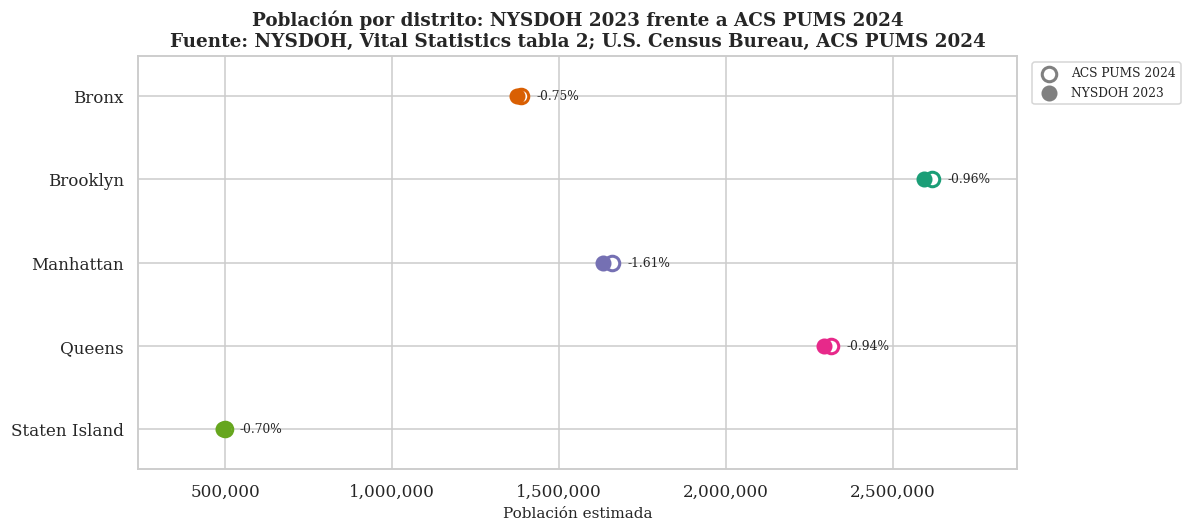

In [87]:
if pdf_poblacion_nysdoh is not None:
    datos = pdf_validacion[pdf_validacion["DISTRITO"].isin(ORDEN_BORO)].set_index("DISTRITO").reindex(ORDEN_BORO)
    fig, ax = plt.subplots(figsize=(11, 5))
    for y_pos, distrito in enumerate(ORDEN_BORO):
        v_pums, v_doh = datos.loc[distrito, "POBLACION_PUMS_2024"], datos.loc[distrito, "POBLACION_NYSDOH"]
        ax.plot([v_pums, v_doh], [y_pos, y_pos], color="#bdbdbd", lw=3, zorder=1)
        ax.scatter(v_pums, y_pos, s=90, color="white", edgecolor=PALETA_BORO[distrito], linewidth=2, zorder=2)
        ax.scatter(v_doh, y_pos, s=90, color=PALETA_BORO[distrito], zorder=3)
        ax.annotate(f"{datos.loc[distrito, 'DIFERENCIA_PCT']:+.2f}%", (max(v_pums, v_doh), y_pos), xytext=(10, 0),
                    textcoords="offset points", va="center", fontsize=8)
    ax.set_yticks(range(len(ORDEN_BORO)))
    ax.set_yticklabels([nombre_boro(d) for d in ORDEN_BORO])
    ax.invert_yaxis()
    formato_miles(ax.xaxis)
    ax.scatter([], [], s=90, color="white", edgecolor="gray", linewidth=2, label="ACS PUMS 2024")
    ax.scatter([], [], s=90, color="gray", label=f"NYSDOH {ANIO_NYSDOH}")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    ax.margins(x=0.12, y=0.12)
    ax.set(xlabel="Población estimada", title=f"Población por distrito: NYSDOH {ANIO_NYSDOH} frente a ACS PUMS 2024\n"
                                               "Fuente: NYSDOH, Vital Statistics tabla 2; U.S. Census Bureau, ACS PUMS 2024")
    plt.tight_layout()
    plt.show()
else:
    print("Gráfica pendiente: no se obtuvo la población del NYSDOH.")

**Análisis:** En los cinco distritos los dos puntos casi se superponen y el NYSDOH siempre queda un poco por debajo de PUMS. Ningún distrito cambia de orden entre las dos fuentes, así que las tasas y sus comparaciones serían las mismas con cualquiera de las dos poblaciones.

## 11. Bono 2: extracción climática con la API de OpenWeatherMap

Se consultan las condiciones actuales y el pronóstico de las próximas 24 horas para Nueva York. La API key no se escribe en el notebook: se lee de un archivo en la carpeta compartida o en la carpeta personal de la máquina virtual. Las horas del pronóstico llegan en UTC y se pasan a la hora de Nueva York. Los mensajes de error no imprimen la URL, porque contiene la key.

In [88]:
RUTAS_KEY = [f"{DATA_PATH}/.owm_api_key", os.path.expanduser("~/.owm_api_key")]
API_KEY = ""
# Se usa la primera ruta que exista
for ruta in RUTAS_KEY:
    if os.path.exists(ruta):
        with open(ruta) as f:
            API_KEY = f.read().strip()
        break

NYC_LAT, NYC_LON = 40.7128, -74.0060
# units=metric para grados Celsius y lang=es para las descripciones en español
PARAMETROS_OWM = {"lat": NYC_LAT, "lon": NYC_LON, "appid": API_KEY, "units": "metric", "lang": "es"}
data_actual, data_pronostico = None, None
if not API_KEY:
    print("No se encontró la API key en las rutas esperadas. Cree el archivo .owm_api_key para ejecutar este bono.")
else:
    try:
        respuesta = requests.get("https://api.openweathermap.org/data/2.5/weather", params=PARAMETROS_OWM, timeout=10)
        respuesta.raise_for_status()
        data_actual = respuesta.json()
        respuesta = requests.get("https://api.openweathermap.org/data/2.5/forecast", params=PARAMETROS_OWM, timeout=10)
        respuesta.raise_for_status()
        data_pronostico = respuesta.json()
    except requests.exceptions.HTTPError as e:
        print(f"Error HTTP {e.response.status_code}. Verifique que la API key sea válida y esté activa.")
    except Exception as e:
        print(f"Error al consultar OpenWeatherMap: {type(e).__name__}")

if data_actual is not None:
    hora_consulta = pd.to_datetime(data_actual["dt"], unit="s", utc=True).tz_convert("America/New_York")
    mostrar_tabla(pd.DataFrame([
        {"Variable": "Temperatura", "Valor": f"{data_actual['main']['temp']} °C"},
        {"Variable": "Sensación térmica", "Valor": f"{data_actual['main']['feels_like']} °C"},
        {"Variable": "Humedad relativa", "Valor": f"{data_actual['main']['humidity']} %"},
        {"Variable": "Velocidad del viento", "Valor": f"{data_actual['wind']['speed']} m/s"},
        {"Variable": "Condición general", "Valor": data_actual["weather"][0]["description"].capitalize()},
        {"Variable": "Hora de la medición en Nueva York", "Valor": hora_consulta.strftime("%Y-%m-%d %H:%M")}]),
        titulo="Condiciones actuales en Nueva York, OpenWeatherMap")

Variable,Valor
Temperatura,18.06 °C
Sensación térmica,17.1 °C
Humedad relativa,45 %
Velocidad del viento,3.6 m/s
Condición general,Cielo claro
Hora de la medición en Nueva York,2026-10-19 16:34


**Análisis:** La API respondió con las condiciones de Nueva York el 19 de octubre de 2026 a las 16:34, hora local: 18.06 °C, sensación térmica de 17.1 °C, humedad de 45%, viento de 3.6 m/s y cielo claro. Es una sola medición del momento de la corrida; en la entrega final se usarán datos de clima históricos para cruzarlos con los choques.

La gráfica muestra el pronóstico en intervalos de 3 horas para las próximas 24 horas: la temperatura en la línea y la probabilidad de lluvia en las barras, con las horas en hora de Nueva York.

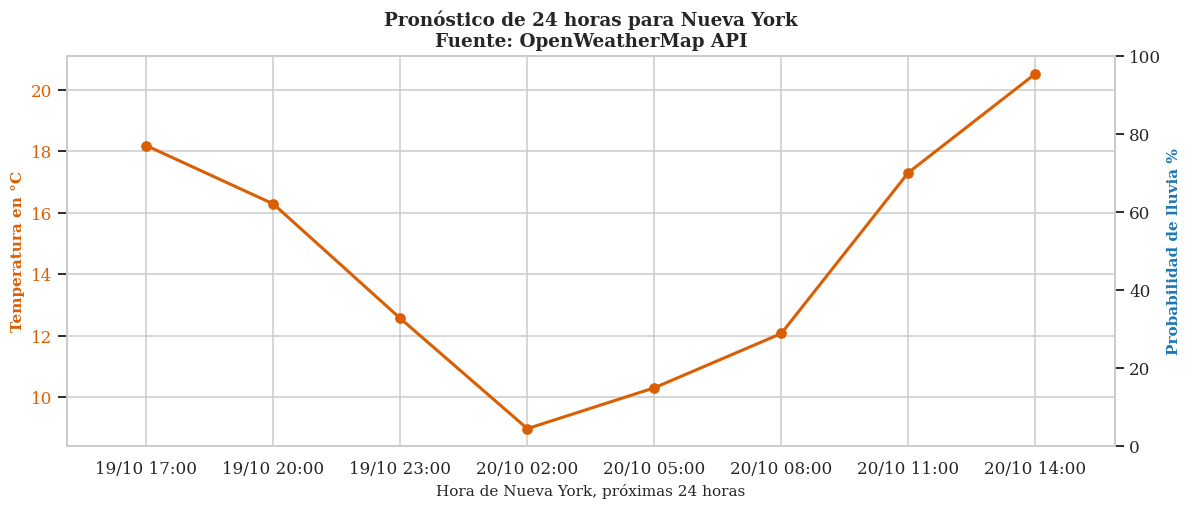

In [89]:
if data_pronostico is not None:
    # Los primeros 8 registros de 3 horas cubren las próximas 24 horas; pop es la probabilidad de lluvia entre 0 y 1
    pdf_pronostico = pd.DataFrame([{
        "HORA": pd.to_datetime(r["dt"], unit="s", utc=True).tz_convert("America/New_York").strftime("%d/%m %H:%M"),
        "TEMPERATURA_C": r["main"]["temp"],
        "PROB_LLUVIA_PCT": round(r.get("pop", 0) * 100, 1)} for r in data_pronostico["list"][:8]])
    fig, ax1 = plt.subplots(figsize=(11, 4.8))
    ax1.plot(pdf_pronostico["HORA"], pdf_pronostico["TEMPERATURA_C"], color="#d95f02", marker="o", lw=2)
    ax1.set_ylabel("Temperatura en °C", color="#d95f02", fontweight="bold")
    ax1.set_xlabel("Hora de Nueva York, próximas 24 horas")
    ax1.tick_params(axis="y", labelcolor="#d95f02")
    ax2 = ax1.twinx()
    ax2.bar(pdf_pronostico["HORA"], pdf_pronostico["PROB_LLUVIA_PCT"], alpha=0.3, color="#1f78b4", width=0.5)
    ax2.set_ylabel("Probabilidad de lluvia %", color="#1f78b4", fontweight="bold")
    ax2.set_ylim(0, 100)
    ax2.grid(False)
    ax1.set_title("Pronóstico de 24 horas para Nueva York\nFuente: OpenWeatherMap API")
    fig.tight_layout()
    plt.show()
else:
    print("Gráfica pendiente: no se obtuvo el pronóstico.")

**Análisis:** El pronóstico muestra una noche fría y un día templado: la temperatura baja de cerca de 18 °C a las 17:00 del 19 de octubre a cerca de 9 °C a las 2:00 del 20 de octubre, y sube a cerca de 20.5 °C a las 14:00. La probabilidad de lluvia es de 0% en todo el periodo, por eso no aparecen barras. Con este tipo de datos se podrá revisar después si la lluvia o el frío se asocian con más choques.

## 12. Cierre de la sesión de Spark

Se liberan las bases que quedaron en caché y se cierra la sesión. Si cada integrante deja su sesión abierta, se siguen ocupando núcleos y memoria del clúster que comparten seis personas.

In [90]:
# unpersist libera la memoria de los ejecutores; stop cierra la aplicación y libera sus núcleos
df_arrestos.unpersist()
df_choques.unpersist()
spark.stop()
print("Sesión de Spark cerrada. Recursos del clúster liberados.")

Sesión de Spark cerrada. Recursos del clúster liberados.
